# Identification

**Name:** David Rodríguez Fragoso  
**Student ID:** A01748760  
**Course:** TC6035 — Advanced Algorithms and Bioinspired Techniques  
**Problem:** Wireless sensor network placement  
**Instance salt:** 0  
**Route:** Provided mixed discrete–continuous problem

# Formulation


## Decision variables and objective

The deployment is represented by $\mathbf{x}=(\mathbf{z},\mathbf{p})$, with
$\mathbf{z}\in\{0,1\}^{80}$ and $p_i\in[1,c_i]$. The binary variable $z_i$
determines whether site $i$ is active, and $p_i$ sets its transmit power. Powers
assigned to inactive sites are ignored. Candidate coordinates, demand weights
and site-specific caps are fixed by the instance.

The field spans $[0,100]^2$. Demand is sampled at 2,500 points on a $50\times50$
grid covering the entire field. Candidate sites are a separate set of 80 positions.

The objective is maximized:

$$f(\mathbf{x})=C(\mathbf{x})-0.6E(\mathbf{x})-0.25I(\mathbf{x})-P(\mathbf{x}).$$

With $D=\sum_j d_j$, $k_j$ the number of active sensors covering point $j$, and
$n_a=\sum_i z_i$:

$$C=\frac{1}{D}\sum_{j:k_j>0}d_j,\qquad
E=\frac{25n_a+\sum_{i:z_i=1}p_i^2}{15600},\qquad
I=\frac{1}{D}\sum_{j:k_j>0}d_j\left(1-\frac{1}{k_j}\right).$$

Coverage rewards served demand; energy penalizes activation and quadratic power
cost; interference penalizes redundant coverage. All weights and normalization
constants are supplied by the problem and remain unchanged.



## Connectivity and infeasibility

An active sensor covers a disc of radius $r_i=4\sqrt{p_i}$. Active sites $i$ and
$\ell$ communicate if

$$\operatorname{dist}(i,\ell)\leq2.5\min(r_i,r_\ell).$$

A feasible deployment has exactly one connected component. Communication may
use intermediate sensors; direct links between every pair are unnecessary.
For a nonempty deployment with $m$ components:

$$P=\begin{cases}0,&m=1,\\2+0.1(m-1),&m>1.\end{cases}$$

The supplied evaluator separately assigns the empty deployment objective $-2$
and marks it infeasible.

The built-in penalty is used rather than repair. This keeps disconnected
candidates evaluable and provides a component-count penalty during search,
without introducing a repair operator that could change the search behavior.
Feasibility is recorded explicitly alongside the scalar objective.

Power changes coverage, energy, redundancy and communication links. Site
selection changes which power caps and links are available. These mechanisms
motivate an empirical coupling experiment in M0; they do not establish that a
particular hybrid must outperform joint search.


Source: course assignment specification, sections 2–3; `src/tc6035/problem.py` in the course repository.


# Implementations


## Environment and shared setup


In [1]:
import sys
import platform
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

for base in (Path.cwd(), *Path.cwd().parents):
    candidates = (base / "src", base / "tc6035-starter" / "src")
    src = next((p for p in candidates if (p / "tc6035").is_dir()), None)
    if src is not None:
        sys.path.insert(0, str(src))
        break
else:
    raise FileNotFoundError("Keep this notebook inside the course repository.")

from tc6035 import build_instance, SensorPlacementProblem, BudgetExceeded

STUDENT_ID = "A01748760"
SALT = 0
BUDGET = 5_000
SEEDS = tuple(range(30))

instance = build_instance(STUDENT_ID, salt=SALT)
spec = instance.spec

print(f"Python: {platform.python_version()} | NumPy: {np.__version__}")
print(f"Instance: {STUDENT_ID}, salt={SALT}")
print(f"Candidate sites: {instance.n_candidates}")
print(f"Demand points: {instance.n_grid}")
print(f"Power caps: {instance.power_cap.min():.2f}–{instance.power_cap.max():.2f}")
print(f"Final comparison seeds: {SEEDS}")

Python: 3.13.2 | NumPy: 2.5.4
Instance: A01748760, salt=0
Candidate sites: 80
Demand points: 2500
Power caps: 8.84–24.92
Final comparison seeds: (0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29)


## Monte Carlo and random-walk helpers


In [2]:
def sample_deployment(rng, instance, fraction_range=(0.1, 0.5)):
    fraction = rng.uniform(*fraction_range)
    active = rng.random(instance.n_candidates) < fraction
    power = rng.uniform(instance.spec.power_min, instance.power_cap)
    return active, power


def random_walk(problem, seed, steps=1_000, power_step=3.0):
    rng = np.random.default_rng(seed)
    active, power = sample_deployment(rng, problem.instance)
    values = [problem.evaluate(active, power)]
    n = problem.instance.n_candidates

    for _ in range(steps):
        if rng.random() < 0.5 or not active.any():
            i = rng.integers(n)
            active[i] = ~active[i]
        else:
            i = rng.choice(np.flatnonzero(active))
            power[i] = np.clip(
                power[i] + rng.normal(0, power_step),
                problem.instance.spec.power_min,
                problem.instance.power_cap[i],
            )
        # Every move is accepted: this measures a neighborhood, not an optimizer.
        values.append(problem.evaluate(active, power))

    return np.asarray(values)


def monte_carlo(problem, seed, active_fraction_range=(0.1, 0.5), return_solution=False):
    low, high = active_fraction_range
    if not 0 < low < high < 1:
        raise ValueError("The activation-probability range must be inside (0, 1).")
    if problem.evaluations_remaining < 1:
        raise ValueError("Monte Carlo needs at least one remaining evaluation.")

    rng = np.random.default_rng(seed)
    best_score = -np.inf
    best_active = best_power = best_result = None

    while problem.evaluations_remaining > 0:
        active, power = sample_deployment(rng, problem.instance, active_fraction_range)
        result = problem.evaluate_verbose(active, power)
        if result.objective > best_score:
            best_score = result.objective
            best_active = active.copy()
            best_power = power.copy()
            best_result = result

    if return_solution:
        return float(best_score), best_active, best_power, best_result
    return float(best_score)


ALGORITHMS = {"monte_carlo": monte_carlo}

## Simulated annealing


In [3]:
def accept_annealing(delta, temperature, uniform):
    if temperature <= 0:
        raise ValueError("Temperature must be positive.")
    return delta >= 0 or uniform < np.exp(delta / temperature)


def geometric_temperature(step, total_moves, initial_temperature, final_temperature):
    fraction = step / max(1, total_moves - 1)
    return initial_temperature * (final_temperature / initial_temperature) ** fraction


def simulated_annealing(
    problem, seed, initial_temperature=0.15, final_temperature=1e-4,
    power_step=3.0, flip_probability=0.5, active_fraction=0.3,
    nominal_power=None, mode="joint", initial_active=None, initial_power=None,
    initial_result=None, schedule_moves=None, schedule_offset=0,
    rng=None, return_details=False,
):
    if mode not in ("joint", "discrete", "power"):
        raise ValueError("Unknown search mode.")
    if not 0 < final_temperature < initial_temperature:
        raise ValueError("Require 0 < final temperature < initial temperature.")
    if power_step <= 0 or not 0 <= flip_probability <= 1 or not 0 < active_fraction < 1:
        raise ValueError("Invalid move or initialization parameters.")
    if problem.evaluations_remaining < 1:
        raise ValueError("At least one remaining evaluation is required.")
    inst = problem.instance
    n = inst.n_candidates
    initialization = np.random.default_rng(np.random.SeedSequence([seed, 19_000]))
    rng = np.random.default_rng(seed) if rng is None else rng
    active = (initialization.random(n) < active_fraction if initial_active is None
              else np.asarray(initial_active, dtype=bool).copy())
    if initial_power is None:
        power = (initialization.uniform(inst.spec.power_min, inst.power_cap)
                 if nominal_power is None else np.full(n, float(nominal_power)))
    else:
        power = np.asarray(initial_power, dtype=float).copy()
    if active.shape != (n,) or power.shape != (n,):
        raise ValueError("Initial vectors must match the candidate count.")
    power = np.clip(power, inst.spec.power_min, inst.power_cap)

    used_before = problem.evaluations_used
    current = problem.evaluate_verbose(active, power) if initial_result is None else initial_result
    best_active, best_power, best_result = active.copy(), power.copy(), current
    n_moves = problem.evaluations_remaining
    total_moves = n_moves if schedule_moves is None else schedule_moves
    if n_moves and (total_moves < 1 or schedule_offset < 0 or schedule_offset + n_moves > total_moves):
        raise ValueError("The stage does not fit the declared cooling schedule.")
    log = {"evaluation": [problem.evaluations_used], "temperature": [np.nan],
           "delta": [np.nan], "uniform": [np.nan], "proposal_score": [np.nan],
           "best_score": [current.objective], "accepted": [False], "worsening": [False],
           "current_score": [current.objective], "components": [current.n_components],
           "active_count": [current.n_active], "move_kind": ["initial"]}

    for step in range(n_moves):
        temperature = geometric_temperature(
            schedule_offset + step, total_moves, initial_temperature, final_temperature,
        )
        proposed_active, proposed_power = active.copy(), power.copy()
        flip = mode == "discrete" or (mode == "joint" and (
            not active.any() or rng.random() < flip_probability))
        if flip:
            index = rng.integers(n)
            proposed_active[index] = ~proposed_active[index]
            kind = "flip"
        elif active.any():
            index = rng.choice(np.flatnonzero(active))
            proposed_power[index] = np.clip(
                power[index] + rng.normal(0, power_step),
                inst.spec.power_min, inst.power_cap[index],
            )
            kind = "power"
        else:
            kind = "empty-power"
        proposed = problem.evaluate_verbose(proposed_active, proposed_power)
        delta = proposed.objective - current.objective
        uniform = rng.random() if delta < 0 else 0.0
        accepted = accept_annealing(delta, temperature, uniform)
        if accepted:
            active, power, current = proposed_active, proposed_power, proposed
            if current.objective > best_result.objective:
                best_active, best_power = active.copy(), power.copy()
                best_result = current
        for key, value in (
            ("evaluation", problem.evaluations_used), ("temperature", temperature),
            ("delta", delta), ("uniform", uniform), ("proposal_score", proposed.objective),
            ("best_score", best_result.objective),
            ("accepted", accepted), ("worsening", delta < 0),
            ("current_score", current.objective), ("components", current.n_components),
            ("active_count", current.n_active), ("move_kind", kind),
        ):
            log[key].append(value)

    details = {"score": float(best_result.objective), "active": best_active,
               "power": best_power, "result": best_result,
               "log": {k: np.asarray(v) for k, v in log.items()},
               "moves": n_moves, "evaluations_used": problem.evaluations_used - used_before}
    return details if return_details else details["score"]


def joint(seed):
    problem = SensorPlacementProblem(instance, budget=BUDGET, seed=seed)
    result = simulated_annealing(problem, seed, **SA_PARAMS, return_details=True)
    result["record"] = problem.record
    result["phase_counts"] = {"joint": problem.evaluations_used}
    return result


def two_stage(seed):
    problem = SensorPlacementProblem(instance, budget=BUDGET, seed=seed)
    rng = np.random.default_rng(seed)
    schedule_moves = BUDGET - 1
    with problem.limited(BUDGET // 2):
        first = simulated_annealing(
            problem, seed, **SA_PARAMS, mode="discrete", rng=rng,
            schedule_moves=schedule_moves, return_details=True,
        )
    first_used = problem.evaluations_used
    # Reuse the already evaluated boundary state; it is not a free new candidate.
    second = simulated_annealing(
        problem, seed, **SA_PARAMS, mode="power", rng=rng,
        initial_active=first["active"], initial_power=first["power"],
        initial_result=first["result"], schedule_moves=schedule_moves,
        schedule_offset=first["moves"], return_details=True,
    )
    result = dict(second)
    result["log"] = {k: np.concatenate([first["log"][k], second["log"][k][1:]])
                     for k in first["log"]}
    result["record"] = problem.record
    result["phase_counts"] = {"subset": first_used, "power": problem.evaluations_used - first_used}
    result["stage_one_score"] = first["score"]
    return result


def worsening_acceptance(log, budget):
    early = (log["evaluation"] <= 0.1 * budget) & log["worsening"]
    late = (log["evaluation"] > 0.9 * budget) & log["worsening"]
    return {"early_rate": float(log["accepted"][early].mean()) if early.any() else np.nan,
            "late_rate": float(log["accepted"][late].mean()) if late.any() else np.nan,
            "early_worsening": int(early.sum()), "late_worsening": int(late.sum())}


def paired_rank_biserial(a, b):
    from scipy.stats import rankdata
    differences = np.round(np.asarray(a) - np.asarray(b), 12)
    nonzero = differences != 0
    ranks = rankdata(np.abs(differences[nonzero]))
    if not ranks.size:
        return 0.0
    return float((ranks[differences[nonzero] > 0].sum()
                  - ranks[differences[nonzero] < 0].sum()) / ranks.sum())


def holm_correction(p_values):
    ordered = sorted(p_values, key=p_values.get)
    adjusted, running = {}, 0.0
    for i, name in enumerate(ordered):
        running = max(running, (len(ordered) - i) * p_values[name])
        adjusted[name] = min(1.0, running)
    return adjusted


ALGORITHMS["simulated_annealing"] = simulated_annealing


## Tabu search: discrete layer

The inline implementation below follows the memory, aspiration and oldest-ban fallback rules from [Session 2](https://github.com/vsosahdz/advancedAlgorithmsBio2026/blob/main/slides/lesson-02.html). Its M1 experiments and illustrated validation appear below M0. The selected nominal power must be supplied explicitly; there is no independent default power to replace M0's value.


In [4]:
def tabu_search(
    problem, seed, tenure=12, candidate_size=20, nominal_power=None,
    active_fraction=0.3, initial_active=None, return_details=False,
):
    n = problem.instance.n_candidates
    if isinstance(tenure, (bool, np.bool_)) or not isinstance(tenure, (int, np.integer)) or tenure < 0:
        raise ValueError("Tenure must be a nonnegative integer.")
    if (isinstance(candidate_size, (bool, np.bool_))
            or not isinstance(candidate_size, (int, np.integer))
            or not 1 <= candidate_size <= n):
        raise ValueError("Candidate size must be an integer from 1 to the site count.")
    lower = problem.instance.spec.power_min
    if nominal_power is None or not np.isfinite(nominal_power) or nominal_power < lower:
        raise ValueError("Supply a finite nominal power at least equal to the minimum.")
    if not 0 < active_fraction < 1:
        raise ValueError("Initial activation fraction must be between 0 and 1.")
    if problem.evaluations_remaining < 1:
        raise ValueError("At least one remaining evaluation is required.")

    initialization = np.random.default_rng(np.random.SeedSequence([seed, 19_000]))
    rng = np.random.default_rng(seed)
    active = (initialization.random(n) < active_fraction if initial_active is None
              else np.asarray(initial_active, dtype=bool).copy())
    if active.shape != (n,):
        raise ValueError("The initial activation vector must match the site count.")
    power = np.clip(np.full(n, float(nominal_power)), lower, problem.instance.power_cap)
    used_before = problem.evaluations_used
    current = problem.evaluate_verbose(active, power)
    initial_active_copy = active.copy()
    initial_score = float(current.objective)
    best_active, best_result = active.copy(), current
    tabu_until = np.zeros(n, dtype=int)
    iteration_log, candidate_log = [], []
    # Revisited states are diagnostic only; they do not change move selection.
    visited = {active.tobytes()}
    previous_index = -1
    iteration = 0

    while problem.evaluations_remaining:
        count = min(candidate_size, problem.evaluations_remaining)
        indices = rng.choice(n, size=count, replace=False)
        current_before = float(current.objective)
        best_before = float(best_result.objective)
        evaluation_start = problem.evaluations_used + 1
        candidates = []
        for index in indices:
            index = int(index)
            proposal = active.copy()
            proposal[index] = ~proposal[index]
            result = problem.evaluate_verbose(proposal, power)
            is_tabu = bool(tabu_until[index] > iteration)
            aspiration = is_tabu and result.objective > best_before
            row = {
                "iteration": iteration, "evaluation": problem.evaluations_used,
                "index": index, "score": float(result.objective),
                "tabu_until": int(tabu_until[index]), "is_tabu": is_tabu,
                "aspiration": bool(aspiration),
                "admissible": bool(not is_tabu or aspiration), "selected": False,
            }
            candidates.append((row, proposal, result))
        admissible = [item for item in candidates if item[0]["admissible"]]
        forced_override = not admissible
        if admissible:
            chosen = max(admissible, key=lambda item: item[0]["score"])
        else:
            # Class fallback: override the ban that expires first.
            chosen = min(candidates, key=lambda item: item[0]["tabu_until"])
        row, active, current = chosen
        row["selected"] = True
        index = row["index"]
        tabu_until[index] = iteration + 1 + tenure
        if current.objective > best_result.objective:
            best_active, best_result = active.copy(), current
        state_key = active.tobytes()
        revisited = state_key in visited
        visited.add(state_key)
        iteration_log.append({
            "iteration": iteration, "evaluation_start": evaluation_start,
            "evaluation_end": problem.evaluations_used, "candidate_count": count,
            "blocked_count": sum(not item[0]["admissible"] for item in candidates),
            "selected_index": index, "aspiration_used": row["aspiration"],
            "forced_override": forced_override,
            "current_before": current_before, "current_after": float(current.objective),
            "best_before": best_before, "best_after": float(best_result.objective),
            "move_delta": float(current.objective - current_before),
            "tabu_until_after": int(tabu_until[index]),
            "n_components": current.n_components, "n_active": current.n_active,
            "revisited": revisited, "immediate_reversal": index == previous_index,
        })
        candidate_log.extend(item[0] for item in candidates)
        previous_index = index
        iteration += 1

    details = {
        "score": float(best_result.objective), "active": best_active,
        "power": power.copy(), "result": best_result,
        "initial_active": initial_active_copy, "initial_score": initial_score,
        "iterations": iteration_log, "candidates": candidate_log,
        "tabu_until": tabu_until.copy(),
        "evaluations_used": problem.evaluations_used - used_before,
        "revisits": sum(row["revisited"] for row in iteration_log),
        "aspiration_moves": sum(row["aspiration_used"] for row in iteration_log),
        "forced_overrides": sum(row["forced_override"] for row in iteration_log),
    }
    return details if return_details else details["score"]


ALGORITHMS["tabu_search"] = tabu_search


## Particle swarm optimization: continuous layer

The reusable `pso` implementation searches powers only on an explicitly supplied fixed activation vector. M1 uses global-best communication. The step function exposes the velocity and position calculation for validation; every candidate is still evaluated through the instrumented problem. The complete implementation remains in this notebook.


In [5]:
def pso_step(position, velocity, personal_best, social_best, r1, r2,
             lower, upper, w, c1, c2, velocity_fraction):
    inertia = w * velocity
    cognitive = c1 * r1 * (personal_best - position)
    social = c2 * r2 * (social_best - position)
    raw_velocity = inertia + cognitive + social
    velocity_limit = velocity_fraction * (upper - lower)
    limited_velocity = np.clip(raw_velocity, -velocity_limit, velocity_limit)
    raw_position = position + limited_velocity
    next_position = np.clip(raw_position, lower, upper)
    hit_boundary = (raw_position < lower) | (raw_position > upper)
    next_velocity = np.where(hit_boundary, 0.0, limited_velocity)
    return {"inertia": inertia, "cognitive": cognitive, "social": social,
            "raw_velocity": raw_velocity, "limited_velocity": limited_velocity,
            "raw_position": raw_position, "position": next_position,
            "velocity": next_velocity, "hit_boundary": hit_boundary}


def pso(problem, seed, fixed_active, initial_power, topology="gbest", swarm_size=20,
        w=0.7, c1=1.4, c2=1.4, velocity_fraction=0.2,
        initial_velocity_fraction=0.1, trace_updates=0, return_details=False):
    if topology != "gbest":
        raise ValueError("This M1 implementation supports gbest topology only.")
    if (isinstance(swarm_size, (bool, np.bool_)) or not isinstance(swarm_size, (int, np.integer))
            or swarm_size < 1):
        raise ValueError("swarm_size must be a positive integer.")
    if (isinstance(trace_updates, (bool, np.bool_)) or not isinstance(trace_updates, (int, np.integer))
            or trace_updates < 0):
        raise ValueError("trace_updates must be a nonnegative integer.")
    if (not np.all(np.isfinite([w, c1, c2, velocity_fraction, initial_velocity_fraction]))
            or w < 0 or c1 < 0 or c2 < 0 or velocity_fraction <= 0
            or not 0 <= initial_velocity_fraction <= velocity_fraction):
        raise ValueError("Invalid PSO coefficients or velocity fractions.")
    if problem.evaluations_remaining < 1:
        raise ValueError("At least one remaining evaluation is required.")
    inst = problem.instance
    supplied_active = np.asarray(fixed_active)
    if supplied_active.shape != (inst.n_candidates,) or not np.all(np.isin(supplied_active, [0, 1])):
        raise ValueError("fixed_active must be a binary vector matching the candidate count.")
    active = supplied_active.astype(bool).copy()
    indices = np.flatnonzero(active)
    if not indices.size:
        raise ValueError("Power optimization requires a nonempty fixed subset.")
    base_power = np.asarray(initial_power, dtype=float).copy()
    if (base_power.shape != (inst.n_candidates,) or not np.all(np.isfinite(base_power))
            or np.any(base_power < inst.spec.power_min) or np.any(base_power > inst.power_cap)):
        raise ValueError("initial_power must be a finite, bounded full power vector.")
    used_before = problem.evaluations_used
    lower = np.full(indices.size, float(inst.spec.power_min))
    upper = inst.power_cap[indices].astype(float)
    span = upper - lower
    scale = np.where(span > 0, span, 1.0)
    actual_swarm = min(int(swarm_size), problem.evaluations_remaining)
    rng = np.random.default_rng(seed)
    positions = rng.uniform(lower, upper, size=(actual_swarm, indices.size))
    positions[0] = base_power[indices]
    velocities = rng.uniform(-initial_velocity_fraction * span, initial_velocity_fraction * span,
                             size=positions.shape)
    scores = np.empty(actual_swarm)
    best_result, best_power, best_score = None, None, float("-inf")

    def evaluate(position):
        power = base_power.copy()
        power[indices] = position
        return power, problem.evaluate_verbose(active.copy(), power)

    for particle in range(actual_swarm):
        power, result = evaluate(positions[particle])
        scores[particle] = result.objective
        if result.objective > best_score:
            best_score, best_power, best_result = float(result.objective), power.copy(), result
    personal_positions, personal_scores = positions.copy(), scores.copy()
    best_index = int(np.argmax(personal_scores))
    social_position = personal_positions[best_index].copy()
    initial_positions, initial_velocities = positions.copy(), velocities.copy()
    initial_scores = scores.copy()
    updates, history = [], []

    def record_generation(generation, evaluated):
        history.append({"generation": generation, "evaluation": problem.evaluations_used,
                        "evaluated_particles": evaluated, "best_score": best_score,
                        "mean_current_score": float(scores.mean()),
                        "diversity": float(np.std(positions / scale, axis=0).mean()),
                        "mean_speed": float(np.linalg.norm(velocities / scale, axis=1).mean())})

    generation = 0
    record_generation(generation, actual_swarm)
    while problem.evaluations_remaining:
        generation += 1
        # Freeze the social target for this entire sweep, including a partial sweep.
        target, target_score = social_position.copy(), best_score
        count = min(actual_swarm, problem.evaluations_remaining)
        for particle in range(count):
            before, velocity_before = positions[particle].copy(), velocities[particle].copy()
            personal_before = personal_positions[particle].copy()
            personal_score_before = float(personal_scores[particle])
            global_before = best_score
            r1, r2 = rng.random(indices.size), rng.random(indices.size)
            step = pso_step(before, velocity_before, personal_before, target, r1, r2,
                            lower, upper, w, c1, c2, velocity_fraction)
            positions[particle], velocities[particle] = step["position"], step["velocity"]
            power, result = evaluate(positions[particle])
            scores[particle] = result.objective
            personal_improved = result.objective > personal_scores[particle]
            if personal_improved:
                personal_positions[particle] = positions[particle].copy()
                personal_scores[particle] = result.objective
            global_improved = result.objective > best_score
            if global_improved:
                best_score, best_power, best_result = float(result.objective), power.copy(), result
                social_position = positions[particle].copy()
            if len(updates) < trace_updates:
                updates.append({"generation": generation, "particle": particle,
                                "evaluation": problem.evaluations_used, "position_before": before,
                                "velocity_before": velocity_before, "personal_before": personal_before,
                                "personal_score_before": personal_score_before, "social_target": target.copy(),
                                "social_score": target_score, "r1": r1, "r2": r2,
                                **{k: v.copy() for k, v in step.items()},
                                "score": float(result.objective), "personal_improved": bool(personal_improved),
                                "personal_after": personal_positions[particle].copy(),
                                "personal_score_after": float(personal_scores[particle]),
                                "global_before": global_before, "global_after": best_score,
                                "global_improved": bool(global_improved)})
        record_generation(generation, count)

    details = {"score": best_score, "active": active, "power": best_power, "result": best_result,
               "indices": indices, "initial_positions": initial_positions,
               "initial_velocities": initial_velocities, "initial_scores": initial_scores,
               "personal_positions": personal_positions, "personal_scores": personal_scores,
               "positions": positions, "velocities": velocities, "history": history, "updates": updates,
               "effective_swarm_size": actual_swarm,
               "evaluations_used": problem.evaluations_used - used_before}
    return details if return_details else details["score"]


if "ALGORITHMS" not in globals():
    ALGORITHMS = {}
ALGORITHMS["pso"] = pso


## PSO topology extension

M2 extends the M1 PSO engine with a circular three-particle neighborhood. The M1 function is retained as `m1_original_pso` for a short regression check; `pso` now accepts both `gbest` and `ring`. All velocity, power-boundary, initialization and best-retention rules remain shared. The default topology remains `gbest`, preserving the earlier milestone's calls.


In [6]:
m1_original_pso = pso

def pso_step(position, velocity, personal_best, social_best, r1, r2,
             lower, upper, w, c1, c2, velocity_fraction):
    inertia = w * velocity
    cognitive = c1 * r1 * (personal_best - position)
    social = c2 * r2 * (social_best - position)
    raw_velocity = inertia + cognitive + social
    velocity_limit = velocity_fraction * (upper - lower)
    limited_velocity = np.clip(raw_velocity, -velocity_limit, velocity_limit)
    raw_position = position + limited_velocity
    next_position = np.clip(raw_position, lower, upper)
    hit_boundary = (raw_position < lower) | (raw_position > upper)
    next_velocity = np.where(hit_boundary, 0.0, limited_velocity)
    return {"inertia": inertia, "cognitive": cognitive, "social": social,
            "raw_velocity": raw_velocity, "limited_velocity": limited_velocity,
            "raw_position": raw_position, "position": next_position,
            "velocity": next_velocity, "hit_boundary": hit_boundary}


def ring_social_targets(personal_positions, personal_scores):
    size = len(personal_scores)
    targets, scores, chosen = [], [], []
    for i in range(size):
        # Prefer self, then left, then right on an exact score tie.
        neighbors = list(dict.fromkeys([i, (i-1) % size, (i+1) % size]))
        winner = neighbors[int(np.argmax(personal_scores[neighbors]))]
        targets.append(personal_positions[winner].copy())
        scores.append(personal_scores[winner])
        chosen.append(winner)
    return np.asarray(targets), np.asarray(scores), np.asarray(chosen)


def pso(problem, seed, fixed_active, initial_power, topology="gbest", swarm_size=20,
        w=0.7, c1=1.4, c2=1.4, velocity_fraction=0.2,
        initial_velocity_fraction=0.1, trace_updates=0, return_details=False):
    if topology not in ("gbest", "ring"):
        raise ValueError("topology must be gbest or ring.")
    if (isinstance(swarm_size, (bool, np.bool_)) or not isinstance(swarm_size, (int, np.integer))
            or swarm_size < 1):
        raise ValueError("swarm_size must be a positive integer.")
    if (isinstance(trace_updates, (bool, np.bool_)) or not isinstance(trace_updates, (int, np.integer))
            or trace_updates < 0):
        raise ValueError("trace_updates must be a nonnegative integer.")
    if (not np.all(np.isfinite([w, c1, c2, velocity_fraction, initial_velocity_fraction]))
            or w < 0 or c1 < 0 or c2 < 0 or velocity_fraction <= 0
            or not 0 <= initial_velocity_fraction <= velocity_fraction):
        raise ValueError("Invalid PSO coefficients or velocity fractions.")
    if problem.evaluations_remaining < 1:
        raise ValueError("At least one remaining evaluation is required.")
    inst = problem.instance
    supplied_active = np.asarray(fixed_active)
    if supplied_active.shape != (inst.n_candidates,) or not np.all(np.isin(supplied_active, [0, 1])):
        raise ValueError("fixed_active must be a binary vector matching the candidate count.")
    active = supplied_active.astype(bool).copy()
    indices = np.flatnonzero(active)
    if not indices.size:
        raise ValueError("Power optimization requires a nonempty fixed subset.")
    base_power = np.asarray(initial_power, dtype=float).copy()
    if (base_power.shape != (inst.n_candidates,) or not np.all(np.isfinite(base_power))
            or np.any(base_power < inst.spec.power_min) or np.any(base_power > inst.power_cap)):
        raise ValueError("initial_power must be a finite, bounded full power vector.")
    used_before = problem.evaluations_used
    lower = np.full(indices.size, float(inst.spec.power_min))
    upper = inst.power_cap[indices].astype(float)
    span = upper - lower
    scale = np.where(span > 0, span, 1.0)
    actual_swarm = min(int(swarm_size), problem.evaluations_remaining)
    rng = np.random.default_rng(seed)
    positions = rng.uniform(lower, upper, size=(actual_swarm, indices.size))
    positions[0] = base_power[indices]
    velocities = rng.uniform(-initial_velocity_fraction * span, initial_velocity_fraction * span,
                             size=positions.shape)
    scores = np.empty(actual_swarm)
    best_result, best_power, best_score = None, None, float("-inf")

    def evaluate(position):
        power = base_power.copy()
        power[indices] = position
        return power, problem.evaluate_verbose(active.copy(), power)

    for particle in range(actual_swarm):
        power, result = evaluate(positions[particle])
        scores[particle] = result.objective
        if result.objective > best_score:
            best_score, best_power, best_result = float(result.objective), power.copy(), result
    personal_positions, personal_scores = positions.copy(), scores.copy()
    best_index = int(np.argmax(personal_scores))
    social_position = personal_positions[best_index].copy()
    initial_positions, initial_velocities = positions.copy(), velocities.copy()
    initial_scores = scores.copy()
    updates, history = [], []

    def record_generation(generation, evaluated):
        history.append({"generation": generation, "evaluation": problem.evaluations_used,
                        "evaluated_particles": evaluated, "best_score": best_score,
                        "mean_current_score": float(scores.mean()),
                        "diversity": float(np.std(positions / scale, axis=0).mean()),
                        "mean_speed": float(np.linalg.norm(velocities / scale, axis=1).mean())})

    generation = 0
    record_generation(generation, actual_swarm)
    while problem.evaluations_remaining:
        generation += 1
        # Freeze the social target for this entire sweep, including a partial sweep.
        if topology == "ring":
            ring_positions, ring_scores, ring_indices = ring_social_targets(personal_positions, personal_scores)
        else:
            target, target_score = social_position.copy(), best_score
        count = min(actual_swarm, problem.evaluations_remaining)
        for particle in range(count):
            if topology == "ring":
                target, target_score = ring_positions[particle].copy(), float(ring_scores[particle])
            before, velocity_before = positions[particle].copy(), velocities[particle].copy()
            personal_before = personal_positions[particle].copy()
            personal_score_before = float(personal_scores[particle])
            global_before = best_score
            r1, r2 = rng.random(indices.size), rng.random(indices.size)
            step = pso_step(before, velocity_before, personal_before, target, r1, r2,
                            lower, upper, w, c1, c2, velocity_fraction)
            positions[particle], velocities[particle] = step["position"], step["velocity"]
            power, result = evaluate(positions[particle])
            scores[particle] = result.objective
            personal_improved = result.objective > personal_scores[particle]
            if personal_improved:
                personal_positions[particle] = positions[particle].copy()
                personal_scores[particle] = result.objective
            global_improved = result.objective > best_score
            if global_improved:
                best_score, best_power, best_result = float(result.objective), power.copy(), result
                social_position = positions[particle].copy()
            if len(updates) < trace_updates:
                updates.append({"generation": generation, "particle": particle,
                                "evaluation": problem.evaluations_used, "position_before": before,
                                "velocity_before": velocity_before, "personal_before": personal_before,
                                "personal_score_before": personal_score_before, "social_target": target.copy(),
                                "social_score": target_score,
                                "social_index": int(ring_indices[particle]) if topology == "ring" else None,
                                "r1": r1, "r2": r2,
                                **{k: v.copy() for k, v in step.items()},
                                "score": float(result.objective), "personal_improved": bool(personal_improved),
                                "personal_after": personal_positions[particle].copy(),
                                "personal_score_after": float(personal_scores[particle]),
                                "global_before": global_before, "global_after": best_score,
                                "global_improved": bool(global_improved)})
        record_generation(generation, count)

    details = {"topology": topology, "score": best_score, "active": active, "power": best_power, "result": best_result,
               "indices": indices, "initial_positions": initial_positions,
               "initial_velocities": initial_velocities, "initial_scores": initial_scores,
               "personal_positions": personal_positions, "personal_scores": personal_scores,
               "positions": positions, "velocities": velocities, "history": history, "updates": updates,
               "effective_swarm_size": actual_swarm,
               "evaluations_used": problem.evaluations_used - used_before}
    return details if return_details else details["score"]


if "ALGORITHMS" not in globals():
    ALGORITHMS = {}
ALGORITHMS["pso"] = pso


## Ant colony optimization: subset construction

The reusable `aco` implementation builds fixed-cardinality sensor subsets using marginal coverage and site pheromones. It evaluates complete deployments through the instrumented objective, reinforces the iteration winner and preserves the best solution separately. The `bounded` switch supports the later M3 ablation; M2 uses bounds throughout.


In [7]:
def aco_choice_probabilities(tau, gains, available, alpha, beta, heuristic_floor):
    log_weights = (alpha * np.log(np.maximum(tau[available], np.finfo(float).tiny))
                   + beta * np.log(np.maximum(gains[available], heuristic_floor)))
    weights = np.exp(log_weights-log_weights.max())
    return weights/weights.sum()


def construct_sensor_ant(rng, coverage, weighted_coverage, tau, n_select,
                         alpha, beta, heuristic_floor, record=False):
    available_mask = np.ones(len(tau), dtype=bool)
    covered = np.zeros(coverage.shape[1], dtype=bool)
    gains = weighted_coverage.sum(axis=1)
    steps, chosen, entropies = [], [], []
    covered_weight = 0.0
    for step in range(n_select):
        available = np.flatnonzero(available_mask)
        probabilities = aco_choice_probabilities(tau, gains, available, alpha, beta, heuristic_floor)
        positive = probabilities > 0
        entropy = float(-np.sum(probabilities[positive]*np.log(probabilities[positive])))
        site = int(rng.choice(available,p=probabilities))
        newly_covered = coverage[site] & ~covered
        marginal = float(weighted_coverage[site,newly_covered].sum())
        if record:
            steps.append({"step":step+1,"available":available.copy(),"gains":gains[available].copy(),
                          "probabilities":probabilities.copy(),"chosen":site,
                          "marginal":marginal,"entropy":entropy,
                          "coverage_before":covered_weight,"coverage_after":covered_weight+marginal})
        chosen.append(site);entropies.append(entropy)
        covered_weight += marginal
        covered |= newly_covered
        available_mask[site] = False
        # Remove demand already reached by this addition from every remaining site's gain.
        if newly_covered.any():
            gains = np.maximum(0.0,gains-weighted_coverage[:,newly_covered].sum(axis=1))
    return np.array(chosen,dtype=int),float(np.mean(entropies)),entropies[0],steps


def aco_reward(score):
    # Positive monotone reward also supports penalized negative objectives.
    z = float(np.clip(score,-700,700))
    return float(1/(1+np.exp(-z)))


def update_site_pheromone(tau, active, score, rho, tau_min, tau_max, bounded):
    evaporated = (1-rho)*tau
    deposit = np.zeros_like(tau)
    deposit[active] = rho*aco_reward(score)
    raw = evaporated+deposit
    after = np.clip(raw,tau_min,tau_max) if bounded else raw.copy()
    return {"before":tau.copy(),"evaporated":evaporated,"deposit":deposit,"raw":raw,"after":after,
            "lower_hits":int(np.sum(raw<tau_min)) if bounded else 0,
            "upper_hits":int(np.sum(raw>tau_max)) if bounded else 0}


def aco(problem, seed, alpha=1.0, beta=2.0, rho=0.08, n_ants=10, n_select=15,
        nominal_power=20.0, tau_min=0.02, tau_max=1.0, tau_initial=1.0,
        bounded=True, heuristic_floor=1e-12, trace_ants=0, trace_iterations=0,
        return_details=False):
    inst = problem.instance
    for name,value,minimum in (("n_ants",n_ants,1),("n_select",n_select,1),
                               ("trace_ants",trace_ants,0),("trace_iterations",trace_iterations,0)):
        if isinstance(value,(bool,np.bool_)) or not isinstance(value,(int,np.integer)) or value<minimum:
            raise ValueError(f"Invalid {name}.")
    if n_select>inst.n_candidates:
        raise ValueError("n_select exceeds the candidate count.")
    if (not np.all(np.isfinite([alpha,beta,rho,nominal_power,tau_min,tau_max,tau_initial,heuristic_floor]))
            or alpha<0 or beta<0 or not 0<rho<1 or nominal_power<inst.spec.power_min
            or not 0<tau_min<=tau_initial<=tau_max or heuristic_floor<=0
            or not isinstance(bounded,(bool,np.bool_))):
        raise ValueError("Invalid ACO coefficients or pheromone settings.")
    if problem.evaluations_remaining<1:
        raise ValueError("At least one remaining evaluation is required.")
    used_before = problem.evaluations_used
    power = np.clip(np.full(inst.n_candidates,float(nominal_power)),inst.spec.power_min,inst.power_cap)
    radii = inst.spec.radius_coeff*np.sqrt(power)
    coverage = inst.dist_to_grid<=radii[:,None]
    weighted = coverage*inst.demand[None,:]
    rng = np.random.default_rng(seed)
    tau = np.full(inst.n_candidates,float(tau_initial))
    pheromone_history = [tau.copy()]
    history,ant_traces,pheromone_traces = [],[],[]
    best_score,best_active,best_result = float('-inf'),None,None
    iteration,total_ants = 0,0
    while problem.evaluations_remaining:
        iteration += 1
        count = min(n_ants,problem.evaluations_remaining)
        iteration_score,iteration_active = float('-inf'),None
        entropies,first_entropies,subsets = [],[],set()
        iteration_best_ant = None
        for ant in range(count):
            chosen,entropy,first_entropy,steps = construct_sensor_ant(
                rng,coverage,weighted,tau,n_select,alpha,beta,heuristic_floor,
                record=len(ant_traces)<trace_ants)
            active = np.zeros(inst.n_candidates,dtype=bool);active[chosen]=True
            result = problem.evaluate_verbose(active,power.copy())
            if result.objective>iteration_score:
                iteration_score,iteration_active = float(result.objective),active.copy()
                iteration_best_ant = ant
            if result.objective>best_score:
                best_score,best_active,best_result = float(result.objective),active.copy(),result
            entropies.append(entropy);first_entropies.append(first_entropy)
            subsets.add(tuple(np.flatnonzero(active)))
            if len(ant_traces)<trace_ants:
                ant_traces.append({"iteration":iteration,"ant":ant,"evaluation":problem.evaluations_used,
                                   "chosen":chosen,"steps":steps,"score":float(result.objective)})
            total_ants += 1
        update = update_site_pheromone(tau,iteration_active,iteration_score,rho,tau_min,tau_max,bounded)
        tau = update["after"]
        history.append({"iteration":iteration,"evaluation":problem.evaluations_used,"ants":count,
                        "iteration_best":iteration_score,"best_score":best_score,
                        "iteration_best_ant":iteration_best_ant,"reward":aco_reward(iteration_score),
                        "first_choice_entropy":float(np.mean(first_entropies)),
                        "mean_choice_entropy":float(np.mean(entropies)),"distinct_subsets":len(subsets),
                        "lower_hits":update["lower_hits"],"upper_hits":update["upper_hits"],
                        "fraction_at_min":float(np.mean(tau==tau_min)),
                        "fraction_at_max":float(np.mean(tau==tau_max)),
                        "pheromone_min":float(tau.min()),"pheromone_max":float(tau.max())})
        pheromone_history.append(tau.copy())
        if len(pheromone_traces)<trace_iterations:
            pheromone_traces.append({"iteration":iteration,"active":iteration_active.copy(),
                                     "score":iteration_score,**update})
    details={"score":best_score,"active":best_active,"power":power.copy(),"result":best_result,
             "history":history,"pheromone":tau.copy(),"pheromone_history":np.array(pheromone_history),
             "ant_traces":ant_traces,"pheromone_traces":pheromone_traces,
             "ants_evaluated":total_ants,"evaluations_used":problem.evaluations_used-used_before}
    return details if return_details else best_score


if "ALGORITHMS" not in globals():
    ALGORITHMS = {}
ALGORITHMS["aco"] = aco


## Coupled hybrid: shared-budget ACO → PSO

The solver selects sites, transfers the retained deployment and adjusts only its powers. Both stages spend one evaluator's remaining allowance. Each call to the objective, including the incoming deployment's reevaluation, is charged.

In [8]:
def hybrid(problem, seed, split=0.6, aco_params=None, pso_params=None,
           return_details=False):
    """ACO site selection followed by ring PSO, charged to the same evaluator."""
    if isinstance(split, (bool, np.bool_)) or not np.isscalar(split):
        raise ValueError("split must be a finite fraction between zero and one.")
    if not np.isfinite(split) or not 0 < split < 1:
        raise ValueError("split must be a finite fraction between zero and one.")
    allowance = problem.evaluations_remaining
    stage_budget = int(allowance * split)
    if not 1 <= stage_budget < allowance:
        raise ValueError("Both stages need at least one evaluation.")
    ap = dict(alpha=1., beta=2., rho=.08, n_ants=10, n_select=15,
              nominal_power=20., tau_min=.02, tau_max=1., tau_initial=1.,
              bounded=True, heuristic_floor=1e-12)
    pp = dict(topology="ring", swarm_size=20, w=.7, c1=1.4, c2=1.4,
              velocity_fraction=.2, initial_velocity_fraction=.1)
    ap.update(aco_params or {})
    pp.update(pso_params or {})
    reserved = {"return_details", "fixed_active", "initial_power"}
    if reserved.intersection(ap) or reserved.intersection(pp):
        raise ValueError("Stage outputs and transfer vectors are managed by hybrid.")
    # Validate the declared stage settings before spending any objective calls.
    if (pp["topology"] not in ("ring", "gbest") or pp["swarm_size"] < 1
            or not np.all(np.isfinite([pp[k] for k in
                ("w", "c1", "c2", "velocity_fraction", "initial_velocity_fraction")]))
            or min(pp["w"], pp["c1"], pp["c2"]) < 0
            or not 0 <= pp["initial_velocity_fraction"] <= pp["velocity_fraction"]
            or pp["velocity_fraction"] <= 0
            or isinstance(pp["swarm_size"], (bool, np.bool_))
            or not isinstance(pp["swarm_size"], (int, np.integer))):
        raise ValueError("Invalid PSO stage settings.")
    before = problem.evaluations_used
    outer_budget = problem.budget
    with problem.limited(stage_budget):
        selection = aco(problem, seed, **ap, return_details=True)
    switch = problem.evaluations_used
    assert problem.budget == outer_budget and switch - before == stage_budget
    adjustment = pso(problem, seed, selection["active"], selection["power"],
                     **pp, return_details=True)
    assert problem.evaluations_used - before == allowance
    assert adjustment["score"] >= selection["score"]
    assert np.array_equal(adjustment["active"], selection["active"])
    details = {"score": adjustment["score"], "active": adjustment["active"],
               "power": adjustment["power"], "result": adjustment["result"],
               "selection": selection, "adjustment": adjustment, "split": float(split),
               "switch_evaluation": switch, "selection_evaluations": stage_budget,
               "adjustment_evaluations": allowance - stage_budget,
               "evaluations_used": problem.evaluations_used - before}
    return details if return_details else details["score"]


ALGORITHMS["hybrid"] = hybrid


## Standalone PSO for the M3 global study

The standalone baseline optimizes powers on a single reproducible 15-site subset, drawn with fixed seed 3200 before evaluation. It receives no optimized tabu subset. This scope differs from the conditional PSO experiments in M1/M2; the topology and coefficients carry forward, but those earlier scores are not reused as this baseline.


In [9]:
def m3_standalone_pso(problem, seed, subset_seed=3200, n_select=15,
                      nominal_power=20., return_details=False, **pso_params):
    """Power-only baseline on one predeclared subset, with no subset optimization."""
    if not 1 <= n_select <= problem.instance.n_candidates:
        raise ValueError("Invalid fixed subset size.")
    rng = np.random.default_rng(subset_seed)
    active = np.zeros(problem.instance.n_candidates, dtype=bool)
    active[rng.choice(len(active),size=n_select,replace=False)] = True
    power = np.clip(np.full(len(active),float(nominal_power)),
                    problem.instance.spec.power_min,problem.instance.power_cap)
    return pso(problem,seed,active,power,return_details=return_details,**pso_params)


ALGORITHMS["pso"] = m3_standalone_pso


# M0

## Scope of this checkpoint

M0 includes instance characterization, a direct coupling demonstration, held-out nominal-power selection, paired joint–staged search, Monte Carlo and annealing baselines, schedule diagnostics and statistical comparisons.



## Instance and evaluator checks

These checks use a separate evaluator and do not consume an optimization run budget. The single-sensor result is calculated independently from coordinates and the stated objective.

In [10]:
again = build_instance(STUDENT_ID, salt=SALT)
for name in ("candidates", "power_cap", "grid_points", "demand"):
    assert np.array_equal(getattr(instance, name), getattr(again, name))
assert instance.candidates.shape == (80, 2)
assert instance.grid_points.shape == (2_500, 2)
assert np.all(instance.demand > 0)
assert np.isclose(instance.demand.sum(), 1.0)

# Independent calculation for one active sensor using coordinates and formulas.
probe = SensorPlacementProblem(instance, budget=10, seed=900)
active = np.zeros(80, dtype=bool)
active[0] = True
power = np.full(80, spec.power_min)
power[0] = min(10.0, instance.power_cap[0])
distance = np.linalg.norm(instance.grid_points - instance.candidates[0], axis=1)
manual_coverage = instance.demand[distance <= 4 * np.sqrt(power[0])].sum()
manual_energy = (25 + power[0] ** 2) / 15_600
manual_f = manual_coverage - 0.6 * manual_energy
observed = probe.evaluate_verbose(active, power)
assert observed.feasible and observed.n_components == 1
assert np.isclose(observed.interference, 0)
assert np.isclose(observed.coverage, manual_coverage)
assert np.isclose(observed.energy, manual_energy)
assert np.isclose(observed.objective, manual_f)
print(f"Single-sensor check: manual={manual_f:.8f}, evaluator={observed.objective:.8f}")

# Two distant sensors at minimum power must be disconnected.
a, b = np.unravel_index(np.argmax(instance.dist_between), (80, 80))
assert instance.dist_between[a, b] > 10.0
active[:] = False
active[[a, b]] = True
power[:] = 1.0
observed = probe.evaluate_verbose(active, power)
manual_f = observed.coverage - 0.6 * observed.energy - 0.25 * observed.interference - 2.1
assert not observed.feasible and observed.n_components == 2
assert np.isclose(observed.objective, manual_f)

# Above-cap requests must have the same result as capped requests.
above = probe.evaluate(active, np.full(80, 100.0))
capped = probe.evaluate(active, instance.power_cap)
assert np.isclose(above, capped)

budget_probe = SensorPlacementProblem(instance, budget=2, seed=900)
budget_probe.evaluate_batch(np.stack([active, active]), np.stack([power, power]))
assert budget_probe.evaluations_used == 2
try:
    budget_probe.evaluate(active, power)
except BudgetExceeded:
    pass
else:
    raise AssertionError("The evaluator accepted an over-budget evaluation.")
assert len(budget_probe.record.values) == budget_probe.evaluations_used == 2
print("Determinism, connectivity penalty, caps and budget checks passed.")
INSTANCE_CHECK_EVALUATIONS = probe.evaluations_used + budget_probe.evaluations_used
print(f"Verification evaluations: {INSTANCE_CHECK_EVALUATIONS}")

Single-sensor check: manual=0.14584294, evaluator=0.14584294
Determinism, connectivity penalty, caps and budget checks passed.
Verification evaluations: 6


## Instance geometry and demand

The heatmap covers the full 100 by 100 field. Circles mark candidate locations, not demand points; circle size represents the site-specific power cap, not a coverage radius.

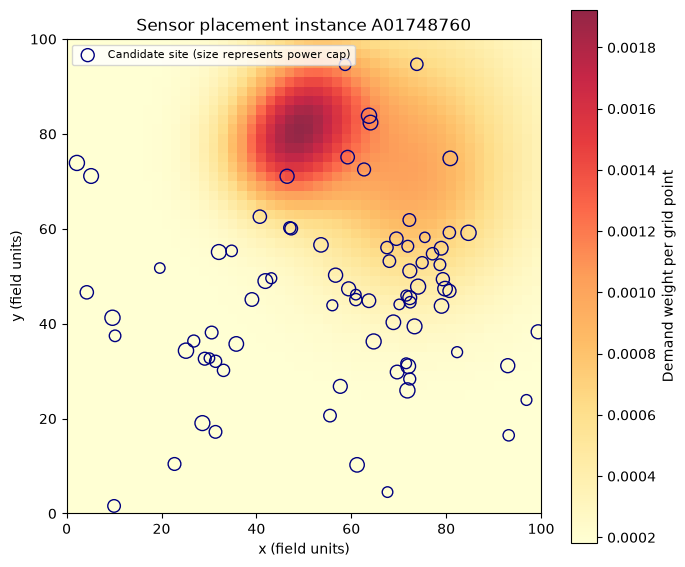

In [11]:
fig, ax = plt.subplots(figsize=(7, 6))
g = spec.grid_size
image = ax.imshow(
    instance.demand.reshape(g, g).T,
    origin="lower", extent=[0, 100, 0, 100], cmap="YlOrRd", alpha=0.85,
)
ax.scatter(
    instance.candidates[:, 0], instance.candidates[:, 1],
    s=20 + 100 * instance.power_cap / spec.power_max,
    facecolors="none", edgecolors="navy", linewidths=1,
    label="Candidate site (size represents power cap)",
)
fig.colorbar(image, ax=ax, label="Demand weight per grid point")
ax.set(xlabel="x (field units)", ylabel="y (field units)",
       title=f"Sensor placement instance {STUDENT_ID}", aspect="equal")
ax.legend(loc="upper left", fontsize=8)
fig.tight_layout()
plt.show()

## Feasibility under random sampling

For each of 2,000 deployments, an activation probability is drawn uniformly from [0.1, 0.5], then each site is independently activated with that probability. Each power is drawn uniformly from [1, its own cap]. This characterizes the sampling distribution; it is separate from final optimizer runs.

In [12]:
CHAR_SEED = 10_000
N_DEPLOYMENTS = 2_000
rng = np.random.default_rng(CHAR_SEED)
characterization = SensorPlacementProblem(instance, budget=N_DEPLOYMENTS, seed=CHAR_SEED)
feasible_flags = []
component_counts = []
active_counts = []
sample_scores = []

for _ in range(N_DEPLOYMENTS):
    active, power = sample_deployment(rng, instance)
    result = characterization.evaluate_verbose(active, power)
    feasible_flags.append(result.feasible)
    component_counts.append(result.n_components)
    active_counts.append(result.n_active)
    sample_scores.append(result.objective)

feasible_flags = np.asarray(feasible_flags)
component_counts = np.asarray(component_counts)
active_counts = np.asarray(active_counts)
sample_scores = np.asarray(sample_scores)
feasible_fraction = float(feasible_flags.mean())
assert characterization.evaluations_used == N_DEPLOYMENTS

print(f"Feasible deployments: {feasible_flags.sum()}/{N_DEPLOYMENTS} ({feasible_fraction:.2%})")
print(f"Median active count: {np.median(active_counts):.1f}")
print(f"Median component count: {np.median(component_counts):.1f}")
print(f"Characterization evaluations: {characterization.evaluations_used}")

Feasible deployments: 330/2000 (16.50%)
Median active count: 24.0
Median component count: 3.0
Characterization evaluations: 2000


## Random-walk autocorrelation

The walk makes 1,000 moves and accepts every move. With probability 0.5 it flips one uniformly selected activation bit; otherwise it perturbs the power of a uniformly selected active sensor with Gaussian standard deviation 3, clipped to its bounds. An empty deployment forces a flip. The initial evaluation costs one additional call. This diagnostic depends on both the neighborhood and the sampled trajectory.

Lag-1 autocorrelation: 0.9353
Walk evaluations: 1001 (initial state + 1000 moves)


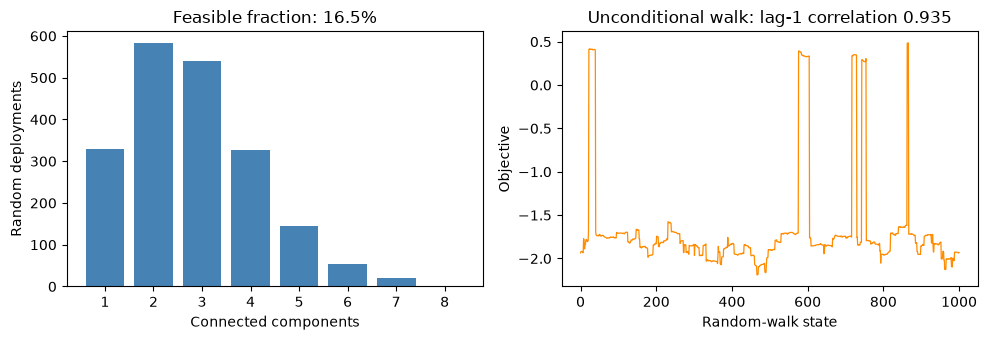

In [13]:
WALK_SEED = 10_001
WALK_STEPS = 1_000
WALK_POWER_STEP = 3.0
walk_problem = SensorPlacementProblem(instance, budget=WALK_STEPS + 1, seed=WALK_SEED)
walk_values = random_walk(walk_problem, WALK_SEED, WALK_STEPS, WALK_POWER_STEP)

assert walk_problem.evaluations_used == WALK_STEPS + 1
assert np.std(walk_values[:-1]) > 0 and np.std(walk_values[1:]) > 0
rho_1 = float(np.corrcoef(walk_values[:-1], walk_values[1:])[0, 1])

print(f"Lag-1 autocorrelation: {rho_1:.4f}")
print(f"Walk evaluations: {walk_problem.evaluations_used} (initial state + {WALK_STEPS} moves)")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
components, frequencies = np.unique(component_counts, return_counts=True)
axes[0].bar(components, frequencies, color="steelblue")
axes[0].set(xlabel="Connected components", ylabel="Random deployments",
            title=f"Feasible fraction: {feasible_fraction:.1%}")
axes[0].set_xticks(components)
axes[1].plot(np.arange(walk_values.size), walk_values, lw=0.9, color="darkorange")
axes[1].set(xlabel="Random-walk state", ylabel="Objective",
            title=f"Unconditional walk: lag-1 correlation {rho_1:.3f}")
fig.tight_layout()
plt.show()

## Preliminary interpretation

The feasible fraction describes how often connected deployments appeared under the declared random-sampling procedure. It is not the fraction of all possible deployments that are feasible, and it may change with the activation and power distributions.

The measured lag-1 autocorrelation indicates a strong positive relationship between consecutive objective values in this walk: values above the trajectory mean tend to be followed by above-mean values, and below-mean values tend to be followed by below-mean values. The current value therefore carries information about the next one, but the correlation is not a prediction-accuracy percentage and does not mean that moves usually improve the objective.

This observation motivates testing whether neighborhood-based methods can exploit local structure. It does not establish that optimization will be easy or that any method will outperform Monte Carlo. The estimate depends on the move operator, step size and sampled trajectory; transitions between connected and disconnected deployments can also influence it through the penalty.

These are initial characterization results. Later sections will examine whether the proposed methods exploit this structure under the evaluation budget. Their convergence traces, internal-state diagnostics and paired comparisons will provide the evidence for the final analysis.


In [14]:
print(
    f"Under the declared random-deployment distribution, {feasible_fraction:.1%} "
    "of sampled deployments were connected. This is distribution-specific, "
    "not the fraction of all possible deployments that are feasible."
)
print(
    f"The lag-1 correlation was {rho_1:.3f} for the declared move operator and seed. "
    "It describes this walk; it does not establish global smoothness, "
    "unimodality or optimizer superiority."
)
print("The diagnostics above are characterization, not 30-seed optimizer results.")

Under the declared random-deployment distribution, 16.5% of sampled deployments were connected. This is distribution-specific, not the fraction of all possible deployments that are feasible.
The lag-1 correlation was 0.935 for the declared move operator and seed. It describes this walk; it does not establish global smoothness, unimodality or optimizer superiority.
The diagnostics above are characterization, not 30-seed optimizer results.


## Why this instance is difficult

Even before assigning power, the 80 activation decisions define $2^{80} \approx 1.21\times10^{24}$ possible subsets. Each subset also admits continuous power assignments, so exhaustive enumeration is not a practical approach.

The two decision layers interact. Changing power affects coverage, energy, redundant coverage and communication links. Activating or removing a sensor changes the contribution of the remaining sensors, even when their powers stay fixed. Different site locations and power caps also mean that one candidate cannot simply replace another.

The objective contains competing effects: more power may cover additional demand and connect the network, but increases quadratic energy cost and may add redundant coverage. Removing an overlapping sensor may save energy, yet lose demand that only it serves or remove a communication bridge. A locally attractive change can therefore reduce the overall objective.

Connectivity introduces abrupt changes. A small power reduction can remove a critical link, split the deployment into multiple components and trigger a large penalty. Coverage is also evaluated at discrete grid points, so a small radius change may reach no new point or cross one or more coverage thresholds.

The characterization provides instance-specific evidence. Only 16.5% of the 2,000 deployments generated by the declared sampling procedure were connected. The random walk had lag-1 autocorrelation of approximately 0.935, indicating local dependence under its chosen moves rather than an entirely unstructured objective. This does not establish that global optimization is easy: the estimate depends on the move operator and trajectory, and connectivity penalties contribute to it. The number and quality of local optima have not been established by these diagnostics.


## Coupling: design stated before results

A controlled two-site example first tests whether changing power alone can change feasibility. The stochastic study then compares two ways of organizing the same annealing engine. It measures the consequences of the selected layer schedule; it is not a proof that every staged algorithm is inferior.

`joint(seed)` may flip activation bits or perturb active-sensor powers throughout the budget. `two_stage(seed)` first searches activation at fixed nominal power for 2,500 evaluations, then searches power on its selected subset for the remaining 2,500. Both start from exactly the same seed-specific deployment, use the same move scales, and follow one global geometric cooling schedule across 4,999 proposals. Stage two starts from the best evaluated stage-one state and reuses its known score. This costs no new evaluation because it is the same state, and the next power proposal is charged normally. The temperature is not reset at the stage boundary.

The expected limitation of staging is that a subset chosen at one nominal power cannot be reconsidered after power tuning. Joint search can revisit either layer, but might spend evaluations less efficiently. Either outcome is admissible. Only the nominal-power pilot uses separate tuning seeds; final comparisons use seeds 0–29.

In [15]:
SA_BASE_PARAMS = {
    "initial_temperature": 0.15,
    "final_temperature": 1e-4,
    "power_step": 3.0,
    "flip_probability": 0.5,
    "active_fraction": 0.3,
}
print(SA_BASE_PARAMS)

{'initial_temperature': 0.15, 'final_temperature': 0.0001, 'power_step': 3.0, 'flip_probability': 0.5, 'active_fraction': 0.3}


### Verify the reusable search engine

The checks cover the maximization sign, known acceptance probabilities, cooling endpoints, best-versus-current state, fixed-layer invariants, exact budgets and repeatability. A scripted objective with known scores tests rejection behavior; those synthetic scores are not sensor-placement results. A small staged audit checks one evaluation counter, cached boundary-state reuse and an identical temperature timeline.

In [16]:
# Acceptance is checked against known probabilities, not only a completed run.
assert accept_annealing(1.0, 0.1, 0.999)
assert accept_annealing(0.0, 0.1, 0.999)
assert accept_annealing(-1.0, 1.0, 0.2)
assert not accept_annealing(-1.0, 1.0, 0.5)
assert not accept_annealing(-1.0, 0.01, 0.2)
assert np.isclose(geometric_temperature(0, 4_999, 0.15, 1e-4), 0.15)
assert np.isclose(geometric_temperature(4_998, 4_999, 0.15, 1e-4), 1e-4)

from types import SimpleNamespace


class ScriptedProblem:
    def __init__(self):
        self.instance = SimpleNamespace(n_candidates=2, power_cap=np.array([5., 5.]),
                                        spec=SimpleNamespace(power_min=1.))
        self.budget, self.evaluations_used = 4, 0
        self.scores = [0., 1., -1., 2.]

    @property
    def evaluations_remaining(self):
        return self.budget - self.evaluations_used

    def evaluate_verbose(self, active, power):
        score = self.scores[self.evaluations_used]
        self.evaluations_used += 1
        return SimpleNamespace(objective=score, n_components=1, n_active=int(active.sum()))


scripted = simulated_annealing(
    ScriptedProblem(), 7, initial_temperature=1., final_temperature=0.01,
    initial_active=np.ones(2, dtype=bool), initial_power=np.ones(2) * 2,
    mode="power", return_details=True,
)
assert np.array_equal(scripted["log"]["current_score"], [0., 1., 1., 2.])
assert scripted["score"] == 2.


class AuditedProblem(SensorPlacementProblem):
    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.candidates_seen = []

    def evaluate_verbose(self, active, power):
        self.candidates_seen.append((active.copy(), power.copy()))
        return super().evaluate_verbose(active, power)


sa_check_problems = []
initial_active = np.zeros(80, dtype=bool)
initial_active[:20] = True
initial_power = np.minimum(np.full(80, 12.), instance.power_cap)

for mode in ("discrete", "power", "joint"):
    probe = AuditedProblem(instance, budget=37, seed=20_100)
    result = simulated_annealing(
        probe, 20_100, **SA_BASE_PARAMS, mode=mode,
        initial_active=initial_active, initial_power=initial_power, return_details=True,
    )
    sa_check_problems.append(probe)
    assert probe.evaluations_used == len(probe.record.values) == 37
    assert result["score"] == max(probe.record.values) == probe.record.best
    for a, p in probe.candidates_seen:
        assert np.all((p >= 1) & (p <= instance.power_cap))
        if mode == "discrete":
            assert np.array_equal(p, initial_power)
        elif mode == "power":
            assert np.array_equal(a, initial_active)
    score_check = SensorPlacementProblem(instance, budget=1, seed=20_100)
    assert np.isclose(score_check.evaluate(result["active"], result["power"]), result["score"])
    sa_check_problems.append(score_check)

repeat = SensorPlacementProblem(instance, budget=37, seed=20_100)
simulated_annealing(repeat, 20_100, **SA_BASE_PARAMS, mode="joint",
                    initial_active=initial_active, initial_power=initial_power)
assert np.array_equal(repeat.record.values, probe.record.values)
sa_check_problems.append(repeat)

# Audit a miniature staged run, including its boundary-state reuse and schedule.
original_problem_class, original_budget = SensorPlacementProblem, BUDGET
audits = []


class PhaseAudit(AuditedProblem):
    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)
        audits.append(self)


try:
    SensorPlacementProblem, BUDGET = PhaseAudit, 40
    SA_PARAMS = {**SA_BASE_PARAMS, "nominal_power": 12.}
    checked_joint, checked_staged = joint(20_101), two_stage(20_101)
finally:
    SensorPlacementProblem, BUDGET = original_problem_class, original_budget

assert checked_staged["phase_counts"] == {"subset": 20, "power": 20}
assert checked_staged["record"].evaluations_used == checked_joint["record"].evaluations_used == 40
assert np.allclose(checked_joint["log"]["temperature"], checked_staged["log"]["temperature"], equal_nan=True)
assert checked_staged["score"] == checked_staged["record"].best
assert np.array_equal(audits[0].candidates_seen[0][0], audits[1].candidates_seen[0][0])
assert np.array_equal(audits[0].candidates_seen[0][1], audits[1].candidates_seen[0][1])
assert all(np.array_equal(a, checked_staged["active"]) for a, _ in audits[1].candidates_seen[20:])
sa_check_problems.extend(audits)
assert np.isclose(paired_rank_biserial([2, 3], [0, 1]), 1.)
assert np.isclose(paired_rank_biserial([0, 1], [2, 3]), -1.)
assert paired_rank_biserial([1, 1], [1, 1]) == 0.
adjusted_check = holm_correction({"a": 0.01, "b": 0.04})
assert np.isclose(adjusted_check["a"], 0.02) and np.isclose(adjusted_check["b"], 0.04)
SA_CHECK_EVALUATIONS = sum(p.evaluations_used for p in sa_check_problems)
print("SA checks passed: maximization sign, rejection, cooling endpoints, fixed layers, best state and budgets.")
print("Staged audit: shared initialization and cooling schedule, one counter, 20 + 20 evaluations.")
print(f"Real verification evaluations: {SA_CHECK_EVALUATIONS}; scripted scores are not experimental data.")


SA checks passed: maximization sign, rejection, cooling endpoints, fixed layers, best state and budgets.
Staged audit: shared initialization and cooling schedule, one counter, 20 + 20 evaluations.
Real verification evaluations: 231; scripted scores are not experimental data.


### Direct demonstration on this instance

Two sites are selected whose separation exceeds their communication range at minimum power but is reachable at their own caps. Their activation mask remains unchanged. Two counted evaluations test the predicted change in component count. This deterministic demonstration is separate from the 30-seed optimizer comparison.

In [17]:
# A deterministic counterexample: fixed activation, different connectivity.
distances = instance.dist_between
maximum_link = 10 * np.sqrt(np.minimum(instance.power_cap[:, None], instance.power_cap[None, :]))
eligible_pairs = np.argwhere(np.triu((distances > 10) & (distances <= maximum_link), k=1))
assert eligible_pairs.size
pair = eligible_pairs[0]
probe_active = np.zeros(instance.n_candidates, dtype=bool)
probe_active[pair] = True
coupling_probe = SensorPlacementProblem(instance, budget=2, seed=30_000)
probe_low = coupling_probe.evaluate_verbose(probe_active, np.ones(instance.n_candidates))
probe_high = coupling_probe.evaluate_verbose(probe_active, instance.power_cap)
assert probe_low.n_components == 2 and not probe_low.feasible
assert probe_high.n_components == 1 and probe_high.feasible
COUPLING_PROBE_EVALUATIONS = coupling_probe.evaluations_used
print(f"Fixed active site indices (zero-based): {pair.tolist()}")
print(f"Distance between sites: {distances[tuple(pair)]:.3f}")
print(f"Power 1 at both: components={probe_low.n_components}, feasible={probe_low.feasible}, objective={probe_low.objective:.6f}")
print(f"Site caps {instance.power_cap[pair]}: components={probe_high.n_components}, feasible={probe_high.feasible}, objective={probe_high.objective:.6f}")
print(f"Controlled demonstration evaluations: {COUPLING_PROBE_EVALUATIONS}")


Fixed active site indices (zero-based): [0, 1]
Distance between sites: 36.116
Power 1 at both: components=2, feasible=False, objective=-2.085691
Site caps [18.58650087 22.25593769]: components=1, feasible=True, objective=0.320764
Controlled demonstration evaluations: 2


### Select the nominal power without using final seeds

Candidate nominal powers are 8, 12, 16 and 20, spanning low-to-high powers and including values affected by heterogeneous caps. Each candidate receives 30 discrete-only pilot runs, seeds 100–129, capped at 1,000 evaluations each. These are explicitly separate tuning costs. The candidate with the largest median penalized objective is selected; an exact tie favors lower nominal power. Final seeds are not consulted. This coarse pilot supports a practical choice, not a claim that the selected power is globally optimal or significantly superior to all alternatives.

In [18]:
from tc6035.runlog import RunSet, save_runset

NOMINAL_CANDIDATES = (8., 12., 16., 20.)
TUNING_SEEDS = tuple(range(100, 130))
TUNING_BUDGET = 1_000
assert set(TUNING_SEEDS).isdisjoint(SEEDS)
nominal_scores, nominal_connected = {}, {}

for nominal in NOMINAL_CANDIDATES:
    records, scores, connected = [], [], []
    for seed in TUNING_SEEDS:
        problem = SensorPlacementProblem(instance, budget=TUNING_BUDGET, seed=seed)
        result = simulated_annealing(
            problem, seed, **SA_BASE_PARAMS, nominal_power=nominal,
            mode="discrete", return_details=True,
        )
        assert problem.evaluations_used == TUNING_BUDGET
        records.append(problem.record)
        scores.append(result["score"])
        connected.append(result["result"].feasible)
    nominal_scores[nominal] = np.array(scores)
    nominal_connected[nominal] = int(np.sum(connected))
    save_runset(
        f"results/m0_nominal_{int(nominal)}.npz",
        RunSet(algorithm="nominal_power_tuning", student_id=STUDENT_ID,
               params={**SA_BASE_PARAMS, "nominal_power": nominal, "mode": "discrete",
                       "salt": SALT}, records=records),
    )
    q1, med, q3 = np.percentile(scores, [25, 50, 75])
    print(f"Nominal {nominal:4.0f}: median={med:.6f}, Q1–Q3=[{q1:.6f}, {q3:.6f}], connected={sum(connected)}/30", flush=True)

NOMINAL_POWER = max(NOMINAL_CANDIDATES,
                    key=lambda p: (np.median(nominal_scores[p]), -p))
SA_PARAMS = {**SA_BASE_PARAMS, "nominal_power": NOMINAL_POWER}
NOMINAL_TUNING_EVALUATIONS = len(NOMINAL_CANDIDATES) * len(TUNING_SEEDS) * TUNING_BUDGET
print(f"Selected NOMINAL_POWER = {NOMINAL_POWER:g}; largest pilot median, lower value breaks an exact tie.")
print(f"Separate tuning evaluations: {NOMINAL_TUNING_EVALUATIONS:,}")


Nominal    8: median=0.629759, Q1–Q3=[0.628075, 0.633448], connected=30/30
Nominal   12: median=0.656091, Q1–Q3=[0.648340, 0.659988], connected=30/30
Nominal   16: median=0.660115, Q1–Q3=[0.655122, 0.666064], connected=30/30
Nominal   20: median=0.672674, Q1–Q3=[0.665977, 0.677270], connected=30/30
Selected NOMINAL_POWER = 20; largest pilot median, lower value breaks an exact tie.
Separate tuning evaluations: 120,000


### Thirty paired seeds: joint versus staged search

For each seed, the final objective from joint search is compared with the final objective from staged search. Both runs start from the same deployment and receive 5,000 evaluations. The joint runs are also reused as the standalone annealing runs in the later Monte Carlo comparison; they are not executed or counted twice.

Read the results in this order:

1. **Wins, ties and losses:** how many seeds favor each method.
2. **Median paired difference:** subtract the staged score from the joint score for each seed, then take the median of those 30 differences. This expresses the typical observed advantage in objective units.
3. **Wilcoxon signed-rank test:** examines whether the paired differences provide evidence of a systematic difference, considering their signs and ranks. A small p-value is evidence against the test's no-difference model under its assumptions; it is not the probability that one algorithm is better.
4. **Holm correction:** adjusts the p-values for the two planned M0 comparisons to control the increased chance of false-positive conclusions from multiple tests.
5. **Paired rank-biserial correlation:** an additional effect-size measure based on the balance of positive and negative signed ranks. It ranges from -1 to +1; positive values favor the first method, and +1 means every nonzero paired difference favors it. It is not a percentage improvement. The assignment requires an effect size; this particular measure is an analysis choice, not a separately mandated course requirement.

The median paired difference and the win count are the most direct descriptions of the observed advantage. The statistical test and supplementary effect measure support the interpretation rather than replace it. The paired rank-biserial measure is documented in the [effectsize reference](https://easystats.github.io/effectsize/reference/rank_biserial.html).

Both tests are two-sided. Differences are rounded to 12 decimal places only for statistical ranking to avoid ranking floating-point noise; recorded objectives remain full precision. Holm-adjusted results for both planned comparisons are reported after the SA–Monte Carlo comparison.


In [19]:
from time import perf_counter
from scipy.stats import wilcoxon

joint_results, staged_results = [], []
coupling_seconds = []
for i, seed in enumerate(SEEDS):
    started = perf_counter()
    together, staged = joint(seed), two_stage(seed)
    for result in (together, staged):
        assert result["record"].evaluations_used == len(result["record"].values) == BUDGET
        assert result["score"] == result["record"].best
    assert staged["phase_counts"] == {"subset": BUDGET // 2, "power": BUDGET - BUDGET // 2}
    assert np.isclose(together["log"]["current_score"][0], staged["log"]["current_score"][0])
    assert np.allclose(together["log"]["temperature"], staged["log"]["temperature"], equal_nan=True)
    joint_results.append(together)
    staged_results.append(staged)
    coupling_seconds.append(perf_counter() - started)
    if (i + 1) % 5 == 0:
        print(f"Coupling: {i + 1}/{len(SEEDS)} paired seeds complete", flush=True)

joint_scores = np.array([r["score"] for r in joint_results])
staged_scores = np.array([r["score"] for r in staged_results])
joint_records = [r["record"] for r in joint_results]
staged_records = [r["record"] for r in staged_results]

for name, records in (("joint", joint_records), ("two_stage", staged_records)):
    save_runset(
        f"results/m0_{name}.npz",
        RunSet(algorithm=name, student_id=STUDENT_ID,
               params={**SA_PARAMS, "salt": SALT, "split": 0.5 if name == "two_stage" else None,
                       "cooling": "one global geometric schedule"}, records=records),
    )

coupling_differences = np.round(joint_scores - staged_scores, 12)
coupling_test = wilcoxon(coupling_differences, alternative="two-sided", method="auto") if np.any(coupling_differences) else None
p_coupling = float(coupling_test.pvalue) if coupling_test else 1.0
coupling_effect = paired_rank_biserial(joint_scores, staged_scores)
coupling_median_difference = float(np.median(joint_scores - staged_scores))

for name, scores in (("Joint", joint_scores), ("Two-stage", staged_scores)):
    q1, med, q3 = np.percentile(scores, [25, 50, 75])
    print(f"{name}: median={med:.6f}, Q1–Q3=[{q1:.6f}, {q3:.6f}], IQR={q3-q1:.6f}")
print(f"Joint wins/ties/losses: {(coupling_differences > 0).sum()}/{(coupling_differences == 0).sum()}/{(coupling_differences < 0).sum()}")
print(f"Median paired difference (joint minus staged): {coupling_median_difference:+.6f}")
print(f"Wilcoxon raw p={p_coupling:.6g}; paired rank-biserial effect={coupling_effect:+.4f}")
print("Holm adjustment across the two planned M0 tests is reported after the SA–Monte Carlo comparison.")
print("Per staged run: 2,500 subset evaluations + 2,500 power evaluations; one evaluator.")


Coupling: 5/30 paired seeds complete
Coupling: 10/30 paired seeds complete
Coupling: 15/30 paired seeds complete
Coupling: 20/30 paired seeds complete
Coupling: 25/30 paired seeds complete
Coupling: 30/30 paired seeds complete
Joint: median=0.714655, Q1–Q3=[0.712220, 0.717910], IQR=0.005690
Two-stage: median=0.687170, Q1–Q3=[0.679718, 0.696354], IQR=0.016636
Joint wins/ties/losses: 27/0/3
Median paired difference (joint minus staged): +0.027689
Wilcoxon raw p=0.000110582; paired rank-biserial effect=+0.7591
Holm adjustment across the two planned M0 tests is reported after the SA–Monte Carlo comparison.
Per staged run: 2,500 subset evaluations + 2,500 power evaluations; one evaluator.


## Monte Carlo baseline

Each evaluation samples a fresh activation vector and power vector independently of previous samples, scores the complete deployment and retains the best solution found. A run uses exactly 5,000 evaluations, including every rejected or infeasible sample. The baseline uses the 30 declared seeds and no objective calls outside the instrumented evaluator.

An activation probability is sampled uniformly from [0.1, 0.5] for each deployment; sites are activated independently conditional on that probability. This covers expected deployment sizes from 8 to 40, spanning sparse and denser deployments without fixing one cardinality. It is the course's suggested starting range and matches the feasibility diagnostic. No range tuning has been performed. Extreme cardinalities remain possible but receive less sampling effort; the induced distribution is not uniform over all binary vectors. Powers are uniform within each site's own bounds.

The method returns the largest penalized objective, not the last evaluated score. Stored best vectors and objective components come from an already counted evaluation; reporting them spends no extra evaluations.

### Implementation checks

Small separate runs verify exact budget use, replay the same candidates independently, check the retained maximum and vectors, and verify seeded repeatability. These evaluations are reported separately from the baseline runs.

In [20]:
CHECK_SEED = 20_000
CHECK_BUDGET = 37
check_a = SensorPlacementProblem(instance, budget=CHECK_BUDGET, seed=CHECK_SEED)
check_score, check_active, check_power, check_result = monte_carlo(
    check_a, CHECK_SEED, return_solution=True,
)

# Independent replay: sample the candidates and explicitly take their maximum.
check_b = SensorPlacementProblem(instance, budget=CHECK_BUDGET, seed=CHECK_SEED)
replay_rng = np.random.default_rng(CHECK_SEED)
replay_scores = []
for _ in range(CHECK_BUDGET):
    active, power = sample_deployment(replay_rng, instance)
    replay_scores.append(check_b.evaluate(active, power))

assert np.isclose(check_score, max(replay_scores))
assert np.array_equal(check_a.record.values, check_b.record.values)
assert np.array_equal(check_a.record.best_so_far, np.maximum.accumulate(replay_scores))
assert check_a.evaluations_used == check_b.evaluations_used == CHECK_BUDGET
assert check_active.dtype == bool and check_active.shape == (80,)
assert np.all((check_power >= spec.power_min) & (check_power <= instance.power_cap))

# The returned vectors must reproduce the saved best result in a separate check.
solution_probe = SensorPlacementProblem(instance, budget=1, seed=CHECK_SEED)
assert np.isclose(solution_probe.evaluate(check_active, check_power), check_score)

repeat_probe = SensorPlacementProblem(instance, budget=CHECK_BUDGET, seed=CHECK_SEED)
assert monte_carlo(repeat_probe, CHECK_SEED) == check_score
assert np.array_equal(repeat_probe.record.values, check_a.record.values)
MC_CHECK_EVALUATIONS = 3 * CHECK_BUDGET + 1
print("Monte Carlo checks passed: exact budget, independent replay, best solution and seeded repeatability.")
print(f"Separate verification evaluations: {MC_CHECK_EVALUATIONS}")

Monte Carlo checks passed: exact budget, independent replay, best solution and seeded repeatability.
Separate verification evaluations: 112


### Thirty-seed experiment

Each seed starts a fresh evaluator on the same instance. Run traces are saved locally for later comparisons and are not separate submission files. The returned score is checked against both the recorded best and the maximum evaluated value.

In [21]:
from time import perf_counter
from tc6035.runlog import RunSet, save_runset

MC_PARAMS = {"active_fraction_range": (0.1, 0.5)}
mc_records, mc_solutions = [], []
mc_run_seconds = []

for i, seed in enumerate(SEEDS):
    prob = SensorPlacementProblem(instance, budget=BUDGET, seed=seed)
    started = perf_counter()
    score, active, power, result = monte_carlo(
        prob, seed, **MC_PARAMS, return_solution=True,
    )
    mc_run_seconds.append(perf_counter() - started)
    assert prob.evaluations_used == len(prob.record.values) == BUDGET
    assert score == prob.record.best == max(prob.record.values)
    mc_records.append(prob.record)
    mc_solutions.append((active, power, result))
    if (i + 1) % 5 == 0:
        print(f"Monte Carlo: {i + 1}/{len(SEEDS)} seeds complete", flush=True)

mc_scores = np.array([record.best for record in mc_records])
MC_BASELINE_MEDIAN = float(np.median(mc_scores))
MC_Q1, MC_Q3 = np.percentile(mc_scores, [25, 75])
MC_IQR = float(MC_Q3 - MC_Q1)
mc_used = np.array([record.evaluations_used for record in mc_records])
mc_feasible_bests = sum(result.feasible for _, _, result in mc_solutions)

save_runset(
    "results/m0_monte_carlo.npz",
    RunSet(algorithm="monte_carlo", student_id=STUDENT_ID,
           params={**MC_PARAMS, "salt": SALT}, records=mc_records),
)

print(f"Seeds: {SEEDS}")
print(f"Median final objective: {MC_BASELINE_MEDIAN:.6f}")
print(f"Q1–Q3: [{MC_Q1:.6f}, {MC_Q3:.6f}] | IQR width: {MC_IQR:.6f}")
print(f"Connected best solutions: {mc_feasible_bests}/{len(SEEDS)}")
print(f"Evaluations per run: min={mc_used.min()}, max={mc_used.max()}")
print(f"Total baseline evaluations: {mc_used.sum():,}")
print(f"Median runtime per run: {np.median(mc_run_seconds):.2f} seconds")

Monte Carlo: 5/30 seeds complete
Monte Carlo: 10/30 seeds complete
Monte Carlo: 15/30 seeds complete
Monte Carlo: 20/30 seeds complete
Monte Carlo: 25/30 seeds complete
Monte Carlo: 30/30 seeds complete
Seeds: (0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29)
Median final objective: 0.551577
Q1–Q3: [0.540722, 0.561175] | IQR width: 0.020453
Connected best solutions: 30/30
Evaluations per run: min=5000, max=5000
Total baseline evaluations: 150,000
Median runtime per run: 1.07 seconds


### Baseline convergence and variation

The full view retains the initial negative scores, which arise from disconnected sampled deployments. A second view enlarges evaluations 100–5,000 with vertical limits derived from the same median and quartile data; it introduces no additional run or resampling. The band shows Q1–Q3 of the 30 best-so-far traces at each evaluation. The curve is a pointwise median across runs, not the trajectory of one seed.

The final-score scatter shows one retained best value per seed after 5,000 evaluations. Its vertical scale differs because it contains only final scores. The expanded view and printed checkpoints expose later improvements hidden by the full vertical range. These figures do not by themselves establish convergence to an optimum or replace later mechanism-specific diagnostics.


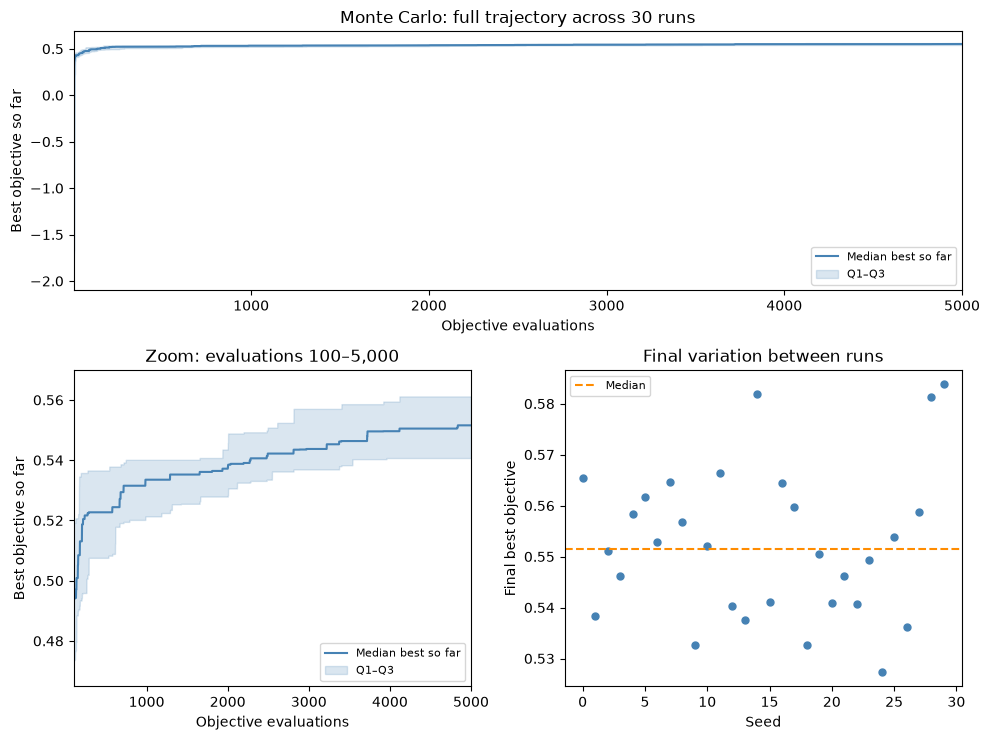

Median best at evaluation 100: 0.494076
Median best at evaluation 1,000: 0.533529
Median best at evaluation 5,000: 0.551577
Runs improving after evaluation 1,000: 27/30


In [22]:
mc_traces = np.array([record.best_so_far for record in mc_records])
trace_q1, trace_median, trace_q3 = np.percentile(mc_traces, [25, 50, 75], axis=0)
evaluations = np.arange(1, BUDGET + 1)
MC_ZOOM_START = 100
zoom = evaluations >= MC_ZOOM_START

fig = plt.figure(figsize=(10, 7.5))
grid = fig.add_gridspec(2, 2, height_ratios=[0.9, 1.1])
full_ax = fig.add_subplot(grid[0, :])
zoom_ax = fig.add_subplot(grid[1, 0])
scores_ax = fig.add_subplot(grid[1, 1])

for ax, mask in ((full_ax, np.ones(BUDGET, dtype=bool)), (zoom_ax, zoom)):
    ax.plot(evaluations[mask], trace_median[mask], color="steelblue", label="Median best so far")
    ax.fill_between(evaluations[mask], trace_q1[mask], trace_q3[mask],
                    color="steelblue", alpha=0.2, label="Q1–Q3")
    ax.set(xlabel="Objective evaluations", ylabel="Best objective so far")
    ax.legend(fontsize=8, loc="lower right")

full_ax.set(title="Monte Carlo: full trajectory across 30 runs", xlim=(1, BUDGET))
zoom_low, zoom_high = trace_q1[zoom].min(), trace_q3[zoom].max()
zoom_padding = max(0.005, 0.1 * (zoom_high - zoom_low))
zoom_ax.set(title=f"Zoom: evaluations {MC_ZOOM_START}–{BUDGET:,}",
            xlim=(MC_ZOOM_START, BUDGET),
            ylim=(zoom_low - zoom_padding, zoom_high + zoom_padding))
zoom_ax.ticklabel_format(axis="y", style="plain", useOffset=False)

scores_ax.scatter(SEEDS, mc_scores, color="steelblue", s=25)
scores_ax.axhline(MC_BASELINE_MEDIAN, color="darkorange", linestyle="--", label="Median")
scores_ax.set(xlabel="Seed", ylabel="Final best objective", title="Final variation between runs")
scores_ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

print(f"Median best at evaluation 100: {trace_median[99]:.6f}")
print(f"Median best at evaluation 1,000: {trace_median[999]:.6f}")
print(f"Median best at evaluation 5,000: {trace_median[-1]:.6f}")
print(f"Runs improving after evaluation 1,000: {np.sum(mc_traces[:, -1] > mc_traces[:, 999])}/{len(SEEDS)}")

### A representative deployment

The illustrated run is the one closest to the median final score. Shaded discs represent sensing coverage, filled markers are active sensors, and thin lines are direct communication links. Marker size no longer encodes power caps in this solution plot.

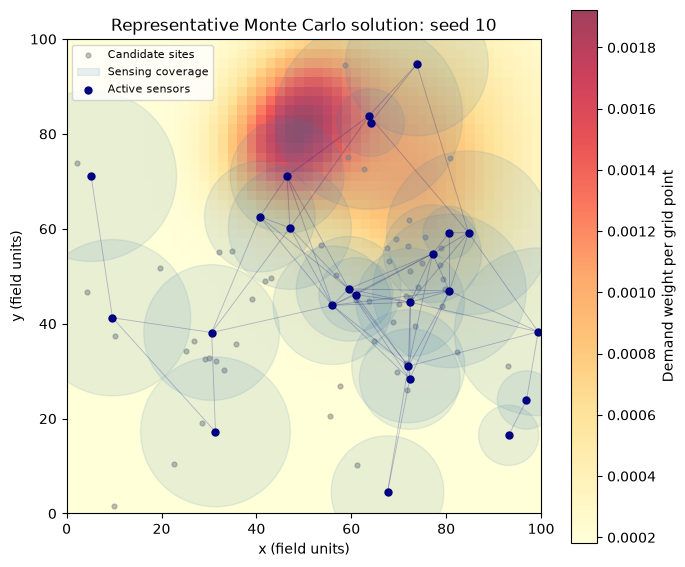

Representative seed: 10 | objective: 0.552048
Active sensors: 24 | components: 1
Coverage: 0.7718 | energy: 0.2734 | interference: 0.2229


In [23]:
# Select a typical run for illustration, rather than the luckiest run.
mc_rep_index = int(np.argmin(np.abs(mc_scores - MC_BASELINE_MEDIAN)))
mc_rep_seed = SEEDS[mc_rep_index]
rep_active, rep_power, rep_result = mc_solutions[mc_rep_index]

fig, ax = plt.subplots(figsize=(7, 6))
image = ax.imshow(instance.demand.reshape(spec.grid_size, spec.grid_size).T,
                  origin="lower", extent=[0, 100, 0, 100], cmap="YlOrRd", alpha=0.75)
ax.scatter(instance.candidates[:, 0], instance.candidates[:, 1],
           s=12, color="gray", alpha=0.5, label="Candidate sites")

indices = np.flatnonzero(rep_active)
radii = 4 * np.sqrt(rep_power[indices])
for k, site in enumerate(indices):
    ax.add_patch(plt.Circle(instance.candidates[site], radii[k],
                            color="steelblue", alpha=0.12,
                            label="Sensing coverage" if k == 0 else None))
for a in range(len(indices)):
    for b in range(a + 1, len(indices)):
        if instance.dist_between[indices[a], indices[b]] <= 2.5 * min(radii[a], radii[b]):
            xy = instance.candidates[[indices[a], indices[b]]]
            ax.plot(xy[:, 0], xy[:, 1], color="navy", lw=0.6, alpha=0.25)

ax.scatter(instance.candidates[indices, 0], instance.candidates[indices, 1],
           s=25, color="navy", label="Active sensors")
ax.set(xlim=(0, 100), ylim=(0, 100), xlabel="x (field units)", ylabel="y (field units)",
       aspect="equal", title=f"Representative Monte Carlo solution: seed {mc_rep_seed}")
ax.legend(loc="upper left", fontsize=8)
fig.colorbar(image, ax=ax, label="Demand weight per grid point")
fig.tight_layout()
plt.show()

print(f"Representative seed: {mc_rep_seed} | objective: {rep_result.objective:.6f}")
print(f"Active sensors: {rep_result.n_active} | components: {rep_result.n_components}")
print(f"Coverage: {rep_result.coverage:.4f} | energy: {rep_result.energy:.4f} | interference: {rep_result.interference:.4f}")

### Baseline interpretation

The retained final deployment was connected in all 30 runs. Power assignments were sampled within each site's limits, and each run used exactly 5,000 objective evaluations. This establishes a baseline under the declared sampling procedure. It does not imply that every sampled deployment was feasible: disconnected proposals were evaluated with the supplied penalty and consumed the same evaluation budget.

Differences between the worst and best final scores across seeds describe between-run variability, not progressive improvement from one seed to the next. Improvement during search is shown by each run's best-so-far trace. The median trace summarizes those 30 traces at each evaluation count. Its enlarged view reveals additional gains that were visually compressed by the initial negative scores in the full view.

The objective balances demand coverage against energy, redundancy and infeasibility. Neither the number of active sensors nor the objective value alone establishes how much improvement remains, since the optimum is unknown. The median and interquartile range will be compared with other methods under the same budget before judging the baseline's quality and consistency.


In [24]:
print(
    f"Monte Carlo reached a median best objective of {MC_BASELINE_MEDIAN:.4f} "
    f"with Q1–Q3 [{MC_Q1:.4f}, {MC_Q3:.4f}] after {BUDGET:,} evaluations per run. "
    f"The best retained deployment was connected in {mc_feasible_bests}/{len(SEEDS)} runs."
)
print(
    "The low feasible fraction of individual random deployments does not imply "
    "that the best of 5,000 samples is usually disconnected. These are different measurements."
)
print(
    "Keeping the best makes the best-so-far trace nondecreasing, although the "
    "sampling distribution never learns from successful deployments. "
    "Further methods will be compared against this distribution-specific baseline."
)

Monte Carlo reached a median best objective of 0.5516 with Q1–Q3 [0.5407, 0.5612] after 5,000 evaluations per run. The best retained deployment was connected in 30/30 runs.
The low feasible fraction of individual random deployments does not imply that the best of 5,000 samples is usually disconnected. These are different measurements.
Keeping the best makes the best-so-far trace nondecreasing, although the sampling distribution never learns from successful deployments. Further methods will be compared against this distribution-specific baseline.


## Simulated annealing and comparison with Monte Carlo

The same joint engine starts from a random 30%-activation deployment with powers initialized at the selected nominal value, clipped by site caps. At each proposal it flips one bit with probability 0.5 or perturbs one active sensor's power using Gaussian standard deviation 3. An empty deployment forces a bit flip. Powers are clipped into their per-site domains. Unchanged or improving proposals are accepted; a worsening proposal with $\Delta f<0$ is accepted with probability $\exp(\Delta f/T)$ because the problem maximizes.

The current state can worsen, while the separately retained best state cannot. Logs preserve current objective, components, temperature and accepted worsening moves so that the mechanism can be inspected directly.



### Cooling rationale and its limits

The course starting temperatures 0.15 and $10^{-4}$ define a global geometric schedule across 4,999 proposals:

$T_k=T_0(T_f/T_0)^{k/(4999-1)},\qquad k=0,\ldots,4998.$

The measured acceptance of *worsening proposals only* in the first and last 10% of evaluations is reported across the 30 runs, together with denominators. Ties and improvements are excluded from those rates. This is an empirical check of whether the schedule permits early exploration and suppresses late deterioration. Geometric cooling does not inherit the asymptotic global-convergence guarantee associated with appropriately slow logarithmic cooling under its required assumptions. Clipped, state-dependent proposals are used here as a finite-budget heuristic; no equilibrium-sampling or global-optimality guarantee is claimed.



### Paired comparison and schedule diagnostics

The exact joint runs from the coupling study are reused. Monte Carlo and annealing search both layers, but use different sampling and initialization distributions; the comparison assesses the complete configured solvers rather than isolating temperature as a causal factor. Every retained score comes from an evaluated candidate within the budget.

In [25]:
# The joint runs above are exactly the selected standalone SA configuration.
# Reuse them, rather than spending another 150,000 evaluations on identical runs.
sa_scores = joint_scores.copy()
sa_records = joint_records
SA_BASELINE_MEDIAN = float(np.median(sa_scores))
SA_Q1, SA_Q3 = np.percentile(sa_scores, [25, 75])
SA_IQR = float(SA_Q3 - SA_Q1)
assert len(sa_records) == len(SEEDS) == len(mc_records)
assert [r.seed for r in sa_records] == [r.seed for r in mc_records] == list(SEEDS)

save_runset(
    "results/m0_annealing.npz",
    RunSet(algorithm="simulated_annealing", student_id=STUDENT_ID,
           params={**SA_PARAMS, "salt": SALT, "reused_from": "m0_joint"}, records=sa_records),
)
sa_mc_differences = np.round(sa_scores - mc_scores, 12)
sa_mc_test = wilcoxon(sa_mc_differences, alternative="two-sided", method="auto") if np.any(sa_mc_differences) else None
p_sa_vs_mc = float(sa_mc_test.pvalue) if sa_mc_test else 1.0
sa_mc_effect = paired_rank_biserial(sa_scores, mc_scores)
sa_mc_median_difference = float(np.median(sa_scores - mc_scores))
M0_HOLM = holm_correction({"joint_vs_two_stage": p_coupling, "sa_vs_mc": p_sa_vs_mc})

acceptance = [worsening_acceptance(r["log"], BUDGET) for r in joint_results]
early_rates = np.array([a["early_rate"] for a in acceptance])
late_rates = np.array([a["late_rate"] for a in acceptance])
assert np.all(np.isfinite(early_rates)) and np.all(np.isfinite(late_rates))
early_median, late_median = float(np.median(early_rates)), float(np.median(late_rates))
sa_connected_bests = sum(r["result"].feasible for r in joint_results)

print(f"SA median={SA_BASELINE_MEDIAN:.6f}, Q1–Q3=[{SA_Q1:.6f}, {SA_Q3:.6f}], IQR={SA_IQR:.6f}")
print(f"Connected SA best solutions: {sa_connected_bests}/{len(SEEDS)}")
print(f"SA wins/ties/losses vs MC: {(sa_mc_differences > 0).sum()}/{(sa_mc_differences == 0).sum()}/{(sa_mc_differences < 0).sum()}")
print(f"Median paired difference (SA minus MC): {sa_mc_median_difference:+.6f}")
print(f"Wilcoxon raw p={p_sa_vs_mc:.6g}; paired rank-biserial effect={sa_mc_effect:+.4f}")
print(f"Holm-adjusted p-values: {M0_HOLM}")
print(f"Median worsening acceptance: first 10%={early_median:.3f}, last 10%={late_median:.3f}")
print(f"Early worsening proposals per run: {min(a['early_worsening'] for a in acceptance)}–{max(a['early_worsening'] for a in acceptance)}")
print(f"Late worsening proposals per run: {min(a['late_worsening'] for a in acceptance)}–{max(a['late_worsening'] for a in acceptance)}")
print(f"Cooling endpoints: {SA_PARAMS['initial_temperature']} to {SA_PARAMS['final_temperature']}")

SA_REP_INDEX = int(np.argmin(np.abs(sa_scores - SA_BASELINE_MEDIAN)))
sa_rep_log = joint_results[SA_REP_INDEX]["log"]
Path("results").mkdir(exist_ok=True)
np.savez_compressed("results/m0_sa_internal_state.npz", **{
    f"seed_{seed}_{key}": value
    for seed, result in zip(SEEDS, joint_results) for key, value in result["log"].items()
})


SA median=0.714655, Q1–Q3=[0.712220, 0.717910], IQR=0.005690
Connected SA best solutions: 30/30
SA wins/ties/losses vs MC: 30/0/0
Median paired difference (SA minus MC): +0.163040
Wilcoxon raw p=1.86265e-09; paired rank-biserial effect=+1.0000
Holm-adjusted p-values: {'sa_vs_mc': 3.725290298461914e-09, 'joint_vs_two_stage': 0.00011058151721954346}
Median worsening acceptance: first 10%=0.918, last 10%=0.047
Early worsening proposals per run: 199–241
Late worsening proposals per run: 422–462
Cooling endpoints: 0.15 to 0.0001


### Comparative trajectories and internal state

The convergence plots use a common evaluation axis, median trajectories and Q1–Q3. The enlarged view retains evaluations 100–5,000. Paired scatter plots show one point per seed against an equal-score reference.

For the SA run closest to the median final result, the mechanism figure distinguishes accepted current-state quality from best-so-far quality. Marked accepted worsening moves show how temperature allows deterioration while retaining a separate best solution. The component trace describes the accepted current network. These state variables come from the algorithm's own logs, not illustrative animation data.

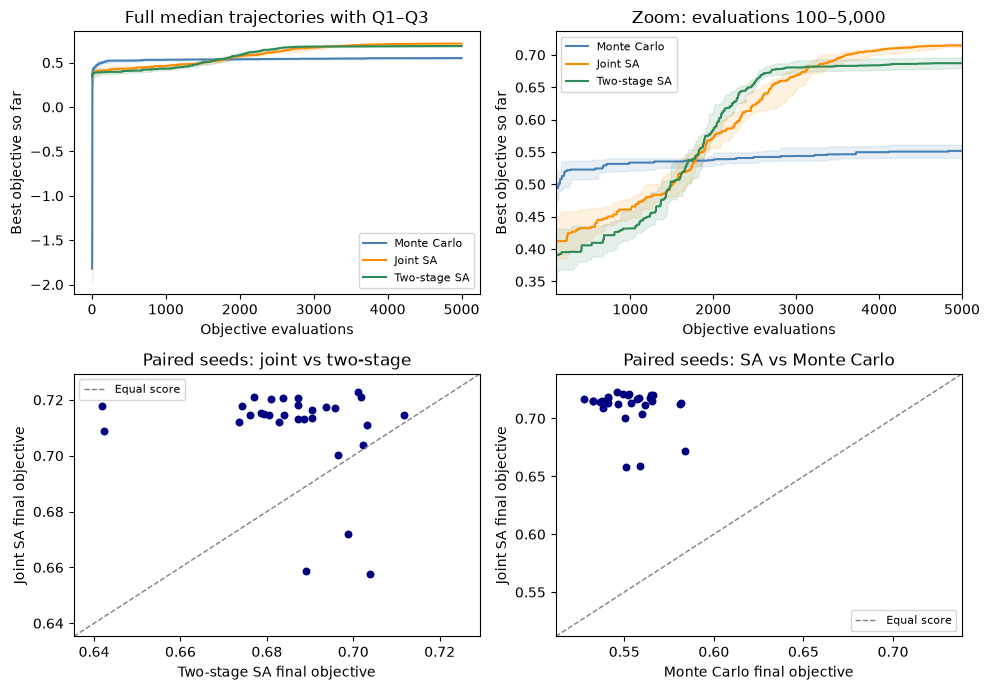

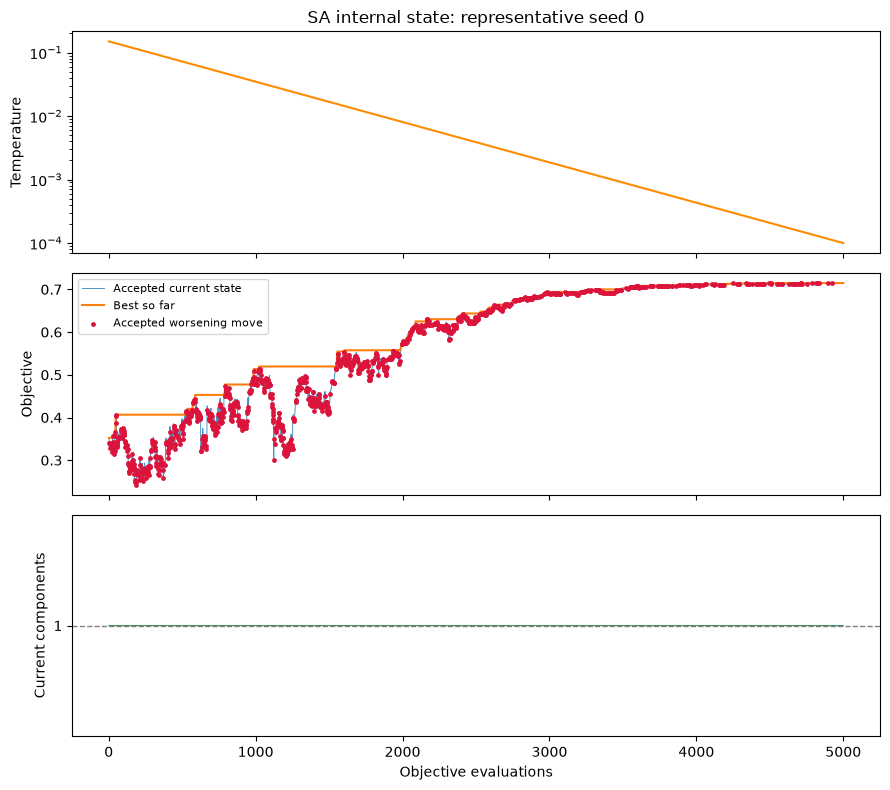

Representative early/late worsening acceptance: {'early_rate': 0.9004739336492891, 'late_rate': 0.05088495575221239, 'early_worsening': 211, 'late_worsening': 452}
Accepted worsening moves in representative run: 1174


In [26]:
# Both methods are displayed against objective evaluations, not iterations.
sa_traces = np.array([r.best_so_far for r in sa_records])
staged_traces = np.array([r.best_so_far for r in staged_records])
evaluation_axis = np.arange(1, BUDGET + 1)
tail = evaluation_axis >= 100
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
tail_limits = []
for traces, label, color in ((mc_traces, "Monte Carlo", "steelblue"),
                             (sa_traces, "Joint SA", "darkorange"),
                             (staged_traces, "Two-stage SA", "seagreen")):
    q1, median, q3 = np.percentile(traces, [25, 50, 75], axis=0)
    for ax, mask in ((axes[0, 0], np.ones(BUDGET, dtype=bool)), (axes[0, 1], tail)):
        ax.plot(evaluation_axis[mask], median[mask], color=color, label=label)
        ax.fill_between(evaluation_axis[mask], q1[mask], q3[mask], color=color, alpha=0.12)
    tail_limits.extend([q1[tail].min(), q3[tail].max()])
for ax in axes[0]:
    ax.set(xlabel="Objective evaluations", ylabel="Best objective so far")
    ax.legend(fontsize=8)
axes[0, 0].set_title("Full median trajectories with Q1–Q3")
pad = 0.05 * (max(tail_limits) - min(tail_limits))
axes[0, 1].set(title="Zoom: evaluations 100–5,000", xlim=(100, BUDGET),
                ylim=(min(tail_limits) - pad, max(tail_limits) + pad))

for ax, x, y, xlabel, ylabel in (
    (axes[1, 0], staged_scores, joint_scores, "Two-stage SA final objective", "Joint SA final objective"),
    (axes[1, 1], mc_scores, sa_scores, "Monte Carlo final objective", "Joint SA final objective"),
):
    low, high = min(x.min(), y.min()), max(x.max(), y.max())
    gap = max(0.005, (high - low) * 0.08)
    ax.plot([low - gap, high + gap], [low - gap, high + gap], "--", color="gray", lw=1, label="Equal score")
    ax.scatter(x, y, s=22, color="navy")
    ax.set(xlabel=xlabel, ylabel=ylabel, xlim=(low - gap, high + gap), ylim=(low - gap, high + gap))
    ax.legend(fontsize=8)
axes[1, 0].set_title("Paired seeds: joint vs two-stage")
axes[1, 1].set_title("Paired seeds: SA vs Monte Carlo")
fig.tight_layout()
plt.show()

# The accepted current state is logged separately from evaluated proposals.
fig, axes = plt.subplots(3, 1, figsize=(9, 8), sharex=True)
evaluations_logged = sa_rep_log["evaluation"]
axes[0].plot(evaluations_logged[1:], sa_rep_log["temperature"][1:], color="darkorange")
axes[0].set(yscale="log", ylabel="Temperature", title=f"SA internal state: representative seed {SEEDS[SA_REP_INDEX]}")
axes[1].plot(evaluations_logged, sa_rep_log["current_score"], lw=0.7, alpha=0.8, label="Accepted current state")
axes[1].plot(evaluation_axis, sa_records[SA_REP_INDEX].best_so_far, lw=1.5, label="Best so far")
accepted_worse = sa_rep_log["worsening"] & sa_rep_log["accepted"]
axes[1].scatter(evaluations_logged[accepted_worse], sa_rep_log["current_score"][accepted_worse],
                s=6, color="crimson", label="Accepted worsening move", zorder=3)
axes[1].set_ylabel("Objective")
axes[1].legend(fontsize=8)
axes[2].plot(evaluations_logged, sa_rep_log["components"], lw=0.8, color="seagreen")
axes[2].axhline(1, color="gray", ls="--", lw=1)
max_components = int(sa_rep_log["components"].max())
axes[2].set(xlabel="Objective evaluations", ylabel="Current components",
            yticks=np.arange(1, max_components + 1), ylim=(0.5, max_components + 0.5))
fig.tight_layout()
plt.show()

print(f"Representative early/late worsening acceptance: {acceptance[SA_REP_INDEX]}")
print(f"Accepted worsening moves in representative run: {accepted_worse.sum()}")


### Inspect one annealing decision

This short run uses the actual sensor instance, seed 0 and the selected SA parameters. It has a separate budget of 40 evaluations: one initial state and 39 proposals. It follows the first 39 moves of the full 4,999-move cooling schedule; it is not a complete cooling run and is not included in the 30-seed comparison.

The cell checks every transition in this short run, then displays the first accepted worsening proposal. Compare its objective with the previous current objective, compute the acceptance probability, and compare it with the recorded random draw. The current solution changes when the proposal is accepted; the best solution changes only after an improvement. A random draw is used only for worsening proposals.

This is a mechanism check, not evidence of solution quality or optimality. Future algorithms will include a similar short validation focused on their own update rule.


In [27]:
SA_TRACE_BUDGET = 40
sa_trace_problem = SensorPlacementProblem(instance, budget=SA_TRACE_BUDGET, seed=0)
sa_trace = simulated_annealing(
    sa_trace_problem, 0, **SA_PARAMS,
    schedule_moves=BUDGET - 1, return_details=True,
)
trace = sa_trace["log"]
before = trace["current_score"][:-1]
proposed = trace["proposal_score"][1:]
delta = proposed - before
probability = np.exp(np.minimum(delta / trace["temperature"][1:], 0.0))
expected_acceptance = (delta >= 0) | (trace["uniform"][1:] < probability)
expected_current = np.where(expected_acceptance, proposed, before)
expected_best = np.maximum.accumulate(trace["current_score"])

assert sa_trace_problem.evaluations_used == SA_TRACE_BUDGET
assert np.allclose(trace["delta"][1:], delta)
assert np.array_equal(trace["accepted"][1:], expected_acceptance)
assert np.allclose(trace["current_score"][1:], expected_current)
assert np.allclose(trace["best_score"], expected_best)
assert np.allclose(trace["proposal_score"][1:], sa_trace_problem.record.values[1:])
assert np.isclose(sa_trace["score"], sa_trace_problem.record.best)

i = int(np.flatnonzero(trace["accepted"] & trace["worsening"])[0])
rows = (
    ("Current objective before", trace["current_score"][i - 1]),
    ("Proposed objective", trace["proposal_score"][i]),
    ("Difference (proposal - current)", trace["delta"][i]),
    ("Temperature", trace["temperature"][i]),
    ("Acceptance probability", probability[i - 1]),
    ("Random draw", trace["uniform"][i]),
    ("Current objective after", trace["current_score"][i]),
    ("Best objective before", trace["best_score"][i - 1]),
    ("Best objective after", trace["best_score"][i]),
)
print(f"Seed 0 | move {i} | evaluation {trace['evaluation'][i]} | {trace['move_kind'][i]}")
for label, value in rows:
    print(f"{label:34} {value: .9f}")
assert trace["uniform"][i] < probability[i - 1]
assert trace["current_score"][i] < trace["current_score"][i - 1]
assert trace["best_score"][i] == trace["best_score"][i - 1]
SA_TRACE_EVALUATIONS = sa_trace_problem.evaluations_used
print("Accepted a worsening proposal; retained the previous best.")
print(f"Transition checks passed for {len(delta)} proposals; separate evaluations: {SA_TRACE_EVALUATIONS}.")


Seed 0 | move 2 | evaluation 3 | flip
Current objective before            0.352229837
Proposed objective                  0.339280283
Difference (proposal - current)    -0.012949553
Temperature                         0.149780676
Acceptance probability              0.917175198
Random draw                         0.813270239
Current objective after             0.339280283
Best objective before               0.352229837
Best objective after                0.352229837
Accepted a worsening proposal; retained the previous best.
Transition checks passed for 39 proposals; separate evaluations: 40.


## M0 analysis

The two-sensor example showed why sensor selection and power should be considered together: the same active sites changed from disconnected to connected when only power changed. The search comparison then asked whether separating the decisions affected the result. Joint search won in 27 of 30 paired seeds and staged search won in three. Their final-score medians were 0.7147 and 0.6872. The median difference within paired seeds was +0.0277 in favor of joint search. Wilcoxon, with Holm correction, provided evidence of a difference between these tested configurations (adjusted p = 0.000111).

Both methods received 5,000 evaluations and the same initial deployment and cooling schedule. Staged search used 2,500 evaluations to choose sensors and 2,500 to tune their power, without reconsidering the subset. Its nominal power of 20 was selected from four candidates using separate tuning seeds and 1,000-evaluation pilot runs. This selection cost 120,000 evaluations and did not use the final comparison seeds.

Annealing also beat Monte Carlo in all 30 paired seeds. Monte Carlo's median was 0.5516, and the median paired advantage of annealing was +0.1630. The adjusted Wilcoxon p-value was 3.73e-09. Annealing explores changes around a current deployment and can accept temporary deterioration, while Monte Carlo keeps drawing independent proposals. Different initializations also contribute to this comparison, so it does not isolate temperature alone.

The objective gain represents a better balance of coverage, energy and interference. It does not imply that activating more sensors is always beneficial: an additional site must provide enough benefit to offset its cost.

The median acceptance of worsening proposals fell from 91.8% initially to 4.7% near the end. This supports the intended exploration-to-refinement behavior of the selected cooling schedule, but provides no global-optimality guarantee. The identical joint runs were reused for the annealing comparison, avoiding duplicate evaluations. These findings apply to this instance, budget and configurations. A different stage split, nominal-power pilot, optimizer or instance could change the ordering and would be a useful follow-up test.


## Evaluation accounting

Characterization, deterministic checks, parameter selection and final algorithm comparisons are accounted for separately. The same joint run is used in two comparisons and counted once. All real sensor-placement objective calls pass through the supplied evaluator. The scripted verification objective does not generate experimental results.

In [28]:
M0_EVALUATION_ACCOUNTING = {
    "instance_and_objective_checks": INSTANCE_CHECK_EVALUATIONS,
    "feasibility_characterization": N_DEPLOYMENTS,
    "random_walk": WALK_STEPS + 1,
    "monte_carlo_checks": MC_CHECK_EVALUATIONS,
    "annealing_checks": SA_CHECK_EVALUATIONS,
    "annealing_illustrated_validation": SA_TRACE_EVALUATIONS,
    "direct_coupling_demonstration": COUPLING_PROBE_EVALUATIONS,
    "nominal_power_tuning": NOMINAL_TUNING_EVALUATIONS,
    "final_monte_carlo_runs": len(SEEDS) * BUDGET,
    "final_joint_annealing_runs": len(SEEDS) * BUDGET,
    "final_two_stage_runs": len(SEEDS) * BUDGET,
}
for name, count in M0_EVALUATION_ACCOUNTING.items():
    print(f"{name:36} {count:>9,}")
print(f"{'Total actual sensor evaluations':36} {sum(M0_EVALUATION_ACCOUNTING.values()):>9,}")
print("Annealing results reused from joint runs: zero additional objective calls.")

instance_and_objective_checks                6
feasibility_characterization             2,000
random_walk                              1,001
monte_carlo_checks                         112
annealing_checks                           231
annealing_illustrated_validation            40
direct_coupling_demonstration                2
nominal_power_tuning                   120,000
final_monte_carlo_runs                 150,000
final_joint_annealing_runs             150,000
final_two_stage_runs                   150,000
Total actual sensor evaluations        573,392
Annealing results reused from joint runs: zero additional objective calls.


## Carry forward to M1

These computed values pass to M1. Full-precision values remain defined in code; the table summarizes this executed configuration. M1 must explicitly reference `MC_BASELINE_MEDIAN` and `NOMINAL_POWER` by name.

| Quantity / variable | Current value | Purpose |
|---|---:|---|
| `MC_BASELINE_MEDIAN` | 0.551577 | Monte Carlo reference objective |
| `MC_PARAMS["active_fraction_range"]` | (0.1, 0.5) | Baseline sampling distribution |
| `SA_BASELINE_MEDIAN` | 0.714655 | Selected joint annealing result |
| `NOMINAL_POWER` | 20, clipped by site caps | Frozen-power subset search in M1 |
| `SA_PARAMS` | T: 0.15 to 0.0001; step: 3; flip: 0.5; initial activation: 0.3 | Reproduce the selected annealing configuration |
| `BUDGET` | 5,000 per final run | Shared evaluation cap |
| `SEEDS` | 0–29 (30 seeds) | Paired final runs |
| `TUNING_SEEDS` / `TUNING_BUDGET` | 100–129 / 1,000 | Separate nominal-power selection |
| `feasible_fraction` | 0.165 (16.5%) | Random-deployment diagnostic |
| `rho_1` | 0.9353 | Random-walk lag-1 correlation |
| `WALK_POWER_STEP` | 3.0 | Walk perturbation scale |
| `CHAR_SEED` / `WALK_SEED` | 10,000 / 10,001 | Diagnostic reproducibility |
| Characterization / walk evaluations | 2,000 / 1,001 | Separate diagnostic budgets |
| Early / late worsening acceptance, median | 0.918 / 0.047 | Empirical cooling behavior |
| `p_coupling` / Holm-adjusted | 0.000111 / 0.000111 | Joint versus staged comparison |
| `coupling_effect` | +0.759 | Paired rank-biserial effect, joint minus staged |
| `p_sa_vs_mc` / Holm-adjusted | 1.86e-09 / 3.73e-09 | Annealing versus Monte Carlo |
| `sa_mc_effect` | +1.000 | Paired rank-biserial effect, SA minus MC |

The table and analysis describe the reported parameters and instance.



In [29]:
M0_DIAGNOSTICS = {
    "characterization_seed": CHAR_SEED,
    "walk_seed": WALK_SEED,
    "feasible_fraction": feasible_fraction,
    "rho_1": rho_1,
    "walk_power_step": WALK_POWER_STEP,
    "characterization_evaluations": characterization.evaluations_used,
    "walk_evaluations": walk_problem.evaluations_used,
}
M0_CARRY_FORWARD = {
    "MC_BASELINE_MEDIAN": MC_BASELINE_MEDIAN,
    "MC_PARAMS": MC_PARAMS,
    "NOMINAL_POWER": NOMINAL_POWER,
    "SA_PARAMS": SA_PARAMS,
    "SA_BASELINE_MEDIAN": SA_BASELINE_MEDIAN,
    "p_sa_vs_mc": p_sa_vs_mc,
    "p_coupling": p_coupling,
    "M0_HOLM": M0_HOLM,
    "coupling_effect": coupling_effect,
    "sa_mc_effect": sa_mc_effect,
}
print(M0_DIAGNOSTICS)
print(M0_CARRY_FORWARD)


{'characterization_seed': 10000, 'walk_seed': 10001, 'feasible_fraction': 0.165, 'rho_1': 0.9352701174413988, 'walk_power_step': 3.0, 'characterization_evaluations': 2000, 'walk_evaluations': 1001}
{'MC_BASELINE_MEDIAN': 0.5515770165919147, 'MC_PARAMS': {'active_fraction_range': (0.1, 0.5)}, 'NOMINAL_POWER': 20.0, 'SA_PARAMS': {'initial_temperature': 0.15, 'final_temperature': 0.0001, 'power_step': 3.0, 'flip_probability': 0.5, 'active_fraction': 0.3, 'nominal_power': 20.0}, 'SA_BASELINE_MEDIAN': 0.7146553510068925, 'p_sa_vs_mc': 1.862645149230957e-09, 'p_coupling': 0.00011058151721954346, 'M0_HOLM': {'sa_vs_mc': 3.725290298461914e-09, 'joint_vs_two_stage': 0.00011058151721954346}, 'coupling_effect': 0.7591397849462366, 'sa_mc_effect': 1.0}


# M1


## Starting point from M0

M1 uses `MC_BASELINE_MEDIAN`, `NOMINAL_POWER` and `rho_1` from M0 on the same instance. Tabu searches activation only, with every power fixed at `min(NOMINAL_POWER, power_cap[i])`. Inactive powers remain stored but have no effect on the objective. Penalized disconnected deployments are evaluated normally, rather than silently rejected.



## Tabu search

This section implements and checks tabu, then selects a memory duration and candidate-list size using separate pilots. The selected configuration is then evaluated on 30 final seeds. Initial parameters are recorded before the pilot; the selected configuration is updated by both pilots as `TABU_PARAMS`.



### Move, memory and decision rules

| Component | Declared rule |
|---|---|
| Initialization | Same seeded 30%-activation initializer as M0 SA; fixed nominal powers clipped by site caps. |
| Neighborhood | Flip exactly one activation bit. Sample up to 20 distinct indices per iteration. |
| Memory | `tabu_until[i]` is the first iteration when index `i` is free again. |
| Tenure | Flipping index `i` at zero-based iteration `t` sets `tabu_until[i] = t + 1 + tenure`. It is forbidden in the next `tenure` iterations. |
| Aspiration | A tabu candidate becomes admissible if its objective is strictly greater than the best retained objective before this iteration. |
| Move selection | Choose the highest-scoring admissible candidate, even if it is worse than the current solution. |
| All candidates blocked | Follow the class fallback: choose the sampled index whose ban expires first. Record this forced override separately from aspiration. |
| Ties | Take the first tied candidate in the seeded sampled order. |
| Best solution | Retain the best activation vector separately from the current vector. |
| Revisited states | Count them for later diagnosis only; this history does not influence move selection. |



### Candidate list and evaluation cost

The list size of 20 starts as a design choice: it examines one quarter of the 80-site neighborhood and permits more steps within the same evaluation budget. M0's high local walk correlation motivates investigating nearby states, but does not prove that 20 is optimal or that tabu will beat SA. After the tenure pilot, a separate candidate-list pilot tests sizes 10, 20, 40 and 80 and retains 20 by the highest median.

Every evaluated candidate costs one evaluation, including forbidden candidates, because their scores are needed to test aspiration. The initial solution costs one as well. The last candidate list shrinks to fit the remaining budget. At 5,000 evaluations this permits 249 full lists of 20 and one final list of 19; a full-neighborhood design permits 62 lists of 80 and a final list of 39. The algorithm stops at the evaluator's limit, not at a fixed iteration count. The same evaluator can be limited by an outer stage budget.

The tenure pilot below uses separate seeds 200–209, ten seeds per duration, with 1,000 evaluations per run. It compares durations 1, 4, 12, 30 and 60 before selecting a configuration for final seeds 0–29. Its results are reported separately from the final algorithm comparison.

The candidate-list pilot uses new seeds 300–309 and 5,000 evaluations per run. It appears before the final experiment and keeps tenure 4 fixed. Its extra cost and the reuse of the identical existing final cohort are reported explicitly.


### Initial parameters and planned tuning


In [30]:
TABU_INITIAL_PARAMS = {
    "tenure": 12, "candidate_size": 20, "nominal_power": NOMINAL_POWER,
    "active_fraction": 0.3,
}
TABU_TENURE_CANDIDATES = (1, 4, 12, 30, 60)
TABU_TUNING_SEEDS = tuple(range(200, 210))
TABU_TUNING_BUDGET = 1_000
assert set(TABU_TUNING_SEEDS).isdisjoint(SEEDS)
assert set(TABU_TUNING_SEEDS).isdisjoint(TUNING_SEEDS)
assert TABU_INITIAL_PARAMS["nominal_power"] == NOMINAL_POWER
print(f"M0 Monte Carlo median: {MC_BASELINE_MEDIAN:.6f}")
print(f"M0 nominal power: {NOMINAL_POWER:g}; walk lag-1 correlation: {rho_1:.6f}")
print(f"Initial implementation parameters (not tuned): {TABU_INITIAL_PARAMS}")
print(f"Planned tenure candidates: {TABU_TENURE_CANDIDATES}; tuning seeds: {TABU_TUNING_SEEDS}")


M0 Monte Carlo median: 0.551577
M0 nominal power: 20; walk lag-1 correlation: 0.935270
Initial implementation parameters (not tuned): {'tenure': 12, 'candidate_size': 20, 'nominal_power': 20.0, 'active_fraction': 0.3}
Planned tenure candidates: (1, 4, 12, 30, 60); tuning seeds: (200, 201, 202, 203, 204, 205, 206, 207, 208, 209)


### Validation on the sensor instance

This short run uses the actual sensor instance and random seed 0. It spends 121 evaluations: one initial deployment and six steps with 20 alternatives each. Tenure 4 is used to illustrate the rule, not as the selected final duration. It means that changing a sensor normally forbids changing it again in the next four steps; aspiration and the class fallback are explicitly defined exceptions.

The cell explains the second step of this run, called iteration 1 in zero-based code. Sensor indices are also zero-based. Each candidate is a complete deployment produced by changing one sensor from the same current deployment. Only two of the twenty evaluated alternatives are shown: a blocked reversal and the move actually selected. Their objective values score those complete deployments, not the sensors individually.

The output explains when the previous ban expires, why aspiration does not admit the reversal, and how selecting the other move affects the current and best deployments. The new ban is reported after the selected move, separately from its previous availability. These checks concern the search mechanism, not comparative solution quality.


In [31]:
TABU_DEMO_PARAMS = {
    "tenure": 4, "candidate_size": 20, "nominal_power": NOMINAL_POWER,
    "active_fraction": 0.3,
}
TABU_TRACE_BUDGET = 121
tabu_trace_problem = SensorPlacementProblem(instance, budget=TABU_TRACE_BUDGET, seed=0)
tabu_trace = tabu_search(tabu_trace_problem, 0, **TABU_DEMO_PARAMS, return_details=True)
assert tabu_trace_problem.evaluations_used == tabu_trace["evaluations_used"] == TABU_TRACE_BUDGET
assert tabu_trace["score"] == tabu_trace_problem.record.best
assert np.array_equal(tabu_trace["power"], np.minimum(NOMINAL_POWER, instance.power_cap))

blocked = next(row for row in tabu_trace["candidates"]
               if row["is_tabu"] and not row["admissible"] and not row["selected"])
step = tabu_trace["iterations"][blocked["iteration"]]
chosen = next(row for row in tabu_trace["candidates"]
              if row["iteration"] == step["iteration"] and row["selected"])
assert blocked["tabu_until"] > step["iteration"]
assert blocked["score"] <= step["best_before"]
assert chosen["admissible"] and not step["forced_override"]
assert step["tabu_until_after"] == step["iteration"] + 1 + TABU_DEMO_PARAMS["tenure"]

previous_change = next(
    row for row in reversed(tabu_trace["iterations"][:step["iteration"]])
    if row["selected_index"] == blocked["index"]
)
assert previous_change["tabu_until_after"] == blocked["tabu_until"]

print(f"Short run on your sensor instance | random seed 0 | illustrative tenure {TABU_DEMO_PARAMS['tenure']}")
print(f"M0 references: nominal power {NOMINAL_POWER:g}; Monte Carlo median {MC_BASELINE_MEDIAN:.6f}.")
print(f"Inspecting step {step['iteration'] + 1} (iteration {step['iteration']} in zero-based code).")
print(f"This step evaluates {step['candidate_count']} alternative deployments, using evaluations "
      f"{step['evaluation_start']}–{step['evaluation_end']}.")
print(f"The previous {step['evaluation_start'] - 1} evaluations include the initial deployment and earlier candidates.")
print(f"Before this step: current objective = {step['current_before']:.9f}; "
      f"best retained = {step['best_before']:.9f}.")
print()
print(f"Sensor index {blocked['index']} changed in iteration {previous_change['iteration']}.")
print(f"Its ban covers iterations {previous_change['iteration'] + 1}–{blocked['tabu_until'] - 1}; "
      f"it becomes available again at iteration {blocked['tabu_until']}.")
print(f"Reversing it now would score {blocked['score']:.9f}, which does not beat the retained best.")
print("Aspiration therefore does not admit that reversal.")

candidate_table = (
    "Two of the twenty evaluated alternatives:\n\n"
    "| Proposed change | Available before this step? | Objective if applied | Decision |\n"
    "|---|---|---:|---|\n"
    f"| Flip sensor index {blocked['index']} | No; ban expires at iteration {blocked['tabu_until']} "
    f"| {blocked['score']:.9f} | Blocked; no aspiration |\n"
    f"| Flip sensor index {chosen['index']} | Yes "
    f"| {chosen['score']:.9f} | Selected: best allowed alternative |\n"
)
display({"text/markdown": candidate_table}, raw=True)
state_table = (
    "| Stored objective | Before this step | After this step |\n"
    "|---|---:|---:|\n"
    f"| Current deployment | {step['current_before']:.9f} | {step['current_after']:.9f} |\n"
    f"| Best deployment retained | {step['best_before']:.9f} | {step['best_after']:.9f} |\n"
)
display({"text/markdown": state_table}, raw=True)
print(f"After selecting sensor index {chosen['index']}, its new ban covers iterations "
      f"{step['iteration'] + 1}–{step['tabu_until_after'] - 1}.")
print(f"It becomes available again at iteration {step['tabu_until_after']}.")
print(f"Complete short run: {len(tabu_trace['iterations'])} moves; "
      f"{TABU_TRACE_BUDGET} separately counted sensor evaluations.")
print("This is a mechanism check; tenure selection and final comparisons are still pending.")
TABU_TRACE_EVALUATIONS = tabu_trace_problem.evaluations_used


Short run on your sensor instance | random seed 0 | illustrative tenure 4
M0 references: nominal power 20; Monte Carlo median 0.551577.
Inspecting step 2 (iteration 1 in zero-based code).
This step evaluates 20 alternative deployments, using evaluations 22–41.
The previous 21 evaluations include the initial deployment and earlier candidates.
Before this step: current objective = 0.369501194; best retained = 0.369501194.

Sensor index 1 changed in iteration 0.
Its ban covers iterations 1–4; it becomes available again at iteration 5.
Reversing it now would score 0.352229837, which does not beat the retained best.
Aspiration therefore does not admit that reversal.


Two of the twenty evaluated alternatives:

| Proposed change | Available before this step? | Objective if applied | Decision |
|---|---|---:|---|
| Flip sensor index 1 | No; ban expires at iteration 5 | 0.352229837 | Blocked; no aspiration |
| Flip sensor index 68 | Yes | 0.387202655 | Selected: best allowed alternative |


| Stored objective | Before this step | After this step |
|---|---:|---:|
| Current deployment | 0.369501194 | 0.387202655 |
| Best deployment retained | 0.369501194 | 0.387202655 |


After selecting sensor index 68, its new ban covers iterations 2–5.
It becomes available again at iteration 6.
Complete short run: 6 moves; 121 separately counted sensor evaluations.
This is a mechanism check; tenure selection and final comparisons are still pending.


### Implementation checks

An audited replay checks all candidates in the short real-instance run: one-bit changes, fixed powers, unique sampled indices, expiry and aspiration decisions, the selected move and the retained best. Additional runs cover a budget containing only initialization, a partial last list, the full neighborhood and an outer stage limit. Re-evaluating the returned deployment independently costs one separately reported sensor evaluation.

A deterministic three-bit toy objective then exercises rules that a short sensor run might not encounter: accepting a worse admissible move, overriding a ban by aspiration, taking the oldest-ban fallback, and making an index available exactly at expiry. A zero-tenure toy run demonstrates recurrence on that toy alone. Synthetic scores are explicitly separate from results on the sensor instance; they do not establish cycling or the value of any tenure on this instance.

Exact-tie tests use a second toy objective: equally scoring admissible candidates select the first in the seeded sample order, rather than the smallest index. Repeating the seed reproduces the decision. A blocked candidate whose score merely equals the retained best does not satisfy aspiration. Equal-scoring moves also preserve the previously retained best vector. These are exact objective ties, not apparent ties caused by rounding displayed values.


In [32]:
from types import SimpleNamespace


class TabuAuditProblem(SensorPlacementProblem):
    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.candidates_seen = []

    def evaluate_verbose(self, active, power):
        self.candidates_seen.append((active.copy(), power.copy()))
        return super().evaluate_verbose(active, power)


def verify_tabu_trace(details, problem, tenure):
    current = problem.candidates_seen[0][0].copy()
    current_score = float(problem.record.values[0])
    best_active, best = current.copy(), current_score
    expiry = np.zeros(problem.instance.n_candidates, dtype=int)
    fixed_power = details["power"]
    assert np.array_equal(current, details["initial_active"])
    for row in details["iterations"]:
        t = row["iteration"]
        candidates = [r for r in details["candidates"] if r["iteration"] == t]
        assert len({r["index"] for r in candidates}) == len(candidates) == row["candidate_count"]
        assert row["evaluation_end"] - row["evaluation_start"] + 1 == len(candidates)
        for candidate in candidates:
            index = candidate["index"]
            a, p = problem.candidates_seen[candidate["evaluation"] - 1]
            assert np.array_equal(np.flatnonzero(a != current), [index])
            assert np.array_equal(p, fixed_power)
            assert candidate["score"] == problem.record.values[candidate["evaluation"] - 1]
            assert candidate["tabu_until"] == expiry[index]
            assert candidate["is_tabu"] == (expiry[index] > t)
            expected = expiry[index] <= t or candidate["score"] > best
            assert candidate["admissible"] == expected
            assert candidate["aspiration"] == (expiry[index] > t and candidate["score"] > best)
        allowed = [r for r in candidates if r["admissible"]]
        if allowed:
            selected = max(allowed, key=lambda r: r["score"])
        else:
            selected = min(candidates, key=lambda r: r["tabu_until"])
        assert row["forced_override"] == (not allowed)
        assert [r["index"] for r in candidates if r["selected"]] == [selected["index"]]
        assert row["selected_index"] == selected["index"]
        assert row["current_before"] == current_score and row["best_before"] == best
        current[selected["index"]] = ~current[selected["index"]]
        current_score = selected["score"]
        expiry[selected["index"]] = t + 1 + tenure
        if current_score > best:
            best, best_active = current_score, current.copy()
        assert row["current_after"] == current_score and row["best_after"] == best
        assert row["tabu_until_after"] == expiry[selected["index"]]
    assert np.array_equal(details["active"], best_active)
    assert details["score"] == best == max(problem.record.values)
    assert np.array_equal(details["tabu_until"], expiry)
    assert all(np.array_equal(p, fixed_power) for _, p in problem.candidates_seen)


tabu_check_problems = []
audit = TabuAuditProblem(instance, budget=TABU_TRACE_BUDGET, seed=0)
audited_trace = tabu_search(audit, 0, **TABU_DEMO_PARAMS, return_details=True)
verify_tabu_trace(audited_trace, audit, TABU_DEMO_PARAMS["tenure"])
assert np.array_equal(audit.record.values, tabu_trace_problem.record.values)
assert audited_trace["candidates"] == tabu_trace["candidates"]
assert np.array_equal(audited_trace["initial_active"],
                      np.random.default_rng(np.random.SeedSequence([0, 19_000])).random(80) < 0.3)
tabu_check_problems.append(audit)

check_best = SensorPlacementProblem(instance, budget=1, seed=0)
assert np.isclose(check_best.evaluate(audited_trace["active"], audited_trace["power"]), audited_trace["score"])
tabu_check_problems.append(check_best)

for budget, size in ((1, 20), (24, 20), (82, 80)):
    probe = TabuAuditProblem(instance, budget=budget, seed=21_000)
    details = tabu_search(probe, 21_000, nominal_power=NOMINAL_POWER,
                          candidate_size=size, return_details=True)
    verify_tabu_trace(details, probe, 12)
    assert probe.evaluations_used == details["evaluations_used"] == budget
    assert sum(r["candidate_count"] for r in details["iterations"]) == budget - 1
    if budget == 24:
        assert [r["candidate_count"] for r in details["iterations"]] == [20, 3]
    tabu_check_problems.append(probe)

limited = TabuAuditProblem(instance, budget=30, seed=21_001)
with limited.limited(24):
    limited_result = tabu_search(limited, 21_001, nominal_power=NOMINAL_POWER, return_details=True)
    assert limited.evaluations_remaining == 0 and limited_result["evaluations_used"] == 24
assert limited.evaluations_remaining == 6 and limited.budget == 30
verify_tabu_trace(limited_result, limited, 12)
tabu_check_problems.append(limited)

invalid = SensorPlacementProblem(instance, budget=1, seed=0)
for params in ({"tenure": -1}, {"tenure": 1.5}, {"candidate_size": 0},
               {"candidate_size": 81}, {"candidate_size": True}, {"nominal_power": np.nan},
               {"nominal_power": 0.}, {"initial_active": np.zeros(79, dtype=bool)}):
    config = {"nominal_power": NOMINAL_POWER, **params}
    try:
        tabu_search(invalid, 0, **config)
    except ValueError:
        pass
    else:
        raise AssertionError(f"Invalid parameters were accepted: {params}")
assert invalid.evaluations_used == 0
try:
    tabu_search(SensorPlacementProblem(instance, budget=0, seed=0), 0, nominal_power=NOMINAL_POWER)
except ValueError:
    pass
else:
    raise AssertionError("An empty budget was accepted.")


class TabuToyProblem:
    def __init__(self, budget):
        self.instance = SimpleNamespace(n_candidates=3, power_cap=np.full(3, 5.),
                                        spec=SimpleNamespace(power_min=1.))
        self.budget, self.evaluations_used = budget, 0
        self.scores = {(0, 0, 0): 0., (1, 0, 0): 5., (0, 1, 0): 1., (0, 0, 1): 2.,
                       (1, 1, 0): 4., (1, 0, 1): 3., (1, 1, 1): 6., (0, 1, 1): 10.}

    @property
    def evaluations_remaining(self):
        return self.budget - self.evaluations_used

    def evaluate_verbose(self, active, power):
        if self.evaluations_remaining < 1:
            raise BudgetExceeded("Toy budget exhausted.")
        self.evaluations_used += 1
        return SimpleNamespace(objective=self.scores[tuple(active.astype(int))],
                               n_components=1, n_active=int(active.sum()))


toy_params = {"nominal_power": 2., "candidate_size": 3,
              "initial_active": np.zeros(3, dtype=bool), "return_details": True}
toy = tabu_search(TabuToyProblem(16), 0, tenure=3, **toy_params)
assert [r["selected_index"] for r in toy["iterations"]] == [0, 1, 2, 0, 1]
assert [r["current_after"] for r in toy["iterations"]] == [5., 4., 6., 10., 2.]
assert [r["best_after"] for r in toy["iterations"]] == [5., 5., 6., 10., 10.]
assert toy["iterations"][3]["aspiration_used"] and not toy["iterations"][3]["forced_override"]
assert toy["iterations"][4]["forced_override"] and not toy["iterations"][4]["aspiration_used"]
assert np.array_equal(toy["active"], [False, True, True]) and toy["score"] == 10.

expiry_toy = tabu_search(TabuToyProblem(10), 0, tenure=1, **toy_params)
expiry_row = next(r for r in expiry_toy["candidates"] if r["iteration"] == 2 and r["index"] == 0)
assert expiry_row["tabu_until"] == expiry_row["iteration"] == 2
assert not expiry_row["is_tabu"]
no_memory = tabu_search(TabuToyProblem(19), 0, tenure=0, **toy_params)
assert no_memory["revisits"] > 0
assert any(r["immediate_reversal"] for r in no_memory["iterations"])

# Exact score ties must respect sampled order, not numerical site order.
class TabuTieProblem(TabuToyProblem):
    def __init__(self, budget, neighbor_score):
        super().__init__(budget)
        self.scores = {state: (neighbor_score if any(state) else 0.)
                       for state in self.scores}


tie_check_problems, tie_runs = [], []
for tie_seed in (0, 1, 0):
    tie_problem = TabuTieProblem(4, neighbor_score=1.)
    tied = tabu_search(tie_problem, tie_seed, tenure=2, **toy_params)
    candidates = tied["candidates"]
    assert len(candidates) == 3 and all(r["score"] == 1. for r in candidates)
    assert all(r["admissible"] for r in candidates)
    assert tied["iterations"][0]["selected_index"] == candidates[0]["index"]
    assert [r["index"] for r in candidates if r["selected"]] == [candidates[0]["index"]]
    expected_active = np.zeros(3, dtype=bool)
    expected_active[candidates[0]["index"]] = True
    assert np.array_equal(tied["active"], expected_active) and tied["score"] == 1.
    tie_check_problems.append(tie_problem)
    tie_runs.append(tied)
assert tie_runs[0]["candidates"] == tie_runs[2]["candidates"]
assert tie_runs[0]["candidates"] != tie_runs[1]["candidates"]
assert any(r["iterations"][0]["selected_index"] != 0 for r in tie_runs)

# Equality with the retained best does not satisfy strict aspiration.
equal_problem = TabuTieProblem(7, neighbor_score=0.)
equal_tie = tabu_search(equal_problem, 0, tenure=2, **toy_params)
first_index = equal_tie["iterations"][0]["selected_index"]
blocked_equal = next(r for r in equal_tie["candidates"]
                     if r["iteration"] == 1 and r["index"] == first_index)
assert blocked_equal["is_tabu"] and blocked_equal["score"] == 0.
assert not blocked_equal["aspiration"] and not blocked_equal["admissible"]
assert not blocked_equal["selected"]
second_allowed = [r for r in equal_tie["candidates"]
                  if r["iteration"] == 1 and r["admissible"]]
assert equal_tie["iterations"][1]["selected_index"] == second_allowed[0]["index"]
assert all(r["best_before"] == r["best_after"] == 0. for r in equal_tie["iterations"])
assert np.array_equal(equal_tie["active"], np.zeros(3, dtype=bool))
assert equal_tie["score"] == 0. and len(equal_tie["iterations"]) == 2
tie_check_problems.append(equal_problem)
TABU_TIE_SYNTHETIC_EVALUATIONS = sum(p.evaluations_used for p in tie_check_problems)

TABU_CHECK_EVALUATIONS = sum(p.evaluations_used for p in tabu_check_problems)
TABU_SYNTHETIC_EVALUATIONS = 16 + 10 + 19 + TABU_TIE_SYNTHETIC_EVALUATIONS
print("Real-instance checks passed: fixed powers, one-bit moves, best admissible choice, retained best and seeded replay.")
print("Budget checks passed: initialization-only, partial final list, full neighborhood and a shared limited stage.")
print("Synthetic checks passed: worse move accepted, tabu expiry, aspiration, oldest-ban fallback and zero-tenure recurrence.")
print("Toy scores demonstrate rules only; they are not results on the sensor instance.")
print(f"{'Toy event':20} {'Iteration':>9} {'Index':>6} {'Current before':>15} {'Current after':>14} {'Best after':>12}")
for label, t in (("Worsening move", 1), ("Aspiration", 3), ("Oldest-ban fallback", 4)):
    event = toy["iterations"][t]
    print(f"{label:20} {t:9d} {event['selected_index']:6d} {event['current_before']:15.1f} "
          f"{event['current_after']:14.1f} {event['best_after']:12.1f}")
print("Exact-tie checks passed: sampled-order selection, seeded replay, strict aspiration and unchanged retained best.")
for tie_seed, tied in zip((0, 1), tie_runs[:2]):
    order = [r["index"] for r in tied["candidates"]]
    print(f"Tied allowed scores (seed {tie_seed}): sampled indices {order}, all objectives 1.0; "
          f"selected index {tied['iterations'][0]['selected_index']} (first sampled).")
print(f"Blocked index {blocked_equal['index']}: objective equals retained best (0.0); "
      "aspiration denied. Equal-scoring moves preserve the original best deployment.")
print(f"Tie-specific synthetic objective calls: {TABU_TIE_SYNTHETIC_EVALUATIONS}; extra sensor evaluations: 0.")
print(f"Separate sensor evaluations: trace={TABU_TRACE_EVALUATIONS}, checks={TABU_CHECK_EVALUATIONS}.")
print(f"Synthetic objective calls (reported separately): {TABU_SYNTHETIC_EVALUATIONS}.")
M1_IMPLEMENTATION_ACCOUNTING = {
    "tabu_illustrated_trace": TABU_TRACE_EVALUATIONS,
    "tabu_implementation_checks": TABU_CHECK_EVALUATIONS,
}
print(f"M1 implementation sensor evaluations: {sum(M1_IMPLEMENTATION_ACCOUNTING.values()):,}.")
print("Tenure tuning, final 30-seed comparisons and PSO have not been run in this implementation step.")


Real-instance checks passed: fixed powers, one-bit moves, best admissible choice, retained best and seeded replay.
Budget checks passed: initialization-only, partial final list, full neighborhood and a shared limited stage.
Synthetic checks passed: worse move accepted, tabu expiry, aspiration, oldest-ban fallback and zero-tenure recurrence.
Toy scores demonstrate rules only; they are not results on the sensor instance.
Toy event            Iteration  Index  Current before  Current after   Best after
Worsening move               1      1             5.0            4.0          5.0
Aspiration                   3      0             6.0           10.0         10.0
Oldest-ban fallback          4      1            10.0            2.0         10.0
Exact-tie checks passed: sampled-order selection, seeded replay, strict aspiration and unchanged retained best.
Tied allowed scores (seed 0): sampled indices [2, 0, 1], all objectives 1.0; selected index 2 (first sampled).
Tied allowed scores (seed 

### Tenure selection protocol

The pilot compares durations 1, 4, 12, 30 and 60 using ten seeds per duration (200–209) and 1,000 evaluations per run. These seeds are separate from M0 nominal-power tuning (100–129) and final comparison seeds (0–29). Power remains at `NOMINAL_POWER`, clipped by site caps. All other tabu settings remain fixed, including the 20-candidate list and 30%-activation initializer. For each pilot seed, the initial activation vector and sampled candidate-index sequence are checked to be identical across durations; only the memory duration changes.

The selection rule, stated before examining pilot results, is the largest median final objective. An exact median tie selects the shorter duration. The code records `tenure_medians`, recurrent states, immediate reversals, blocked-candidate fractions, aspiration moves and forced overrides. Each run has one initial evaluation and 999 candidate evaluations, producing 49 complete lists of 20 and one final list of 19: 50 moves in total. These diagnostics concern the short pilot, not the full 5,000-evaluation comparison.

For tenure 60, no ban can expire normally within this 50-move pilot, although aspiration can still override it. This is an intentionally restrictive endpoint. A ban can expire during a longer final run, so the pilot's ordering may not persist at the full budget. These runs select a configuration; they are not used as the final statistical comparison against SA or Monte Carlo.


In [33]:
from tc6035.runlog import RunSet, save_runset

assert set(TABU_TUNING_SEEDS).isdisjoint(SEEDS)
assert set(TABU_TUNING_SEEDS).isdisjoint(TUNING_SEEDS)
assert len(TABU_TUNING_SEEDS) >= 10
tenure_scores, tenure_medians, tenure_diagnostics, tenure_records = {}, {}, {}, {}
tenure_reference_starts, tenure_reference_lists = {}, {}

for tenure in TABU_TENURE_CANDIDATES:
    records, scores, diagnostics = [], [], []
    params = {**TABU_INITIAL_PARAMS, "tenure": tenure}
    for seed in TABU_TUNING_SEEDS:
        problem = SensorPlacementProblem(instance, budget=TABU_TUNING_BUDGET, seed=seed)
        result = tabu_search(problem, seed, **params, return_details=True)
        assert problem.evaluations_used == result["evaluations_used"] == TABU_TUNING_BUDGET
        assert result["score"] == problem.record.best
        assert len(result["candidates"]) == TABU_TUNING_BUDGET - 1
        assert np.array_equal(result["power"], np.minimum(NOMINAL_POWER, instance.power_cap))
        candidate_order = np.array([r["index"] for r in result["candidates"]])
        if seed not in tenure_reference_starts:
            tenure_reference_starts[seed] = result["initial_active"].copy()
            tenure_reference_lists[seed] = candidate_order
        else:
            assert np.array_equal(result["initial_active"], tenure_reference_starts[seed])
            assert np.array_equal(candidate_order, tenure_reference_lists[seed])
        steps = result["iterations"]
        diagnostics.append({
            "seed": seed, "iterations": len(steps), "feasible": result["result"].feasible,
            "revisits": result["revisits"],
            "immediate_reversals": sum(r["immediate_reversal"] for r in steps),
            "blocked_fraction": sum(r["blocked_count"] for r in steps) / len(result["candidates"]),
            "aspiration_moves": result["aspiration_moves"],
            "forced_overrides": result["forced_overrides"],
        })
        scores.append(result["score"])
        records.append(problem.record)
    tenure_scores[tenure] = np.array(scores)
    tenure_medians[tenure] = float(np.median(scores))
    tenure_diagnostics[tenure], tenure_records[tenure] = diagnostics, records
    save_runset(
        f"results/m1_tenure_{tenure}.npz",
        RunSet(algorithm="tabu_tenure_pilot", student_id=STUDENT_ID,
               params={**params, "salt": SALT, "scope": "fixed-power activation search",
                       "purpose": "tuning only; seeds excluded from final comparison"},
               records=records),
    )
    print(f"Tenure {tenure:2}: median={tenure_medians[tenure]:.6f}; "
          f"revisit runs={sum(r['revisits'] > 0 for r in diagnostics)}/{len(diagnostics)}; "
          f"forced overrides={sum(r['forced_overrides'] for r in diagnostics)}", flush=True)

# Predeclared selection: highest pilot median; shorter tenure breaks an exact tie.
SELECTED_TABU_TENURE = max(TABU_TENURE_CANDIDATES, key=lambda t: (tenure_medians[t], -t))
TABU_PARAMS = {**TABU_INITIAL_PARAMS, "tenure": SELECTED_TABU_TENURE}
TABU_TUNING_EVALUATIONS = sum(r.evaluations_used for records in tenure_records.values() for r in records)
assert TABU_TUNING_EVALUATIONS == len(TABU_TENURE_CANDIDATES) * len(TABU_TUNING_SEEDS) * TABU_TUNING_BUDGET
assert all(r["iterations"] == 50 for rows in tenure_diagnostics.values() for r in rows)
print(f"Selected tenure: {SELECTED_TABU_TENURE}; largest pilot median, shorter tenure breaks an exact tie.")
print("Shared starts, fixed powers and sampled candidate indices verified across tenures for each pilot seed.")
print(f"Separate tuning evaluations: {TABU_TUNING_EVALUATIONS:,}; no final-seed runs used for this selection.")


Tenure  1: median=0.675031; revisit runs=4/10; forced overrides=0
Tenure  4: median=0.680684; revisit runs=0/10; forced overrides=0
Tenure 12: median=0.677640; revisit runs=0/10; forced overrides=0
Tenure 30: median=0.674421; revisit runs=0/10; forced overrides=0
Tenure 60: median=0.673938; revisit runs=0/10; forced overrides=0
Selected tenure: 4; largest pilot median, shorter tenure breaks an exact tie.
Shared starts, fixed powers and sampled candidate indices verified across tenures for each pilot seed.
Separate tuning evaluations: 50,000; no final-seed runs used for this selection.


### Tenure pilot results

The first table reports final retained objectives and feasibility. The second reports search behavior. A repeated state means an exact repeated activation vector; matching a score alone is not counted as a revisit. The blocked fraction counts evaluated candidates that memory excludes after applying aspiration. The figure shows individual seed outcomes with median and Q1–Q3, alongside the blocked fractions. These are descriptive tuning summaries, not significance tests.


| Tenure | Median final objective | Q1–Q3 | Connected retained bests |
|---:|---:|---:|---:|
| 1 | 0.675031 | 0.659715–0.682424 | 10/10 |
| 4 | 0.680684 | 0.660135–0.684046 | 10/10 |
| 12 | 0.677640 | 0.663516–0.683528 | 10/10 |
| 30 | 0.674421 | 0.661516–0.677715 | 10/10 |
| 60 | 0.673938 | 0.661516–0.677715 | 10/10 |

| Tenure | Runs revisiting a state | Median revisits | Median blocked candidates | Aspiration moves, total | Forced overrides, total |
|---:|---:|---:|---:|---:|---:|
| 1 | 4/10 | 0.0 | 1.2% | 0 | 0 |
| 4 | 0/10 | 0.0 | 4.3% | 21 | 0 |
| 12 | 0/10 | 0.0 | 12.3% | 30 | 0 |
| 30 | 0/10 | 0.0 | 24.7% | 30 | 0 |
| 60 | 0/10 | 0.0 | 29.8% | 34 | 0 |

A revisit means returning to exactly the same activation vector, not merely matching an objective value.
Blocked candidates exclude those admitted by aspiration. Counts come from 50 moves per pilot run.
Immediate reversals across all pilot runs: 0.


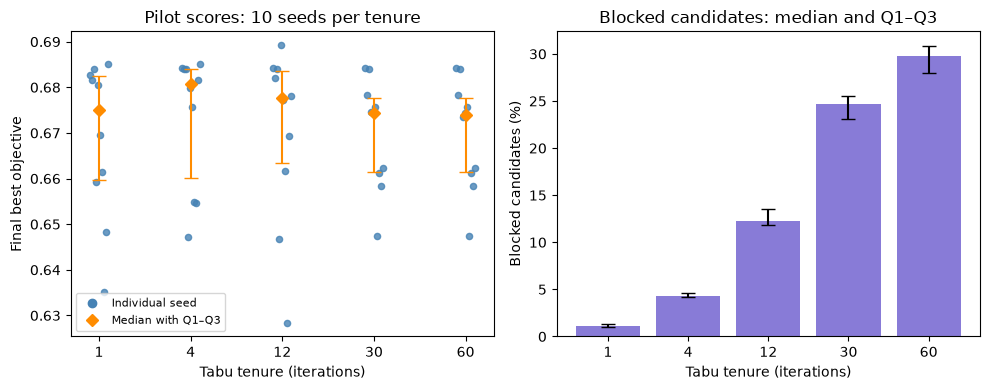

In [34]:
performance_rows = [
    "| Tenure | Median final objective | Q1–Q3 | Connected retained bests |",
    "|---:|---:|---:|---:|",
]
behavior_rows = [
    "| Tenure | Runs revisiting a state | Median revisits | Median blocked candidates | Aspiration moves, total | Forced overrides, total |",
    "|---:|---:|---:|---:|---:|---:|",
]
for tenure in TABU_TENURE_CANDIDATES:
    q1, q3 = np.percentile(tenure_scores[tenure], [25, 75])
    rows = tenure_diagnostics[tenure]
    performance_rows.append(
        f"| {tenure} | {tenure_medians[tenure]:.6f} | {q1:.6f}–{q3:.6f} "
        f"| {sum(r['feasible'] for r in rows)}/{len(rows)} |"
    )
    behavior_rows.append(
        f"| {tenure} | {sum(r['revisits'] > 0 for r in rows)}/{len(rows)} "
        f"| {np.median([r['revisits'] for r in rows]):.1f} "
        f"| {np.median([r['blocked_fraction'] for r in rows]):.1%} "
        f"| {sum(r['aspiration_moves'] for r in rows)} "
        f"| {sum(r['forced_overrides'] for r in rows)} |"
    )
display({"text/markdown": "\n".join(performance_rows)}, raw=True)
display({"text/markdown": "\n".join(behavior_rows)}, raw=True)
print("A revisit means returning to exactly the same activation vector, not merely matching an objective value.")
print("Blocked candidates exclude those admitted by aspiration. Counts come from 50 moves per pilot run.")
print(f"Immediate reversals across all pilot runs: {sum(r['immediate_reversals'] for rows in tenure_diagnostics.values() for r in rows)}.")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
x = np.arange(len(TABU_TENURE_CANDIDATES))
for j, tenure in enumerate(TABU_TENURE_CANDIDATES):
    scores = tenure_scores[tenure]
    q1, median, q3 = np.percentile(scores, [25, 50, 75])
    offsets = np.linspace(-0.10, 0.10, len(scores))
    axes[0].scatter(j + offsets, scores, s=20, color="steelblue", alpha=0.8)
    axes[0].errorbar(j, median, yerr=[[median - q1], [q3 - median]],
                     fmt="D", color="darkorange", capsize=5)
blocked_percent = np.array([
    [r["blocked_fraction"] * 100 for r in tenure_diagnostics[t]]
    for t in TABU_TENURE_CANDIDATES
])
q1, medians, q3 = np.percentile(blocked_percent, [25, 50, 75], axis=1)
axes[1].bar(x, medians, color="slateblue", alpha=0.8)
axes[1].errorbar(x, medians, yerr=[medians - q1, q3 - medians],
                 fmt="none", color="black", capsize=5)
for ax in axes:
    ax.set_xticks(x, [str(t) for t in TABU_TENURE_CANDIDATES])
    ax.set_xlabel("Tabu tenure (iterations)")
axes[0].set(title="Pilot scores: 10 seeds per tenure", ylabel="Final best objective")
axes[0].plot([], [], "o", color="steelblue", label="Individual seed")
axes[0].plot([], [], "D", color="darkorange", label="Median with Q1–Q3")
axes[0].legend(fontsize=8)
axes[1].set(title="Blocked candidates: median and Q1–Q3", ylabel="Blocked candidates (%)")
axes[1].set_ylim(bottom=0)
fig.tight_layout()
plt.show()


### Interpretation and selected configuration

Tenure 4 is selected because it had the largest observed pilot median, 0.680684. The initial placeholder of 12 is therefore replaced by 4 in `TABU_PARAMS`; `TABU_INITIAL_PARAMS` remains as the record of the starting design. This is a practical choice from five candidates on ten tuning seeds, not evidence that 4 is universally optimal. The score distributions overlap, and a longer run or other tuning seeds could change the selection.

The short-memory failure did appear in a limited form: tenure 1 revisited previously seen activation vectors in 4/10 runs, with 13 revisits in total. There were no immediate reversals, so these were returns through multiple moves rather than simply undoing the previous flip. This demonstrates recurrence during these trajectories, not permanent cycling or proof that recurrence caused the lower median. With a sampled list, reversal opportunities also depend on which indices are drawn. No revisits were observed at the other durations during the 50 pilot moves; this does not establish their absence at the full budget.

Longer memory restricted more candidates. The median blocked fraction rose from 4.3% at tenure 4 to 29.8% at tenure 60, while the latter's objective median was lower. This is consistent with an overly restrictive memory excluding useful alternatives. The pilot did not deadlock: no forced overrides occurred at any duration. Aspiration still admitted some improving moves despite their bans. All retained best deployments were connected, 10/10 for each duration.

The candidate list remained fixed at 20 throughout this tenure pilot. M0's correlation of approximately 0.935 motivated testing local search, but was measured using a mixed-layer walk and does not determine this discrete neighborhood's best list size. Its role is motivation, not proof of the candidate-list choice. The following separate pilot tunes list size while keeping tenure 4. Its protocol records that the original final-seed cohort had already been evaluated before the subsequent candidate-list pilot.



In [35]:
M1_EVALUATION_ACCOUNTING = {
    **M1_IMPLEMENTATION_ACCOUNTING,
    "tabu_tenure_tuning": TABU_TUNING_EVALUATIONS,
}
print(f"Selected configuration for the future 30-seed run: {TABU_PARAMS}")
for name, count in M1_EVALUATION_ACCOUNTING.items():
    print(f"{name:36} {count:>9,}")
print(f"{'M1 sensor evaluations so far':36} {sum(M1_EVALUATION_ACCOUNTING.values()):>9,}")
print(f"Synthetic checks, separate from sensor evaluations: {TABU_SYNTHETIC_EVALUATIONS} objective calls.")
print("Final tabu runs, tabu-versus-SA statistics and PSO remain pending.")


Selected configuration for the future 30-seed run: {'tenure': 4, 'candidate_size': 20, 'nominal_power': 20.0, 'active_fraction': 0.3}
tabu_illustrated_trace                     121
tabu_implementation_checks                 253
tabu_tenure_tuning                      50,000
M1 sensor evaluations so far            50,374
Synthetic checks, separate from sensor evaluations: 64 objective calls.
Final tabu runs, tabu-versus-SA statistics and PSO remain pending.


### Candidate-list selection protocol

After selecting tenure 4 at list size 20, a second pilot compares list sizes 10, 20, 40 and 80 while keeping that tenure, nominal powers and initializer fixed. Each size receives ten new seeds, 300–309, and 5,000 evaluations per run, matching the final evaluation budget. These seeds are disjoint from the final seeds, tenure-tuning seeds and M0 nominal-power seeds. For each seed, the initial deployment is identical across list sizes. The sampled candidate lists differ because their sizes differ; they are not claimed to be matched element by element.

The selection rule is the highest median final objective, with an exact tie resolved in favor of the smaller list. It is fixed before this pilot's results are inspected. The pilot costs 4 × 10 × 5,000 = 200,000 evaluations. With one evaluation reserved for initialization, list sizes 10, 20, 40 and 80 permit 500, 250, 125 and 63 moves respectively, including a final partial list. These configurations compare neighborhood breadth against the number of moves under the same budget. Selection is conditional on tenure 4; this is a sequential adjustment, not a joint search over every tenure–list combination.

The candidate-list pilot was conducted after the final tenure-4/list-20 runs, using separate seeds 300–309. It retained list size 20, so the existing 30 runs were reused and counted once.


In [36]:
TABU_LIST_CANDIDATES = (10, 20, 40, 80)
TABU_LIST_TUNING_SEEDS = tuple(range(300, 310))
TABU_LIST_TUNING_BUDGET = BUDGET
assert set(TABU_LIST_TUNING_SEEDS).isdisjoint(SEEDS)
assert set(TABU_LIST_TUNING_SEEDS).isdisjoint(TABU_TUNING_SEEDS)
assert set(TABU_LIST_TUNING_SEEDS).isdisjoint(TUNING_SEEDS)
assert len(TABU_LIST_TUNING_SEEDS) == 10
list_scores, list_medians, list_diagnostics, list_records = {}, {}, {}, {}
list_reference_starts = {}

for size in TABU_LIST_CANDIDATES:
    records, scores, diagnostics = [], [], []
    params = {**TABU_PARAMS, "candidate_size": size}
    for seed in TABU_LIST_TUNING_SEEDS:
        problem = SensorPlacementProblem(instance, budget=TABU_LIST_TUNING_BUDGET, seed=seed)
        result = tabu_search(problem, seed, **params, return_details=True)
        assert problem.evaluations_used == result["evaluations_used"] == TABU_LIST_TUNING_BUDGET
        assert result["score"] == problem.record.best
        assert len(result["candidates"]) == TABU_LIST_TUNING_BUDGET - 1
        assert np.array_equal(result["power"], np.minimum(NOMINAL_POWER, instance.power_cap))
        if seed not in list_reference_starts:
            list_reference_starts[seed] = result["initial_active"].copy()
        else:
            assert np.array_equal(result["initial_active"], list_reference_starts[seed])
        steps = result["iterations"]
        assert len(steps) == (TABU_LIST_TUNING_BUDGET - 1 + size - 1) // size
        diagnostics.append({
            "seed": seed, "moves": len(steps), "feasible": result["result"].feasible,
            "revisits": result["revisits"],
            "blocked_fraction": sum(r["blocked_count"] for r in steps) / len(result["candidates"]),
            "aspiration_moves": result["aspiration_moves"],
            "forced_overrides": result["forced_overrides"],
        })
        records.append(problem.record)
        scores.append(result["score"])
    list_scores[size] = np.array(scores)
    list_medians[size] = float(np.median(scores))
    list_diagnostics[size], list_records[size] = diagnostics, records
    save_runset(
        f"results/m1_list_{size}.npz",
        RunSet(algorithm="tabu_candidate_list_pilot", student_id=STUDENT_ID,
               params={**params, "salt": SALT, "purpose": "candidate-list tuning only",
                       "selection_rule": "highest median; smaller list breaks an exact tie"},
               records=records),
    )
    print(f"List {size:2}: median={list_medians[size]:.6f}; "
          f"moves/run={diagnostics[0]['moves']}; "
          f"connected={sum(r['feasible'] for r in diagnostics)}/{len(diagnostics)}", flush=True)

SELECTED_TABU_LIST_SIZE = max(TABU_LIST_CANDIDATES, key=lambda size: (list_medians[size], -size))
TABU_PARAMS = {**TABU_PARAMS, "candidate_size": SELECTED_TABU_LIST_SIZE}
TABU_LIST_TUNING_EVALUATIONS = sum(r.evaluations_used for records in list_records.values() for r in records)
assert TABU_LIST_TUNING_EVALUATIONS == len(TABU_LIST_CANDIDATES) * len(TABU_LIST_TUNING_SEEDS) * TABU_LIST_TUNING_BUDGET
assert TABU_PARAMS["tenure"] == SELECTED_TABU_TENURE
print(f"Selected candidate-list size: {SELECTED_TABU_LIST_SIZE}; tenure remains {SELECTED_TABU_TENURE}.")
print(f"Configuration for the final experiment: {TABU_PARAMS}")
print(f"Separate candidate-list tuning evaluations: {TABU_LIST_TUNING_EVALUATIONS:,}.")
print("Selection uses only seeds 300–309; the earlier final-run scores are not part of these medians.")


List 10: median=0.682839; moves/run=500; connected=10/10
List 20: median=0.687371; moves/run=250; connected=10/10
List 40: median=0.685692; moves/run=125; connected=10/10
List 80: median=0.684298; moves/run=63; connected=10/10
Selected candidate-list size: 20; tenure remains 4.
Configuration for the final experiment: {'tenure': 4, 'candidate_size': 20, 'nominal_power': 20.0, 'active_fraction': 0.3}
Separate candidate-list tuning evaluations: 200,000.
Selection uses only seeds 300–309; the earlier final-run scores are not part of these medians.


### Candidate-list pilot results

The score table reports ten seed outcomes per size under equal evaluation budgets. The behavior table normalizes revisits by the number of moves, because larger lists permit fewer moves. Revisited states mean exact activation-vector returns. The plot shows individual final scores with median and Q1–Q3, followed by median convergence over evaluations 1,000–5,000. This is a tuning comparison; it does not replace the final 30-seed algorithm study.


| List size | Moves per run | Median objective | Q1–Q3 |
|---:|---:|---:|---:|
| 10 | 500 | 0.682839 | 0.679034–0.685917 |
| 20 | 250 | 0.687371 | 0.685779–0.688052 |
| 40 | 125 | 0.685692 | 0.684605–0.688548 |
| 80 | 63 | 0.684298 | 0.682163–0.686969 |

| List size | Runs with revisits | Revisited moves, pooled | Median blocked candidates | Aspiration moves, total |
|---:|---:|---:|---:|---:|
| 10 | 0/10 | 0/5,000 (0.00%) | 5.0% | 33 |
| 20 | 3/10 | 6/2,500 (0.24%) | 4.9% | 29 |
| 40 | 5/10 | 22/1,250 (1.76%) | 4.8% | 27 |
| 80 | 9/10 | 124/630 (19.68%) | 4.7% | 13 |

Connected retained bests: list 10: 10/10; list 20: 10/10; list 40: 10/10; list 80: 10/10.
Forced overrides across this pilot: 0.
Revisit percentages use the number of moves, which differs between list sizes despite equal evaluation budgets.


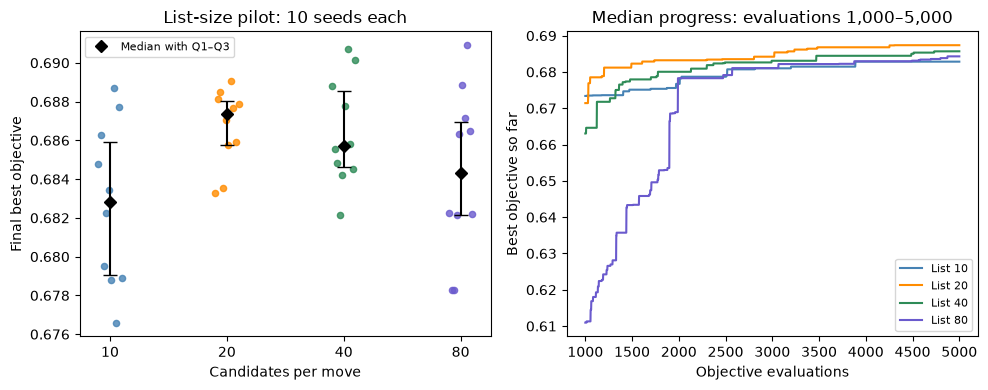

In [37]:
rows = [
    "| List size | Moves per run | Median objective | Q1–Q3 |",
    "|---:|---:|---:|---:|",
]
behavior = [
    "| List size | Runs with revisits | Revisited moves, pooled | Median blocked candidates | Aspiration moves, total |",
    "|---:|---:|---:|---:|---:|",
]
for size in TABU_LIST_CANDIDATES:
    q1, q3 = np.percentile(list_scores[size], [25, 75])
    diagnostics = list_diagnostics[size]
    repeats = sum(r["revisits"] for r in diagnostics)
    moves = sum(r["moves"] for r in diagnostics)
    rows.append(f"| {size} | {diagnostics[0]['moves']} | {list_medians[size]:.6f} | {q1:.6f}–{q3:.6f} |")
    behavior.append(
        f"| {size} | {sum(r['revisits'] > 0 for r in diagnostics)}/{len(diagnostics)} "
        f"| {repeats}/{moves:,} ({repeats / moves:.2%}) "
        f"| {np.median([r['blocked_fraction'] for r in diagnostics]):.1%} "
        f"| {sum(r['aspiration_moves'] for r in diagnostics)} |"
    )
display({"text/markdown": "\n".join(rows)}, raw=True)
display({"text/markdown": "\n".join(behavior)}, raw=True)
connected_counts = "; ".join(
    f"list {size}: {sum(r['feasible'] for r in list_diagnostics[size])}/{len(list_diagnostics[size])}"
    for size in TABU_LIST_CANDIDATES
)
print(f"Connected retained bests: {connected_counts}.")
print(f"Forced overrides across this pilot: {sum(r['forced_overrides'] for rows in list_diagnostics.values() for r in rows)}.")
print("Revisit percentages use the number of moves, which differs between list sizes despite equal evaluation budgets.")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
evaluation_axis = np.arange(1, TABU_LIST_TUNING_BUDGET + 1)
tail = evaluation_axis >= 1_000
colors = ("steelblue", "darkorange", "seagreen", "slateblue")
for j, (size, color) in enumerate(zip(TABU_LIST_CANDIDATES, colors)):
    scores = list_scores[size]
    q1, med, q3 = np.percentile(scores, [25, 50, 75])
    axes[0].scatter(j + np.linspace(-0.10, 0.10, len(scores)), scores, s=20, color=color, alpha=0.8)
    axes[0].errorbar(j, med, yerr=[[med - q1], [q3 - med]], fmt="D", color="black", capsize=5)
    traces = np.array([r.best_so_far for r in list_records[size]])
    axes[1].plot(evaluation_axis[tail], np.median(traces, axis=0)[tail],
                 color=color, label=f"List {size}")
axes[0].set_xticks(range(len(TABU_LIST_CANDIDATES)), [str(s) for s in TABU_LIST_CANDIDATES])
axes[0].set(title="List-size pilot: 10 seeds each", xlabel="Candidates per move", ylabel="Final best objective")
axes[0].plot([], [], "D", color="black", label="Median with Q1–Q3")
axes[0].legend(fontsize=8)
axes[1].set(title="Median progress: evaluations 1,000–5,000",
            xlabel="Objective evaluations", ylabel="Best objective so far")
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()


### Selected candidate-list size

List size 20 had the largest pilot median, 0.687371, compared with 0.682839 for 10, 0.685692 for 40 and 0.684298 for 80. It remains the selected size, now supported by this pilot rather than only by the initial design argument. Its median exceeds the alternatives in this sample, but overlapping score ranges and ten tuning seeds do not establish a universally best size.

The smallest list allowed 500 moves, yet did not obtain the largest median. The full neighborhood examined all 80 alternatives per complete move, but allowed only 63 moves. This confirms that neither more moves nor more alternatives examined at each step alone guarantees a better result. The list-20 choice balances these effects within this tested configuration; it is not deduced from M0's correlation value.

Recurrence also depended on the list. Exact states were revisited in 0/10 runs with size 10, 3/10 with 20, 5/10 with 40 and 9/10 with 80. The pooled revisit rates were 0%, 0.24%, 1.76% and 19.68% of moves. Sampling can vary the alternatives available to the trajectory, whereas the full neighborhood offers the same complete set at each visited state. These observations are consistent with sampling providing diversification, but do not prove that recurrence caused the score ordering. Size 10 had no observed revisits and still had a lower median than 20. All retained bests were connected, and none of these runs used the forced override.

The final configuration remains tenure 4 and list size 20, with M0 nominal power and the shared initializer. It exactly matches the previously computed 30-seed cohort. Reusing that cohort adds no objective evaluations and does not count it twice. A fresh run of the notebook executes these tuning cells before the final experiment. Any future claim about the value of memory must still distinguish this fixed-power search from joint SA, and any claim about optimal parameters remains limited to the sequential pilots tested here.


### Final 30-seed tabu experiment

The configuration retained by both sequential pilots is now fixed: tenure 4, candidate list 20, M0 `NOMINAL_POWER` and the shared 30%-activation initializer. It is evaluated on final seeds 0–29, with exactly 5,000 objective evaluations per run. Neither pilot computes its medians from these seeds. These same runs had already been computed before the additional list-size pilot; they are reused because that pilot retained the identical configuration. No final score enters the list-size selection rule, and no second set of 150,000 evaluations is charged for this reuse.

Each run evaluates its initial deployment, then 249 full candidate lists of 20 and one final list of 19, making 250 moves. Disconnected proposals and candidates rejected by memory still consume evaluations. The best retained activation vector and its fixed powers are kept for the later PSO stage. Run traces are saved to `results/m1_tabu.npz`; the retained subsets are also saved locally in `results/m1_tabu_solutions.npz`. These files are generated by the notebook and are not additional submission deliverables.

The code reports the final score distribution and search diagnostics. It also reads each final run's best-so-far values at evaluations 1,000 and 5,000. This within-run comparison measures progress along the same trajectories. Comparing the pilot median directly with the final median would mix the budget change with a change of seeds, so it is not used to quantify the benefit of continuing longer. Statistical comparison against M0 SA comes in the next step.



In [38]:
from time import perf_counter
from tc6035.runlog import RunSet, save_runset, load_runset

assert TABU_PARAMS["tenure"] == SELECTED_TABU_TENURE
assert TABU_PARAMS["nominal_power"] == NOMINAL_POWER
assert len(SEEDS) == 30 and set(SEEDS).isdisjoint(TABU_TUNING_SEEDS)
tabu_results, tabu_records, tabu_scores, tabu_diagnostics, tabu_run_seconds = [], [], [], [], []
print(f"Frozen tabu configuration: {TABU_PARAMS}")
print(f"Final seeds: {SEEDS}; budget per run: {BUDGET:,}")

for i, seed in enumerate(SEEDS):
    started = perf_counter()
    problem = SensorPlacementProblem(instance, budget=BUDGET, seed=seed)
    result = tabu_search(problem, seed, **TABU_PARAMS, return_details=True)
    tabu_run_seconds.append(perf_counter() - started)
    assert problem.evaluations_used == result["evaluations_used"] == BUDGET
    assert result["score"] == problem.record.best == max(problem.record.values)
    assert len(result["candidates"]) == BUDGET - 1
    assert np.array_equal(result["power"], np.minimum(NOMINAL_POWER, instance.power_cap))
    assert np.all((result["power"] >= instance.spec.power_min)
                  & (result["power"] <= instance.power_cap))
    expected_start = np.random.default_rng(np.random.SeedSequence([seed, 19_000])).random(instance.n_candidates) < TABU_PARAMS["active_fraction"]
    assert np.array_equal(result["initial_active"], expected_start)
    expected_moves = (BUDGET - 1 + TABU_PARAMS["candidate_size"] - 1) // TABU_PARAMS["candidate_size"]
    assert len(result["iterations"]) == expected_moves
    steps = result["iterations"]
    tabu_diagnostics.append({
        "seed": seed, "iterations": len(steps), "feasible": result["result"].feasible,
        "active_count": result["result"].n_active,
        "revisits": result["revisits"],
        "immediate_reversals": sum(r["immediate_reversal"] for r in steps),
        "blocked_fraction": sum(r["blocked_count"] for r in steps) / len(result["candidates"]),
        "aspiration_moves": result["aspiration_moves"], "forced_overrides": result["forced_overrides"],
    })
    tabu_results.append(result)
    tabu_records.append(problem.record)
    tabu_scores.append(result["score"])
    if (i + 1) % 5 == 0:
        print(f"Completed {i + 1}/{len(SEEDS)} final runs.", flush=True)

tabu_scores = np.array(tabu_scores)
tabu_traces = np.array([r.best_so_far for r in tabu_records])
TABU_MEDIAN = float(np.median(tabu_scores))
TABU_Q1, TABU_Q3 = np.percentile(tabu_scores, [25, 75])
TABU_IQR = float(TABU_Q3 - TABU_Q1)
TABU_FINAL_CONNECTED = sum(r["feasible"] for r in tabu_diagnostics)
TABU_FINAL_EVALUATIONS = sum(r.evaluations_used for r in tabu_records)
assert TABU_FINAL_EVALUATIONS == len(SEEDS) * BUDGET
assert [r.seed for r in tabu_records] == list(SEEDS)
save_runset(
    "results/m1_tabu.npz",
    RunSet(algorithm="tabu_search", student_id=STUDENT_ID,
           params={**TABU_PARAMS, "salt": SALT, "scope": "activation only; fixed nominal power",
                   "selected_using": "seeds 200–209, 1,000 evaluations per tenure pilot",
                   "candidate_list_selection": "seeds 300–309, 5,000 evaluations per list-size pilot"},
           records=tabu_records),
)
loaded_tabu = load_runset("results/m1_tabu.npz")
assert loaded_tabu.seeds == list(SEEDS)
assert np.array_equal(loaded_tabu.best_values, tabu_scores)
assert all(np.array_equal(saved, record.values)
           for saved, record in zip(loaded_tabu.values, tabu_records))

# Retain one best subset per seed for the later fixed-subset PSO runs.
np.savez_compressed(
    "results/m1_tabu_solutions.npz", seeds=np.array(SEEDS),
    active=np.array([r["active"] for r in tabu_results]),
    power=np.array([r["power"] for r in tabu_results]), score=tabu_scores,
)
TABU_AT_1000 = float(np.median(tabu_traces[:, 999]))
TABU_IMPROVED_AFTER_1000 = int(np.sum(tabu_scores > tabu_traces[:, 999]))
TABU_MEDIAN_LATE_GAIN = float(np.median(tabu_scores - tabu_traces[:, 999]))
TABU_REP_INDEX = int(np.argmin(np.abs(tabu_scores - TABU_MEDIAN)))
tabu_rep = tabu_results[TABU_REP_INDEX]

print(f"Tabu median={TABU_MEDIAN:.6f}; Q1–Q3=[{TABU_Q1:.6f}, {TABU_Q3:.6f}]; IQR={TABU_IQR:.6f}")
print(f"Connected retained bests: {TABU_FINAL_CONNECTED}/{len(SEEDS)}")
print(f"Exact final-run evaluations: {TABU_FINAL_EVALUATIONS:,}")
print(f"Within these same final traces: median at 1,000={TABU_AT_1000:.6f}; at 5,000={TABU_MEDIAN:.6f}.")
print(f"Runs improving after evaluation 1,000: {TABU_IMPROVED_AFTER_1000}/{len(SEEDS)}; "
      f"median paired later gain={TABU_MEDIAN_LATE_GAIN:+.6f}.")
print(f"Representative seed: {SEEDS[TABU_REP_INDEX]}; score={tabu_rep['score']:.6f}; "
      f"active sensors={tabu_rep['result'].n_active}.")


Frozen tabu configuration: {'tenure': 4, 'candidate_size': 20, 'nominal_power': 20.0, 'active_fraction': 0.3}
Final seeds: (0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29); budget per run: 5,000
Completed 5/30 final runs.
Completed 10/30 final runs.
Completed 15/30 final runs.
Completed 20/30 final runs.
Completed 25/30 final runs.
Completed 30/30 final runs.
Tabu median=0.685529; Q1–Q3=[0.683647, 0.687036]; IQR=0.003390
Connected retained bests: 30/30
Exact final-run evaluations: 150,000
Within these same final traces: median at 1,000=0.674443; at 5,000=0.685529.
Runs improving after evaluation 1,000: 30/30; median paired later gain=+0.010610.
Representative seed: 0; score=0.685528; active sensors=15.


### Final tabu results and diagnostics

The full and enlarged convergence views summarize the same 30 best-so-far traces. The enlarged view starts at evaluation 1,000 to show later gains. Their bands show Q1–Q3 at each evaluation count. The seed scatter describes variation between final outcomes, not improvement from one seed to the next. The last panel counts returns to previously visited activation vectors in each run; a zero does not establish that recurrence is impossible beyond this budget.


| Quantity | Final tabu experiment |
|---|---:|
| Seeds | 0–29 (30 runs) |
| Evaluations per run | 5,000 |
| Tenure / candidate list | 4 / 20 |
| Median objective | 0.685529 |
| Q1–Q3 | 0.683647–0.687036 |
| IQR width | 0.003390 |
| Connected retained bests | 30/30 |
| Runs with revisited states | 2/30 |
| Median revisits per run | 0.0 |
| Median blocked candidates | 4.9% |
| Aspiration moves, total | 95 |
| Forced overrides, total | 0 |


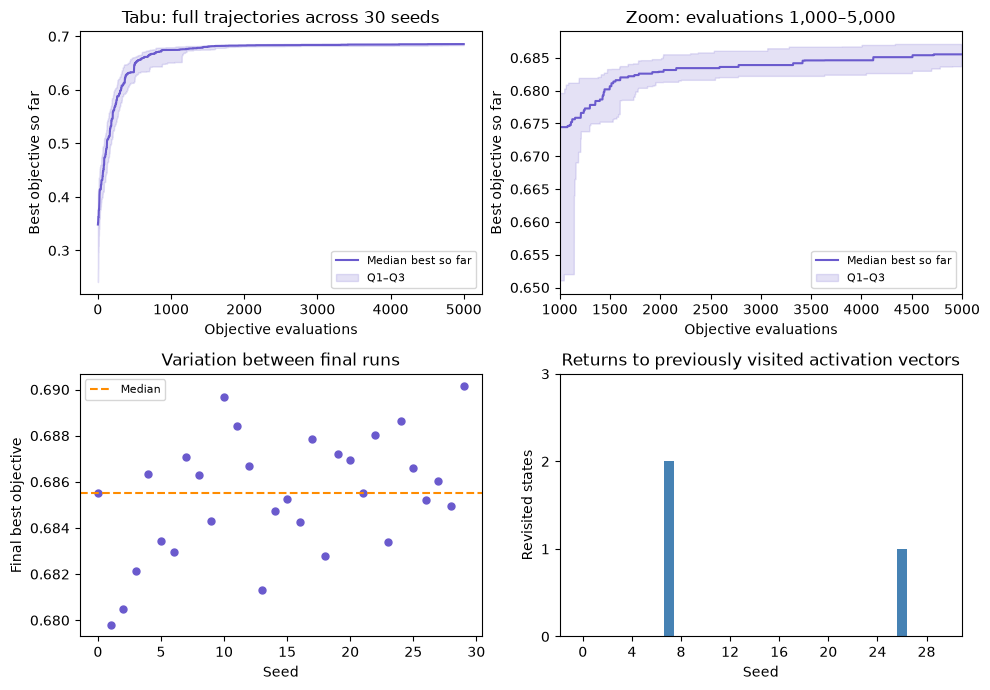

Representative seed 0: C=0.841784, E=0.236377, I=0.057720, components=1, active=15.
Each retained subset and its fixed powers are available in tabu_results for the later PSO stage.


In [39]:
tabu_summary_table = (
    "| Quantity | Final tabu experiment |\n|---|---:|\n"
    f"| Seeds | 0–29 ({len(SEEDS)} runs) |\n"
    f"| Evaluations per run | {BUDGET:,} |\n"
    f"| Tenure / candidate list | {TABU_PARAMS['tenure']} / {TABU_PARAMS['candidate_size']} |\n"
    f"| Median objective | {TABU_MEDIAN:.6f} |\n"
    f"| Q1–Q3 | {TABU_Q1:.6f}–{TABU_Q3:.6f} |\n"
    f"| IQR width | {TABU_IQR:.6f} |\n"
    f"| Connected retained bests | {TABU_FINAL_CONNECTED}/{len(SEEDS)} |\n"
    f"| Runs with revisited states | {sum(r['revisits'] > 0 for r in tabu_diagnostics)}/{len(SEEDS)} |\n"
    f"| Median revisits per run | {np.median([r['revisits'] for r in tabu_diagnostics]):.1f} |\n"
    f"| Median blocked candidates | {np.median([r['blocked_fraction'] for r in tabu_diagnostics]):.1%} |\n"
    f"| Aspiration moves, total | {sum(r['aspiration_moves'] for r in tabu_diagnostics)} |\n"
    f"| Forced overrides, total | {sum(r['forced_overrides'] for r in tabu_diagnostics)} |\n"
)
display({"text/markdown": tabu_summary_table}, raw=True)

q1, median, q3 = np.percentile(tabu_traces, [25, 50, 75], axis=0)
axis = np.arange(1, BUDGET + 1)
tail = axis >= 1_000
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax in axes[0]:
    ax.plot(axis, median, color="slateblue", label="Median best so far")
    ax.fill_between(axis, q1, q3, color="slateblue", alpha=0.18, label="Q1–Q3")
    ax.set(xlabel="Objective evaluations", ylabel="Best objective so far")
    ax.legend(fontsize=8)
axes[0, 0].set_title("Tabu: full trajectories across 30 seeds")
low, high = float(q1[tail].min()), float(q3[tail].max())
pad = max(0.002, 0.05 * (high - low))
axes[0, 1].set(title="Zoom: evaluations 1,000–5,000", xlim=(1_000, BUDGET),
                ylim=(low - pad, high + pad))
axes[1, 0].scatter(SEEDS, tabu_scores, color="slateblue", s=25)
axes[1, 0].axhline(TABU_MEDIAN, color="darkorange", ls="--", label="Median")
axes[1, 0].set(title="Variation between final runs", xlabel="Seed", ylabel="Final best objective")
axes[1, 0].legend(fontsize=8)
revisits = [r["revisits"] for r in tabu_diagnostics]
axes[1, 1].bar(SEEDS, revisits, color="steelblue")
axes[1, 1].set(title="Returns to previously visited activation vectors", xlabel="Seed", ylabel="Revisited states")
axes[1, 1].set_ylim(0, max(1, max(revisits) + 1))
from matplotlib.ticker import MaxNLocator
axes[1, 1].yaxis.set_major_locator(MaxNLocator(integer=True))
axes[1, 1].xaxis.set_major_locator(MaxNLocator(integer=True))
fig.tight_layout()
plt.show()

rep = tabu_rep["result"]
print(f"Representative seed {SEEDS[TABU_REP_INDEX]}: C={rep.coverage:.6f}, E={rep.energy:.6f}, "
      f"I={rep.interference:.6f}, components={rep.n_components}, active={rep.n_active}.")
print("Each retained subset and its fixed powers are available in tabu_results for the later PSO stage.")


### Interpretation of the final tabu runs

With the selected tenure of 4 and list size 20, the 30 final runs reached median objective 0.685529, Q1–Q3 [0.683647, 0.687036] and IQR width 0.003390. All 30 retained best deployments were connected. Each run used exactly 5,000 evaluations; the final experiment therefore cost 150,000 evaluations, separate from the 50,000 used for tenure selection and 200,000 used for candidate-list selection. The identical earlier final cohort is reused once.

All 30 runs improved their retained objective after evaluation 1,000. Within these same trajectories, the median best-so-far objective rose from 0.674443 at 1,000 evaluations to 0.685529 at 5,000. The median of the 30 within-run gains was +0.010610; this is computed from paired differences, rather than subtracting the two medians. Continuing the search produced further gains under this fixed configuration and budget, without establishing what further evaluations would achieve.

Memory did not eliminate recurrence: 2/30 runs returned to previous activation vectors, with 3 revisits in total. The shorter pilot had observed none at tenure 4, illustrating why that result could not be treated as a guarantee for longer trajectories. There were no immediate reversals. The median blocked-candidate fraction was 4.9%, 95 selected moves used aspiration and 0 needed the forced override. These are diagnostics of the memory's operation; blocking either more or fewer candidates does not by itself guarantee a better objective.

The illustrated representative is seed 0, selected because its final score is closest to the final median, rather than because it is the best run. Its retained deployment activates 15 sensors at the fixed, site-clipped nominal powers. Its subset can now be passed to PSO along with those from the other seeds. These results still concern activation search at fixed powers. The upcoming comparison with M0 SA must account for SA searching both activation and power; this experiment alone does not isolate the value of memory.


In [40]:
M1_EVALUATION_ACCOUNTING = {
    **M1_IMPLEMENTATION_ACCOUNTING,
    "tabu_tenure_tuning": TABU_TUNING_EVALUATIONS,
    "tabu_candidate_list_tuning": TABU_LIST_TUNING_EVALUATIONS,
    "final_tabu_runs": TABU_FINAL_EVALUATIONS,
}
for name, count in M1_EVALUATION_ACCOUNTING.items():
    print(f"{name:36} {count:>9,}")
print(f"{'M1 sensor evaluations so far':36} {sum(M1_EVALUATION_ACCOUNTING.values()):>9,}")
print(f"Synthetic checks, separate: {TABU_SYNTHETIC_EVALUATIONS} objective calls.")
print("This subtotal covers tabu; PSO costs are added in its own section.")
print("The identical existing 30-seed cohort is reused and counted once; no additional final-run evaluations.")


tabu_illustrated_trace                     121
tabu_implementation_checks                 253
tabu_tenure_tuning                      50,000
tabu_candidate_list_tuning             200,000
final_tabu_runs                        150,000
M1 sensor evaluations so far           400,374
Synthetic checks, separate: 64 objective calls.
This subtotal covers tabu; PSO costs are added in its own section.
The identical existing 30-seed cohort is reused and counted once; no additional final-run evaluations.


## Tabu versus M0 simulated annealing

This comparison answers M1 Question 4 using the existing full-precision logs `results/m1_tabu.npz` and `results/m0_annealing.npz`. Both methods use this same instance, seeds 0–29, the shared initial deployment and 5,000 evaluations per run. The code checks paired seed order, instance, salt, evaluation counts, initial objectives and recorded best values before computing any statistics. No search is rerun and no objective evaluations are added.

The response is the final best objective, where larger is better. Every paired difference is defined as **tabu minus SA**. Report the median and Q1–Q3 for each method, the median paired difference, wins/ties/losses, a two-sided paired Wilcoxon signed-rank test and the paired rank-biserial effect. The test and effect use differences rounded to 12 decimal places, as in M0, to avoid ranking numerical noise as meaningful differences; descriptive statistics retain full precision. The signed-rank test assesses a shift in the paired differences under its symmetry assumption, rather than testing the two displayed medians directly. This is one planned M1 comparison, reported at alpha 0.05 without a multiple-comparison correction; pilot rankings are selection evidence, not additional significance tests.

The comparison concerns two complete configurations. Tabu changes activations at fixed nominal powers, whereas SA can change both activations and powers. Tabu evaluates up to 20 alternative flips per move; joint SA evaluates one proposal per move. Equal objective-evaluation budgets account for that different cost. The seed pairing does not imply matching random proposals after initialization. The result cannot isolate the causal contribution of tabu memory.


In [41]:
from scipy.stats import wilcoxon
from tc6035.runlog import load_runset

# Load saved full-precision trajectories; no new objective calls are needed.
comparison_sa = load_runset("results/m0_annealing.npz")
comparison_tabu = load_runset("results/m1_tabu.npz")
assert comparison_sa.seeds == comparison_tabu.seeds == list(SEEDS)
assert comparison_sa.meta["student_id"] == comparison_tabu.meta["student_id"] == STUDENT_ID
assert comparison_sa.meta["params"]["salt"] == comparison_tabu.meta["params"]["salt"] == SALT
assert comparison_tabu.meta["params"]["tenure"] == TABU_PARAMS["tenure"]
assert comparison_tabu.meta["params"]["candidate_size"] == TABU_PARAMS["candidate_size"]
for runs in (comparison_sa, comparison_tabu):
    assert len(runs.values) == len(SEEDS) == 30
    for meta, values, best in zip(runs.meta["runs"], runs.values, runs.best_so_far):
        assert meta["instance_id"] == STUDENT_ID
        assert meta["budget"] == meta["evaluations_used"] == len(values) == BUDGET
        assert np.all(np.isfinite(values))
        assert np.array_equal(best, np.maximum.accumulate(values))
assert np.array_equal(comparison_sa.best_values, sa_scores)
assert np.array_equal(comparison_tabu.best_values, tabu_scores)
assert all(a[0] == b[0] for a, b in zip(comparison_sa.values, comparison_tabu.values))

tabu_sa_differences = comparison_tabu.best_values - comparison_sa.best_values
# Round differences only for rank tests, consistently with M0's tie handling.
tabu_sa_rank_differences = np.round(tabu_sa_differences, 12)
tabu_sa_test = (wilcoxon(tabu_sa_rank_differences, alternative="two-sided",
                         zero_method="wilcox", method="auto")
                if np.any(tabu_sa_rank_differences) else None)
W_stat = float(tabu_sa_test.statistic) if tabu_sa_test else 0.0
p_tabu_vs_sa = float(tabu_sa_test.pvalue) if tabu_sa_test else 1.0
tabu_sa_effect = paired_rank_biserial(comparison_tabu.best_values, comparison_sa.best_values)
tabu_sa_median_difference = float(np.median(tabu_sa_differences))
tabu_sa_wins = int(np.sum(tabu_sa_rank_differences > 0))
tabu_sa_ties = int(np.sum(tabu_sa_rank_differences == 0))
tabu_sa_losses = int(np.sum(tabu_sa_rank_differences < 0))
assert tabu_sa_wins + tabu_sa_ties + tabu_sa_losses == len(SEEDS)

comparison_table = "| Quantity | Tabu: fixed power | M0 SA: joint search |\n|---|---:|---:|\n"
comparison_table += f"| Final best objective, median | {np.median(comparison_tabu.best_values):.6f} | {np.median(comparison_sa.best_values):.6f} |\n"
tq1, tq3 = np.percentile(comparison_tabu.best_values, [25, 75])
sq1, sq3 = np.percentile(comparison_sa.best_values, [25, 75])
comparison_table += (
    f"| Q1–Q3 | {tq1:.6f}–{tq3:.6f} | {sq1:.6f}–{sq3:.6f} |\n"
    f"| IQR width | {tq3-tq1:.6f} | {sq3-sq1:.6f} |\n"
    f"| Evaluations per run | {BUDGET:,} | {BUDGET:,} |\n"
    f"| Runs | {len(SEEDS)} | {len(SEEDS)} |\n"
)
display({"text/markdown": comparison_table}, raw=True)
dq1, dq3 = np.percentile(tabu_sa_differences, [25, 75])
print("All differences below are tabu minus SA; a positive value favors tabu.")
print(f"Median paired difference: {tabu_sa_median_difference:+.6f}; Q1–Q3: [{dq1:+.6f}, {dq3:+.6f}].")
print(f"Tabu wins / ties / losses: {tabu_sa_wins} / {tabu_sa_ties} / {tabu_sa_losses}.")
print(f"Two-sided paired Wilcoxon: W={W_stat:.1f}; p_tabu_vs_sa={p_tabu_vs_sa:.9e}.")
print(f"Paired rank-biserial effect: {tabu_sa_effect:+.6f} (negative favors SA).")
print("Checks passed: paired seeds, instance, budgets, saved bests and identical starting objectives.")
print("Comparison uses existing runs; additional objective evaluations: 0.")


| Quantity | Tabu: fixed power | M0 SA: joint search |
|---|---:|---:|
| Final best objective, median | 0.685529 | 0.714655 |
| Q1–Q3 | 0.683647–0.687036 | 0.712220–0.717910 |
| IQR width | 0.003390 | 0.005690 |
| Evaluations per run | 5,000 | 5,000 |
| Runs | 30 | 30 |


All differences below are tabu minus SA; a positive value favors tabu.
Median paired difference: -0.029723; Q1–Q3: [-0.031813, -0.027731].
Tabu wins / ties / losses: 3 / 0 / 27.
Two-sided paired Wilcoxon: W=14.0; p_tabu_vs_sa=2.048909664e-07.
Paired rank-biserial effect: -0.939785 (negative favors SA).
Checks passed: paired seeds, instance, budgets, saved bests and identical starting objectives.
Comparison uses existing runs; additional objective evaluations: 0.


### Comparative trajectories and paired outcomes

The top panels show median best-so-far trajectories with Q1–Q3 across seeds, first over the full budget and then from evaluation 1,000. Shading describes run variability, not a confidence interval. The lower-left panel pairs final scores: points below the diagonal favor SA. The lower-right panel shows each seed's tabu-minus-SA difference and its median. All horizontal convergence axes count objective evaluations, not search iterations.


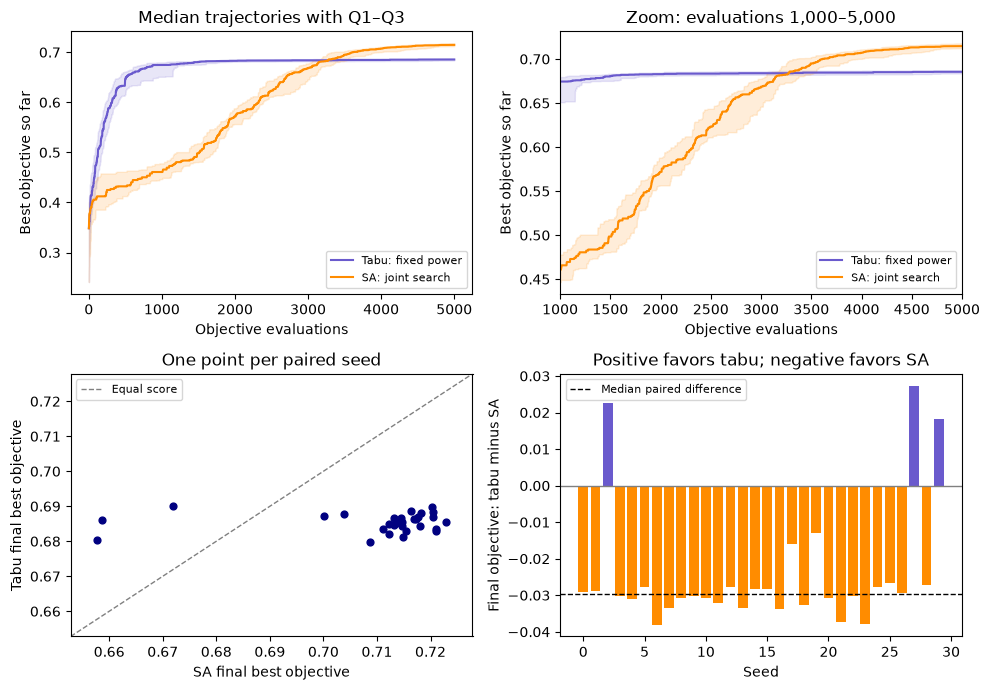

In [42]:
comparison_axis = np.arange(1, BUDGET + 1)
comparison_tail = comparison_axis >= 1_000
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
comparison_limits = []
for runs, label, color in ((comparison_tabu, "Tabu: fixed power", "slateblue"),
                            (comparison_sa, "SA: joint search", "darkorange")):
    q1, med, q3 = np.percentile(np.array(runs.best_so_far), [25, 50, 75], axis=0)
    for ax, mask in ((axes[0, 0], np.ones(BUDGET, dtype=bool)), (axes[0, 1], comparison_tail)):
        ax.plot(comparison_axis[mask], med[mask], color=color, label=label)
        ax.fill_between(comparison_axis[mask], q1[mask], q3[mask], color=color, alpha=0.15)
    comparison_limits.extend([q1[comparison_tail].min(), q3[comparison_tail].max()])
for ax in axes[0]:
    ax.set(xlabel="Objective evaluations", ylabel="Best objective so far")
    ax.legend(fontsize=8)
axes[0, 0].set_title("Median trajectories with Q1–Q3")
comparison_pad = max(0.002, 0.05 * np.ptp(comparison_limits))
axes[0, 1].set(title="Zoom: evaluations 1,000–5,000", xlim=(1_000, BUDGET),
                ylim=(min(comparison_limits)-comparison_pad, max(comparison_limits)+comparison_pad))
low = min(comparison_sa.best_values.min(), comparison_tabu.best_values.min()) - 0.005
high = max(comparison_sa.best_values.max(), comparison_tabu.best_values.max()) + 0.005
axes[1, 0].plot([low, high], [low, high], "--", color="gray", lw=1, label="Equal score")
axes[1, 0].scatter(comparison_sa.best_values, comparison_tabu.best_values, color="navy", s=24)
axes[1, 0].set(title="One point per paired seed", xlabel="SA final best objective",
                ylabel="Tabu final best objective", xlim=(low, high), ylim=(low, high))
axes[1, 0].legend(fontsize=8)
axes[1, 1].bar(SEEDS, tabu_sa_differences,
                color=np.where(tabu_sa_differences > 0, "slateblue", "darkorange"))
axes[1, 1].axhline(0, color="gray", lw=1)
axes[1, 1].axhline(tabu_sa_median_difference, color="black", ls="--", lw=1,
                    label="Median paired difference")
axes[1, 1].set(title="Positive favors tabu; negative favors SA", xlabel="Seed",
                ylabel="Final objective: tabu minus SA")
axes[1, 1].legend(fontsize=8)
fig.tight_layout()
plt.show()


### Interpretation of tabu versus SA

Joint SA had the higher final median: 0.714655 versus 0.685529 for fixed-power tabu. Their Q1–Q3 ranges were 0.712220–0.717910 and 0.683647–0.687036 respectively. Tabu won 3 paired seeds, tied 0 and lost 27. The median paired difference was −0.029723; this is the median of the 30 within-seed differences, rather than the difference between the two medians. The median convergence curves show tabu improving faster early in the budget and then flattening, while SA continues improving and overtakes it later. That ordering of median trajectories need not describe every individual seed.

The two-sided Wilcoxon result was W = 14 and `p_tabu_vs_sa` = 2.048910e−7. The paired rank-biserial effect was −0.939785: negative favors SA, and its magnitude indicates a strong imbalance of signed ranks toward SA. It is not a probability or a percentage improvement. These results support better final scores for this SA configuration across the tested seeds on this instance; they do not establish superiority on other instances.

The methods escape local restrictions differently. SA can accept worse proposals according to temperature, whereas tabu blocks recently changed indices and may choose a worse admissible neighbor while preserving its best solution. M0's high lag-1 random-walk correlation motivates examining nearby states, but does not guarantee that either mechanism will win. The tabu runs did use memory and aspiration, yet that alone cannot explain the observed score gap. As discussed in M0, sensor activations and transmit powers are coupled: the quality of a subset depends on its powers, and suitable powers depend on the selected subset. Holding powers fixed prevents tabu from adjusting both components together and can therefore affect its performance. This coupling is a possible contributor to the observed gap, although this comparison does not isolate its effect. Candidate-list breadth, move counts and tuning protocols also differ. To isolate memory, an additional controlled experiment would need to match the searched variables, initialization, neighborhood and evaluation budget while varying memory; it is not claimed here.

The comparison adds zero evaluations. The tabu configuration remains tenure 4 and list size 20; these results are not used to reselect it. Next, PSO will adjust powers on each retained tabu subset. That later pipeline will spend another 5,000 evaluations per seed, for 10,000 including subset selection, and must be reported with its full cost.


## PSO on the retained tabu subsets

This stage answers M1 Question 3. For each seed, PSO receives that seed's retained tabu subset and changes only its active sensors' powers. Activations remain fixed throughout the run; stored powers at inactive sites are also left unchanged. As M0 showed, powers and activations are coupled. PSO can improve the powers of the received subset, but cannot switch to another subset when a different activation pattern would be preferable.

PSO was evaluated over 30 seeds using the corresponding retained tabu subsets and power vectors. The saved tabu results provide the fixed subsets without repeating subset search.



### From tabu subsets to particles

Tabu provides one retained sensor subset and its power vector for each of the 30 seeds. Each subset becomes the input to an independent PSO run. During that run, the selected sensors remain fixed and only their powers are optimized.

A particle represents one complete power assignment for the selected sensors. Each coordinate stores the power of one active sensor; the particle's position is therefore a combination of powers, not a physical location.

For example, if tabu selected sensors A, B and C, different particles could propose:

| Particle | Power of A | Power of B | Power of C |
|---|---:|---:|---:|
| 0 | 12 | 8 | 15 |
| 1 | 10 | 9 | 18 |
| 2 | 14 | 6 | 13 |

These illustrative powers assume compatible sensor limits. Each row is a complete candidate solution evaluated by the objective function. The swarm size is independent of the number of selected sensors. In the actual seed-0 subset, 15 sensors are active, so each of the 20 particles has 15 power coordinates.


### Initializing the swarm

Particle 0 copies the incoming tabu powers. The other 19 particles sample each active sensor's power uniformly between `power_min` and that sensor's `power_cap`. Initial velocities are sampled uniformly within ±10% of each coordinate's power interval. The random seed makes these draws reproducible.

The 20 initial positions are evaluated, consuming 20 objective evaluations. Each particle initially remembers its own starting position as its personal best. The position with the highest objective becomes the swarm's global best; initialization ties favor the first evaluated particle.

Including and reevaluating the incoming deployment guarantees that the retained PSO best cannot be worse than that deployment. Its reevaluation is charged to PSO. This guarantee does not mean that PSO must improve it.


### Particle update and memory

Each particle generates its next proposal by combining three contributions:

- **Inertia:** part of its previous movement.
- **Cognitive attraction:** movement toward its own best position, $pbest_i$.
- **Social attraction:** movement toward the swarm's best position, $gbest$.

For particle $i$, the velocity update is:

$$v_i^{new}=w v_i+c_1 r_1\odot(pbest_i-x_i)+c_2 r_2\odot(gbest-x_i).$$

The symbols in the formula are:

- $i$: the index identifying a particle in the swarm.
- $x_i$: the particle's current position, containing one proposed power per active sensor.
- $v_i$: the particle's previous velocity vector, containing its movement in each power coordinate.
- $v_i^{new}$: the newly calculated velocity vector, before applying the velocity limits.
- $w$: the inertia weight controlling how much previous velocity is retained.
- $c_1$: the cognitive coefficient controlling attraction toward the particle's personal best.
- $c_2$: the social coefficient controlling attraction toward the swarm's best position.
- $r_1$: a vector of independent random factors scaling the cognitive attraction per sensor coordinate.
- $r_2$: a separately drawn vector of independent random factors scaling the social attraction per sensor coordinate.
- $pbest_i$: the best power vector evaluated by particle $i$ so far.
- $gbest$: the best power vector found by the swarm and used as the social target for this generation.
- $\odot$: multiplication coordinate by coordinate between two vectors.

These contributions are added coordinate by coordinate. They can reinforce or oppose each other; the algorithm does not select only the largest contribution. The symbol $\odot$ denotes multiplication coordinate by coordinate. Attraction depends on distances to the remembered positions, the coefficients and the random factors, rather than directly on the difference between their objective scores.

The random vectors satisfy $r_1,r_2\in[0,1)^d$, where $d$ is the number of active sensors. The notation $[0,1)$ includes 0 and excludes 1; the superscript $d$ indicates a vector with $d$ coordinates, not a power applied to each number. For example, with three active sensors, a possible draw is $r_1=[0.25,0.83,0.07]$. For the actual seed-0 subset, each random vector contains 15 numbers. Every coordinate of both vectors is drawn independently and uniformly again for each particle update.

The velocity of coordinate $j$ is clipped to $\pm0.2(u_j-l_j)$, then the proposed position is $x_i+v_i^{new}$. Power is clipped to that site's interval $[l_j,u_j]$, where $l_j$ is `power_min` and $u_j$ is `power_cap[j]`. A coordinate that crosses a power boundary has its stored velocity set to zero. Reaching the boundary exactly does not trigger this stopping rule. These are explicit bounded-search rules, rather than extra objective evaluations.

One complete generation produces 20 new proposals, one per particle, costing 20 evaluations. Each proposal is a complete power vector for the fixed sensor subset. If the remaining budget cannot accommodate a complete generation, only the particles that fit are updated and evaluated.

All particles use the global-best position recorded at the start of that generation as their social target. A better global position found during the generation is retained immediately, but becomes the social target in the next generation.

A particle moves to its new position even if its objective is worse. Its personal best and the retained global best change only on strict improvement; ties preserve the earlier positions. Thus, current proposals can worsen without losing the best solutions already found. All objectives, including penalized disconnected deployments, are evaluated normally.


### Coefficients and evaluation cost

The starting configuration is 20 particles, global-best communication, $w=0.7$, $c_1=c_2=1.4$. These are initial design settings, not parameters selected by a pilot. The coefficient stability condition is checked explicitly; passing it does not guarantee convergence of the stochastic algorithm with clipping and a finite budget.

For the nonnegative inertia used here, the coefficient screen checks $w<1$ and $0<\varphi<2(1+w)$:

- $w$: inertia, set to 0.7.
- $\varphi=c_1+c_2$: combined attraction strength, equal to 2.8.
- $2(1+w)$: the upper attraction bound in this model, equal to 3.4.

The output is `True` because 0.7 is below 1 and 2.8 lies between 0 and 3.4. Stability here means decay of displacement around a fixed reference in a deterministic approximation; it does not mean that sensor powers should approach zero or that the optimum is guaranteed. M2 verifies this behavior by simulating the recurrence and contrasts it with an outside-region example.

With 5,000 evaluations and 20 particles, initialization costs 20 and leaves 4,980 for 249 complete update generations. There is no additional evaluation to select or return the best position. The implementation also handles smaller budgets: it initializes only as many particles as can be evaluated, and a final generation evaluates only the particles that fit. The 85-evaluation demonstration initializes 20 particles, updates 3 full generations, then 5 particles in a partial generation.

The 30 final PSO runs used 150,000 evaluations in addition to the 150,000 already spent on their tabu subsets. Thus the tabu-then-PSO pipeline costs 10,000 evaluations per seed, excluding tuning and validation. Its final scores must not be presented as a 5,000-evaluation comparison with joint SA. A pipeline sharing one 5,000-evaluation budget belongs to M3.


### Initial PSO parameters and saved tabu inputs

Run this cell after the shared setup and PSO implementation. It reads `results/m1_tabu.npz` and `results/m1_tabu_solutions.npz`, validates their seed order and configuration, and retains one input per final seed. After a kernel restart, it restores the selected `TABU_PARAMS` from that saved log and carries forward the completed tabu section's reported evaluation costs; it does not rerun the pilots or final tabu search. These files are generated by the completed tabu experiment; saved notebook outputs alone do not recreate them.


In [43]:
from tc6035.runlog import load_runset

PSO_PARAMS = {"topology": "gbest", "swarm_size": 20, "w": 0.7, "c1": 1.4, "c2": 1.4,
              "velocity_fraction": 0.2, "initial_velocity_fraction": 0.1}
phi = PSO_PARAMS["c1"] + PSO_PARAMS["c2"]
PSO_STABILITY_SCREEN = (PSO_PARAMS["w"] < 1 and 0 < phi < 2 * (1 + PSO_PARAMS["w"]))
assert PSO_STABILITY_SCREEN
print(f"Initial PSO configuration (not tuned): {PSO_PARAMS}")
print(f"Course stability screen: w<1 and 0<phi={phi:.1f}<2(1+w)={2*(1+PSO_PARAMS['w']):.1f}: {PSO_STABILITY_SCREEN}")
print("This coefficient screen is not a convergence guarantee for the bounded stochastic algorithm.")

tabu_input_runs = load_runset("results/m1_tabu.npz")
# Restore the already selected configuration after a kernel restart, without rerunning pilots.
saved_tabu_params = {key: tabu_input_runs.meta["params"][key]
                     for key in ("tenure", "candidate_size", "nominal_power", "active_fraction")}
if "TABU_PARAMS" in globals():
    assert all(TABU_PARAMS[key] == value for key, value in saved_tabu_params.items())
else:
    TABU_PARAMS = saved_tabu_params.copy()
TABU_FINAL_EVALUATIONS = sum(run["evaluations_used"] for run in tabu_input_runs.meta["runs"])
if "M1_EVALUATION_ACCOUNTING" not in globals():
    # Carry forward the completed tabu section's reported costs, not new evaluations.
    M1_EVALUATION_ACCOUNTING = {"tabu_illustrated_trace": 121, "tabu_implementation_checks": 253,
                              "tabu_tenure_tuning": 50_000, "tabu_candidate_list_tuning": 200_000,
                              "final_tabu_runs": TABU_FINAL_EVALUATIONS}
with np.load("results/m1_tabu_solutions.npz", allow_pickle=False) as saved:
    pso_input_seeds = saved["seeds"].copy()
    pso_input_active = saved["active"].copy()
    pso_input_power = saved["power"].copy()
    pso_input_scores = saved["score"].copy()
assert pso_input_seeds.tolist() == tabu_input_runs.seeds == list(SEEDS)
assert tabu_input_runs.meta["student_id"] == STUDENT_ID and tabu_input_runs.meta["params"]["salt"] == SALT
assert tabu_input_runs.meta["params"]["tenure"] == TABU_PARAMS["tenure"]
assert tabu_input_runs.meta["params"]["candidate_size"] == TABU_PARAMS["candidate_size"]
assert all(r["budget"] == r["evaluations_used"] == BUDGET for r in tabu_input_runs.meta["runs"])
assert pso_input_active.shape == pso_input_power.shape == (len(SEEDS), instance.n_candidates)
assert pso_input_active.dtype == bool and np.all(pso_input_active.any(axis=1))
assert np.array_equal(pso_input_scores, tabu_input_runs.best_values)
assert np.all(np.isfinite(pso_input_power))
assert np.all((pso_input_power >= spec.power_min) & (pso_input_power <= instance.power_cap))
print(f"Loaded {len(pso_input_seeds)} retained tabu subsets and power vectors; no tabu rerun.")


Initial PSO configuration (not tuned): {'topology': 'gbest', 'swarm_size': 20, 'w': 0.7, 'c1': 1.4, 'c2': 1.4, 'velocity_fraction': 0.2, 'initial_velocity_fraction': 0.1}
Course stability screen: w<1 and 0<phi=2.8<2(1+w)=3.4: True
This coefficient screen is not a convergence guarantee for the bounded stochastic algorithm.
Loaded 30 retained tabu subsets and power vectors; no tabu rerun.


### Inspect one swarm update on the sensor instance

This is an 85-evaluation validation run on seed 0's actual tabu subset, separate from the final experiment. It displays one particle update, preferring a case with nonzero cognitive and social contributions. The tables follow three sensor coordinates through inputs, velocity calculation and bounded power update. Every active coordinate is checked, including those not displayed. Personal and global memories are shown separately from the evaluated proposal.


In [44]:
PSO_TRACE_BUDGET = 85
pso_trace_problem = SensorPlacementProblem(instance, budget=PSO_TRACE_BUDGET, seed=0)
pso_trace = pso(pso_trace_problem, 0, pso_input_active[0], pso_input_power[0],
                **PSO_PARAMS, trace_updates=PSO_TRACE_BUDGET, return_details=True)
assert pso_trace_problem.evaluations_used == pso_trace["evaluations_used"] == PSO_TRACE_BUDGET
assert pso_trace_problem.record.values[0] == pso_input_scores[0]
assert pso_trace["score"] >= pso_input_scores[0]
assert np.array_equal(pso_trace["active"], pso_input_active[0])

# Prefer an update with both attraction terms present, rather than a trivial first step.
pso_event = next((row for row in pso_trace["updates"]
                  if np.any(np.abs(row["cognitive"]) > 1e-12)
                  and np.any(np.abs(row["social"]) > 1e-12)), pso_trace["updates"][-1])
indices = pso_trace["indices"]
lower = np.full(len(indices), spec.power_min)
upper = instance.power_cap[indices]
expected_v = (PSO_PARAMS["w"] * pso_event["velocity_before"]
              + PSO_PARAMS["c1"] * pso_event["r1"] * (pso_event["personal_before"] - pso_event["position_before"])
              + PSO_PARAMS["c2"] * pso_event["r2"] * (pso_event["social_target"] - pso_event["position_before"]))
expected_limited = np.clip(expected_v, -PSO_PARAMS["velocity_fraction"] * (upper-lower),
                            PSO_PARAMS["velocity_fraction"] * (upper-lower))
expected_x = np.clip(pso_event["position_before"] + expected_limited, lower, upper)
assert np.allclose(pso_event["raw_velocity"], expected_v)
assert np.allclose(pso_event["limited_velocity"], expected_limited)
assert np.allclose(pso_event["position"], expected_x)
assert np.allclose(pso_event["velocity"], np.where(pso_event["hit_boundary"], 0, expected_limited))
assert pso_event["personal_score_after"] == max(pso_event["personal_score_before"], pso_event["score"])
assert pso_event["global_after"] == max(pso_event["global_before"], pso_event["score"])

print(f"Sensor instance | tabu subset from seed 0 | {len(indices)} active sensors, held fixed.")
print(f"Inspect generation {pso_event['generation']}, particle index {pso_event['particle']}, "
      f"objective evaluation {pso_event['evaluation']} of this short PSO run.")
print("Generation 0 initializes the swarm. Particle indices and sensor indices start at 0.")
print("The social target is the best position at the START of this generation; it stays fixed during the sweep.")

# Display only three coordinates; all active coordinates are checked above.
shown = np.argsort(-(np.abs(pso_event["cognitive"]) + np.abs(pso_event["social"])))[:3]
inputs = "| Sensor index | Power before | Velocity before | Personal best | Social target | r1 | r2 |\n|---|---:|---:|---:|---:|---:|---:|\n"
velocities = "| Sensor index | Inertia | Cognitive | Social | Sum | Limited velocity |\n|---|---:|---:|---:|---:|---:|\n"
positions = "| Sensor index | Min–cap | Power before + limited velocity | Bounded power | Stored velocity |\n|---|---:|---:|---:|---:|\n"
for j in shown:
    inputs += (f"| {indices[j]} | {pso_event['position_before'][j]:.6f} | {pso_event['velocity_before'][j]:.6f} | "
               f"{pso_event['personal_before'][j]:.6f} | {pso_event['social_target'][j]:.6f} | "
               f"{pso_event['r1'][j]:.6f} | {pso_event['r2'][j]:.6f} |\n")
    velocities += (f"| {indices[j]} | {pso_event['inertia'][j]:.6f} | {pso_event['cognitive'][j]:.6f} | "
                   f"{pso_event['social'][j]:.6f} | {pso_event['raw_velocity'][j]:.6f} | "
                   f"{pso_event['limited_velocity'][j]:.6f} |\n")
    positions += (f"| {indices[j]} | {lower[j]:.3f}–{upper[j]:.3f} | {pso_event['raw_position'][j]:.6f} | "
                  f"{pso_event['position'][j]:.6f} | {pso_event['velocity'][j]:.6f} |\n")
for table in (inputs, velocities, positions):
    display({"text/markdown": table}, raw=True)
print(f"Showing 3 of {len(indices)} sensor coordinates, chosen by attraction magnitude; not three separate particles.")
print(f"Evaluated proposal objective: {pso_event['score']:.9f}")
print(f"Personal best: {pso_event['personal_score_before']:.9f} -> {pso_event['personal_score_after']:.9f}; "
      f"replaced: {pso_event['personal_improved']}")
print(f"Retained swarm best: {pso_event['global_before']:.9f} -> {pso_event['global_after']:.9f}; "
      f"replaced: {pso_event['global_improved']}")
print("All-coordinate update checks passed. Displayed numbers are rounded; calculations use full precision.")
print(f"Validation budget: {PSO_TRACE_BUDGET} sensor evaluations, separate from the final experiment.")


Sensor instance | tabu subset from seed 0 | 15 active sensors, held fixed.
Inspect generation 4, particle index 0, objective evaluation 81 of this short PSO run.
Generation 0 initializes the swarm. Particle indices and sensor indices start at 0.
The social target is the best position at the START of this generation; it stays fixed during the sweep.


| Sensor index | Power before | Velocity before | Personal best | Social target | r1 | r2 |
|---|---:|---:|---:|---:|---:|---:|
| 13 | 17.272759 | -0.610205 | 17.882964 | 15.295648 | 0.611675 | 0.488097 |
| 64 | 19.635865 | -0.081473 | 19.717338 | 20.543102 | 0.448377 | 0.835742 |
| 47 | 8.903640 | -0.198378 | 9.102018 | 9.790269 | 0.081721 | 0.816474 |


| Sensor index | Inertia | Cognitive | Social | Sum | Limited velocity |
|---|---:|---:|---:|---:|---:|
| 13 | -0.427143 | 0.522545 | -1.351032 | -1.255630 | -1.255630 |
| 64 | -0.057031 | 0.051143 | 1.061503 | 1.055615 | 1.055615 |
| 47 | -0.138865 | 0.022696 | 1.013474 | 0.897306 | 0.897306 |


| Sensor index | Min–cap | Power before + limited velocity | Bounded power | Stored velocity |
|---|---:|---:|---:|---:|
| 13 | 1.000–20.346 | 16.017130 | 16.017130 | -1.255630 |
| 64 | 1.000–20.543 | 20.691480 | 20.543102 | 0.000000 |
| 47 | 1.000–9.790 | 9.800945 | 9.790269 | 0.000000 |


Showing 3 of 15 sensor coordinates, chosen by attraction magnitude; not three separate particles.
Evaluated proposal objective: 0.691824236
Personal best: 0.689704499 -> 0.691824236; replaced: True
Retained swarm best: 0.691929861 -> 0.691929861; replaced: False
All-coordinate update checks passed. Displayed numbers are rounded; calculations use full precision.
Validation budget: 85 sensor evaluations, separate from the final experiment.


### Implementation checks

The matrix summarizes the cases verified by the executed assertions below. Sensor-instance checks use the actual network; controlled numerical examples and synthetic objectives isolate specific rules. Passing these cases verifies the stated implementation behavior, rather than guaranteeing final optimization performance.

| Group | Case tested | Expected behavior | Verified evidence |
|---|---|---|---|
| Sensor | Fixed activations | Every evaluated proposal uses the subset received from tabu. | All recorded activation vectors match the input subset. |
| Sensor | Inactive powers | Stored powers at inactive sites remain unchanged. | Every evaluated vector preserves its inactive coordinates. |
| Sensor | Individual bounds | Each power stays between its minimum and its site's cap. | All evaluated power vectors satisfy their individual limits. |
| Sensor | Incoming deployment | Particle 0 starts at the incoming tabu powers. | The first evaluated full power vector matches the input exactly. |
| Sensor | Retained best | Return the best evaluated deployment. | Returned score equals the maximum recorded objective; a separate evaluation of the returned vectors reproduces it. |
| Update | Coordinate-level randomness | Draw separate random factors for each active coordinate. | Both random vectors have the required dimension and range; the audited run shows variation across coordinates. |
| Update | Frozen social target | Use the same social target throughout one generation. | Each logged target matches the reconstructed best position at that generation's start. |
| Update | Personal/global memories | Preserve the best positions while particles continue moving. | Independently reconstructed memories match the logged updates and final states. |
| Update | Seeded replay | Repeating the seed reproduces the run. | Complete evaluated-score trajectories and returned power vectors match exactly. |
| Budget | Initialization only | Stop without an update if initialization consumes the budget. | A budget of 1 evaluates only the incoming particle. |
| Budget | Partial initialization | Initialize only as many particles as can be evaluated. | A budget of 7 initializes 7 particles rather than 20. |
| Budget | Partial generation | Evaluate only the updates that fit in the remaining budget. | A budget of 23 evaluates 20 initial positions and 3 updates; a budget of 42 evaluates 20 initial positions, 20 updates and 2 further updates. |
| Budget | Shared limited stage | Respect a temporary stage allowance and preserve the outer remainder. | PSO consumes 23 evaluations within an outer budget of 30, leaving 7 afterward. |
| Budget | Exact counting | Charge one evaluation per complete proposed deployment. | Recorded generation counts, charged calls and the allowed budget agree. |
| Controlled | Known numerical update | Combine inertia, cognitive and social terms correctly. | Independent values give velocity [4.9, −2.2] and position [6.9, 1.8]. |
| Controlled | Velocity cap | Limit movement before calculating the new power. | Velocities [20, −20] become [1.8, −1.8] for intervals [1, 10] with fraction 0.2. |
| Controlled | Boundary stopping | Clip powers that cross a boundary and zero their stored velocity. | Proposed powers [−2, 12] become [1, 10], with stored velocities [0, 0]. |
| Controlled | Worse proposal | Move the current particle while preserving better memories. | A synthetic score falls from 5 to 0; personal and global bests remain 5. |
| Controlled | Later improvement | Replace memories when a strictly better proposal appears. | Another particle improves from 1 to 8, replacing its personal best and the previous global best of 5. |
| Controlled | Update ties | Equal objective scores preserve previous memories. | Constant-score proposals do not replace personal or global positions. |
| Controlled | Initialization tie | Retain the first evaluated particle among tied initial bests. | Equal initial scores retain particle 0's incoming power vector as the global best. |
| Input | Invalid configuration | Reject invalid coefficients, swarm sizes, vectors or an empty budget before evaluation. | Invalid-input checks raise errors without consuming objective calls. |

The controlled objective sequences test rules only; their scores are not results on the sensor instance. All cases in the matrix passed in the executed check cell.

| Validation cost | Objective evaluations |
|---|---:|
| Illustrated sensor-instance run | 85 |
| Additional sensor-instance checks | 182 |
| Total sensor-instance validation | 267 |
| Synthetic objective calls, counted separately | 13 |

These costs are separate from the final 30-seed PSO experiment. Direct arithmetic checks of the update formula consume no objective evaluations.


In [45]:
from types import SimpleNamespace


class PSOAuditProblem(SensorPlacementProblem):
    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.candidates_seen = []

    def evaluate_verbose(self, active, power):
        self.candidates_seen.append((active.copy(), power.copy()))
        return super().evaluate_verbose(active, power)


def verify_pso_run(details, problem, fixed_active, initial_power, params):
    idx = np.flatnonzero(fixed_active)
    lo, hi = problem.instance.spec.power_min, problem.instance.power_cap[idx]
    m = details["effective_swarm_size"]
    assert np.array_equal(details["active"], fixed_active)
    assert np.array_equal(details["initial_positions"][0], initial_power[idx])
    assert np.array_equal(problem.candidates_seen[0][1], initial_power)
    assert all(np.array_equal(a, fixed_active) for a, _ in problem.candidates_seen)
    assert all(np.array_equal(p[~fixed_active], initial_power[~fixed_active]) for _, p in problem.candidates_seen)
    assert all(np.all((p >= lo) & (p <= problem.instance.power_cap)) for _, p in problem.candidates_seen)
    personal = details["initial_positions"].copy()
    personal_scores = np.array(problem.record.values[:m])
    best_position = personal[int(np.argmax(personal_scores))].copy()
    best_score = float(personal_scores.max())
    generation, target = 0, None
    assert len(details["updates"]) == problem.evaluations_used-m
    for row in details["updates"]:
        if row["generation"] != generation:
            generation, target = row["generation"], best_position.copy()
        j = row["particle"]
        assert np.array_equal(row["social_target"], target)
        assert np.array_equal(row["personal_before"], personal[j])
        assert row["personal_score_before"] == personal_scores[j]
        assert row["r1"].shape == row["r2"].shape == (len(idx),)
        assert np.all((row["r1"] >= 0) & (row["r1"] < 1))
        assert np.all((row["r2"] >= 0) & (row["r2"] < 1))
        velocity = (params["w"] * row["velocity_before"]
                    + params["c1"] * row["r1"] * (personal[j]-row["position_before"])
                    + params["c2"] * row["r2"] * (target-row["position_before"]))
        capped = np.clip(velocity, -params["velocity_fraction"]*(hi-lo), params["velocity_fraction"]*(hi-lo))
        raw = row["position_before"] + capped
        bounded = np.clip(raw, lo, hi)
        assert np.allclose(row["raw_velocity"], velocity)
        assert np.allclose(row["position"], bounded)
        assert np.allclose(row["velocity"], np.where((raw < lo) | (raw > hi), 0, capped))
        assert np.array_equal(problem.candidates_seen[row["evaluation"]-1][1][idx], row["position"])
        assert row["score"] == problem.record.values[row["evaluation"]-1]
        if row["score"] > personal_scores[j]:
            personal[j], personal_scores[j] = row["position"], row["score"]
        if row["score"] > best_score:
            best_position, best_score = row["position"].copy(), row["score"]
        assert np.array_equal(row["personal_after"], personal[j])
        assert row["personal_score_after"] == personal_scores[j]
        assert row["global_after"] == best_score
    assert details["score"] == best_score == max(problem.record.values)
    assert np.array_equal(details["power"][idx], best_position)
    assert np.array_equal(details["personal_positions"], personal)
    assert np.array_equal(details["personal_scores"], personal_scores)
    assert np.allclose(problem.record.best_so_far, np.maximum.accumulate(problem.record.values))
    assert sum(row["evaluated_particles"] for row in details["history"]) == problem.evaluations_used
    assert details["history"][-1]["evaluation"] == problem.evaluations_used


pso_check_problems = []
pso_audit = PSOAuditProblem(instance, budget=PSO_TRACE_BUDGET, seed=0)
pso_audited = pso(pso_audit, 0, pso_input_active[0], pso_input_power[0],
                  **PSO_PARAMS, trace_updates=PSO_TRACE_BUDGET, return_details=True)
verify_pso_run(pso_audited, pso_audit, pso_input_active[0], pso_input_power[0], PSO_PARAMS)
assert np.array_equal(pso_audit.record.values, pso_trace_problem.record.values)
assert np.array_equal(pso_audited["power"], pso_trace["power"])
assert any(np.ptp(row["r1"]) > 0 and np.ptp(row["r2"]) > 0 for row in pso_audited["updates"])
pso_check_problems.append(pso_audit)

best_probe = SensorPlacementProblem(instance, budget=1, seed=0)
assert best_probe.evaluate(pso_audited["active"], pso_audited["power"]) == pso_audited["score"]
pso_check_problems.append(best_probe)
for budget in (1, 7, 23, 42):
    probe = PSOAuditProblem(instance, budget=budget, seed=22_000)
    details = pso(probe, 22_000, pso_input_active[0], pso_input_power[0], **PSO_PARAMS,
                  trace_updates=budget, return_details=True)
    verify_pso_run(details, probe, pso_input_active[0], pso_input_power[0], PSO_PARAMS)
    assert details["evaluations_used"] == probe.evaluations_used == budget
    assert details["effective_swarm_size"] == min(PSO_PARAMS["swarm_size"], budget)
    if budget == 23:
        assert [r["evaluated_particles"] for r in details["history"]] == [20, 3]
    pso_check_problems.append(probe)

limited_pso = PSOAuditProblem(instance, budget=30, seed=22_001)
with limited_pso.limited(23):
    limited_pso_result = pso(limited_pso, 22_001, pso_input_active[0], pso_input_power[0],
                             **PSO_PARAMS, trace_updates=23, return_details=True)
    assert limited_pso.evaluations_remaining == 0 and limited_pso_result["evaluations_used"] == 23
assert limited_pso.evaluations_remaining == 7 and limited_pso.budget == 30
verify_pso_run(limited_pso_result, limited_pso, pso_input_active[0], pso_input_power[0], PSO_PARAMS)
pso_check_problems.append(limited_pso)

# Independent numerical examples cover attraction, velocity caps and boundary stopping.
step = pso_step(np.array([2., 4.]), np.array([1., -2.]), np.array([3., 3.]),
                np.array([5., 2.]), np.array([.2, .8]), np.array([.7, .1]),
                np.ones(2), np.full(2, 10.), .5, 1., 2., 1.)
assert np.allclose(step["raw_velocity"], [4.9, -2.2])
assert np.allclose(step["position"], [6.9, 1.8])
cap = pso_step(np.full(2, 5.), np.array([20., -20.]), np.full(2, 5.), np.full(2, 5.),
               np.zeros(2), np.zeros(2), np.ones(2), np.full(2, 10.), 1., 0., 0., .2)
assert np.allclose(cap["limited_velocity"], [1.8, -1.8])
assert np.allclose(cap["position"], [6.8, 3.2])
boundary = pso_step(np.array([1., 9.]), np.array([-3., 3.]), np.ones(2), np.ones(2),
                    np.zeros(2), np.zeros(2), np.ones(2), np.full(2, 10.), 1., 0., 0., 1.)
assert np.array_equal(boundary["position"], [1., 10.])
assert np.array_equal(boundary["velocity"], [0., 0.])


class PSOScriptedProblem:
    def __init__(self, scores):
        self.instance = SimpleNamespace(n_candidates=3, power_cap=np.full(3, 5.),
                                        spec=SimpleNamespace(power_min=1.))
        self.scores = scores
        self.evaluations_used, self.budget = 0, len(scores)

    @property
    def evaluations_remaining(self):
        return self.budget-self.evaluations_used

    def evaluate_verbose(self, active, power):
        if not self.evaluations_remaining:
            raise BudgetExceeded("Synthetic budget exhausted.")
        score = self.scores[self.evaluations_used]
        self.evaluations_used += 1
        return SimpleNamespace(objective=score)


scripted_pso = pso(PSOScriptedProblem([5., 1., 0., 8.]), 3,
                   np.array([True, True, False]), np.full(3, 2.), swarm_size=2,
                   trace_updates=10, return_details=True)
assert not scripted_pso["updates"][0]["personal_improved"]
assert not scripted_pso["updates"][0]["global_improved"]
assert scripted_pso["updates"][0]["global_after"] == 5.
assert scripted_pso["updates"][1]["personal_improved"] and scripted_pso["updates"][1]["global_improved"]
assert scripted_pso["score"] == 8.
assert np.array_equal(scripted_pso["updates"][0]["social_target"], scripted_pso["updates"][1]["social_target"])
ties_pso = pso(PSOScriptedProblem([1.] * 9), 3, np.array([True, True, False]),
               np.full(3, 2.), swarm_size=2, trace_updates=10, return_details=True)
assert all(not r["personal_improved"] and not r["global_improved"] for r in ties_pso["updates"])
assert np.array_equal(ties_pso["personal_positions"], ties_pso["initial_positions"])
assert np.array_equal(ties_pso["power"], np.full(3, 2.))

invalid_pso = SensorPlacementProblem(instance, budget=1, seed=0)
for config in ({"swarm_size": 0}, {"swarm_size": True}, {"swarm_size": 1.5},
                {"topology": "unknown"}, {"w": np.nan}, {"c1": -1.},
                {"velocity_fraction": 0.}, {"initial_velocity_fraction": .9},
                {"trace_updates": -1}, {"fixed_active": np.zeros(instance.n_candidates, dtype=bool)},
                {"fixed_active": np.full(instance.n_candidates, 2)},
                {"initial_power": np.full(instance.n_candidates, np.nan)}):
    kwargs = {**PSO_PARAMS, "fixed_active": pso_input_active[0], "initial_power": pso_input_power[0], **config}
    try:
        pso(invalid_pso, 0, **kwargs)
    except ValueError:
        pass
    else:
        raise AssertionError(f"Invalid PSO configuration accepted: {config}")
assert invalid_pso.evaluations_used == 0
try:
    pso(SensorPlacementProblem(instance, budget=0, seed=0), 0, pso_input_active[0], pso_input_power[0])
except ValueError:
    pass
else:
    raise AssertionError("An empty budget was accepted.")

PSO_CHECK_EVALUATIONS = sum(problem.evaluations_used for problem in pso_check_problems)
PSO_SYNTHETIC_EVALUATIONS = 4 + 9
print("Sensor checks passed: fixed activations, unchanged inactive powers, individual bounds and retained best.")
print("Update checks passed: per-coordinate random factors, frozen social targets, personal/global memory and replay.")
print("Budget checks passed: partial initialization, partial sweep, shared limited stage and exact evaluation counts.")
print("Controlled checks passed: numerical update, velocity caps, boundary stopping, worse proposals and ties.")
print("Ties keep the previous personal/global best; the first particle wins an initialization tie.")
print(f"Separate sensor evaluations: demo={PSO_TRACE_BUDGET}, checks={PSO_CHECK_EVALUATIONS}.")
print(f"Synthetic objective calls: {PSO_SYNTHETIC_EVALUATIONS}; not sensor-experiment results.")


Sensor checks passed: fixed activations, unchanged inactive powers, individual bounds and retained best.
Update checks passed: per-coordinate random factors, frozen social targets, personal/global memory and replay.
Budget checks passed: partial initialization, partial sweep, shared limited stage and exact evaluation counts.
Controlled checks passed: numerical update, velocity caps, boundary stopping, worse proposals and ties.
Ties keep the previous personal/global best; the first particle wins an initialization tie.
Separate sensor evaluations: demo=85, checks=182.
Synthetic objective calls: 13; not sensor-experiment results.


In [46]:
M1_EVALUATION_ACCOUNTING.update({"pso_illustrated_trace": PSO_TRACE_BUDGET,
                                 "pso_implementation_checks": PSO_CHECK_EVALUATIONS})
print(f"PSO validation sensor evaluations: {PSO_TRACE_BUDGET+PSO_CHECK_EVALUATIONS:,}.")
print(f"M1 sensor evaluations executed so far: {sum(M1_EVALUATION_ACCOUNTING.values()):,}.")
print(f"Additional PSO synthetic objective calls: {PSO_SYNTHETIC_EVALUATIONS}.")
print("This validation subtotal excludes the final PSO stage; its full accounting is printed in the experiment below.")


PSO validation sensor evaluations: 267.
M1 sensor evaluations executed so far: 400,641.
Additional PSO synthetic objective calls: 13.
This validation subtotal excludes the final PSO stage; its full accounting is printed in the experiment below.


### Final 30-seed PSO experiment

PSO was evaluated over seeds 0–29, using 5,000 objective evaluations per run and the corresponding retained tabu subset. The configuration stays fixed; no PSO pilot or tuning result is claimed. Initialization evaluates the incoming deployment again as particle 0. Assertions verify the exact budget, fixed activations, power bounds and nondecreasing retained quality relative to that incoming deployment.

The cell saves `results/m1_pso.npz`, `results/m1_pso_solutions.npz` and `results/m1_pso_state.npz`. The first preserves full-precision evaluated and best-so-far trajectories; the other files retain solutions, final particle/personal-best states and generation diagnostics for M2. Diversity is the mean coordinate standard deviation after normalizing by each sensor's power interval; speed is the mean norm of similarly normalized velocity. Neither diagnostic consumes objective evaluations. Consistency checks confirm agreement between recorded trajectories, retained solutions and saved swarm diagnostics.



In [47]:
from time import perf_counter
from tc6035.runlog import RunSet, save_runset, load_runset

pso_results, pso_records, pso_run_seconds = [], [], []
print(f"PSO parameters (fixed, not tuned): {PSO_PARAMS}")
print(f"Running {len(SEEDS)} seeds with {BUDGET:,} PSO evaluations per seed on the corresponding tabu subsets.")
for i, seed in enumerate(SEEDS):
    started = perf_counter()
    problem = SensorPlacementProblem(instance, budget=BUDGET, seed=seed)
    result = pso(problem, seed, pso_input_active[i], pso_input_power[i],
                 **PSO_PARAMS, return_details=True)
    pso_run_seconds.append(perf_counter()-started)
    assert result["evaluations_used"] == problem.evaluations_used == BUDGET
    assert result["score"] == problem.record.best == max(problem.record.values)
    assert problem.record.values[0] == pso_input_scores[i]
    assert result["score"] >= pso_input_scores[i]
    assert np.array_equal(result["active"], pso_input_active[i])
    assert np.array_equal(result["power"][~result["active"]], pso_input_power[i][~result["active"]])
    assert np.all((result["power"] >= spec.power_min) & (result["power"] <= instance.power_cap))
    assert sum(row["evaluated_particles"] for row in result["history"]) == BUDGET
    pso_results.append(result)
    pso_records.append(problem.record)
    if (i+1) % 5 == 0:
        print(f"Completed {i+1}/{len(SEEDS)} PSO runs.", flush=True)

pso_scores = np.array([r["score"] for r in pso_results])
pso_traces = np.array([r.best_so_far for r in pso_records])
pso_gains = pso_scores-pso_input_scores
PSO_FINAL_EVALUATIONS = sum(r.evaluations_used for r in pso_records)
assert PSO_FINAL_EVALUATIONS == len(SEEDS)*BUDGET
save_runset("results/m1_pso.npz", RunSet(
    algorithm="pso", student_id=STUDENT_ID,
    params={**PSO_PARAMS, "salt": SALT, "scope": "power only on matching tabu subset",
            "subset_source": "results/m1_tabu_solutions.npz", "tabu_params": dict(TABU_PARAMS),
            "upstream_evaluations_per_seed": BUDGET, "warm_start": "particle 0, reevaluated and charged"},
    records=pso_records))
loaded_pso = load_runset("results/m1_pso.npz")
assert loaded_pso.seeds == list(SEEDS) and np.array_equal(loaded_pso.best_values, pso_scores)
assert all(np.array_equal(values, record.values) for values, record in zip(loaded_pso.values, pso_records))
np.savez_compressed("results/m1_pso_solutions.npz", seeds=np.array(SEEDS),
                    active=np.array([r["active"] for r in pso_results]),
                    power=np.array([r["power"] for r in pso_results]), score=pso_scores)
pso_state_arrays = {"seeds": np.array(SEEDS)}
for i, result in enumerate(pso_results):
    for key in ("indices", "positions", "velocities", "personal_positions", "personal_scores"):
        pso_state_arrays[f"{key}_{i}"] = result[key]
    for key in ("evaluation", "best_score", "diversity", "mean_speed"):
        pso_state_arrays[f"history_{key}_{i}"] = np.array([row[key] for row in result["history"]])
np.savez_compressed("results/m1_pso_state.npz", **pso_state_arrays)
PSO_MEDIAN = float(np.median(pso_scores))
PSO_Q1, PSO_Q3 = np.percentile(pso_scores, [25, 75])
PSO_MEDIAN_GAIN = float(np.median(pso_gains))
PSO_IMPROVED_RUNS = int(np.sum(pso_gains > 1e-12))
PSO_CONNECTED_BESTS = sum(r["result"].feasible for r in pso_results)
print(f"PSO final median={PSO_MEDIAN:.6f}; Q1–Q3=[{PSO_Q1:.6f}, {PSO_Q3:.6f}].")
print(f"Median within-subset gain over incoming tabu: {PSO_MEDIAN_GAIN:+.6f}.")
print(f"Runs improving by more than 1e-12: {PSO_IMPROVED_RUNS}/{len(SEEDS)}.")
print(f"Connected retained bests: {PSO_CONNECTED_BESTS}/{len(SEEDS)}.")
print(f"PSO stage evaluations: {PSO_FINAL_EVALUATIONS:,}; upstream tabu final runs: {TABU_FINAL_EVALUATIONS:,}.")
print(f"Full tabu-then-PSO pipeline: {2*BUDGET:,} evaluations per seed; "
      f"{TABU_FINAL_EVALUATIONS+PSO_FINAL_EVALUATIONS:,} across 30 seeds, excluding tuning/validation.")
M1_EVALUATION_ACCOUNTING["final_pso_runs"] = PSO_FINAL_EVALUATIONS
print(f"M1 sensor evaluations including tuning and validation: {sum(M1_EVALUATION_ACCOUNTING.values()):,}.")
print("Saved PSO run log, retained solutions and swarm diagnostics for M2.")


PSO parameters (fixed, not tuned): {'topology': 'gbest', 'swarm_size': 20, 'w': 0.7, 'c1': 1.4, 'c2': 1.4, 'velocity_fraction': 0.2, 'initial_velocity_fraction': 0.1}
Running 30 seeds with 5,000 PSO evaluations per seed on the corresponding tabu subsets.
Completed 5/30 PSO runs.
Completed 10/30 PSO runs.
Completed 15/30 PSO runs.
Completed 20/30 PSO runs.
Completed 25/30 PSO runs.
Completed 30/30 PSO runs.
PSO final median=0.699924; Q1–Q3=[0.697011, 0.703305].
Median within-subset gain over incoming tabu: +0.015326.
Runs improving by more than 1e-12: 30/30.
Connected retained bests: 30/30.
PSO stage evaluations: 150,000; upstream tabu final runs: 150,000.
Full tabu-then-PSO pipeline: 10,000 evaluations per seed; 300,000 across 30 seeds, excluding tuning/validation.
M1 sensor evaluations including tuning and validation: 550,641.
Saved PSO run log, retained solutions and swarm diagnostics for M2.


### PSO outcomes and swarm diagnostics

The next cell generates the result table and plots from the final runs: best-so-far median with Q1–Q3, gain over each incoming tabu solution, swarm diversity and swarm speed. The plots use the saved full-precision trajectories and swarm diagnostics. Their interpretation and the M1 analysis follow below.



| Quantity | PSO on corresponding tabu subsets |
|---|---:|
| Seeds | 30 |
| PSO evaluations per seed | 5,000 |
| Upstream tabu evaluations per seed | 5,000 |
| Total pipeline evaluations per seed | 10,000 |
| Final objective, median | 0.699924 |
| Q1–Q3 | 0.697011–0.703305 |
| Median paired gain over incoming subset | +0.015326 |
| Runs improving by more than 1e-12 | 30/30 |
| Connected retained bests | 30/30 |


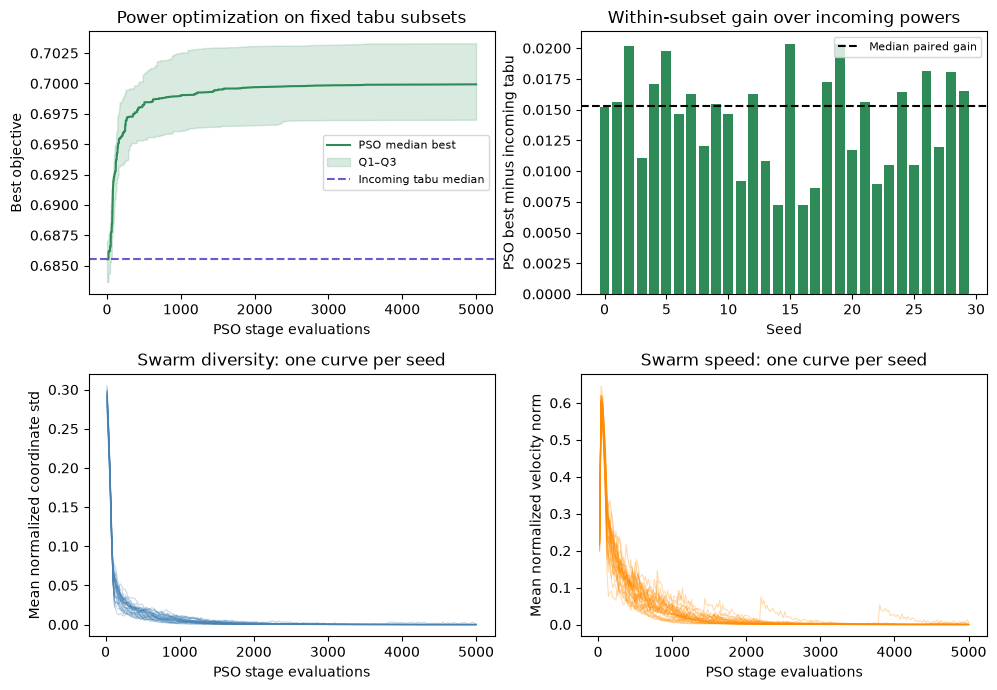

The warm-start particle guarantees no loss relative to the incoming solution; improvement is measured, not assumed.
These gains are conditional on each fixed subset. PSO does not revisit which sensors are active.
The pipeline uses 10,000 evaluations per seed, so its final scores are not an equal-budget comparison with M0 SA.
The numerical interpretation and M1 analysis appear below.


In [48]:
display({"text/markdown": (
    "| Quantity | PSO on corresponding tabu subsets |\n|---|---:|\n"
    f"| Seeds | {len(SEEDS)} |\n"
    f"| PSO evaluations per seed | {BUDGET:,} |\n"
    f"| Upstream tabu evaluations per seed | {BUDGET:,} |\n"
    f"| Total pipeline evaluations per seed | {2*BUDGET:,} |\n"
    f"| Final objective, median | {PSO_MEDIAN:.6f} |\n"
    f"| Q1–Q3 | {PSO_Q1:.6f}–{PSO_Q3:.6f} |\n"
    f"| Median paired gain over incoming subset | {PSO_MEDIAN_GAIN:+.6f} |\n"
    f"| Runs improving by more than 1e-12 | {PSO_IMPROVED_RUNS}/{len(SEEDS)} |\n"
    f"| Connected retained bests | {PSO_CONNECTED_BESTS}/{len(SEEDS)} |\n"
)}, raw=True)

pso_axis = np.arange(1, BUDGET+1)
q1, med, q3 = np.percentile(pso_traces, [25, 50, 75], axis=0)
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
axes[0, 0].plot(pso_axis, med, color="seagreen", label="PSO median best")
axes[0, 0].fill_between(pso_axis, q1, q3, color="seagreen", alpha=.18, label="Q1–Q3")
axes[0, 0].axhline(np.median(pso_input_scores), color="slateblue", ls="--", label="Incoming tabu median")
axes[0, 0].set(title="Power optimization on fixed tabu subsets", xlabel="PSO stage evaluations", ylabel="Best objective")
axes[0, 0].legend(fontsize=8)
axes[0, 1].bar(SEEDS, pso_gains, color="seagreen")
axes[0, 1].axhline(PSO_MEDIAN_GAIN, color="black", ls="--", label="Median paired gain")
axes[0, 1].set(title="Within-subset gain over incoming powers", xlabel="Seed", ylabel="PSO best minus incoming tabu")
axes[0, 1].legend(fontsize=8)
for result in pso_results:
    hx = [row["evaluation"] for row in result["history"]]
    axes[1, 0].plot(hx, [row["diversity"] for row in result["history"]], alpha=.3, lw=.8, color="steelblue")
    axes[1, 1].plot(hx, [row["mean_speed"] for row in result["history"]], alpha=.3, lw=.8, color="darkorange")
axes[1, 0].set(title="Swarm diversity: one curve per seed", xlabel="PSO stage evaluations", ylabel="Mean normalized coordinate std")
axes[1, 1].set(title="Swarm speed: one curve per seed", xlabel="PSO stage evaluations", ylabel="Mean normalized velocity norm")
fig.tight_layout()
plt.show()
print("The warm-start particle guarantees no loss relative to the incoming solution; improvement is measured, not assumed.")
print("These gains are conditional on each fixed subset. PSO does not revisit which sensors are active.")
print("The pipeline uses 10,000 evaluations per seed, so its final scores are not an equal-budget comparison with M0 SA.")
print("The numerical interpretation and M1 analysis appear below.")


### Interpretation of the final PSO runs

Across the 30 PSO runs, the final median was 0.699924, with Q1–Q3 0.697011–0.703305. Every run improved over its own incoming tabu deployment by more than 1e-12; the median paired gain was +0.015326, with Q1–Q3 0.010873–0.016922. This is the median of the 30 within-seed gains, rather than the difference between the displayed medians. All 30 retained best deployments were connected.

Particle 0 reevaluates the incoming tabu solution, so avoiding a loss is guaranteed by retaining the best evaluated position. A strictly positive gain is not guaranteed: the observed improvements provide evidence that adjusting powers helped these particular fixed subsets. Activations were preserved exactly in the retained solutions, and every first recorded PSO objective matches its corresponding tabu best. Consistency checks confirm the seed order, parameters, exact 5,000-evaluation budgets, cumulative-best trajectories and agreement between run-log scores, solution scores and saved generation histories.

The median trajectory improves rapidly early in the PSO stage and more slowly afterward. Swarm diversity and normalized speed fall sharply, indicating increasingly similar power assignments and smaller movements. This does not establish that an optimum was found or that all useful improvement ceased. The saved trajectories and dispersion diagnostics will support the explicit last-improvement analysis in M2.

PSO used 150,000 evaluations beyond the 150,000 spent obtaining the tabu subsets. The complete pipeline therefore used 10,000 evaluations per seed, or 300,000 across the final cohort; M1's reported total including tuning and validation is 550,641. Its final median remains numerically below joint SA's M0 median of 0.714655, but these unequal-cost, different-scope configurations do not constitute a controlled comparison of search mechanisms.



## M1 analysis

Tabu retained a median objective of 0.685529, compared with 0.714655 for joint SA from M0. Tabu won 3 of 30 paired seeds; Wilcoxon gave p = 2.048910e−7, with rank-biserial effect −0.939785 for tabu minus SA. This favors SA on this instance without isolating memory: tabu fixes powers at the site-clipped M0 `NOMINAL_POWER` of 20, whereas SA searches both layers. M0 showed that activations and powers are coupled, so fixing either component can restrict performance.

M0's `rho_1` of 0.9353 indicates strong local dependence in the measured mixed-layer walk, motivating exploration of nearby solutions. It does not determine the best discrete candidate-list size. Under 5,000 evaluations, lists of 20 permit 250 moves including a partial final list, versus 63 with all 80 neighbors. The separate list-size pilot retained 20 with median 0.687371. Tenure 4 likewise had the highest tenure-pilot median. Longer bans restricted more candidates without improving the median; tenure 1 showed repeated states. At the final budget, tenure 4 still produced three revisits across two runs, so temporary bans do not guarantee the absence of revisits. Aspiration was used 95 times; no forced override was needed.

PSO optimized powers on each corresponding retained tabu subset. All 30 runs improved, giving median final objective 0.699924 and median paired gain +0.015326; all retained bests were connected. Warm-starting one particle guarantees preservation of the incoming quality, not improvement. These gains show useful continuous adjustment, but the second stage is conditioned by the first: PSO cannot replace the subset selected by tabu. Reversing the order would likewise condition tabu on the power profile fixed by PSO. Neither order guarantees the best joint solution; the reversed order was not evaluated here. The pipeline spends 5,000 evaluations on tabu and another 5,000 on PSO. A fair end-to-end budget comparison requires charging both stages and either splitting one shared 5,000-evaluation budget or evaluating competitors at the same total cost.

Tuning used seeds 200–209 for tenure and 300–309 for list size, distinct from final seeds 0–29. The list-size pilot was conducted after the first final tabu cohort had already been evaluated. Only pilot medians selected parameters, and the unchanged final cohort was reused once. The sequential pilots do not establish a joint parameter optimum. PSO settings remain untuned. Adjusting its coefficients, swarm size or velocity limits could improve performance, but this is untested and would require a separately budgeted pilot with held-out seeds. `MC_BASELINE_MEDIAN` of 0.551577 remains the M0 reference; M1's tuning and validation costs are reported separately from final-run budgets.


## Carry forward to M2

The following configuration, final outcomes and saved diagnostics pass from M1 to M2. PSO's current settings provide an untuned baseline for the subsequent topology comparison.

| Item | Value | Evidence / role in M2 |
|---|---|---|
| Tabu tenure | 4 | Highest median in the separate tenure pilot, seeds 200–209. |
| Tabu candidate list | 20 | Highest median in the subsequent list pilot, seeds 300–309. |
| Fixed nominal power for tabu | 20, clipped by site caps | `NOMINAL_POWER` selected in M0. |
| Initial activation probability | 0.3 | Shared tabu/SA initializer. |
| PSO topology | `gbest` | Initial baseline; compare with ring under matched conditions in M2. |
| PSO swarm / coefficients | 20; w = 0.7; c1 = c2 = 1.4 | Untuned M1 design settings. |
| Velocity cap / initialization | 0.2 / 0.1 of each coordinate's interval width | Preserve these boundary and initialization rules in topology comparisons. |
| Final seeds / stage budget | 0–29 / 5,000 evaluations | Preserve each seed's corresponding tabu subset and power warm start. |
| PSO median / median paired gain | 0.699924 / +0.015326 | Final PSO outcomes on fixed subsets; not an equal-budget comparison with joint SA. |
| Run log | `results/m1_pso.npz` | Full-precision evaluated and best-so-far trajectories. |
| Retained solutions | `results/m1_pso_solutions.npz` | Fixed activations, final powers and scores. |
| Swarm diagnostics | `results/m1_pso_state.npz` | Generation evaluation counts, diversity, speed and final particle/personal-best states. |

Next: compare global-best and ring PSO, verify the deterministic stability recurrence, quantify last-improvement timing alongside dispersion, and implement ACO. Existing gbest runs can be reused if the M2 baseline remains exactly identical.



# M2


## Starting point from M1

M2 examines how PSO's social topology affects power optimization on the same retained tabu subsets. M1 supplies tenure 4, candidate-list size 20, site-clipped nominal power 20 and the corresponding subset/power vectors for seeds 0–29. Both topologies use 20 particles, w = 0.7, c1 = c2 = 1.4, velocity cap 0.2 and initial velocity fraction 0.1. These coefficients remain untuned.

The topology comparison holds fixed the sensor subset for each paired seed, incoming powers, initialization, random-draw schedule, boundary rules and 5,000-evaluation PSO-stage budget. Ring connections join particle indices; they do not connect physical sensor sites. Both PSO variants still depend on the subsets supplied by tabu.


## Global and ring social references

With `gbest`, all particles follow the best retained position of the complete swarm. With `ring`, particle i considers its own personal best and the personal bests of its two circular neighbors. For 20 particles, particle 0 considers indices 0, 19 and 1; particle 19 considers 19, 18 and 0. The highest objective selects the social reference. Exact ties favor self, then the left neighbor, then the right neighbor. Duplicate neighbors are removed for swarms of one or two particles.

All social references are calculated from personal-best memories at the start of the generation and held fixed throughout that generation. A new personal best can influence a neighbor in the next generation. A separate retained global best records the best evaluated solution for both topologies; ring particles may be unable to use that global best as their current social reference.

The expected trade-off is faster information sharing with a global reference versus more localized information sharing in the ring. Neither mechanism guarantees a better result. The comparison tests their final scores under the stated fixed conditions.


### Topology validation and inspection

The following short checks isolate reference selection, preserve the M1 gbest behavior and audit a ring run on the sensor instance. The actual-instance example shows a particle whose ring reference differs from the global reference. Each table row is a particle and its personal-best objective, rather than a sensor coordinate.

| Case | Expected behavior | Verification |
|---|---|---|
| Circular neighbors | The last particle neighbors the first. | Known-score example selects particle 4 for particle 0 in a five-particle ring. |
| Local reference | Select the best neighbor even if a better particle exists elsewhere. | Known scores and the actual seed-0 example identify a local winner different from gbest. |
| Exact ties | Prefer self, then left, then right. | Equal-score neighborhoods retain self. |
| Small swarms | Remove duplicate neighbor indices. | One- and two-particle cases return the expected targets. |
| Frozen references | New improvements affect targets in the next generation. | A synthetic global improvement to 20 does not alter the current generation's other targets; it becomes available in the next. |
| Shared mechanics | Preserve fixed sensors, power limits and personal/global memory. | Independent audit reconstructs references and memories and checks all evaluated vectors. |
| Matched randomness | Same initialization and per-coordinate draws for paired topologies. | The short paired run has exactly matching initial positions, velocities and random vectors. |
| gbest regression | The topology extension preserves M1 gbest behavior. | Old and extended functions produce identical short evaluated trajectories and returned vectors. |
| Replay | A repeated seed reproduces ring results. | Complete short score trajectories and returned powers match. |
| Budget edge cases | Respect partial initialization, partial generations and shared stage limits. | Budgets 1, 7 and 23, plus a 23-call stage inside a budget of 30, are checked. |

Sensor-instance validation uses 394 evaluations, including the illustrated run and replay. The synthetic frozen-reference test uses 15 separate objective calls. These are additional to the final topology experiment.


In [49]:
# Short replay establishes that extending topology does not alter the gbest branch.
from types import SimpleNamespace

M2_CHECK_BUDGET = 85
m2_check_problems = []
original_probe = SensorPlacementProblem(instance, budget=M2_CHECK_BUDGET, seed=0)
old_trace = m1_original_pso(original_probe, 0, pso_input_active[0], pso_input_power[0],
                             **PSO_PARAMS, trace_updates=85, return_details=True)
global_probe = SensorPlacementProblem(instance, budget=M2_CHECK_BUDGET, seed=0)
global_trace = pso(global_probe, 0, pso_input_active[0], pso_input_power[0],
                    **PSO_PARAMS, trace_updates=85, return_details=True)
assert np.array_equal(original_probe.record.values, global_probe.record.values)
assert np.array_equal(old_trace["power"], global_trace["power"])
m2_check_problems.extend([original_probe, global_probe])

# Known personal-best scores make wraparound and local/global differences explicit.
known_positions = np.arange(10, dtype=float).reshape(5, 2)
known_scores = np.array([1., 5., 2., 3., 9.])
targets, target_scores, winners = ring_social_targets(known_positions, known_scores)
assert winners.tolist() == [4, 1, 1, 4, 4]
assert np.array_equal(targets, known_positions[winners])
assert winners[1] != int(np.argmax(known_scores))
assert ring_social_targets(known_positions, np.array([0.,5.,1.,1.,5.]))[2][0] == 4
assert ring_social_targets(known_positions, np.ones(5))[2].tolist() == list(range(5))
assert ring_social_targets(known_positions[:1], known_scores[:1])[2].tolist() == [0]
assert ring_social_targets(known_positions[:2], known_scores[:2])[2].tolist() == [1, 1]


class M2AuditProblem(SensorPlacementProblem):
    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.candidates_seen = []

    def evaluate_verbose(self, active, power):
        self.candidates_seen.append((active.copy(), power.copy()))
        return super().evaluate_verbose(active, power)


def audit_ring(details, problem):
    m = details["effective_swarm_size"]
    idx = details["indices"]
    memories = details["initial_positions"].copy()
    scores = details["initial_scores"].copy()
    last_generation = 0
    frozen_positions, frozen_scores = None, None
    global_best = float(scores.max())
    assert len(details["updates"]) == problem.evaluations_used-m
    for row in details["updates"]:
        if row["generation"] != last_generation:
            frozen_positions, frozen_scores = memories.copy(), scores.copy()
            last_generation = row["generation"]
        j = row["particle"]
        neighborhood = list(dict.fromkeys([j, (j-1) % m, (j+1) % m]))
        winner = max(neighborhood, key=lambda k: frozen_scores[k])
        assert row["social_index"] == winner
        assert np.array_equal(row["social_target"], frozen_positions[winner])
        assert row["social_score"] == frozen_scores[winner]
        assert np.array_equal(row["personal_before"], memories[j])
        assert row["personal_score_before"] == scores[j]
        if row["score"] > scores[j]:
            scores[j], memories[j] = row["score"], row["position"]
        global_best = max(global_best, row["score"])
        assert row["global_after"] == global_best
        assert row["personal_score_after"] == scores[j]
        a, power = problem.candidates_seen[row["evaluation"]-1]
        assert np.array_equal(a, pso_input_active[0])
        assert np.array_equal(power[idx], row["position"])
    assert details["score"] == max(problem.record.values)
    assert np.array_equal(details["personal_positions"], memories)
    assert np.array_equal(details["personal_scores"], scores)
    assert all(np.array_equal(a, pso_input_active[0]) for a, _ in problem.candidates_seen)
    assert all(np.array_equal(power[~a], pso_input_power[0][~a]) for a, power in problem.candidates_seen)
    assert all(np.all((power >= spec.power_min) & (power <= instance.power_cap)) for _, power in problem.candidates_seen)
    assert sum(r["evaluated_particles"] for r in details["history"]) == problem.evaluations_used


ring_config = {**PSO_PARAMS, "topology": "ring"}
ring_probe = M2AuditProblem(instance, budget=M2_CHECK_BUDGET, seed=0)
ring_trace = pso(ring_probe, 0, pso_input_active[0], pso_input_power[0], **ring_config,
                 trace_updates=85, return_details=True)
audit_ring(ring_trace, ring_probe)
replay_probe = M2AuditProblem(instance, budget=M2_CHECK_BUDGET, seed=0)
ring_replay = pso(replay_probe, 0, pso_input_active[0], pso_input_power[0], **ring_config,
                  trace_updates=85, return_details=True)
assert np.array_equal(replay_probe.record.values, ring_probe.record.values)
assert np.array_equal(ring_replay["power"], ring_trace["power"])
assert np.array_equal(ring_trace["initial_positions"], global_trace["initial_positions"])
assert np.array_equal(ring_trace["initial_velocities"], global_trace["initial_velocities"])
for a, b in zip(global_trace["updates"], ring_trace["updates"]):
    assert np.array_equal(a["r1"], b["r1"]) and np.array_equal(a["r2"], b["r2"])
m2_check_problems.extend([ring_probe, replay_probe])
for budget in (1, 7, 23):
    probe = M2AuditProblem(instance, budget=budget, seed=22_500)
    details = pso(probe, 22_500, pso_input_active[0], pso_input_power[0], **ring_config,
                  trace_updates=budget, return_details=True)
    audit_ring(details, probe)
    assert details["evaluations_used"] == budget
    m2_check_problems.append(probe)
limited_ring = M2AuditProblem(instance, budget=30, seed=22_501)
with limited_ring.limited(23):
    details = pso(limited_ring, 22_501, pso_input_active[0], pso_input_power[0], **ring_config,
                  trace_updates=23, return_details=True)
assert limited_ring.evaluations_remaining == 7
audit_ring(details, limited_ring)
m2_check_problems.append(limited_ring)


class M2ScriptedProblem:
    def __init__(self):
        self.instance = SimpleNamespace(n_candidates=3, power_cap=np.full(3, 5.),
                                        spec=SimpleNamespace(power_min=1.))
        self.scores = [1., 2., 3., 10., 4., 20., 0., 0., 0., 0., 0., 0., 0., 0., 0.]
        self.evaluations_used, self.budget = 0, len(self.scores)

    @property
    def evaluations_remaining(self):
        return self.budget-self.evaluations_used

    def evaluate_verbose(self, active, power):
        value = self.scores[self.evaluations_used]
        self.evaluations_used += 1
        return SimpleNamespace(objective=value)


scripted_ring = pso(M2ScriptedProblem(), 0, np.array([True, True, False]), np.full(3, 2.),
                    topology="ring", swarm_size=5, trace_updates=15, return_details=True)
assert scripted_ring["updates"][0]["global_after"] == 20.
assert scripted_ring["updates"][1]["social_index"] == 2
assert scripted_ring["updates"][1]["social_score"] == 3.
assert scripted_ring["updates"][6]["social_index"] == 0
assert scripted_ring["updates"][6]["social_score"] == 20.
M2_TOPOLOGY_CHECK_EVALUATIONS = sum(p.evaluations_used for p in m2_check_problems)
M2_TOPOLOGY_SYNTHETIC_EVALUATIONS = 15
print("Checks passed: ring wraparound, local selection, self-first ties and one/two-particle neighborhoods.")
print("Checks passed: synchronous social references, personal/global memory, same initialization/random draws and seeded replay.")
print("Checks passed: unchanged gbest short trajectory, fixed sensors, individual bounds and partial/shared budgets.")
print(f"Separate sensor validation evaluations: {M2_TOPOLOGY_CHECK_EVALUATIONS}; synthetic objective calls: 15.")

# Show the first actual ring update whose social reference differs from gbest.
ring_event = next(r for r in ring_trace["updates"]
                  if r["generation"] == 1 and r["social_index"] != int(np.argmax(ring_trace["initial_scores"])))
j = ring_event["particle"]
neighbors = [j, (j-1) % 20, (j+1) % 20]
table = "| Particle | Role | Initial personal-best objective | Chosen social reference |\n|---|---|---:|---|\n"
global_index = int(np.argmax(ring_trace["initial_scores"]))
for k in list(dict.fromkeys(neighbors+[global_index])):
    table += (f"| {k} | {'In ring neighborhood' if k in neighbors else 'Global best outside neighborhood'} | "
              f"{ring_trace['initial_scores'][k]:.9f} | {'Yes' if k==ring_event['social_index'] else 'No'} |\n")
print(f"Actual seed 0: generation 1, particle {j}, evaluation {ring_event['evaluation']}.")
display({"text/markdown": table}, raw=True)
print(f"Ring uses particle {ring_event['social_index']}; gbest would use particle {global_index}.")
print("The retained global best is still tracked for the reported solution, even when a ring particle cannot use it as a target.")


Checks passed: ring wraparound, local selection, self-first ties and one/two-particle neighborhoods.
Checks passed: synchronous social references, personal/global memory, same initialization/random draws and seeded replay.
Checks passed: unchanged gbest short trajectory, fixed sensors, individual bounds and partial/shared budgets.
Separate sensor validation evaluations: 394; synthetic objective calls: 15.
Actual seed 0: generation 1, particle 2, evaluation 23.


| Particle | Role | Initial personal-best objective | Chosen social reference |
|---|---|---:|---|
| 2 | In ring neighborhood | -2.091360369 | No |
| 1 | In ring neighborhood | -1.822201836 | Yes |
| 3 | In ring neighborhood | -2.684866334 | No |
| 0 | Global best outside neighborhood | 0.685527708 | No |


Ring uses particle 1; gbest would use particle 0.
The retained global best is still tracked for the reported solution, even when a ring particle cannot use it as a target.


## Paired 30-seed topology experiment

Each topology receives seeds 0–29 and 5,000 evaluations per seed, with the matching M1 tabu subset and power warm start. Apart from the social neighborhood, the algorithms share their settings and draw random factors in the same order. Initialization evaluates 20 particles; 249 complete update generations consume the remaining 4,980 evaluations.

The original M1 gbest cohort was executed on Windows with different Python/NumPy versions. Both topologies are therefore evaluated in the same Linux runtime for this comparison, and the M1 cohort remains archived. The common-runtime gbest replay has exactly the same final scores as M1; evaluated trajectories differ by at most 4.44e−16. The 150,000 replay evaluations are charged rather than treated as free reuse. Together the new final cohorts cost 300,000 evaluations; with short checks M2 totals 300,394 sensor evaluations at this stage. Upstream tabu costs are retained in M1's accounting and are not charged again.

For each paired seed, the difference between final best objectives is:

$$d_i=f_{\mathrm{gbest},i}-f_{\mathrm{ring},i}.$$

- $i$: the seed identifying a paired run, from 0 to 29; here it indexes seeds rather than individual particles.
- $f_{\mathrm{gbest},i}$: the highest objective evaluated by gbest during the 5,000-evaluation run for seed $i$.
- $f_{\mathrm{ring},i}$: the highest objective evaluated by ring during the corresponding run, starting from the same tabu subset and power initialization.
- $d_i$: the within-seed difference between those two final best objectives.

The objective is maximized, so a positive difference favors gbest, a negative difference favors ring, and zero indicates equal scores before applying the stated numerical precision rule. These are objective scores for complete power assignments, not individual sensor powers. For illustration, gbest = 0.700 and ring = 0.702 give $d_i=0.700-0.702=-0.002$, favoring ring. The median paired difference is the median of these 30 differences; it is not generally the difference between the two methods' medians.

Report median/Q1–Q3, paired median difference, wins/ties/losses, two-sided Wilcoxon (`p_topology`) and paired rank-biserial effect. Rank calculations use differences rounded to 12 decimal places, consistently with M0/M1. This is one planned topology comparison; pilot rankings are not added as significance tests. The signed-rank interpretation assumes approximately symmetric paired differences and does not directly test the difference of the displayed medians. No new coefficient tuning is performed.


In [50]:
from scipy.stats import wilcoxon
from tc6035.problem import RunRecord
from tc6035.runlog import RunSet, save_runset, load_runset

topo_gbest_runs = load_runset("results/m1_pso.npz")
assert topo_gbest_runs.seeds == list(SEEDS)
assert topo_gbest_runs.meta["student_id"] == STUDENT_ID
assert topo_gbest_runs.meta["params"]["salt"] == SALT
assert all(topo_gbest_runs.meta["params"][key] == value for key,value in PSO_PARAMS.items())
assert topo_gbest_runs.meta["params"]["tabu_params"] == TABU_PARAMS
assert all(m["budget"] == m["evaluations_used"] == len(v) == BUDGET
           for m,v in zip(topo_gbest_runs.meta["runs"],topo_gbest_runs.values))
assert np.array_equal(np.array([v[0] for v in topo_gbest_runs.values]), pso_input_scores)
# Both topologies are evaluated in the same runtime; M1 remains the archived reference.
topo_m1_runs = topo_gbest_runs
topo_gbest_records = []
for i,seed in enumerate(SEEDS):
    problem=SensorPlacementProblem(instance,budget=BUDGET,seed=seed)
    result=pso(problem,seed,pso_input_active[i],pso_input_power[i],**PSO_PARAMS,return_details=True)
    assert result["evaluations_used"] == problem.evaluations_used == BUDGET
    assert result["score"] == problem.record.best
    assert problem.record.values[0] == pso_input_scores[i]
    assert np.array_equal(result["active"],pso_input_active[i])
    topo_gbest_records.append(problem.record)
    if (i+1)%5==0:print(f"gbest: {i+1}/{len(SEEDS)} runs complete.",flush=True)
save_runset("results/m2_pso_gbest.npz",RunSet(
    algorithm="pso_gbest",student_id=STUDENT_ID,
    params={**topo_m1_runs.meta["params"],"execution":"M2 common environment"},records=topo_gbest_records))
topo_gbest_runs=load_runset("results/m2_pso_gbest.npz")
print("Same-environment gbest replay identical to M1:",
      all(np.array_equal(a,b) for a,b in zip(topo_m1_runs.values,topo_gbest_runs.values)))
topo_ring_results, topo_ring_records = [], []
for i, seed in enumerate(SEEDS):
    problem = SensorPlacementProblem(instance, budget=BUDGET, seed=seed)
    result = pso(problem, seed, pso_input_active[i], pso_input_power[i],
                 **{**PSO_PARAMS, "topology":"ring"}, return_details=True)
    assert result["evaluations_used"] == problem.evaluations_used == BUDGET
    assert result["score"] == problem.record.best == max(problem.record.values)
    assert problem.record.values[0] == pso_input_scores[i]
    assert result["score"] >= pso_input_scores[i]
    assert np.array_equal(result["active"],pso_input_active[i])
    assert np.all((result["power"] >= spec.power_min) & (result["power"] <= instance.power_cap))
    assert sum(h["evaluated_particles"] for h in result["history"]) == BUDGET
    # Reconstruct the shared initializer without additional objective calls.
    init_rng = np.random.default_rng(seed)
    idx = result["indices"]
    expected_positions = init_rng.uniform(spec.power_min,instance.power_cap[idx],size=(20,len(idx)))
    expected_positions[0] = pso_input_power[i][idx]
    expected_velocities = init_rng.uniform(-.1*(instance.power_cap[idx]-spec.power_min),
                                          .1*(instance.power_cap[idx]-spec.power_min),size=expected_positions.shape)
    assert np.array_equal(result["initial_positions"],expected_positions)
    assert np.array_equal(result["initial_velocities"],expected_velocities)
    topo_ring_results.append(result)
    topo_ring_records.append(problem.record)
    if (i+1) % 5 == 0:
        print(f"Ring: {i+1}/{len(SEEDS)} runs complete.",flush=True)
save_runset("results/m2_pso_ring.npz", RunSet(
    algorithm="pso_ring",student_id=STUDENT_ID,
    params={**topo_gbest_runs.meta["params"],"topology":"ring","neighborhood":"self, left, right; circular; synchronous"},
    records=topo_ring_records))
np.savez_compressed("results/m2_pso_ring_solutions.npz",seeds=np.array(SEEDS),
                    active=np.array([r["active"] for r in topo_ring_results]),
                    power=np.array([r["power"] for r in topo_ring_results]),
                    score=np.array([r["score"] for r in topo_ring_results]))
state={"seeds":np.array(SEEDS)}
for i,r in enumerate(topo_ring_results):
    for key in ("indices","positions","velocities","personal_positions","personal_scores"):
        state[f"{key}_{i}"]=r[key]
    for key in ("evaluation","best_score","diversity","mean_speed"):
        state[f"history_{key}_{i}"]=np.array([h[key] for h in r["history"]])
np.savez_compressed("results/m2_pso_ring_state.npz",**state)
topo_ring_runs=load_runset("results/m2_pso_ring.npz")
assert topo_ring_runs.seeds==topo_gbest_runs.seeds
assert all(np.array_equal(v,r.values) for v,r in zip(topo_ring_runs.values,topo_ring_records))
assert all(np.array_equal(b,np.maximum.accumulate(v)) for b,v in zip(topo_ring_runs.best_so_far,topo_ring_runs.values))
topo_scores={"gbest":topo_gbest_runs.best_values,"ring":topo_ring_runs.best_values}
topo_differences=topo_scores["gbest"]-topo_scores["ring"]
topo_rank_differences=np.round(topo_differences,12)
topo_test=(wilcoxon(topo_rank_differences,alternative="two-sided",zero_method="wilcox",method="auto")
           if np.any(topo_rank_differences) else None)
W_topo=float(topo_test.statistic) if topo_test else 0.
p_topology=float(topo_test.pvalue) if topo_test else 1.
topo_effect=paired_rank_biserial(topo_scores["gbest"],topo_scores["ring"])
topo_wins=int(np.sum(topo_rank_differences>0))
topo_ties=int(np.sum(topo_rank_differences==0))
topo_losses=int(np.sum(topo_rank_differences<0))
M2_RING_FINAL_EVALUATIONS=sum(r.evaluations_used for r in topo_ring_records)
M2_GBEST_FINAL_EVALUATIONS=sum(r.evaluations_used for r in topo_gbest_records)
M2_EVALUATION_ACCOUNTING={"topology_validation":M2_TOPOLOGY_CHECK_EVALUATIONS,
                          "gbest_common_environment":M2_GBEST_FINAL_EVALUATIONS,
                          "ring_final_runs":M2_RING_FINAL_EVALUATIONS}
for name,scores in topo_scores.items():
    q1,med,q3=np.percentile(scores,[25,50,75])
    print(f"{name}: median={med:.9f}; Q1–Q3=[{q1:.9f},{q3:.9f}].")
print(f"Differences are gbest minus ring: median={np.median(topo_differences):+.9f}.")
print(f"gbest wins/ties/losses: {topo_wins}/{topo_ties}/{topo_losses}.")
print(f"Two-sided paired Wilcoxon: W={W_topo:.1f}; p_topology={p_topology:.9e}; rank-biserial={topo_effect:+.6f}.")
print(f"New final-run evaluations: {M2_RING_FINAL_EVALUATIONS+M2_GBEST_FINAL_EVALUATIONS:,}; both topologies evaluated in the same environment.")
print(f"M2 sensor evaluations so far: {sum(M2_EVALUATION_ACCOUNTING.values()):,}; synthetic calls: {M2_TOPOLOGY_SYNTHETIC_EVALUATIONS}.")


gbest: 5/30 runs complete.
gbest: 10/30 runs complete.
gbest: 15/30 runs complete.
gbest: 20/30 runs complete.
gbest: 25/30 runs complete.
gbest: 30/30 runs complete.
Same-environment gbest replay identical to M1: True
Ring: 5/30 runs complete.
Ring: 10/30 runs complete.
Ring: 15/30 runs complete.
Ring: 20/30 runs complete.
Ring: 25/30 runs complete.
Ring: 30/30 runs complete.
gbest: median=0.699923776; Q1–Q3=[0.697011073,0.703305381].
ring: median=0.701581267; Q1–Q3=[0.697933771,0.704335684].
Differences are gbest minus ring: median=-0.001051749.
gbest wins/ties/losses: 8/0/22.
Two-sided paired Wilcoxon: W=67.0; p_topology=3.449581563e-04; rank-biserial=-0.711828.
New final-run evaluations: 300,000; both topologies evaluated in the same environment.
M2 sensor evaluations so far: 300,394; synthetic calls: 15.


### Topology outcomes and paired differences

The top panels show median best-so-far trajectories and Q1–Q3 over PSO-stage evaluations, with a later-budget zoom. Shading represents variation between runs, not confidence intervals. The lower panels pair final scores and display each seed's gbest-minus-ring difference. All convergence axes count objective evaluations, rather than generations.


| Topology | Median final objective | Q1–Q3 |
|---|---:|---:|
| gbest | 0.699924 | 0.697011–0.703305 |
| ring | 0.701581 | 0.697934–0.704336 |


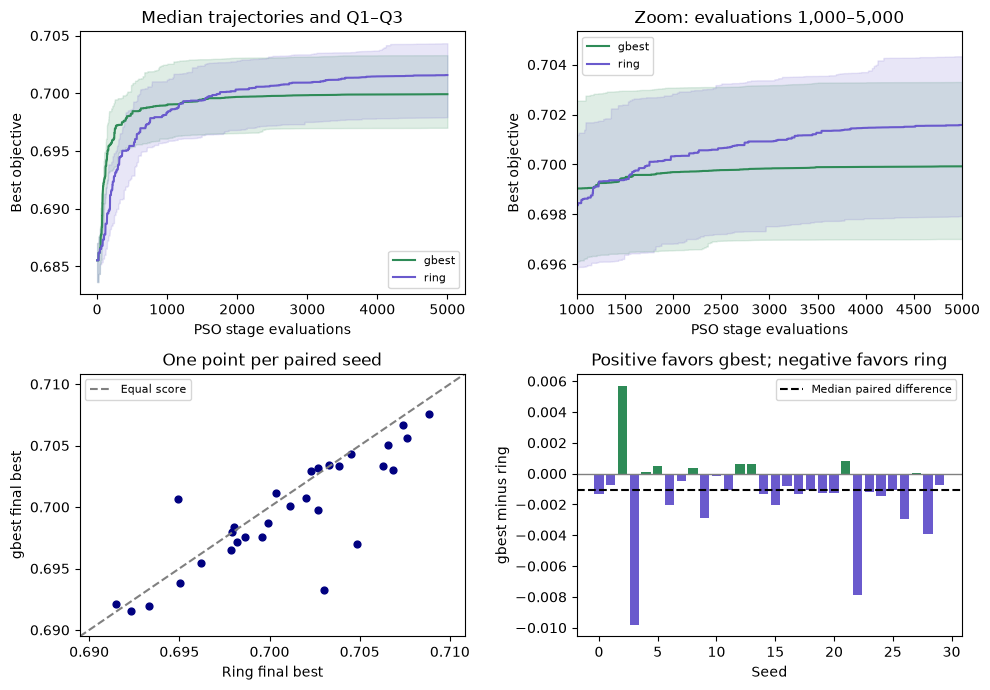

In [51]:
summary="| Topology | Median final objective | Q1–Q3 |\n|---|---:|---:|\n"
for label,scores in topo_scores.items():
    a,b,c=np.percentile(scores,[25,50,75])
    summary+=f"| {label} | {b:.6f} | {a:.6f}–{c:.6f} |\n"
display({"text/markdown":summary},raw=True)
fig,axes=plt.subplots(2,2,figsize=(10,7))
axis=np.arange(1,BUDGET+1)
for label,runs,color in (("gbest",topo_gbest_runs,"seagreen"),("ring",topo_ring_runs,"slateblue")):
    q1,med,q3=np.percentile(np.array(runs.best_so_far),[25,50,75],axis=0)
    for ax in axes[0]:
        ax.plot(axis,med,label=label,color=color)
        ax.fill_between(axis,q1,q3,color=color,alpha=.15)
        ax.set(xlabel="PSO stage evaluations",ylabel="Best objective")
        ax.legend(fontsize=8)
axes[0,0].set_title("Median trajectories and Q1–Q3")
axes[0,1].set(title="Zoom: evaluations 1,000–5,000",xlim=(1000,5000))
tail=np.array([topo_gbest_runs.best_so_far,topo_ring_runs.best_so_far])[:,:,999:]
lo,hi=np.percentile(tail,[25,75],axis=1).min(),np.percentile(tail,[25,75],axis=1).max()
axes[0,1].set_ylim(lo-.001,hi+.001)
low=min(topo_scores['gbest'].min(),topo_scores['ring'].min())-.002
high=max(topo_scores['gbest'].max(),topo_scores['ring'].max())+.002
axes[1,0].plot([low,high],[low,high],ls="--",color="gray",label="Equal score")
axes[1,0].scatter(topo_scores['ring'],topo_scores['gbest'],color="navy",s=24)
axes[1,0].set(title="One point per paired seed",xlabel="Ring final best",ylabel="gbest final best",xlim=(low,high),ylim=(low,high))
from matplotlib.ticker import MaxNLocator
axes[1,0].xaxis.set_major_locator(MaxNLocator(nbins=5))
axes[1,0].yaxis.set_major_locator(MaxNLocator(nbins=5))
axes[1,0].legend(fontsize=8)
axes[1,1].bar(SEEDS,topo_differences,color=np.where(topo_differences>0,"seagreen","slateblue"))
axes[1,1].axhline(0,color="gray",lw=1)
axes[1,1].axhline(np.median(topo_differences),color="black",ls="--",label="Median paired difference")
axes[1,1].set(title="Positive favors gbest; negative favors ring",xlabel="Seed",ylabel="gbest minus ring")
axes[1,1].legend(fontsize=8)
fig.tight_layout()
Path("figures").mkdir(exist_ok=True)
fig.savefig("figures/m2_topology.png",dpi=120,bbox_inches="tight")
plt.show()


### Interpretation of the topology comparison

Ring had median final objective 0.701581, Q1–Q3 0.697934–0.704336, compared with 0.699924, Q1–Q3 0.697011–0.703305 for gbest. Ring won 22 of 30 paired seeds and gbest won 8, with no ties under the stated precision rule. The median and both quartiles are higher for ring, although the Q1–Q3 intervals overlap and describe run variability rather than statistical significance. The median, paired win count and signed-rank test favor the same topology in this sample. The median paired difference was −0.001052 for gbest minus ring; this is not the difference between the two medians.

The two-sided Wilcoxon result was W = 67 and `p_topology` = 3.449582e−4. The paired rank-biserial effect was −0.711828, favoring ring. The absolute median paired gain is modest on the objective scale; the effect statistic describes the imbalance of signed ranks, rather than a percentage improvement. Statistical evidence of a difference does not make every seed favor ring or establish that it is optimal across problems.

The median trajectories show gbest improving faster early, followed by ring overtaking it and finishing higher. This is consistent with different information-sharing rates, but the score comparison alone does not establish diversity as the causal mechanism. Stagnation and dispersion require the separate diagnostics specified in the next M2 section. All 30 retained ring bests were connected.

Both topologies introduce a directional search bias through their social references: gbest attracts every particle toward the swarm's best retained position, whereas ring attracts each particle toward the best personal position in its local neighborhood. They share the same cognitive and inertia terms, so the difference concerns how social information guides movement. Neither reference structure is universally preferable. Their usefulness depends on the problem landscape, search settings and evaluation budget, and the choice should follow empirical evidence under comparable conditions. The observed advantage supports ring for this tested configuration, rather than a general ranking of the two mechanisms.

Ring will be carried forward as the preferred topology among these two tested configurations, supported by its median, paired wins and test result. This selection uses the same observed comparison cohort and is not an independent validation on unseen seeds or instances. The conclusion is conditional on these coefficients, the fixed tabu subsets, this instance and the 5,000-evaluation stage budget. It does not establish superiority of ring for joint activation/power search.


## Deterministic coefficient stability

M1 checked whether the PSO coefficients satisfy the theoretical inequality. M2 also simulates the deterministic recurrence specified in the assignment. The same coefficients apply to both tested topologies.

For nonnegative inertia, the stated region is $0\leq w<1$ and $0<\varphi<2(1+w)$, where $\varphi=c_1+c_2$. Our values give $w=0.7$, $\varphi=2.8$ and upper bound 3.4. This is a condition for a simplified deterministic model with fixed attraction references, rather than a guarantee for the bounded stochastic optimizer.

After expressing one coordinate as a displacement from a fixed attraction reference, the model is:

$$x_{k+1}=(1+w-\varphi)x_k-wx_{k-1}.$$

- $k$: the recurrence step, rather than a sensor-objective evaluation.
- $x_k$: the current displacement from the fixed reference.
- $x_{k-1}$: the previous displacement.
- $x_{k+1}$: the next displacement predicted by the model.
- $w$: the inertia coefficient, retaining the influence of previous movement.
- $\varphi=c_1+c_2$: the fixed combined attraction strength used in this deterministic approximation.

Tending to zero means that the displacement from the reference becomes progressively smaller: oscillations may cross the reference while their amplitude decays. It does not mean that transmit powers or objective scores must approach zero. A displacement that does not tend to zero may retain oscillations or grow; failing to reach a small tolerance in a finite simulation alone does not prove divergence.

The simulation uses initial displacements $x_0=1$ and $x_1=0.5$ and runs through step 200. It reports the final magnitude and the largest magnitude in the last 20 steps, so a single crossing near zero is not mistaken for sustained decay. An illustrative case with the same inertia and $\varphi=4.0$ lies outside the region. It is a numerical contrast, not PSO tuning, and neither simulation calls the sensor objective.


PSO coefficients: w=0.7, c1=1.4, c2=1.4.
phi=c1+c2=2.8; stability_bound=2(1+w)=3.4; inside_region=True.
Initial displacements: x0=1.0, x1=0.5; recurrence simulated through k=200.
Inside-region case: |x200|=3.047088e-16; max |x| over the last 20 steps=1.290932e-14.
Tail below 1e-3: True; agreement with the predicted inside-region behavior: True.
Outside-region illustration: w=0.7, phi=4.0; |x200|=1.785977e+57.
The actual coefficients produce decaying oscillations; the outside example produces growing oscillations.
These are displacement simulations, not sensor powers or objective evaluations.
No new sensor objective evaluations; no PSO parameter tuning or final-run repetition.


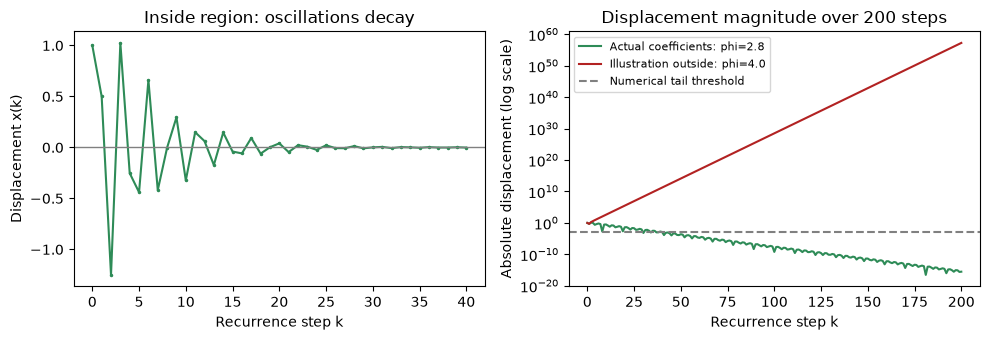

In [52]:
phi = PSO_PARAMS["c1"] + PSO_PARAMS["c2"]
stability_bound = 2 * (1 + PSO_PARAMS["w"])
inside_region = bool(0 <= PSO_PARAMS["w"] < 1 and 0 < phi < stability_bound)


def recurrence_trace(w, phi, steps=200, x0=1.0, x1=0.5):
    if steps < 2:
        raise ValueError("At least two steps are required.")
    displacement = np.empty(steps + 1)
    displacement[:2] = [x0, x1]
    for k in range(1, steps):
        displacement[k+1] = (1+w-phi)*displacement[k] - w*displacement[k-1]
    return displacement


def recurrence_final(w, phi, steps=200):
    return float(abs(recurrence_trace(w, phi, steps)[-1]))


stability_trace = recurrence_trace(PSO_PARAMS["w"], phi)
final = recurrence_final(PSO_PARAMS["w"], phi)
stability_tail_max = float(np.max(np.abs(stability_trace[-20:])))
converged = bool(np.isfinite(final) and stability_tail_max < 1e-3)

# One illustrative coefficient pair outside the region; no optimizer is run.
outside_phi = 4.0
outside_trace = recurrence_trace(PSO_PARAMS["w"], outside_phi)
outside_final = float(abs(outside_trace[-1]))
assert np.allclose(stability_trace[:4], [1., .5, -1.25, 1.025])
assert inside_region and converged
assert outside_phi > stability_bound and outside_final > 1e6
assert np.array_equal(recurrence_trace(0., 1.)[2:], np.zeros(199))

print(f"PSO coefficients: w={PSO_PARAMS['w']}, c1={PSO_PARAMS['c1']}, c2={PSO_PARAMS['c2']}.")
print(f"phi=c1+c2={phi:.1f}; stability_bound=2(1+w)={stability_bound:.1f}; inside_region={inside_region}.")
print("Initial displacements: x0=1.0, x1=0.5; recurrence simulated through k=200.")
print(f"Inside-region case: |x200|={final:.6e}; max |x| over the last 20 steps={stability_tail_max:.6e}.")
print(f"Tail below 1e-3: {converged}; agreement with the predicted inside-region behavior: {inside_region == converged}.")
print(f"Outside-region illustration: w={PSO_PARAMS['w']}, phi={outside_phi}; |x200|={outside_final:.6e}.")
print("The actual coefficients produce decaying oscillations; the outside example produces growing oscillations.")
print("These are displacement simulations, not sensor powers or objective evaluations.")
print("No new sensor objective evaluations; no PSO parameter tuning or final-run repetition.")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
k = np.arange(len(stability_trace))
axes[0].plot(k[:41], stability_trace[:41], marker=".", ms=3, color="seagreen")
axes[0].axhline(0, color="gray", lw=1)
axes[0].set(title="Inside region: oscillations decay", xlabel="Recurrence step k", ylabel="Displacement x(k)")
axes[1].semilogy(k, np.maximum(np.abs(stability_trace), 1e-30), color="seagreen", label="Actual coefficients: phi=2.8")
axes[1].semilogy(k, np.maximum(np.abs(outside_trace), 1e-30), color="firebrick", label="Illustration outside: phi=4.0")
axes[1].axhline(1e-3, color="gray", ls="--", label="Numerical tail threshold")
axes[1].set(title="Displacement magnitude over 200 steps", xlabel="Recurrence step k", ylabel="Absolute displacement (log scale)")
axes[1].legend(fontsize=8)
fig.tight_layout()
Path("figures").mkdir(exist_ok=True)
fig.savefig("figures/m2_stability.png", dpi=120, bbox_inches="tight")
plt.show()


### Stability result and scope

The actual coefficient pair lies inside the stated region. At step 200, the absolute displacement is 3.047e-16, and the maximum over the final 20 steps is 1.291e-14; both are below the numerical tolerance of 1e−3. The oscillations decay, consistent with the theoretical prediction. In the illustrative outside-region case, the magnitude grows to 1.786e+57. The first few actual-model displacements are 1, 0.5, −1.25 and 1.025, illustrating that temporary overshoot is compatible with eventual decay.

This verifies the predicted behavior of the deterministic recurrence for the selected coefficients and initial conditions. The real PSO redraws random factors, updates personal/social memories and applies velocity/power limits. Convergence of this fixed-reference approximation therefore does not establish convergence of the real optimizer, discovery of an optimum, or superiority of either topology. A stable search can still concentrate around a suboptimal solution. Conversely, clipping can keep powers bounded without demonstrating stable underlying movement.

No sensor objective evaluations were added. Actual search stagnation is a separate empirical question, to be examined using last-improvement timing together with the saved diversity diagnostics.


## Last-improvement timing and dispersion

This diagnostic uses the 30 common-environment gbest logs in `results/m2_pso_gbest.npz`, as required by M2, even though ring was preferred in the topology comparison. It asks when score improvement ceased within the available budget, rather than inferring stagnation from a flat-looking curve or low diversity alone.

For each seed, the best-so-far sequence is scanned for strictly positive increases. The final such increase defines:

$$s_i=\frac{L_i}{B},\qquad R_i=B-L_i.$$

- $i$: the paired-run seed, from 0 to 29.
- $L_i$: the 1-based objective-evaluation number of the last strictly positive improvement for seed $i$.
- $B$: the run budget, equal to 5,000 evaluations.
- $s_i$: the fraction of the budget used when that last improvement occurred.
- $R_i$: the evaluations remaining after it, during which the retained best did not improve further.

For example, a last improvement at evaluation 1,000 gives $s_i=0.20$ and 4,000 subsequent evaluations without improvement; a last improvement at 4,900 gives $s_i=0.98$ and a tail of 100. If no improvement occurs after the initial evaluation, that baseline is recorded as $L_i=1$. `earliest_stall` is the minimum fraction across seeds. The illustrated seed is the one with that earliest last improvement, not necessarily the lowest objective.

A complementary sensitivity calculation uses the last individual best-so-far increment exceeding 1e−6. This absolute threshold is fixed for description, not asserted as an application-specific definition of useful improvement. Smaller increments can accumulate into a larger total gain, so the remaining cumulative gain is also reported. The strict criterion remains the primary assignment diagnostic.

Position dispersion is the mean standard deviation across particle positions after normalizing each coordinate by its sensor's power-interval width. The M2 gbest run log stores objective sequences but not its complete swarm history. For the selected seed, positions and memories are reconstructed with the unchanged PSO engine, seed and parameters, supplying the saved objective scores in their original order instead of calculating the objective again. The generation-level best scores are checked against the recorded trajectory. This is a recorded-score replay, not a new search experiment; it performs 5,000 stored-score lookups and zero sensor objective calculations.

The main figure aligns best-so-far and reconstructed position dispersion on the same evaluation axis. It also shows all seeds' last-improvement fractions and a later-budget objective-gain view. A fixed coordinate origin or shrinking dispersion does not by itself establish optimality.


| Diagnostic | Observed value |
|---|---:|
| Median last strictly positive improvement | 4982 / 5000 (99.64%) |
| Earliest last strictly positive improvement | 4883 / 5000 (97.66%), seed 13 |
| Largest tail without any further improvement | 117 evaluations (2.34%) |
| Median last individual gain above 1e-6 | 4441 / 5000 (88.82%) |
| Earliest last individual gain above 1e-6 | 2529 / 5000 (50.58%) |
| Selected seed diversity: initialization to final generation | 2.836e-01 to 7.447e-06 |
| New sensor objective evaluations | 0 |


earliest_stall=0.9766; selected seed=13.
All 30 last strictly positive improvements occur after 97% of the budget.
Threshold sensitivity counts individual increments above 1e-6, not cumulative gains or application value.
For selected seed 13, later cumulative gain after its last >1e-6 increment: 6.802971002e-06.
Swarm states reconstructed from 5,000 recorded score lookups; sensor objective calculations: 0.


| Seed | Last strict gain | Budget fraction | Remaining calls | Last gain above 1e-6 |
|---|---:|---:|---:|---:|
| 0 | 4952 | 99.04% | 48 | 2882 |
| 1 | 4981 | 99.62% | 19 | 3996 |
| 2 | 4994 | 99.88% | 6 | 2860 |
| 3 | 4932 | 98.64% | 68 | 4561 |
| 4 | 4984 | 99.68% | 16 | 3444 |
| 5 | 4983 | 99.66% | 17 | 4546 |
| 6 | 4886 | 97.72% | 114 | 4886 |
| 7 | 4933 | 98.66% | 67 | 4901 |
| 8 | 4994 | 99.88% | 6 | 4722 |
| 9 | 4965 | 99.30% | 35 | 4786 |
| 10 | 4972 | 99.44% | 28 | 4399 |
| 11 | 4999 | 99.98% | 1 | 3681 |
| 12 | 4934 | 98.68% | 66 | 4483 |
| 13 | 4883 | 97.66% | 117 | 3618 |
| 14 | 4941 | 98.82% | 59 | 3323 |
| 15 | 4991 | 99.82% | 9 | 4528 |
| 16 | 4984 | 99.68% | 16 | 2529 |
| 17 | 4974 | 99.48% | 26 | 3184 |
| 18 | 4896 | 97.92% | 104 | 4588 |
| 19 | 4996 | 99.92% | 4 | 3999 |
| 20 | 4988 | 99.76% | 12 | 4536 |
| 21 | 4995 | 99.90% | 5 | 4723 |
| 22 | 4957 | 99.14% | 43 | 3510 |
| 23 | 4984 | 99.68% | 16 | 3868 |
| 24 | 4941 | 98.82% | 59 | 4854 |
| 25 | 4993 | 99.86% | 7 | 2689 |
| 26 | 4983 | 99.66% | 17 | 4581 |
| 27 | 4973 | 99.46% | 27 | 4604 |
| 28 | 4990 | 99.80% | 10 | 3620 |
| 29 | 4996 | 99.92% | 4 | 4996 |


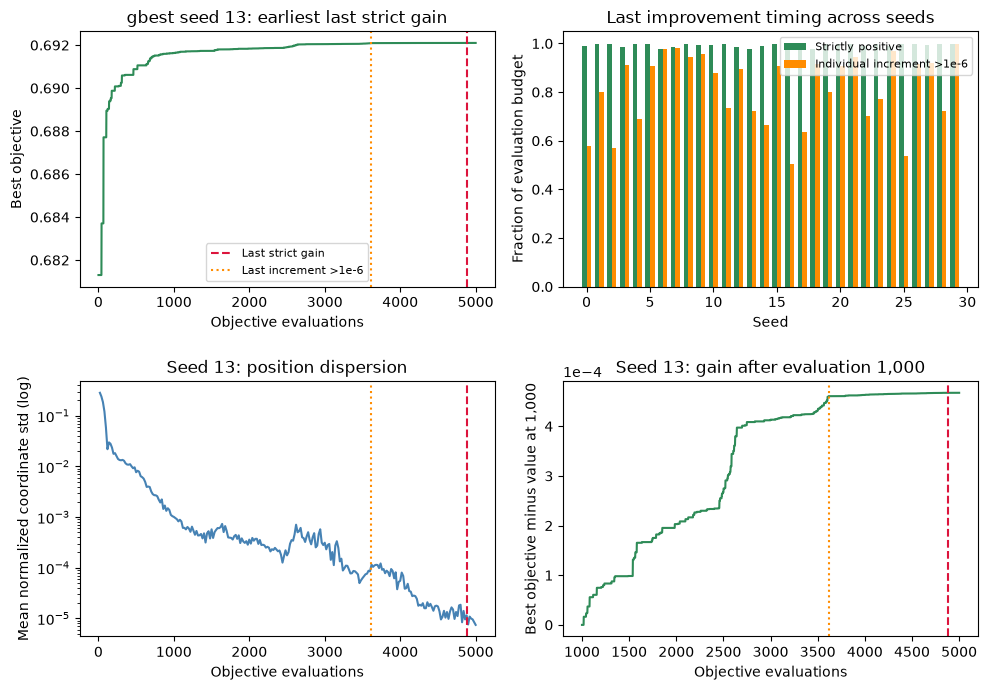

In [53]:
from types import SimpleNamespace
from tc6035.runlog import load_runset

stagnation_runs = load_runset("results/m2_pso_gbest.npz")
assert stagnation_runs.seeds == list(SEEDS)
assert stagnation_runs.meta["params"]["topology"] == "gbest"
assert all(stagnation_runs.meta["params"][key] == value for key,value in PSO_PARAMS.items())
assert all(m["evaluations_used"] == m["budget"] == len(b) == BUDGET
           for m,b in zip(stagnation_runs.meta["runs"],stagnation_runs.best_so_far))

STAGNATION_GAIN_THRESHOLD = 1e-6


def last_improvement_evaluation(best, threshold=0.0):
    improved = np.flatnonzero(np.diff(best) > threshold)
    # Evaluation 1 is the baseline if no subsequent gain clears the threshold.
    return int(improved[-1]+2) if improved.size else 1


assert last_improvement_evaluation(np.array([1.,1.,1.5,1.5,1.5000001])) == 5
assert last_improvement_evaluation(np.array([1.,1.,1.5,1.5,1.5000001]),1e-6) == 3
assert last_improvement_evaluation(np.ones(5)) == 1
stall_evaluations = np.array([last_improvement_evaluation(b) for b in stagnation_runs.best_so_far])
stall_fractions = stall_evaluations / BUDGET
earliest_stall = float(stall_fractions.min())
worst_seed = int(np.argmin(stall_fractions))
worst_seed_id = stagnation_runs.seeds[worst_seed]
threshold_evaluations = np.array([last_improvement_evaluation(b,STAGNATION_GAIN_THRESHOLD)
                                  for b in stagnation_runs.best_so_far])
threshold_fractions = threshold_evaluations / BUDGET
tail_gains_after_threshold = np.array([b[-1]-b[e-1]
                                      for b,e in zip(stagnation_runs.best_so_far,threshold_evaluations)])

# Reconstruct swarm positions using archived objective scores, not new objective calculations.
class RecordedScoreReplay:
    def __init__(self, instance, values):
        self.instance = instance
        self.values = values
        self.budget, self.evaluations_used = len(values), 0

    @property
    def evaluations_remaining(self):
        return self.budget-self.evaluations_used

    def evaluate_verbose(self, active, power):
        value = self.values[self.evaluations_used]
        self.evaluations_used += 1
        return SimpleNamespace(objective=float(value))


replay = RecordedScoreReplay(instance,stagnation_runs.values[worst_seed])
stagnation_state = pso(replay,worst_seed_id,pso_input_active[worst_seed],pso_input_power[worst_seed],
                       **PSO_PARAMS,return_details=True)
assert replay.evaluations_used == BUDGET
assert stagnation_state["score"] == stagnation_runs.best_values[worst_seed]
stagnation_history_evals = np.array([r["evaluation"] for r in stagnation_state["history"]])
stagnation_diversity = np.array([r["diversity"] for r in stagnation_state["history"]])
stagnation_speed = np.array([r["mean_speed"] for r in stagnation_state["history"]])
stagnation_history_best = np.array([r["best_score"] for r in stagnation_state["history"]])
assert np.array_equal(stagnation_history_best,
                      stagnation_runs.best_so_far[worst_seed][stagnation_history_evals-1])
assert np.all(np.isfinite(stagnation_diversity)) and np.all(stagnation_diversity>=0)

np.savez_compressed("results/m2_stagnation.npz",seeds=np.array(SEEDS),
                    last_improvement_evaluation=stall_evaluations,last_improvement_fraction=stall_fractions,
                    per_gain_threshold=np.array(STAGNATION_GAIN_THRESHOLD),
                    threshold_last_evaluation=threshold_evaluations,
                    gain_after_threshold_last=tail_gains_after_threshold,
                    earliest_stall=np.array(earliest_stall),selected_seed=np.array(worst_seed_id),
                    history_evaluations=stagnation_history_evals,
                    selected_seed_diversity=stagnation_diversity,selected_seed_speed=stagnation_speed)

summary = (
    "| Diagnostic | Observed value |\n|---|---:|\n"
    f"| Median last strictly positive improvement | {np.median(stall_evaluations):.0f} / {BUDGET} ({np.median(stall_fractions):.2%}) |\n"
    f"| Earliest last strictly positive improvement | {stall_evaluations[worst_seed]} / {BUDGET} ({earliest_stall:.2%}), seed {worst_seed_id} |\n"
    f"| Largest tail without any further improvement | {BUDGET-stall_evaluations[worst_seed]} evaluations ({1-earliest_stall:.2%}) |\n"
    f"| Median last individual gain above 1e-6 | {np.median(threshold_evaluations):.0f} / {BUDGET} ({np.median(threshold_fractions):.2%}) |\n"
    f"| Earliest last individual gain above 1e-6 | {threshold_evaluations.min()} / {BUDGET} ({threshold_fractions.min():.2%}) |\n"
    f"| Selected seed diversity: initialization to final generation | {stagnation_diversity[0]:.3e} to {stagnation_diversity[-1]:.3e} |\n"
    "| New sensor objective evaluations | 0 |\n"
)
display({"text/markdown":summary},raw=True)
print(f"earliest_stall={earliest_stall:.4f}; selected seed={worst_seed_id}.")
print("All 30 last strictly positive improvements occur after 97% of the budget.")
print("Threshold sensitivity counts individual increments above 1e-6, not cumulative gains or application value.")
print(f"For selected seed {worst_seed_id}, later cumulative gain after its last >1e-6 increment: "
      f"{tail_gains_after_threshold[worst_seed]:.9e}.")
print("Swarm states reconstructed from 5,000 recorded score lookups; sensor objective calculations: 0.")

seed_table="| Seed | Last strict gain | Budget fraction | Remaining calls | Last gain above 1e-6 |\n|---|---:|---:|---:|---:|\n"
for seed,e,f,t in zip(SEEDS,stall_evaluations,stall_fractions,threshold_evaluations):
    seed_table+=f"| {seed} | {e} | {f:.2%} | {BUDGET-e} | {t} |\n"
display({"text/markdown":seed_table},raw=True)

best=np.array(stagnation_runs.best_so_far[worst_seed])
evals=np.arange(1,BUDGET+1)
strict_marker=int(stall_evaluations[worst_seed])
threshold_marker=int(threshold_evaluations[worst_seed])
fig,axes=plt.subplots(2,2,figsize=(10,7))
axes[0,0].plot(evals,best,color="seagreen")
axes[0,0].axvline(strict_marker,ls="--",color="crimson",label="Last strict gain")
axes[0,0].axvline(threshold_marker,ls=":",color="darkorange",label="Last increment >1e-6")
axes[0,0].set(title=f"gbest seed {worst_seed_id}: earliest last strict gain",xlabel="Objective evaluations",ylabel="Best objective")
axes[0,0].legend(fontsize=8)
axes[0,1].bar(np.array(SEEDS)-.18,stall_fractions,width=.36,label="Strictly positive",color="seagreen")
axes[0,1].bar(np.array(SEEDS)+.18,threshold_fractions,width=.36,label="Individual increment >1e-6",color="darkorange")
axes[0,1].set(title="Last improvement timing across seeds",xlabel="Seed",ylabel="Fraction of evaluation budget",ylim=(0,1.05))
axes[0,1].legend(fontsize=8)
axes[1,0].sharex(axes[0,0])
axes[1,0].semilogy(stagnation_history_evals,np.maximum(stagnation_diversity,1e-16),color="steelblue")
axes[1,0].axvline(strict_marker,ls="--",color="crimson")
axes[1,0].axvline(threshold_marker,ls=":",color="darkorange")
axes[1,0].set(title=f"Seed {worst_seed_id}: position dispersion",xlabel="Objective evaluations",ylabel="Mean normalized coordinate std (log)")
tail=evals>=1000
axes[1,1].plot(evals[tail],best[tail]-best[999],color="seagreen")
axes[1,1].axvline(strict_marker,ls="--",color="crimson")
axes[1,1].axvline(threshold_marker,ls=":",color="darkorange")
axes[1,1].set(title=f"Seed {worst_seed_id}: gain after evaluation 1,000",xlabel="Objective evaluations",ylabel="Best objective minus value at 1,000")
axes[1,1].ticklabel_format(axis="y",style="sci",scilimits=(0,0))
fig.tight_layout()
Path("figures").mkdir(exist_ok=True)
fig.savefig("figures/m2_stagnation.png",dpi=120,bbox_inches="tight")
plt.show()


### Interpretation of improvement timing

All 30 gbest runs continued to record strictly positive improvements after 97% of the budget. The median last improvement occurred at evaluation 4982, or 99.64%. The earliest last improvement was evaluation 4,883 for seed 13, giving `earliest_stall` = 0.9766 and at most 117 subsequent evaluations without a further gain (2.34% of the budget). Under this strict criterion, the runs did not exhibit an early, completely flat best-so-far tail. They exhausted their budgets while small improvements were still occurring; this does not establish an optimum or guarantee that a larger budget would be worthwhile.

The sensitivity calculation qualifies that result. The median last individual increment above 1e−6 occurred at evaluation 4441, or 88.82%; the earliest was evaluation 2,529 (50.58%) for seed 16. Thus tiny late improvements should not be confused with equally large progress throughout the budget. For seed 13, the final single increment above 1e−6 occurred at evaluation 3,618, followed by a cumulative gain of approximately 6.803e-06. That total exceeds the per-increment threshold: several small advances can still add up.

Seed 13's normalized position dispersion falls from 2.836e-01 at initialization to 7.447e-06 at the final generation. The swarm increasingly concentrated, while the objective continued improving by smaller amounts. This supports a shift toward localized refinement, rather than proving that diversity loss caused stagnation or that convergence reached the optimum. Low diversity and a visually flat curve alone would have overstated the diagnosis.

If more resources were available, the marginal gains should be weighed against evaluation cost. Alternative topology, restart or diversity-preserving changes would require controlled comparisons; simply extending every run is not automatically justified. The earlier ring result provides evidence for one alternative topology, but not a causal demonstration that diversity explains its advantage. These diagnostics add zero sensor objective evaluations and leave existing optimization results unchanged.


## Supplementary ring improvement-timing analysis

The assignment explicitly requires this stagnation diagnostic for gbest. The same analysis is also applied to ring because its evaluated-score trajectories and swarm states are already saved; the extension requires no new objective evaluations. The primary gbest diagnostic and `earliest_stall` remain unchanged, while ring's corresponding value is stored separately as `ring_earliest_stall`.

Both topologies use the same 30 seeds, 5,000-evaluation budgets, strict positive-increment definition and supplementary per-increment threshold of 1e−6. The table compares their last-improvement timing, not a new optimization experiment or significance test. Ring dispersion is read directly from `results/m2_pso_ring_state.npz`, with its generation bests checked against the corresponding objective log; no recorded-score replay is needed for this extension.

The ring figure follows the same layout as the gbest diagnostic, selecting the seed whose last strict improvement occurred earliest. Each topology's selected example can therefore be a different seed. Their individual dispersion curves illustrate their own runs; they are not a matched-seed causal comparison of diversity. The 30-seed timing table provides the common-protocol summary.


| Diagnostic | gbest (required) | ring (supplementary) |
|---|---:|---:|
| Median last strict improvement | 99.64% | 99.58% |
| Earliest last strict improvement | 97.66% | 96.14% |
| Seed with earliest last strict improvement | 13 | 16 |
| Largest final tail without a further gain | 117 evaluations | 193 evaluations |
| Median last individual gain above 1e-6 | 88.82% | 99.27% |
| Earliest last individual gain above 1e-6 | 50.58% | 84.08% |
| New objective evaluations for these diagnostics | 0 | 0 |


ring_earliest_stall=0.9614; selected ring seed=16.
Selected ring seed last strict gain: 4807; last individual gain >1e-6: 4807.
Later cumulative gain after that threshold event: 0.000000000e+00.
Selected ring dispersion: 2.933019343e-01 to 1.602647783e-02.
Supplementary ring analysis uses saved scores and swarm states: no score replay and no new objective calculations.


| Ring seed | Last strict gain | Budget fraction | Remaining calls | Last increment >1e-6 |
|---|---:|---:|---:|---:|
| 0 | 4966 | 99.32% | 34 | 4707 |
| 1 | 4990 | 99.80% | 10 | 4990 |
| 2 | 4912 | 98.24% | 88 | 4831 |
| 3 | 4990 | 99.80% | 10 | 4990 |
| 4 | 4949 | 98.98% | 51 | 4949 |
| 5 | 4986 | 99.72% | 14 | 4986 |
| 6 | 4999 | 99.98% | 1 | 4999 |
| 7 | 4993 | 99.86% | 7 | 4993 |
| 8 | 4977 | 99.54% | 23 | 4977 |
| 9 | 4961 | 99.22% | 39 | 4961 |
| 10 | 4998 | 99.96% | 2 | 4921 |
| 11 | 4993 | 99.86% | 7 | 4773 |
| 12 | 4994 | 99.88% | 6 | 4833 |
| 13 | 4991 | 99.82% | 9 | 4991 |
| 14 | 4989 | 99.78% | 11 | 4989 |
| 15 | 4973 | 99.46% | 27 | 4973 |
| 16 | 4807 | 96.14% | 193 | 4807 |
| 17 | 4963 | 99.26% | 37 | 4204 |
| 18 | 4972 | 99.44% | 28 | 4972 |
| 19 | 4981 | 99.62% | 19 | 4981 |
| 20 | 4986 | 99.72% | 14 | 4966 |
| 21 | 4967 | 99.34% | 33 | 4928 |
| 22 | 4903 | 98.06% | 97 | 4903 |
| 23 | 4954 | 99.08% | 46 | 4754 |
| 24 | 4983 | 99.66% | 17 | 4983 |
| 25 | 4953 | 99.06% | 47 | 4814 |
| 26 | 4932 | 98.64% | 68 | 4932 |
| 27 | 4983 | 99.66% | 17 | 4983 |
| 28 | 4876 | 97.52% | 124 | 4876 |
| 29 | 4983 | 99.66% | 17 | 4983 |


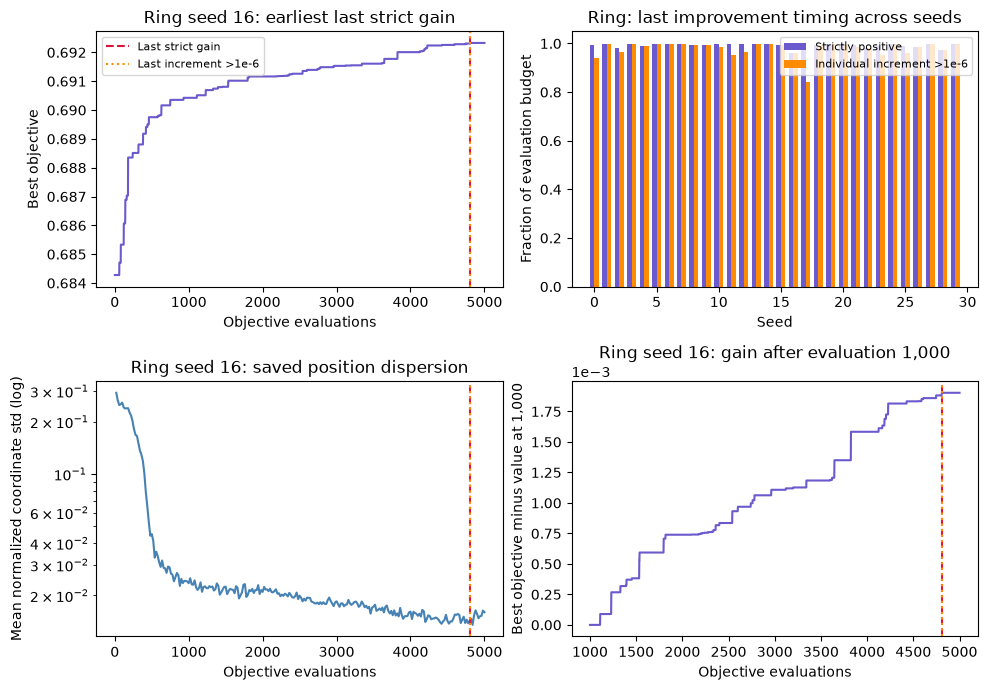

In [54]:
from tc6035.runlog import load_runset

ring_stall_runs = load_runset("results/m2_pso_ring.npz")
gbest_stall_runs = load_runset("results/m2_pso_gbest.npz")
assert ring_stall_runs.seeds == gbest_stall_runs.seeds == list(SEEDS)
assert all(m["budget"] == m["evaluations_used"] == len(b) == BUDGET
           for m,b in zip(ring_stall_runs.meta["runs"],ring_stall_runs.best_so_far))
ring_stall_evaluations = np.array([last_improvement_evaluation(b) for b in ring_stall_runs.best_so_far])
ring_stall_fractions = ring_stall_evaluations / BUDGET
ring_threshold_evaluations = np.array([last_improvement_evaluation(b,1e-6) for b in ring_stall_runs.best_so_far])
ring_threshold_fractions = ring_threshold_evaluations / BUDGET
ring_earliest_stall = float(ring_stall_fractions.min())
ring_worst_index = int(np.argmin(ring_stall_fractions))
ring_worst_seed = ring_stall_runs.seeds[ring_worst_index]
ring_tail_gains = np.array([b[-1]-b[e-1] for b,e in zip(ring_stall_runs.best_so_far,ring_threshold_evaluations)])
with np.load("results/m2_stagnation.npz",allow_pickle=False) as saved:
    gbest_stall_evaluations = saved["last_improvement_evaluation"].copy()
    gbest_threshold_evaluations = saved["threshold_last_evaluation"].copy()
    assert saved["seeds"].tolist() == list(SEEDS)
    assert float(saved["per_gain_threshold"]) == 1e-6
assert np.array_equal(gbest_stall_evaluations,
                      [last_improvement_evaluation(b) for b in gbest_stall_runs.best_so_far])
assert np.array_equal(gbest_threshold_evaluations,
                      [last_improvement_evaluation(b,1e-6) for b in gbest_stall_runs.best_so_far])

with np.load("results/m2_pso_ring_state.npz",allow_pickle=False) as state:
    assert state["seeds"].tolist() == list(SEEDS)
    for i,best in enumerate(ring_stall_runs.best_so_far):
        he = state[f"history_evaluation_{i}"].astype(int)
        assert he[0] == 20 and he[-1] == BUDGET and np.all(np.diff(he)>0)
        assert np.array_equal(state[f"history_best_score_{i}"],best[he-1])
        assert np.all(np.isfinite(state[f"history_diversity_{i}"]))
        assert np.all(state[f"history_diversity_{i}"]>=0)
    ring_history_evals = state[f"history_evaluation_{ring_worst_index}"].copy()
    ring_dispersion = state[f"history_diversity_{ring_worst_index}"].copy()
    ring_speed = state[f"history_mean_speed_{ring_worst_index}"].copy()

np.savez_compressed("results/m2_stagnation_ring.npz",seeds=np.array(SEEDS),
                    last_improvement_evaluation=ring_stall_evaluations,
                    last_improvement_fraction=ring_stall_fractions,per_gain_threshold=np.array(1e-6),
                    threshold_last_evaluation=ring_threshold_evaluations,
                    gain_after_threshold_last=ring_tail_gains,earliest_stall=np.array(ring_earliest_stall),
                    selected_seed=np.array(ring_worst_seed),history_evaluations=ring_history_evals,
                    selected_seed_diversity=ring_dispersion,selected_seed_speed=ring_speed)
comparison=("| Diagnostic | gbest (required) | ring (supplementary) |\n|---|---:|---:|\n"
            f"| Median last strict improvement | {np.median(gbest_stall_evaluations)/BUDGET:.2%} | {np.median(ring_stall_fractions):.2%} |\n"
            f"| Earliest last strict improvement | {gbest_stall_evaluations.min()/BUDGET:.2%} | {ring_earliest_stall:.2%} |\n"
            f"| Seed with earliest last strict improvement | {int(np.argmin(gbest_stall_evaluations))} | {ring_worst_seed} |\n"
            f"| Largest final tail without a further gain | {BUDGET-gbest_stall_evaluations.min()} evaluations | {BUDGET-ring_stall_evaluations.min()} evaluations |\n"
            f"| Median last individual gain above 1e-6 | {np.median(gbest_threshold_evaluations)/BUDGET:.2%} | {np.median(ring_threshold_fractions):.2%} |\n"
            f"| Earliest last individual gain above 1e-6 | {gbest_threshold_evaluations.min()/BUDGET:.2%} | {ring_threshold_fractions.min():.2%} |\n"
            "| New objective evaluations for these diagnostics | 0 | 0 |\n")
display({"text/markdown":comparison},raw=True)
print(f"ring_earliest_stall={ring_earliest_stall:.4f}; selected ring seed={ring_worst_seed}.")
print(f"Selected ring seed last strict gain: {ring_stall_evaluations[ring_worst_index]}; "
      f"last individual gain >1e-6: {ring_threshold_evaluations[ring_worst_index]}.")
print(f"Later cumulative gain after that threshold event: {ring_tail_gains[ring_worst_index]:.9e}.")
print(f"Selected ring dispersion: {ring_dispersion[0]:.9e} to {ring_dispersion[-1]:.9e}.")
print("Supplementary ring analysis uses saved scores and swarm states: no score replay and no new objective calculations.")
table="| Ring seed | Last strict gain | Budget fraction | Remaining calls | Last increment >1e-6 |\n|---|---:|---:|---:|---:|\n"
for seed,e,f,t in zip(SEEDS,ring_stall_evaluations,ring_stall_fractions,ring_threshold_evaluations):
    table+=f"| {seed} | {e} | {f:.2%} | {BUDGET-e} | {t} |\n"
display({"text/markdown":table},raw=True)

best=np.array(ring_stall_runs.best_so_far[ring_worst_index]);axis=np.arange(1,BUDGET+1)
strict_marker=int(ring_stall_evaluations[ring_worst_index])
threshold_marker=int(ring_threshold_evaluations[ring_worst_index])
fig,axes=plt.subplots(2,2,figsize=(10,7))
axes[0,0].plot(axis,best,color="slateblue")
axes[0,0].axvline(strict_marker,color="crimson",ls="--",label="Last strict gain")
axes[0,0].axvline(threshold_marker,color="darkorange",ls=":",label="Last increment >1e-6")
axes[0,0].set(title=f"Ring seed {ring_worst_seed}: earliest last strict gain",xlabel="Objective evaluations",ylabel="Best objective")
axes[0,0].legend(fontsize=8)
axes[0,1].bar(np.array(SEEDS)-.18,ring_stall_fractions,width=.36,color="slateblue",label="Strictly positive")
axes[0,1].bar(np.array(SEEDS)+.18,ring_threshold_fractions,width=.36,color="darkorange",label="Individual increment >1e-6")
axes[0,1].set(title="Ring: last improvement timing across seeds",xlabel="Seed",ylabel="Fraction of evaluation budget",ylim=(0,1.05))
axes[0,1].legend(fontsize=8)
axes[1,0].sharex(axes[0,0])
axes[1,0].semilogy(ring_history_evals,np.maximum(ring_dispersion,1e-16),color="steelblue")
axes[1,0].axvline(strict_marker,color="crimson",ls="--")
axes[1,0].axvline(threshold_marker,color="darkorange",ls=":")
axes[1,0].set(title=f"Ring seed {ring_worst_seed}: saved position dispersion",xlabel="Objective evaluations",ylabel="Mean normalized coordinate std (log)")
tail=axis>=1000
axes[1,1].plot(axis[tail],best[tail]-best[999],color="slateblue")
axes[1,1].axvline(strict_marker,color="crimson",ls="--")
axes[1,1].axvline(threshold_marker,color="darkorange",ls=":")
axes[1,1].set(title=f"Ring seed {ring_worst_seed}: gain after evaluation 1,000",xlabel="Objective evaluations",ylabel="Best objective minus value at 1,000")
axes[1,1].ticklabel_format(axis="y",style="sci",scilimits=(0,0))
fig.tight_layout()
Path("figures").mkdir(exist_ok=True)
fig.savefig("figures/m2_stagnation_ring.png",dpi=120,bbox_inches="tight")
plt.show()


### Ring results and comparison with gbest

Ring's median last strictly positive improvement occurs at evaluation 4979, or 99.58% of the budget. Its earliest last improvement occurs at evaluation 4,807 for seed 16, giving `ring_earliest_stall` = 0.9614 and a final no-gain tail of 193 evaluations (3.86%). Like gbest, ring therefore continues to register small improvements near the end rather than exhibiting a long, completely flat final best-so-far segment under the strict criterion.

The sensitivity calculation separates the topologies more clearly. Ring's median last individual increment above 1e−6 occurs at 99.27%, versus 88.82% for gbest; its earliest such event is at 84.08%, versus 50.58% for gbest. Thus increments exceeding this fixed descriptive threshold persist later in ring across the observed cohort. This does not imply that every ring run improves longer or that the threshold defines application value. The median strict-gain timing is slightly later for gbest (99.64%) than ring (99.58%), demonstrating that tiny late increments and larger increments describe different aspects of refinement.

In ring seed 16, the last single increment above 1e−6 occurs at evaluation 4807, followed by no further gain. Its strict and threshold markers coincide because both last-improvement definitions identify evaluation 4,807. Its normalized position dispersion falls from 2.933e-01 to 1.603e-02. The swarm concentrates while still making late progress; these observations alone neither establish an optimum nor show that diversity caused ring's final-score advantage.

The extension strengthens the description of both topologies using existing evidence. It adds zero objective evaluations and does not change the selected configuration, final scores, topology test or M2 budget accounting.


## Evaluation efficiency and budget allocation

The highest final objective identifies the best score within the reported budget. When evaluation cost also matters, a slightly lower score may be preferable if comparable quality is reached with substantially fewer evaluations. The remaining allowance could support refinement with another method, additional exploration or independent runs. This is a quality–cost trade-off, rather than a change to the objective function or evidence that either tested topology reaches an equivalent result in half the budget.

This comparison should measure the evaluations required to reach a predefined objective target, the fraction of runs that reach it, and the gains obtained over equal evaluation intervals. Comparable quality requires an explicit tolerance or target; visual proximity of convergence curves alone is insufficient. A method that reaches the target quickly in only a few seeds may be less reliable than its median trajectory suggests.

Falling diversity indicates that particle positions are becoming more similar. Small or infrequent objective gains indicate diminishing progress at the observed evaluation scale. Together these can motivate a stopping or switching rule, but they do not prove that no further improvement is possible. Diversity alone measures neither solution quality nor evaluation efficiency, and the current diagnostics show that small gains can persist after the curves appear nearly flat. Further exploitation of the same region is one option; whether it is preferable to a different search mechanism requires evidence.

For M3, these observations can inform a rule for distributing one shared budget between components. Such a rule should specify its gain window, quality tolerance and any diversity condition before evaluating its outcomes. A shorter first stage could release evaluations for the second, whose usefulness remains conditional on the first stage's solution. Savings would require applying and testing the stopping rule during the search; they cannot be claimed retrospectively by reducing the costs of already completed runs. No adaptive stopping rule or half-budget equivalence is established in the current experiments.


## ACO as sensor-subset construction

ACO searches the discrete layer at fixed, site-clipped M0 nominal powers. One ant builds one complete subset; it is not one sensor and it does not represent a route through the sites. Ten ants construct ten candidate subsets per iteration. Their shared memory is a pheromone value on each of the 80 candidate sites, rather than an edge between sites or a personal-best position.

Each ant starts with an empty subset and adds 15 distinct sensors, then stops. The construction size of 15 is a design choice based on the median number of active sensors in M1's retained tabu cohort, whose counts ranged from 13 to 17. It is not an optimal cardinality or a held-out tuning result. This restricts ACO to 15-sensor subsets, whereas tabu can vary the number of active sensors. Using prior M1 outcomes to define this choice makes the resulting comparison exploratory rather than independent validation of the construction size.

Powers are fixed at `min(NOMINAL_POWER, power_cap[j])`; ACO does not reuse tabu's selected sites or PSO's final powers. Coverage, energy, interference and connectivity still enter the complete objective. Disconnected constructed deployments are evaluated with their penalties and consume budget normally, rather than being discarded for free.


### Selecting the next sensor

At each addition, available sites are those not already selected. The heuristic is the weighted demand newly covered by adding a site to the current partial subset. It is recalculated after each choice by removing demand already covered. A sensor with high individual coverage may therefore become less attractive if previously chosen sites cover most of the same demand.

The construction probability is:

$$P(j\mid S)=\frac{\tau_j^{\alpha}\max(\eta(j\mid S),\epsilon)^{\beta}}{\sum_{k\notin S}\tau_k^{\alpha}\max(\eta(k\mid S),\epsilon)^{\beta}}.$$

- $S$: the subset already selected by this ant.
- $j$: an available candidate sensor; $k$ indexes available sensors in the denominator.
- $P(j\mid S)$: the probability of choosing sensor $j$ next.
- $\tau_j$: the current pheromone on site $j$, shared by the colony.
- $\eta(j\mid S)$: the weighted demand newly covered by adding $j$ to $S$.
- $\alpha$: the exponent controlling pheromone influence; initially 1.
- $\beta$: the exponent controlling marginal-coverage influence; initially 2.
- $\epsilon$: a positive heuristic floor, initially 1e−12, retaining a valid distribution when marginal gains are zero.

When every marginal gain is zero, the common floor makes selection depend on pheromone alone. With both exponents zero, selection is uniform over available sites. The denominator is normalized again after every addition. These geometry-based heuristic calculations do computational work, but do not calculate the full scalar objective. Only the complete 15-sensor deployment receives an objective evaluation.


### Evaporation, iteration-best deposit and bounds

All ants in one iteration construct their subsets using the same pheromone vector. After evaluating them, the subset with the highest objective in that iteration supplies the deposit. The best solution found over the entire run is stored separately for the returned result; it does not replace the iteration winner as the reinforcement source. Exact ties retain the first evaluated winner.

The update for site $j$ is:

$$\tau_j^{new}=\operatorname{clip}\left((1-\rho)\tau_j+\rho q(f_{best})I_j,\tau_{min},\tau_{max}\right),\qquad q(f)=\frac{1}{1+e^{-f}}.$$

- $\rho$: the evaporation fraction, initially 0.08; every site retains 92% of its previous pheromone before deposit.
- $f_{best}$: the objective of this iteration's best ant, including any infeasibility penalty.
- $q(f)$: a positive, increasing reward mapping, keeping deposits valid even when objectives are negative.
- $I_j$: 1 if site $j$ belongs to the iteration winner, otherwise 0.
- $\tau_{min}$ and $\tau_{max}$: the pheromone bounds, initially 0.02 and 1.
- $\tau_j^{new}$: the bounded pheromone used in the next iteration.

The positive reward mapping is an explicit implementation choice, not an additional objective or a change to winner selection. Raw penalized objectives still determine the winners and retained best. Pheromone starts at 1 on every site; bounds and coefficients are untuned. Reinforced sites can still decrease from their previous values when evaporation exceeds the deposit, while retaining an advantage over sites that only evaporate.

The bounds follow the MMAS principle of limiting reinforcement imbalance; they are not claimed to be theoretically optimal for this instance. Lower- and upper-bound clipping events are counted separately so their actual activity can be checked. A `bounded=False` option preserves all other rules for the M3 comparison; no unbounded final cohort is evaluated in M2.


### Initial ACO parameters and evaluation cost

The initial exponents, evaporation rate and colony size follow the course template: alpha = 1, beta = 2, rho = 0.08 and 10 ants. Construction size 15, pheromone initialization/bounds, heuristic floor and positive reward mapping are additional declared design choices. No ACO parameter pilot is performed.

Fifteen additions build one subset and cost one complete objective evaluation. Thus a full iteration costs 10 evaluations, and 5,000 evaluations allow 500 full iterations. There is no extra evaluation to initialize pheromones or return the already evaluated best subset. A final partial iteration uses only the ants that fit the remaining allowance. The engine also respects `problem.limited(...)` for a later hybrid sharing one budget.


In [55]:
from tc6035.runlog import load_runset

aco_tabu_reference = load_runset("results/m1_tabu.npz")
with np.load("results/m1_tabu_solutions.npz",allow_pickle=False) as saved:
    aco_reference_sizes = saved["active"].sum(axis=1)
    assert saved["seeds"].tolist() == aco_tabu_reference.seeds == list(SEEDS)
assert aco_tabu_reference.meta["student_id"] == STUDENT_ID
assert aco_tabu_reference.meta["params"]["salt"] == SALT
ACO_PARAMS={"alpha":1.0,"beta":2.0,"rho":0.08,"n_ants":10,"n_select":15,
            "nominal_power":float(aco_tabu_reference.meta["params"]["nominal_power"]),
            "tau_min":0.02,"tau_max":1.0,"tau_initial":1.0,"bounded":True,"heuristic_floor":1e-12}
assert int(np.median(aco_reference_sizes)) == ACO_PARAMS["n_select"]
print(f"Initial ACO settings (not tuned): {ACO_PARAMS}")
print(f"Construction size 15 is based on the M1 tabu median; observed subset-size range: {aco_reference_sizes.min()}–{aco_reference_sizes.max()}.")
print("Each ant constructs 15 distinct sensors at fixed powers; one complete ant costs one objective evaluation.")
print("alpha/beta/rho/ant count start from the course template; pheromone bounds and reward mapping are explicit design choices.")
print("Final protocol: 30 seeds, 5,000 ant evaluations per seed, 500 complete iterations of 10 ants.")


Initial ACO settings (not tuned): {'alpha': 1.0, 'beta': 2.0, 'rho': 0.08, 'n_ants': 10, 'n_select': 15, 'nominal_power': 20.0, 'tau_min': 0.02, 'tau_max': 1.0, 'tau_initial': 1.0, 'bounded': True, 'heuristic_floor': 1e-12}
Construction size 15 is based on the M1 tabu median; observed subset-size range: 13–17.
Each ant constructs 15 distinct sensors at fixed powers; one complete ant costs one objective evaluation.
alpha/beta/rho/ant count start from the course template; pheromone bounds and reward mapping are explicit design choices.
Final protocol: 30 seeds, 5,000 ant evaluations per seed, 500 complete iterations of 10 ants.


### Follow one ant and one pheromone update

The 20-evaluation seed-0 demonstration builds two iterations of 10 ants. The first table follows all 15 additions of the first ant: selected site, new demand coverage, cumulative demand coverage and selection probability. These additions are construction steps inside one candidate evaluation. An unselected site's changing marginal gain illustrates why the heuristic is conditional on the partial subset. The second table follows reinforcement for one selected and one unselected site. All sensor and ant indices start at zero; iteration/addition numbers start at one.


In [56]:
ACO_DEMO_BUDGET=20
aco_demo_problem=SensorPlacementProblem(instance,budget=ACO_DEMO_BUDGET,seed=0)
aco_demo=aco(aco_demo_problem,0,**ACO_PARAMS,trace_ants=1,trace_iterations=2,return_details=True)
assert aco_demo_problem.evaluations_used==aco_demo["evaluations_used"]==ACO_DEMO_BUDGET
ant=aco_demo["ant_traces"][0]
print("Actual sensor instance | seed 0 | first ant, first iteration (ant index 0).")
print("One ant is one complete 15-sensor subset; its intermediate additions are construction steps, not full objective evaluations.")
construction="| Addition | Selected sensor index | Marginal demand covered | Total demand covered | Selection probability | Available sites |\n|---|---:|---:|---:|---:|---:|\n"
for row in ant["steps"]:
    j=int(np.flatnonzero(row["available"]==row["chosen"])[0])
    construction+=(f"| {row['step']} | {row['chosen']} | {row['marginal']:.6f} | {row['coverage_after']:.6f} | "
                   f"{row['probabilities'][j]:.6f} | {len(row['available'])} |\n")
display({"text/markdown":construction},raw=True)
print(f"Complete constructed subset objective: {ant['score']:.9f}; charged at evaluation {ant['evaluation']}.")
first,second=ant["steps"][:2]
common=second["available"]
before=first["gains"][common]
decreases=before-second["gains"]
j=int(np.argmax(decreases));site=int(common[j])
print(f"Dynamic heuristic example, unselected sensor {site}: marginal coverage "
      f"{before[j]:.6f} -> {second['gains'][j]:.6f} after adding sensor {first['chosen']}.")
assert decreases[j]>0
update=aco_demo["pheromone_traces"][0]
selected=int(np.flatnonzero(update["active"])[0]);other=int(np.flatnonzero(~update["active"])[0])
pheromones="| Site | In iteration-best subset? | Before | After evaporation | Deposit | Before bounds | After bounds |\n|---|---|---:|---:|---:|---:|---:|\n"
for j in (selected,other):
    pheromones+=(f"| {j} | {bool(update['active'][j])} | {update['before'][j]:.6f} | {update['evaporated'][j]:.6f} | "
                 f"{update['deposit'][j]:.6f} | {update['raw'][j]:.6f} | {update['after'][j]:.6f} |\n")
display({"text/markdown":pheromones},raw=True)
print(f"Iteration 1 winner objective: {update['score']:.9f}; positive reward: {aco_reward(update['score']):.6f}.")
print("Every site evaporates; only the iteration winner's sites receive reinforcement. The global best is retained separately.")
print(f"Short validation cost: {ACO_DEMO_BUDGET} sensor evaluations, separate from the 30-seed study.")


Actual sensor instance | seed 0 | first ant, first iteration (ant index 0).
One ant is one complete 15-sensor subset; its intermediate additions are construction steps, not full objective evaluations.


| Addition | Selected sensor index | Marginal demand covered | Total demand covered | Selection probability | Available sites |
|---|---:|---:|---:|---:|---:|
| 1 | 58 | 0.138417 | 0.138417 | 0.024015 | 80 |
| 2 | 20 | 0.031681 | 0.170098 | 0.002213 | 79 |
| 3 | 0 | 0.194932 | 0.365030 | 0.084863 | 78 |
| 4 | 3 | 0.044718 | 0.409749 | 0.010116 | 77 |
| 5 | 69 | 0.025204 | 0.434953 | 0.004656 | 76 |
| 6 | 75 | 0.063198 | 0.498150 | 0.031550 | 75 |
| 7 | 59 | 0.077474 | 0.575625 | 0.113447 | 74 |
| 8 | 64 | 0.058849 | 0.634473 | 0.122365 | 73 |
| 9 | 33 | 0.077283 | 0.711757 | 0.262849 | 72 |
| 10 | 74 | 0.027534 | 0.739291 | 0.065776 | 71 |
| 11 | 53 | 0.010685 | 0.749975 | 0.014548 | 70 |
| 12 | 5 | 0.008379 | 0.758354 | 0.011279 | 69 |
| 13 | 60 | 0.012405 | 0.770759 | 0.028185 | 68 |
| 14 | 7 | 0.006372 | 0.777131 | 0.008915 | 67 |
| 15 | 36 | 0.020313 | 0.797444 | 0.091411 | 66 |


Complete constructed subset objective: 0.513520984; charged at evaluation 1.
Dynamic heuristic example, unselected sensor 32: marginal coverage 0.116734 -> 0.025488 after adding sensor 58.


| Site | In iteration-best subset? | Before | After evaporation | Deposit | Before bounds | After bounds |
|---|---|---:|---:|---:|---:|---:|
| 11 | True | 1.000000 | 0.920000 | 0.051309 | 0.971309 | 0.971309 |
| 0 | False | 1.000000 | 0.920000 | 0.000000 | 0.920000 | 0.920000 |


Iteration 1 winner objective: 0.581287203; positive reward: 0.641364.
Every site evaporates; only the iteration winner's sites receive reinforcement. The global best is retained separately.
Short validation cost: 20 sensor evaluations, separate from the 30-seed study.


### ACO implementation-check matrix

| Case | Expected behavior | Verified evidence |
|---|---|---|
| Complete subset | Each ant selects exactly 15 distinct sites at fixed powers. | All recorded deployments match the cardinality and nominal site-clipped power vector. |
| Marginal heuristic | Remove already covered demand after each addition. | Recorded gains are reconstructed independently; a known overlap example changes gains from [0.5, 0.8, 0.2] to [0.2, 0.2] after the second site is selected first. |
| Probabilities | Available-site probabilities sum to one and exclude prior choices. | Independent normalized weights match all short-run choices; probabilities remain valid for zero gains. |
| No heuristic/pheromone influence | Zero exponents give uniform available-site selection. | A controlled three-site distribution is exactly one third per site. |
| Evaporation/deposit | Evaporate all sites and deposit only on the iteration winner. | A known update gives [0.23, 0.36]; audited updates match the expected arithmetic. |
| Iteration/global separation | Reinforce the current iteration winner even when worse than the retained best. | Synthetic iteration winners [5, 2, 4] supply deposits while retained bests remain [5, 5, 5]. |
| Negative objectives | Deposits remain positive and valid. | Reward ordering is positive/increasing; an all-negative synthetic run retains objective −2 without invalid pheromones. |
| Ties | First iteration winner and earlier global solution remain on equal scores. | Constant-score synthetic ants preserve these rules. |
| Bounds | Clip entries below/above the interval. | A controlled update triggers both bounds; disabling bounds preserves the raw values. |
| Replay/returned best | Same seed reproduces scores; returned solution reproduces its stored score. | Audited trace matches the demonstration and a separate one-evaluation solution check. |
| Budget | Count one call per complete ant, including partial/shared stages. | Budgets 1, 7 and 13, including a final 3-ant iteration and a shared 13-call stage, match their limits. |
| Invalid input | Reject invalid sizes, coefficients, bounds or exhausted budgets before evaluation. | Validation cases consume zero objective calls. |

The demonstration uses 20 sensor evaluations and additional checks use 55. Synthetic score-sequence tests use 14 separate calls; direct numerical/heuristic checks make no objective calls. These costs are separate from the final 30-seed study.


In [57]:
from types import SimpleNamespace


class ACOAuditProblem(SensorPlacementProblem):
    def __init__(self,*args,**kwargs):
        super().__init__(*args,**kwargs)
        self.candidates_seen=[]

    def evaluate_verbose(self,active,power):
        self.candidates_seen.append((active.copy(),power.copy()))
        return super().evaluate_verbose(active,power)


def verify_aco(details,problem,params):
    power=np.minimum(params["nominal_power"],problem.instance.power_cap)
    coverage=problem.instance.dist_to_grid <= (problem.instance.spec.radius_coeff*np.sqrt(power))[:,None]
    assert details["ants_evaluated"] == details["evaluations_used"] == problem.evaluations_used
    assert len(details["ant_traces"]) == problem.evaluations_used
    assert all(a.sum()==params["n_select"] and np.array_equal(p,power) for a,p in problem.candidates_seen)
    assert details["score"] == max(problem.record.values)
    tau=np.full(problem.instance.n_candidates,params["tau_initial"])
    seen_best=float('-inf')
    start=0
    for history,update in zip(details["history"],details["pheromone_traces"]):
        count=history["ants"]
        scores=problem.record.values[start:start+count]
        winner=int(np.argmax(scores))
        expected_mask=problem.candidates_seen[start+winner][0]
        assert history["iteration_best"] == update["score"] == scores[winner]
        assert history["iteration_best_ant"] == winner
        assert np.array_equal(update["active"],expected_mask)
        subsets=set()
        for trace in details["ant_traces"][start:start+count]:
            selected=[];covered=np.zeros(coverage.shape[1],dtype=bool)
            for row in trace["steps"]:
                available=np.array([j for j in range(problem.instance.n_candidates) if j not in selected])
                gains=(coverage[available] & ~covered)*problem.instance.demand[None,:]
                gains=gains.sum(axis=1)
                weights=tau[available]**params["alpha"]*np.maximum(gains,params["heuristic_floor"])**params["beta"]
                probabilities=weights/weights.sum()
                assert np.array_equal(row["available"],available)
                assert np.allclose(row["gains"],gains,atol=1e-12,rtol=1e-10)
                assert np.allclose(row["probabilities"],probabilities,atol=1e-12)
                assert np.isclose(row["probabilities"].sum(),1)
                assert row["chosen"] in available
                assert np.isclose(row["coverage_before"],problem.instance.demand[covered].sum())
                selected.append(row["chosen"]);covered|=coverage[row["chosen"]]
                assert np.isclose(row["coverage_after"],problem.instance.demand[covered].sum())
            mask=np.zeros(problem.instance.n_candidates,dtype=bool);mask[selected]=True
            assert np.array_equal(mask,problem.candidates_seen[trace["evaluation"]-1][0])
            assert trace["score"]==problem.record.values[trace["evaluation"]-1]
            subsets.add(tuple(sorted(selected)))
        assert history["distinct_subsets"]==len(subsets)
        expected=(1-params["rho"])*tau
        expected[expected_mask]+=params["rho"]*aco_reward(scores[winner])
        assert np.allclose(update["raw"],expected)
        tau=np.clip(expected,params["tau_min"],params["tau_max"])
        assert np.allclose(update["after"],tau)
        assert update["lower_hits"]==int(np.sum(expected<params["tau_min"]))
        assert update["upper_hits"]==int(np.sum(expected>params["tau_max"]))
        seen_best=max(seen_best,max(scores))
        assert history["best_score"]==seen_best
        start+=count
    assert np.array_equal(details["pheromone"],tau)
    assert np.all(np.isfinite(details["pheromone_history"]))
    assert np.all((details["pheromone_history"]>=params["tau_min"]) & (details["pheromone_history"]<=params["tau_max"]))
    assert np.array_equal(problem.record.best_so_far,np.maximum.accumulate(problem.record.values))


aco_check_problems=[]
audited_aco_problem=ACOAuditProblem(instance,budget=20,seed=0)
audited_aco=aco(audited_aco_problem,0,**ACO_PARAMS,trace_ants=20,trace_iterations=20,return_details=True)
verify_aco(audited_aco,audited_aco_problem,ACO_PARAMS)
assert np.array_equal(audited_aco_problem.record.values,aco_demo_problem.record.values)
assert np.array_equal(audited_aco["active"],aco_demo["active"])
aco_check_problems.append(audited_aco_problem)
best_probe=SensorPlacementProblem(instance,budget=1,seed=0)
assert best_probe.evaluate(audited_aco["active"],audited_aco["power"])==audited_aco["score"]
aco_check_problems.append(best_probe)
for budget in (1,7,13):
    probe=ACOAuditProblem(instance,budget=budget,seed=23_000)
    details=aco(probe,23_000,**ACO_PARAMS,trace_ants=budget,trace_iterations=budget,return_details=True)
    verify_aco(details,probe,ACO_PARAMS)
    assert probe.evaluations_used==budget
    if budget==13:assert [h["ants"] for h in details["history"]]==[10,3]
    aco_check_problems.append(probe)
limited=ACOAuditProblem(instance,budget=20,seed=23_001)
with limited.limited(13):
    limited_result=aco(limited,23_001,**ACO_PARAMS,trace_ants=13,trace_iterations=13,return_details=True)
assert limited.evaluations_remaining==7
verify_aco(limited_result,limited,ACO_PARAMS)
aco_check_problems.append(limited)

# Known overlapping coverage validates marginal gains rather than static site scores.
toy_coverage=np.array([[1,1,0],[0,1,1],[1,0,0]],dtype=bool)
toy_weights=toy_coverage*np.array([.2,.3,.5])[None,:]
chosen,_,_,steps=construct_sensor_ant(np.random.default_rng(0),toy_coverage,toy_weights,np.ones(3),3,1.,2.,1e-12,True)
assert chosen[0]==1 and len(set(chosen))==3
assert np.allclose(steps[0]["gains"],[.5,.8,.2])
assert np.allclose(steps[1]["gains"],[.2,.2])
zero_prob=aco_choice_probabilities(np.array([1.,2.,3.]),np.zeros(3),np.arange(3),1.,2.,1e-12)
assert np.allclose(zero_prob,[1/6,2/6,3/6])
uniform=aco_choice_probabilities(np.array([1.,2.,3.]),np.array([.1,.8,.2]),np.arange(3),0.,0.,1e-12)
assert np.allclose(uniform,np.ones(3)/3)
known_update=update_site_pheromone(np.array([.2,.4]),np.array([True,False]),0.,.1,.02,1.,True)
assert np.allclose(known_update["after"],[.23,.36])
clipped=update_site_pheromone(np.array([.02,.5]),np.array([False,True]),2.,.5,.02,.5,True)
unbounded=update_site_pheromone(np.array([.02,.5]),np.array([False,True]),2.,.5,.02,.5,False)
assert np.array_equal(clipped["after"],[.02,.5])
assert clipped["lower_hits"]==clipped["upper_hits"]==1
assert np.array_equal(unbounded["after"],unbounded["raw"])
assert 0<aco_reward(-5)<aco_reward(0)<aco_reward(5)<1


class ACOSequenceProblem:
    def __init__(self,scores):
        self.instance=SimpleNamespace(n_candidates=4,power_cap=np.full(4,5.),
            spec=SimpleNamespace(power_min=1.,radius_coeff=1.),
            dist_to_grid=np.where(np.eye(4,dtype=bool),0.,10.),demand=np.array([.4,.3,.2,.1]))
        self.scores=scores;self.budget=len(scores);self.evaluations_used=0

    @property
    def evaluations_remaining(self):return self.budget-self.evaluations_used

    def evaluate_verbose(self,active,power):
        value=self.scores[self.evaluations_used];self.evaluations_used+=1
        return SimpleNamespace(objective=value)


sequence=aco(ACOSequenceProblem([5.,3.,2.,1.,4.,0.]),0,n_ants=2,n_select=2,nominal_power=2.,
             trace_ants=6,trace_iterations=3,return_details=True)
assert [h["iteration_best"] for h in sequence["history"]]==[5.,2.,4.]
assert [h["best_score"] for h in sequence["history"]]==[5.,5.,5.]
assert [t["score"] for t in sequence["pheromone_traces"]]==[5.,2.,4.]
ties=aco(ACOSequenceProblem([1.]*6),0,n_ants=2,n_select=2,nominal_power=2.,
         trace_ants=6,trace_iterations=3,return_details=True)
assert all(h["iteration_best_ant"]==0 for h in ties["history"])
assert np.array_equal(np.flatnonzero(ties["active"]),np.sort(ties["ant_traces"][0]["chosen"]))
negative=aco(ACOSequenceProblem([-4.,-2.]),0,n_ants=2,n_select=2,nominal_power=2.,return_details=True)
assert negative["score"]==-2. and np.all(negative["pheromone"]>0)

invalid=SensorPlacementProblem(instance,budget=1,seed=0)
for overrides in ({"n_select":0},{"n_select":81},{"n_ants":True},{"n_ants":1.5},
                  {"rho":0.},{"rho":1.},{"beta":-1.},{"alpha":np.nan},
                  {"tau_min":0.},{"tau_initial":2.},{"nominal_power":0.},{"bounded":"yes"}):
    try:aco(invalid,0,**{**ACO_PARAMS,**overrides})
    except ValueError:pass
    else:raise AssertionError(f"Invalid settings accepted: {overrides}")
assert invalid.evaluations_used==0
try:aco(SensorPlacementProblem(instance,budget=0,seed=0),0,**ACO_PARAMS)
except ValueError:pass
else:raise AssertionError("Empty budget accepted.")

ACO_CHECK_EVALUATIONS=sum(p.evaluations_used for p in aco_check_problems)
ACO_SYNTHETIC_EVALUATIONS=6+6+2
print("Passed: construction size/no repeats, dynamic marginal coverage, normalized probabilities and zero-gain fallback.")
print("Passed: iteration-best deposit, separate global retention, numerical evaporation/deposit, pheromone bounds and unbounded switch.")
print("Passed: negative rewards handled positively, deterministic ties/replay, fixed powers, returned best and exact partial/shared budgets.")
print(f"Separate sensor costs: demonstration={ACO_DEMO_BUDGET}, checks={ACO_CHECK_EVALUATIONS}.")
print(f"Synthetic objective calls={ACO_SYNTHETIC_EVALUATIONS}; not sensor experiment outcomes.")


Passed: construction size/no repeats, dynamic marginal coverage, normalized probabilities and zero-gain fallback.
Passed: iteration-best deposit, separate global retention, numerical evaporation/deposit, pheromone bounds and unbounded switch.
Passed: negative rewards handled positively, deterministic ties/replay, fixed powers, returned best and exact partial/shared budgets.
Separate sensor costs: demonstration=20, checks=55.
Synthetic objective calls=14; not sensor experiment outcomes.


### Final 30-seed ACO experiment

The declared configuration is evaluated on seeds 0–29, with exactly 5,000 objective calls per run. Saved records are checked against final scores and cumulative bests; returned subsets have 15 active sensors and fixed nominal powers. The cohort costs 150,000 evaluations. Seeds match the preceding algorithms, but no claim is made that their sampled proposals are element-by-element matched.

The run log, retained solutions and colony state are saved to `results/m2_aco.npz`, `results/m2_aco_solutions.npz` and `results/m2_aco_state.npz`. State includes pheromone trajectories, first-selection entropy, mean construction entropy, distinct activation subsets per iteration and lower/upper clipping counts. Subsets are counted by selected sites regardless of construction order.

Entropy uses natural logarithms: larger values indicate a more spread selection distribution, and zero indicates a deterministic choice. First-selection entropy measures the distribution over all 80 initial choices; mean construction entropy averages choices over the 15 additions and all ants. These are selection-distribution diagnostics, not objective scores. M3 will compare bounded/unbounded ACO using the same definitions, rather than inferring collapse from final objective alone.


In [58]:
from time import perf_counter
from tc6035.runlog import RunSet,save_runset,load_runset

aco_results,aco_records,aco_seconds=[],[],[]
for i,seed in enumerate(SEEDS):
    started=perf_counter()
    problem=SensorPlacementProblem(instance,budget=BUDGET,seed=seed)
    result=aco(problem,seed,**ACO_PARAMS,return_details=True)
    aco_seconds.append(perf_counter()-started)
    assert problem.evaluations_used==result["evaluations_used"]==result["ants_evaluated"]==BUDGET
    assert result["score"]==problem.record.best==max(problem.record.values)
    assert result["active"].sum()==ACO_PARAMS["n_select"]
    assert np.array_equal(result["power"],np.minimum(ACO_PARAMS["nominal_power"],instance.power_cap))
    assert sum(h["ants"] for h in result["history"])==BUDGET
    assert len(result["history"])==500
    assert np.all((result["pheromone_history"]>=ACO_PARAMS["tau_min"]) & (result["pheromone_history"]<=ACO_PARAMS["tau_max"]))
    aco_results.append(result);aco_records.append(problem.record)
    if (i+1)%5==0:
        print(f"ACO: {i+1}/{len(SEEDS)} runs complete; elapsed {sum(aco_seconds):.1f} seconds.",flush=True)
aco_scores=np.array([r["score"] for r in aco_results])
aco_traces=np.array([r.best_so_far for r in aco_records])
ACO_MEDIAN=float(np.median(aco_scores))
ACO_Q1,ACO_Q3=np.percentile(aco_scores,[25,75])
ACO_CONNECTED=sum(bool(r["result"].feasible) for r in aco_results)
ACO_FINAL_EVALUATIONS=sum(r.evaluations_used for r in aco_records)
save_runset("results/m2_aco.npz",RunSet(algorithm="aco",student_id=STUDENT_ID,
    params={**ACO_PARAMS,"salt":SALT,"scope":"fixed-cardinality subset construction; fixed nominal powers",
            "construction_size_source":"15; median count of M1 tabu cohort, not held-out cardinality tuning",
            "deposit":"iteration best; rho times sigmoid(objective)","heuristic":"remaining marginal weighted demand coverage"},
    records=aco_records))
roundtrip=load_runset("results/m2_aco.npz")
assert roundtrip.seeds==list(SEEDS) and np.array_equal(roundtrip.best_values,aco_scores)
assert all(np.array_equal(v,r.values) and np.array_equal(b,np.maximum.accumulate(v))
           for v,b,r in zip(roundtrip.values,roundtrip.best_so_far,aco_records))
np.savez_compressed("results/m2_aco_solutions.npz",seeds=np.array(SEEDS),
                    active=np.array([r["active"] for r in aco_results]),
                    power=np.array([r["power"] for r in aco_results]),score=aco_scores)
aco_state={"seeds":np.array(SEEDS)}
for i,r in enumerate(aco_results):
    aco_state[f"pheromone_{i}"]=r["pheromone_history"]
    for key in ("evaluation","iteration_best","best_score","first_choice_entropy","mean_choice_entropy",
                "distinct_subsets","lower_hits","upper_hits","fraction_at_min","fraction_at_max"):
        aco_state[f"{key}_{i}"]=np.array([h[key] for h in r["history"]])
np.savez_compressed("results/m2_aco_state.npz",**aco_state)
ACO_MEDIAN_LOWER_HITS=float(np.median([sum(h["lower_hits"] for h in r["history"]) for r in aco_results]))
ACO_MEDIAN_UPPER_HITS=float(np.median([sum(h["upper_hits"] for h in r["history"]) for r in aco_results]))
ACO_FINAL_ENTROPY=float(np.median([r["history"][-1]["first_choice_entropy"] for r in aco_results]))
ACO_FINAL_DISTINCT=float(np.median([r["history"][-1]["distinct_subsets"] for r in aco_results]))
M2_EVALUATION_ACCOUNTING={"topology_validation":394,"gbest_common_environment":150_000,
                          "ring_final_runs":150_000,"aco_demonstration":ACO_DEMO_BUDGET,
                          "aco_implementation_checks":ACO_CHECK_EVALUATIONS,"aco_final_runs":ACO_FINAL_EVALUATIONS}
print(f"ACO median={ACO_MEDIAN:.9f}; Q1–Q3=[{ACO_Q1:.9f},{ACO_Q3:.9f}]; connected retained bests={ACO_CONNECTED}/30.")
print(f"Median total lower/upper clipping events per run: {ACO_MEDIAN_LOWER_HITS:.0f}/{ACO_MEDIAN_UPPER_HITS:.0f}.")
print(f"Final-iteration median first-choice entropy={ACO_FINAL_ENTROPY:.6f} nats; distinct subsets={ACO_FINAL_DISTINCT:.1f}/10.")
print(f"Final ACO evaluations: {ACO_FINAL_EVALUATIONS:,}; M2 sensor evaluations so far: {sum(M2_EVALUATION_ACCOUNTING.values()):,}.")
print(f"M2 synthetic objective calls, separate: {15+ACO_SYNTHETIC_EVALUATIONS}.")
print("ACO results and colony diagnostics saved for the bounded/unbounded experiment in M3.")


ACO: 5/30 runs complete; elapsed 25.7 seconds.
ACO: 10/30 runs complete; elapsed 50.8 seconds.
ACO: 15/30 runs complete; elapsed 80.4 seconds.
ACO: 20/30 runs complete; elapsed 108.0 seconds.
ACO: 25/30 runs complete; elapsed 133.6 seconds.
ACO: 30/30 runs complete; elapsed 159.4 seconds.
ACO median=0.675569506; Q1–Q3=[0.673781926,0.676723788]; connected retained bests=30/30.
Median total lower/upper clipping events per run: 24535/0.
Final-iteration median first-choice entropy=2.367838 nats; distinct subsets=10.0/10.
Final ACO evaluations: 150,000; M2 sensor evaluations so far: 450,469.
M2 synthetic objective calls, separate: 29.
ACO results and colony diagnostics saved for the bounded/unbounded experiment in M3.


### ACO outcomes and colony diagnostics

The first panel reports median best-so-far objective and Q1–Q3 over evaluations; shading represents run variability, not confidence intervals. Other panels show one curve per seed for first-selection entropy, distinct subsets among each iteration's 10 ants, and the fraction of pheromone entries at the lower bound. Bound-event totals count entries clipped at each update; the same site may contribute repeatedly across iterations.


| Quantity | ACO result |
|---|---:|
| Final best objective, median | 0.675570 |
| Q1–Q3 | 0.673782–0.676724 |
| Connected retained bests | 30/30 |
| Sensors per subset / ants per iteration | 15 / 10 |
| Iterations / evaluations per run | 500 / 5,000 |
| Median lower-bound clipping events per run | 24535 |
| Median upper-bound clipping events per run | 0 |
| Median distinct subsets in final iteration | 10.0/10 |
| Final-run evaluations | 150,000 |


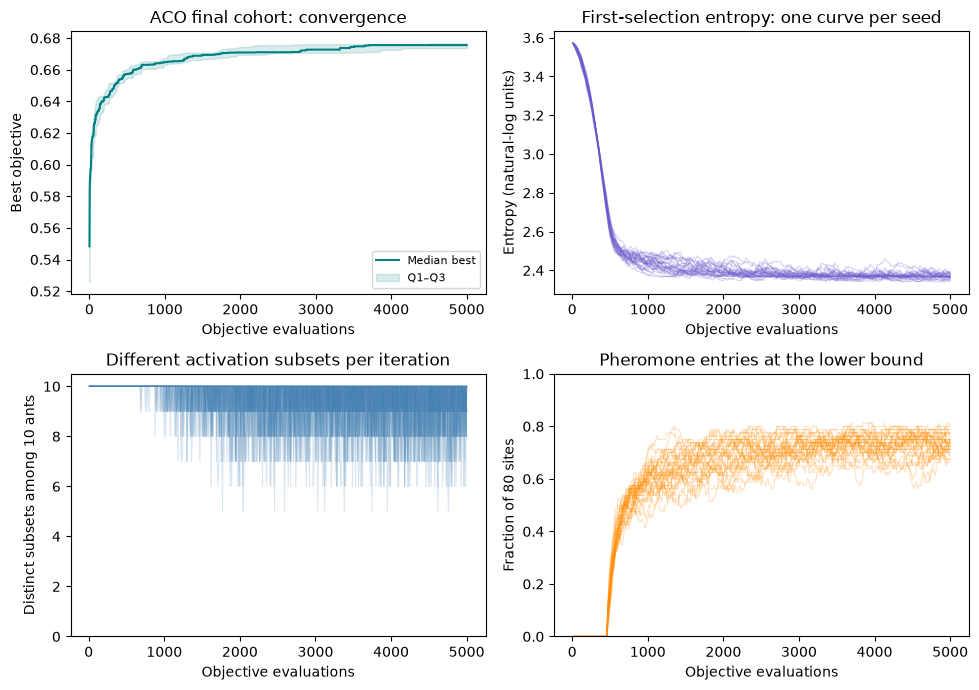

In [59]:
summary=("| Quantity | ACO result |\n|---|---:|\n"
         f"| Final best objective, median | {ACO_MEDIAN:.6f} |\n"
         f"| Q1–Q3 | {ACO_Q1:.6f}–{ACO_Q3:.6f} |\n"
         f"| Connected retained bests | {ACO_CONNECTED}/30 |\n"
         f"| Sensors per subset / ants per iteration | {ACO_PARAMS['n_select']} / {ACO_PARAMS['n_ants']} |\n"
         f"| Iterations / evaluations per run | 500 / {BUDGET:,} |\n"
         f"| Median lower-bound clipping events per run | {ACO_MEDIAN_LOWER_HITS:.0f} |\n"
         f"| Median upper-bound clipping events per run | {ACO_MEDIAN_UPPER_HITS:.0f} |\n"
         f"| Median distinct subsets in final iteration | {ACO_FINAL_DISTINCT:.1f}/10 |\n"
         f"| Final-run evaluations | {ACO_FINAL_EVALUATIONS:,} |\n")
display({"text/markdown":summary},raw=True)
q1,med,q3=np.percentile(aco_traces,[25,50,75],axis=0)
fig,axes=plt.subplots(2,2,figsize=(10,7))
axis=np.arange(1,BUDGET+1)
axes[0,0].plot(axis,med,color="teal",label="Median best")
axes[0,0].fill_between(axis,q1,q3,color="teal",alpha=.15,label="Q1–Q3")
axes[0,0].set(title="ACO final cohort: convergence",xlabel="Objective evaluations",ylabel="Best objective")
axes[0,0].legend(fontsize=8)
for r in aco_results:
    x=[h["evaluation"] for h in r["history"]]
    axes[0,1].plot(x,[h["first_choice_entropy"] for h in r["history"]],color="slateblue",alpha=.25,lw=.8)
    axes[1,0].plot(x,[h["distinct_subsets"] for h in r["history"]],color="steelblue",alpha=.2,lw=.8)
    axes[1,1].plot(x,[h["fraction_at_min"] for h in r["history"]],color="darkorange",alpha=.25,lw=.8)
axes[0,1].set(title="First-selection entropy: one curve per seed",xlabel="Objective evaluations",ylabel="Entropy (natural-log units)")
axes[1,0].set(title="Different activation subsets per iteration",xlabel="Objective evaluations",ylabel="Distinct subsets among 10 ants",ylim=(0,10.5))
axes[1,1].set(title="Pheromone entries at the lower bound",xlabel="Objective evaluations",ylabel="Fraction of 80 sites",ylim=(0,1))
fig.tight_layout()
Path("figures").mkdir(exist_ok=True)
fig.savefig("figures/m2_aco.png",dpi=120,bbox_inches="tight")
plt.show()


### Interpretation of ACO results

ACO reached median objective 0.675570, Q1–Q3 0.673782–0.676724, with 30/30 retained best deployments connected. Each run evaluated 5,000 complete 15-sensor subsets at fixed powers. These outcomes reflect both the construction mechanism and its fixed-cardinality/heuristic choices; they do not isolate pheromone memory or establish an optimal sensor count. The construction size came from M1's observed median, so it is not independently tuned on held-out ACO seeds.

The median total lower-bound clipping count was 24535 site-update events per run, while the upper-bound count was 0. The lower bound therefore actively prevents further decay at some sites; the upper cap does not need to be active for the lower floor to affect selection. This is direct evidence about which limit binds in this configuration, not proof of the score benefit or necessity of both limits. Because the reward is below 1 and pheromone starts at 1, the update cannot exceed 1: the upper cap is nonbinding by construction under these settings. The M3 ablation therefore primarily tests the lower floor.

Median first-selection entropy changed from 3.571266 in the initial iteration to 2.367838 at the final iteration. The median number of distinct subsets in the final iteration was 10.0/10. These quantities characterize concentration and construction variety; neither alone establishes that the best subset was found. Removing the bounds is expected to permit larger reinforcement imbalances, but whether that reduces entropy or distinct subsets here remains an empirical M3 question.

The geometric heuristic rewards newly covered demand but does not directly account for incremental energy, overlap penalties or connectivity. Those effects enter only when a complete subset is scored. This may limit construction quality even when the marginal heuristic is implemented correctly. Coefficients, bounds and cardinality remain untuned, and the fixed powers retain the coupling limitation discussed in M0/M1. The experiment and its diagnostics are preserved for a controlled bounded/unbounded comparison; no additional significance test or unmeasured improvement is claimed.

The narrow final-score interquartile range describes variability across runs; declining selection entropy describes concentration within searches. One does not establish the cause of the other. Ten distinct subsets in an iteration indicate no complete duplicates, but do not measure overlap between those subsets. The connectivity count refers to 30 retained deployments, each containing 15 sensors. ACO selects active sites from fixed candidate locations; PSO instead adjusts powers on a fixed selected subset. The lower pheromone floor preserves pheromone mass for rarely reinforced sites, while actual selection probabilities also depend on the heuristic. Its benefit requires the controlled M3 ablation.


## M2 analysis

M2 extends M1's PSO while preserving its coefficients, fixed subsets and stage budget. Ring reached median objective 0.701581 versus 0.699924 for gbest and won 22 of 30 paired seeds. Median and win count therefore agree. Wilcoxon gave p = 3.449582e−4 and rank-biserial effect −0.711828 for gbest minus ring. Both topologies were evaluated in the same runtime. These results favor ring for this configuration and instance, not universally. Global and neighborhood references impose different directional search biases; their usefulness depends on the landscape and budget. Earlier gbest improvement and later ring gains do not, by themselves, establish diversity as the causal mechanism.

With w = 0.7 and c1 = c2 = 1.4, phi = 2.8 lies below 2(1+w) = 3.4. The deterministic fixed-reference recurrence agrees: its displacement magnitude falls to approximately 3.05e−16 at step 200. This supports decay in the simplified model, not optimality or convergence of stochastic PSO with changing memories and clipping. Displacement tending to zero means approaching the reference, not setting sensor powers to zero.

The required gbest diagnostic found median last strict improvement at 99.64% of budget; even the earliest was at 97.66%, leaving 117 evaluations without another gain. Supplementary ring diagnostics, requiring no new evaluations, found corresponding values of 99.58% and 96.14%. Neither topology shows a long, completely flat final tail under that criterion. With an individual-gain threshold of 1e−6, median timing becomes 88.82% for gbest and 99.27% for ring. Shrinking dispersion therefore coexists with late refinement of differing sizes. Future stopping or switching rules should test evaluation cost against a defined quality target; concentration alone does not justify stopping.

ACO constructs 15-sensor subsets at fixed nominal powers using marginal coverage and site pheromones. Its median objective was 0.675570, with connected retained bests in all 30 runs. Fixed cardinality, derived from M1's median, and a coverage-only heuristic constrain this untuned search. The lower pheromone bound actively clipped a median 24,535 site-update events per run. The upper bound never clipped and is nonbinding by construction with the bounded positive reward. Median first-selection entropy decreased from 3.571266 to 2.367838, while the final iteration retained a median ten distinct subsets. This shows concentration without complete construction collapse. Removing the lower floor could increase reinforcement imbalance and reduce entropy or distinct subsets, but this remains an M3 hypothesis. The same diagnostics, not final objective alone, will test it.

Observed ACO plateaus motivate testing 20 ants × 250 iterations against 10 × 500, both costing 5,000 evaluations. More ants provide more constructions before each pheromone update, but fewer updates overall. A plateau in the retained global best does not make an iteration useless: the iteration winner still updates pheromones even without a historical improvement. This untested comparison should use the same 30 seeds, final quality and evaluations to a predefined quality target, with curves indexed by evaluations. Colony size alone does not remove the fixed-cardinality and heuristic restrictions.


## M2 status and preparation for M3

Topology comparison, deterministic stability, required gbest and supplementary ring stagnation diagnostics, and bounded ACO construction/validation/final experiments are complete. The ACO mechanism, outcomes and 350–500-word M2 analysis are ready to examine before moving to M3. Ring remains the preferred PSO topology among the tested configurations, with the M2 paired comparison as its evidence; its coefficients remain unchanged and untuned.

M3 will compare ACO with and without bounds using entropy and distinct subsets, then evaluate a justified hybrid under one shared budget and perform the global comparative study. The bounded ACO cohort and its saved state can be reused when settings remain identical. Fixed-cardinality ACO, fixed-power tabu and fixed-subset PSO have different restrictions; the final interpretation must preserve those scope and budget distinctions.

| Configuration passed to M3 | Value / evidence |
|---|---|
| Selected PSO topology | ring; higher median, 22/30 paired wins, Wilcoxon p = 3.449582e−4 in M2. |
| PSO coefficients / swarm | w = 0.7, c1 = c2 = 1.4; 20 particles; coefficients remain untuned. |
| PSO velocity cap / initial range | 0.2 / 0.1 of each coordinate interval; preserve the boundary rules. |
| ACO baseline | alpha = 1, beta = 2, rho = 0.08; 10 ants, 15 selected sites; fixed nominal powers. |
| ACO bounds / reward | tau_min = 0.02, tau_max = tau_initial = 1; rho times sigmoid(iteration-best objective). |
| ACO ablation switch | bounded=True versus bounded=False, with all other settings and seeds unchanged. |
| Existing evidence | m2_aco.npz, m2_aco_solutions.npz, m2_aco_state.npz; M2 topology, stability and stagnation logs/figures. |
| Hybrid budget requirement | One evaluator and one shared total budget; upstream subset selection must be charged. |


# M3


## Starting point from M2

Ring is carried forward with its measured 22/30 paired wins and Wilcoxon p = 3.449582e−4. Its coefficients remain untuned. The constants below restore M2 settings; this section does not require rerunning prior pilots. Seeds 3000–3029 tune the split; seeds 0–29 evaluate the frozen hybrid on the same instance. Historical outcomes exist for other methods on these final seeds, so this is not an untouched instance validation.

In [60]:
from tc6035.runlog import (RunSet, save_runset, load_runset,
                          environment_fingerprint)
from scipy.stats import friedmanchisquare, wilcoxon, rankdata
import hashlib
import inspect
import json

# Named M2 carry-forward values, restored from the actual saved configurations.
m3_prior_aco = load_runset("results/m2_aco.npz")
m3_prior_ring = load_runset("results/m2_pso_ring.npz")
M3_ACO_PARAMS = {k: m3_prior_aco.meta["params"][k] for k in
                ("alpha", "beta", "rho", "n_ants", "n_select", "nominal_power",
                 "tau_min", "tau_max", "tau_initial", "bounded", "heuristic_floor")}
M3_PSO_PARAMS = {k: m3_prior_ring.meta["params"][k] for k in
                ("topology", "swarm_size", "w", "c1", "c2",
                 "velocity_fraction", "initial_velocity_fraction")}
assert M3_PSO_PARAMS["topology"] == "ring"
assert (M3_PSO_PARAMS["w"], M3_PSO_PARAMS["c1"], M3_PSO_PARAMS["c2"]) == (.7, 1.4, 1.4)
assert M3_ACO_PARAMS["n_select"] == 15 and M3_ACO_PARAMS["bounded"]
for old in (m3_prior_aco, m3_prior_ring):
    assert old.meta["student_id"] == STUDENT_ID and old.meta["params"]["salt"] == SALT
M3_SPLITS = (.4, .6, .8)
M3_TUNING_SEEDS = tuple(range(3000, 3030))
M3_FINAL_SEEDS = tuple(SEEDS)
assert set(M3_TUNING_SEEDS).isdisjoint(M3_FINAL_SEEDS)
assert len(M3_TUNING_SEEDS) == len(M3_FINAL_SEEDS) == 30
M3_EVALUATION_ACCOUNTING = {"development_failed_validation": 277,
                            "checkpoint_validation": 20}
print("M2 carry-forward:", M3_PSO_PARAMS)
print("Selection evidence: ring won 22/30 pairs; Wilcoxon p=3.449582e-4.")
print("Grid: splits", M3_SPLITS, "; tuning seeds 3000–3029; final seeds 0–29.")
print("Prior ACO environment:", m3_prior_aco.meta["environment"])
print("Current environment:", environment_fingerprint())


M2 carry-forward: {'topology': 'ring', 'swarm_size': 20, 'w': 0.7, 'c1': 1.4, 'c2': 1.4, 'velocity_fraction': 0.2, 'initial_velocity_fraction': 0.1}
Selection evidence: ring won 22/30 pairs; Wilcoxon p=3.449582e-4.
Grid: splits (0.4, 0.6, 0.8) ; tuning seeds 3000–3029; final seeds 0–29.
Prior ACO environment: {'python': '3.13.2', 'platform': 'Windows-11-10.0.26200-SP0', 'machine': 'AMD64', 'packages': {'numpy': '2.5.4', 'scipy': '1.18.1'}, 'threading': {'OMP_NUM_THREADS': None, 'OPENBLAS_NUM_THREADS': None, 'MKL_NUM_THREADS': None, 'NUMEXPR_NUM_THREADS': None, 'VECLIB_MAXIMUM_THREADS': None}, 'pythonhashseed': None}
Current environment: {'python': '3.13.2', 'platform': 'Windows-11-10.0.26200-SP0', 'machine': 'AMD64', 'packages': {'numpy': '2.5.4', 'scipy': '1.18.1'}, 'threading': {'OMP_NUM_THREADS': None, 'OPENBLAS_NUM_THREADS': None, 'MKL_NUM_THREADS': None, 'NUMEXPR_NUM_THREADS': None, 'VECLIB_MAXIMUM_THREADS': None}, 'pythonhashseed': None}


## ACO bounds: protocol stated before results

Compare identical ACO configurations with and without pheromone clipping. Track normalized-pheromone entropy and actual first-choice entropy separately, plus distinct subsets per iteration. Both cohorts run in the current environment, explicitly charging 300,000 calls; M2 is preserved as historical evidence. The upper cap is nonbinding under this update. A floor may change selection without improving quality or causing the unbounded colony to collapse. These are questions, not predetermined outcomes.

## Hybrid rationale and split grid — declared before results

ACO constructs a subset at nominal powers; ring PSO adapts powers to that subset. The staged design addresses both layers but cannot revisit site selection during PSO. A larger selection allowance may improve the subset while leaving less time for power adjustment.

| Split | ACO evaluations | PSO evaluations |
|---|---:|---:|
| 0.4 | 2,000 | 3,000 |
| 0.6 | 3,000 | 2,000 |
| 0.8 | 4,000 | 1,000 |

Compare all three over the same 30 tuning seeds with 5,000 calls each. Select the largest final-score median; ties at 12 decimals favor lower IQR, then proximity to 0.6, then smaller split. Report Friedman, three Wilcoxon comparisons with Holm and signed effects to describe evidence, without equating selection with proven superiority. Freeze the split before final runs. Pilot cost: 450,000 calls, separately reported. The stage handoff reevaluates the incoming deployment within PSO's allowance; preserving it guarantees no loss from the handoff, not a gain over full-budget ACO or SA.

## Implementation validation

| Case | Independent evidence |
|---|---|
| Transfer | The first PSO proposal exactly matches ACO's retained deployment. |
| Shared counter | Three splits, partial iterations and a nested limited stage consume exactly their allowance. |
| Fixed subset and bounds | Audit every PSO proposal's activations and individual power limits. |
| Best retention | Recorded best equals the cumulative maximum of all proposals. |
| Replay | Same seeded run reproduces all evaluated objectives. |
| Invalid split | Empty stages and invalid fractions are rejected before evaluation. |
| Bounds ablation | Before clipping, paired runs agree; a controlled floor case changes only clipping. |

Short-run objectives below verify mechanics and are not final performance estimates.

In [61]:
class M3AuditProblem(SensorPlacementProblem):
    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.proposals = []
    def evaluate_verbose(self, active, power):
        self.proposals.append((active.copy(), power.copy()))
        return super().evaluate_verbose(active, power)


m3_validation_cost = 0
demo_rows = []
for split in M3_SPLITS:
    prob = M3AuditProblem(instance, budget=51, seed=3100)
    result = hybrid(prob, 3100, split, M3_ACO_PARAMS, M3_PSO_PARAMS, True)
    k = result["switch_evaluation"]
    assert prob.evaluations_used == len(prob.record.values) == len(prob.proposals) == 51
    assert k == int(51 * split) and prob.budget == 51
    assert np.array_equal(prob.record.best_so_far, np.maximum.accumulate(prob.record.values))
    assert result["score"] == max(prob.record.values)
    active, power = prob.proposals[k]
    assert np.array_equal(active, result["selection"]["active"])
    assert np.array_equal(power, result["selection"]["power"])
    assert prob.record.values[k] == result["selection"]["score"]
    assert all(np.array_equal(a, active) for a, p in prob.proposals[k:])
    assert all(np.all((p >= spec.power_min) & (p <= instance.power_cap))
               for a, p in prob.proposals)
    demo_rows.append((split, k, 51-k, result["selection"]["score"], result["score"]))
    m3_validation_cost += prob.evaluations_used

# Exact seeded replay; smallest split stages; a pre-used evaluator and temporary outer cap.
replay = SensorPlacementProblem(instance, budget=51, seed=3100)
replayed = hybrid(replay, 3100, .8, M3_ACO_PARAMS, M3_PSO_PARAMS, True)
assert np.array_equal(replay.record.values, prob.record.values)
m3_validation_cost += replay.evaluations_used
tiny = SensorPlacementProblem(instance, budget=3, seed=3101)
hybrid(tiny, 3101, .5, M3_ACO_PARAMS, M3_PSO_PARAMS)
assert tiny.evaluations_used == 3
m3_validation_cost += tiny.evaluations_used
nested = SensorPlacementProblem(instance, budget=70, seed=3102)
nested.evaluate_verbose(result["active"], result["power"])
with nested.limited(59):
    nested_result = hybrid(nested, 3102, .6, M3_ACO_PARAMS, M3_PSO_PARAMS, True)
    assert nested.evaluations_used == 60 and nested.evaluations_remaining == 0
assert nested.budget == 70 and nested.evaluations_remaining == 10
assert nested_result["selection_evaluations"] == int(59*.6)
m3_validation_cost += nested.evaluations_used
invalid = SensorPlacementProblem(instance, budget=10, seed=3103)
for split in (0, 1, -.1, np.nan, True, .001):
    try:
        hybrid(invalid, 3103, split, M3_ACO_PARAMS, M3_PSO_PARAMS)
    except ValueError:
        pass
    else:
        raise AssertionError("Invalid or empty stage accepted")
assert invalid.evaluations_used == 0

# Bounds only affect clipping: identical trajectories before the floor is reached.
paired_checks = []
for bounded in (True, False):
    q = SensorPlacementProblem(instance, budget=60, seed=3104)
    details = aco(q, 3104, **{**M3_ACO_PARAMS, "bounded": bounded}, return_details=True)
    paired_checks.append((q, details))
    m3_validation_cost += q.evaluations_used
assert np.array_equal(paired_checks[0][0].record.values, paired_checks[1][0].record.values)
tau = np.full(instance.n_candidates, .02)
mask = np.zeros(instance.n_candidates, dtype=bool); mask[:15] = True
bound_update = update_site_pheromone(tau, mask, .6, .08, .02, 1., True)
free_update = update_site_pheromone(tau, mask, .6, .08, .02, 1., False)
assert np.array_equal(bound_update["raw"], free_update["raw"])
assert np.all(bound_update["after"][~mask] == .02)
assert np.all(free_update["after"][~mask] < .02)
M3_EVALUATION_ACCOUNTING["implementation_validation"] = m3_validation_cost
display({"text/markdown": "| Split | ACO calls | PSO calls | ACO best | Final best |\n"
         "|---:|---:|---:|---:|---:|\n" + "\n".join(
             f"| {s:.1f} | {a} | {p} | {x:.6f} | {y:.6f} |" for s,a,p,x,y in demo_rows)}, raw=True)
print("All transfer, shared-budget, replay, partial-stage and bounds checks passed.")
print("New sensor evaluations for validation:", m3_validation_cost)


| Split | ACO calls | PSO calls | ACO best | Final best |
|---:|---:|---:|---:|---:|
| 0.4 | 20 | 31 | 0.589254 | 0.591085 |
| 0.6 | 30 | 21 | 0.589254 | 0.591085 |
| 0.8 | 40 | 11 | 0.620793 | 0.620793 |

All transfer, shared-budget, replay, partial-stage and bounds checks passed.
New sensor evaluations for validation: 387


In [62]:
def m3_entropy(tau):
    """Entropy (nats) of normalized pheromone mass, not construction probabilities."""
    tau = np.asarray(tau, dtype=float)
    assert np.all(np.isfinite(tau)) and np.all(tau >= 0)
    total = tau.sum(axis=-1, keepdims=True)
    if np.any(total <= 0):
        raise ValueError("Zero pheromone mass; cannot define normalized entropy.")
    p = tau / total
    return -np.sum(p * np.log(np.maximum(p, np.finfo(float).tiny)), axis=-1)


def m3_paired_statistics(score_columns):
    names = list(score_columns)
    columns = [np.asarray(score_columns[n]) for n in names]
    assert len(columns) >= 3 and all(x.shape == columns[0].shape for x in columns)
    assert all(np.all(np.isfinite(x)) for x in columns)
    if all(np.array_equal(columns[0], x) for x in columns[1:]):
        f_stat, f_p = 0., 1.
    else:
        f_stat, f_p = map(float, friedmanchisquare(*columns))
    from itertools import combinations
    pairs = list(combinations(names, 2))
    raw, effects, differences = {}, {}, {}
    for a,b in pairs:
        d = np.asarray(score_columns[a])-np.asarray(score_columns[b])
        ranked_d = np.round(d, 12)
        nonzero = ranked_d[ranked_d != 0]
        raw[a,b] = float(wilcoxon(ranked_d, alternative="two-sided",
                                  zero_method="wilcox", method="auto").pvalue) if nonzero.size else 1.
        r = rankdata(abs(nonzero))
        effects[a,b] = float(np.sum(r*np.sign(nonzero))/r.sum()) if nonzero.size else 0.
        differences[a,b] = float(np.median(d))
    adjusted, running = {}, 0.
    for i,pair in enumerate(sorted(pairs, key=lambda p: raw[p])):
        running = max(running, min(1., (len(pairs)-i)*raw[pair]))
        adjusted[pair] = running
    return {"friedman_stat": f_stat, "friedman_p": f_p, "raw_p": raw,
            "holm_adjusted": adjusted, "effects": effects, "median_differences": differences,
            "n_significant": sum(p < .05 for p in adjusted.values())}


def m3_run_cohort(label, seeds, algorithm, params):
    """Checkpoint each full run; validate its protocol before any reuse."""
    from tc6035.problem import RunRecord
    root = Path("results/m3_checkpoints") / label
    root.mkdir(parents=True, exist_ok=True)
    protocol = {"version": 1, "student_id": STUDENT_ID, "salt": SALT,
                "budget": BUDGET, "algorithm": algorithm, "params": params,
                "environment": environment_fingerprint(),
                "implementation_sha256": hashlib.sha256("\n".join(inspect.getsource(f) for f in
                    (aco_choice_probabilities, construct_sensor_ant, update_site_pheromone,
                     aco_reward, aco, pso_step, ring_social_targets, pso, hybrid)).encode()).hexdigest(),
                "instance_sha256": hashlib.sha256(b"".join(np.ascontiguousarray(x).tobytes()
                    for x in (instance.candidates, instance.power_cap, instance.grid_points,
                              instance.demand))).hexdigest()}
    manifest = root / "protocol.json"
    encoded = json.dumps(protocol, sort_keys=True, indent=2)
    if manifest.exists():
        if manifest.read_text(encoding="utf-8") != encoded:
            raise ValueError(f"Protocol changed for {label}; use a new cohort label.")
    else:
        manifest.write_text(encoded, encoding="utf-8")
    records, summaries = [], []
    for seed in seeds:
        path = root / f"seed_{seed}.npz"
        if path.exists():
            with np.load(path, allow_pickle=False) as z:
                values, best = z["values"].copy(), z["best"].copy()
                summary = json.loads(str(z["summary"]))
            assert summary["seed"] == seed
        else:
            prob = SensorPlacementProblem(instance, budget=BUDGET, seed=seed)
            result = (hybrid if algorithm == "hybrid" else aco)(prob, seed, **params, return_details=True)
            values, best = np.array(prob.record.values), np.array(prob.record.best_so_far)
            summary = {"seed": seed, "score": result["score"], "connected": bool(result["result"].feasible)}
            arrays = {"active": result["active"], "power": result["power"]}
            stages = {"aco": result} if algorithm == "aco" else {
                "aco": result["selection"], "pso": result["adjustment"]}
            if algorithm == "hybrid":
                summary.update(switch=result["switch_evaluation"],
                               selection_score=result["selection"]["score"])
            for stage, detail in stages.items():
                for key in detail["history"][0]:
                    arrays[f"{stage}_{key}"] = np.array([h[key] for h in detail["history"]])
            arrays["pheromone"] = stages["aco"]["pheromone_history"]
            temp = path.with_suffix(".partial.npz")
            np.savez_compressed(temp, values=values, best=best,
                                summary=json.dumps(summary), **arrays)
            temp.replace(path)
            print(f"{label}: seed {seed} saved", flush=True)
        assert len(values) == len(best) == BUDGET
        assert np.array_equal(best, np.maximum.accumulate(values))
        assert summary["score"] == best[-1]
        record = RunRecord(instance_id=STUDENT_ID, seed=seed, budget=BUDGET)
        record.values = values.tolist()
        record.best_so_far = best.tolist()
        records.append(record); summaries.append(summary)
    save_runset(f"results/{label}.npz", RunSet(algorithm=algorithm, student_id=STUDENT_ID,
        params={**params, "salt": SALT, "protocol": protocol}, records=records))
    return np.array([s["score"] for s in summaries]), summaries


def m3_plot_scores(columns, filename):
    fig, ax = plt.subplots(figsize=(7,4))
    ax.boxplot(list(columns.values()), tick_labels=list(columns), showfliers=True)
    ax.set(ylabel="Final objective", title="30 paired seeds; 5,000 evaluations per run")
    fig.tight_layout(); Path("figures").mkdir(exist_ok=True)
    fig.savefig(f"figures/{filename}", dpi=150)
    plt.show()


## Bounds experiment

The following cell runs 60 full ACO runs and saves per-seed checkpoints. Matching checkpoints are reused; a changed protocol stops execution. Each stored run belongs to its study cost even when loaded rather than recomputed.

In [63]:
# Run both configurations in the same runtime; M2 logs remain unchanged.
# Fresh bounded calls are explicitly charged; no exact environment match is assumed.
m3_bounds_scores = {}
for label, bounded in (("bounded", True), ("unbounded", False)):
    scores, _ = m3_run_cohort(f"m3_aco_{label}", M3_FINAL_SEEDS, "aco",
                             {**M3_ACO_PARAMS, "bounded": bounded})
    m3_bounds_scores[label] = scores
    M3_EVALUATION_ACCOUNTING[f"aco_{label}"] = BUDGET*len(M3_FINAL_SEEDS)

m3_bounds_diagnostics = {}
for label in ("bounded", "unbounded"):
    traces = {k: [] for k in ("pheromone_entropy", "first_choice_entropy", "distinct", "ratio")}
    for seed in M3_FINAL_SEEDS:
        with np.load(f"results/m3_checkpoints/m3_aco_{label}/seed_{seed}.npz", allow_pickle=False) as z:
            tau = z["pheromone"]
            # Construction probabilities use tau BEFORE the current iteration update.
            traces["pheromone_entropy"].append(m3_entropy(tau[:-1]))
            traces["first_choice_entropy"].append(z["aco_first_choice_entropy"])
            traces["distinct"].append(z["aco_distinct_subsets"])
            traces["ratio"].append(np.divide(tau[1:].max(axis=1), tau[1:].min(axis=1),
                out=np.full(len(tau)-1, np.inf), where=tau[1:].min(axis=1)>0))
    m3_bounds_diagnostics[label] = {k: np.array(v) for k,v in traces.items()}
entropy_bounded = float(np.median(m3_bounds_diagnostics["bounded"]["pheromone_entropy"][:,-1]))
entropy_unbounded = float(np.median(m3_bounds_diagnostics["unbounded"]["pheromone_entropy"][:,-1]))
distinct_bounded = float(np.median(m3_bounds_diagnostics["bounded"]["distinct"][:,-1]))
distinct_unbounded = float(np.median(m3_bounds_diagnostics["unbounded"]["distinct"][:,-1]))
ratio_unbounded = float(np.median(m3_bounds_diagnostics["unbounded"]["ratio"][:,-1]))
fig, axes = plt.subplots(1,3,figsize=(13,4))
for label, data in m3_bounds_diagnostics.items():
    for ax,key in zip(axes,("pheromone_entropy", "first_choice_entropy", "distinct")):
        q1, med, q3 = np.percentile(data[key], [25,50,75], axis=0)
        x = np.arange(1,len(med)+1)*M3_ACO_PARAMS["n_ants"]
        ax.plot(x, med, label=label); ax.fill_between(x,q1,q3,alpha=.18)
        ax.set(xlabel="Objective evaluations", ylabel=key.replace("_", " "))
        ax.legend()
fig.tight_layout(); Path("figures").mkdir(exist_ok=True)
fig.savefig("figures/m3_bounds.png",dpi=150); plt.show()
print("Final median normalized-pheromone entropy (nats):", entropy_bounded, entropy_unbounded)
print("Final median distinct subsets:", distinct_bounded, distinct_unbounded)
print("Unbounded final median max/min ratio:", ratio_unbounded)
print("These are observed diagnostics; no collapse or benefit is assumed in advance.")


ValueError: Protocol changed for m3_aco_bounded; use a new cohort label.

### Bounds results and mechanism

The final median entropy of normalized pheromone mass was 3.300854 nats with bounds and 2.708050 without; the median final number of distinct subsets per iteration was 10 versus 1. Without clipping, reinforcement concentrated pheromone on a 15-site set. A single constructed subset does not require zero pheromone entropy: pheromone mass can remain distributed across its 15 members, and ants may select them in different orders. The subset diagnostic therefore exposes collapse that an entropy value alone would not establish.

This comparison changes only clipping in otherwise identical configurations and seeds. Under this update the upper cap is nonbinding, so the active intervention is the lower floor. The observed difference supports retaining that floor to preserve construction diversity in this configuration. The final median objective was 0.675570 with bounds and 0.673056 without; those descriptive scores do not by themselves establish a statistically supported quality advantage or universal benefit.


## Split grid execution

This cell runs 90 full hybrid tuning runs. The selection record freezes the chosen split; the three candidates cost 450,000 objective calls in total.

| Split | Median | Q1 | Q3 | Connected |
|---:|---:|---:|---:|---:|
| 0.4 | 0.704034 | 0.700923 | 0.706659 | 30/30 |
| 0.6 | 0.703777 | 0.702182 | 0.705546 | 30/30 |
| 0.8 | 0.701204 | 0.699113 | 0.702648 | 30/30 |

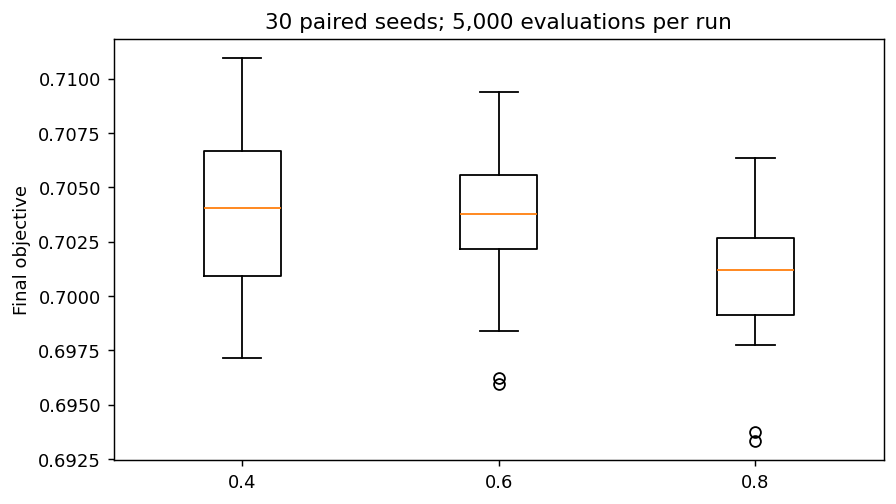

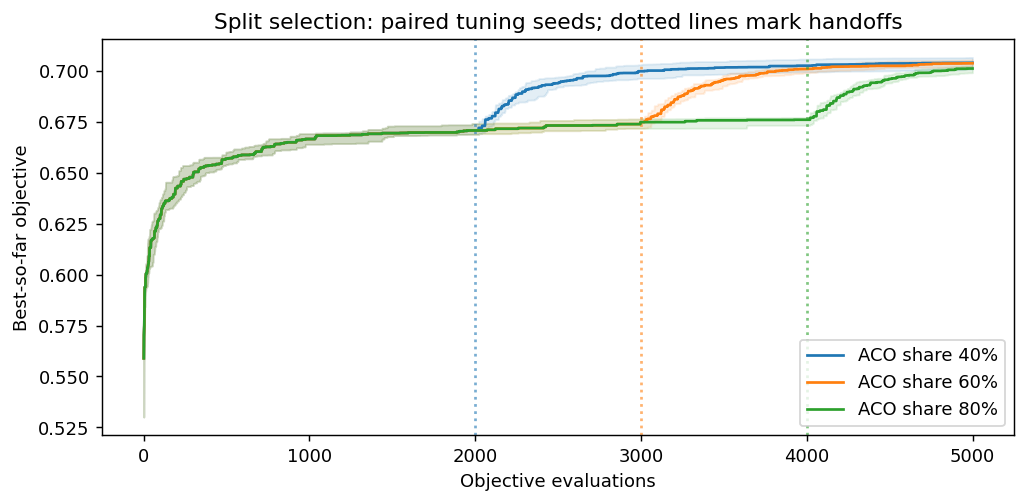

m3_grid_40: seed 3000 saved
m3_grid_40: seed 3001 saved
m3_grid_40: seed 3002 saved
m3_grid_40: seed 3003 saved
m3_grid_40: seed 3004 saved
m3_grid_40: seed 3005 saved
m3_grid_40: seed 3006 saved
m3_grid_40: seed 3007 saved
m3_grid_40: seed 3008 saved
m3_grid_40: seed 3009 saved
m3_grid_40: seed 3010 saved
m3_grid_40: seed 3011 saved
m3_grid_40: seed 3012 saved
m3_grid_40: seed 3013 saved
m3_grid_40: seed 3014 saved
m3_grid_40: seed 3015 saved
m3_grid_40: seed 3016 saved
m3_grid_40: seed 3017 saved
m3_grid_40: seed 3018 saved
m3_grid_40: seed 3019 saved
m3_grid_40: seed 3020 saved
m3_grid_40: seed 3021 saved
m3_grid_40: seed 3022 saved
m3_grid_40: seed 3023 saved
m3_grid_40: seed 3024 saved
m3_grid_40: seed 3025 saved
m3_grid_40: seed 3026 saved
m3_grid_40: seed 3027 saved
m3_grid_40: seed 3028 saved
m3_grid_40: seed 3029 saved
m3_grid_60: seed 3000 saved
m3_grid_60: seed 3001 saved
m3_grid_60: seed 3002 saved
m3_grid_60: seed 3003 saved
m3_grid_60: seed 3004 saved
m3_grid_60: seed 300

In [ ]:
m3_grid_scores, m3_grid_rows = {}, []
for split in M3_SPLITS:
    label = f"m3_grid_{int(100*split)}"
    vals, summaries = m3_run_cohort(label, M3_TUNING_SEEDS, "hybrid",
        {"split": split, "aco_params": M3_ACO_PARAMS, "pso_params": M3_PSO_PARAMS})
    q1,median,q3 = np.percentile(vals,[25,50,75])
    m3_grid_scores[split] = vals
    m3_grid_rows.append(dict(split=split, median=float(median), q1=float(q1), q3=float(q3),
        iqr=float(q3-q1), connected=sum(s["connected"] for s in summaries)))
    M3_EVALUATION_ACCOUNTING[label] = BUDGET*len(M3_TUNING_SEEDS)
selected = min(m3_grid_rows, key=lambda r: (-round(r["median"],12), round(r["iqr"],12),
                                           abs(r["split"]-.6), r["split"]))
HYBRID_SPLIT = selected["split"]
m3_grid_statistics = m3_paired_statistics(m3_grid_scores)
display({"text/markdown": "| Split | Median | Q1 | Q3 | Connected |\n|---:|---:|---:|---:|---:|\n"+
    "\n".join(f"| {r['split']:.1f} | {r['median']:.6f} | {r['q1']:.6f} | {r['q3']:.6f} | {r['connected']}/30 |"
              for r in m3_grid_rows)}, raw=True)
print("Selected split (pilot medians, not a proven optimum):", HYBRID_SPLIT)
print("Grid Friedman p:", m3_grid_statistics["friedman_p"])
for pair,p in m3_grid_statistics["holm_adjusted"].items():
    print(pair, "Holm p=",p, "rank-biserial=",m3_grid_statistics["effects"][pair])
selection_path = Path("results/m3_selected_split.json")
selection_record = dict(split=HYBRID_SPLIT, tuning_seeds=list(M3_TUNING_SEEDS),
                        budget=BUDGET, candidates=list(M3_SPLITS), rows=m3_grid_rows)
if selection_path.exists():
    assert json.loads(selection_path.read_text(encoding="utf-8")) == selection_record
else:
    selection_path.write_text(json.dumps(selection_record, indent=2), encoding="utf-8")
m3_plot_scores({str(k):v for k,v in m3_grid_scores.items()}, "m3_split_grid.png")

# Compare allocations on the same evaluation axis and mark each handoff.
fig, ax = plt.subplots(figsize=(8,4))
for split in M3_SPLITS:
    traces = load_runset(f"results/m3_grid_{int(100*split)}.npz").best_so_far
    q1, med, q3 = np.percentile(traces, [25,50,75], axis=0)
    x = np.arange(1,BUDGET+1)
    line, = ax.plot(x,med,label=f"ACO share {split:.0%}")
    ax.fill_between(x,q1,q3,color=line.get_color(),alpha=.12)
    ax.axvline(int(BUDGET*split),color=line.get_color(),linestyle=":",alpha=.6)
ax.set(xlabel="Objective evaluations",ylabel="Best-so-far objective",
       title="Split selection: paired tuning seeds; dotted lines mark handoffs")
ax.legend(); fig.tight_layout()
fig.savefig("figures/m3_split_traces.png",dpi=150); plt.show()


### Split selection and uncertainty

Pilot medians were 0.704034 for split 0.4, 0.703777 for 0.6 and 0.701204 for 0.8. The predefined rule therefore selects 0.4: 2,000 ACO calls and 3,000 PSO calls. Its IQR was wider than 0.6's; stability across runs and the largest median are different criteria, and the criterion was not changed after seeing this result.

Friedman gave p = 0.000119364. Holm-adjusted Wilcoxon p-values were 0.745655 for 0.4 versus 0.6, 0.00291495 for 0.4 versus 0.8 and 0.0000154339 for 0.6 versus 0.8. The corresponding signed rank-biserial effects were +0.070968, +0.643011 and +0.862366, with positive favoring the first split. Thus both smaller selection shares have evidence of an advantage over 0.8 in this pilot, while 0.4 versus 0.6 remains unresolved. Selection of 0.4 is descriptive, not proof of an optimal allocation. The split was frozen before the final hybrid cohort.


## Frozen hybrid: final 30 seeds

The following experiment is separate from split selection and costs 150,000 evaluations. Global six-method comparison and interpretation follow after these results have been checked.

In [ ]:
# HYBRID_SPLIT is frozen from separate tuning seeds above.
m3_hybrid_scores, m3_hybrid_summaries = m3_run_cohort("m3_hybrid", M3_FINAL_SEEDS, "hybrid",
    {"split": HYBRID_SPLIT, "aco_params": M3_ACO_PARAMS, "pso_params": M3_PSO_PARAMS})
M3_EVALUATION_ACCOUNTING["final_hybrid"] = BUDGET*len(M3_FINAL_SEEDS)
print("Final hybrid median/Q1/Q3:", np.percentile(m3_hybrid_scores,[50,25,75]))
print("Connected:", sum(s["connected"] for s in m3_hybrid_summaries), "/30")
print("Declared new evaluations by study (includes reused checkpoints once):", M3_EVALUATION_ACCOUNTING)


m3_hybrid: seed 0 saved
m3_hybrid: seed 1 saved
m3_hybrid: seed 2 saved
m3_hybrid: seed 3 saved
m3_hybrid: seed 4 saved
m3_hybrid: seed 5 saved
m3_hybrid: seed 6 saved
m3_hybrid: seed 7 saved
m3_hybrid: seed 8 saved
m3_hybrid: seed 9 saved
m3_hybrid: seed 10 saved
m3_hybrid: seed 11 saved
m3_hybrid: seed 12 saved
m3_hybrid: seed 13 saved
m3_hybrid: seed 14 saved
m3_hybrid: seed 15 saved
m3_hybrid: seed 16 saved
m3_hybrid: seed 17 saved
m3_hybrid: seed 18 saved
m3_hybrid: seed 19 saved
m3_hybrid: seed 20 saved
m3_hybrid: seed 21 saved
m3_hybrid: seed 22 saved
m3_hybrid: seed 23 saved
m3_hybrid: seed 24 saved
m3_hybrid: seed 25 saved
m3_hybrid: seed 26 saved
m3_hybrid: seed 27 saved
m3_hybrid: seed 28 saved
m3_hybrid: seed 29 saved
Final hybrid median/Q1/Q3: [0.7045445  0.7018832  0.70649533]
Connected: 30 /30
Declared new evaluations by study (includes reused checkpoints once): {'development_failed_validation': 277, 'checkpoint_validation': 20, 'implementation_validation': 387, 'm3_grid

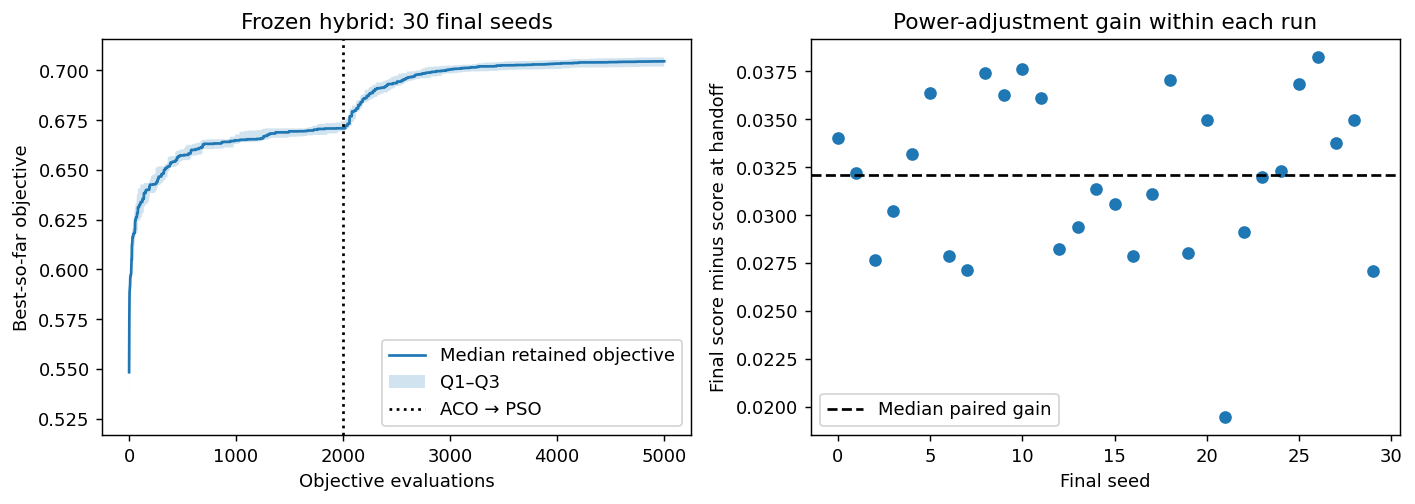

Median within-run gain after handoff: 0.032090115
This gain does not compare the hybrid against full-budget ACO or SA.


In [ ]:
# Generate final-cohort diagnostics from recorded values; no optimizer rerun.
m3_final_log = load_runset("results/m3_hybrid.npz")
m3_final_traces = np.array(m3_final_log.best_so_far)
m3_switch = int(BUDGET*HYBRID_SPLIT)
m3_final_gain = m3_final_log.best_values-m3_final_traces[:,m3_switch-1]
fig, axes = plt.subplots(1,2,figsize=(11,4))
q1, med, q3 = np.percentile(m3_final_traces,[25,50,75],axis=0)
x = np.arange(1,BUDGET+1)
axes[0].plot(x,med,label="Median retained objective")
axes[0].fill_between(x,q1,q3,alpha=.2,label="Q1–Q3")
axes[0].axvline(m3_switch,color="black",linestyle=":",label="ACO → PSO")
axes[0].set(xlabel="Objective evaluations",ylabel="Best-so-far objective",
            title="Frozen hybrid: 30 final seeds")
axes[0].legend()
axes[1].scatter(np.arange(30),m3_final_gain)
axes[1].axhline(np.median(m3_final_gain),linestyle="--",color="black",label="Median paired gain")
axes[1].set(xlabel="Final seed",ylabel="Final score minus score at handoff",
            title="Power-adjustment gain within each run")
axes[1].legend(); fig.tight_layout()
fig.savefig("figures/m3_hybrid_final.png",dpi=150)
plt.show()
print("Median within-run gain after handoff:",float(np.median(m3_final_gain)))
print("This gain does not compare the hybrid against full-budget ACO or SA.")

### Frozen hybrid outcomes

Using the selected 2,000/3,000 allocation on final seeds 0–29, the hybrid reached median objective 0.704544, Q1–Q3 0.701883–0.706495 and connected retained deployments in 30/30 runs. The median within-run gain after transferring ACO's solution to PSO was +0.032090. This is a median of paired stage gains, not a difference of two displayed medians. PSO preserves the incoming deployment, guaranteeing no loss at the handoff; the measured positive gains show improvement for these runs, not superiority over full-budget ACO or SA. The latter comparisons belong to the pending six-method study.


## Six-method comparative study: protocol before execution

The study compares Monte Carlo, joint SA, tabu, standalone ring PSO, bounded ACO and the frozen hybrid on seeds 0–29 with 5,000 objective calls each. Historical M0/M1 logs use different NumPy/SciPy versions; those three cohorts are repeated in the current runtime and charged. Bounded ACO and hybrid records already match this runtime and are reused once.

Standalone PSO uses one fixed 15-site subset drawn with seed 3200 and nominal powers before optimization. No objective calls select this subset and no tabu results are supplied. Its scores measure power optimization conditional on that particular subset, rather than performance of a complete mixed solver; they do not replace the differently conditioned M1/M2 PSO results. Algorithm scopes and initializations differ, so this is a comparison of complete declared configurations, not an isolated test of memory or topology. Hybrid allocation remains 40/60; this study does not retune it.

Friedman tests the joint ranking; two-sided Wilcoxon comparisons use all 15 pairs with one Holm family at 0.05. Signed effects and median paired differences accompany p-values. A non-significant result does not establish equivalence. Because the usual Friedman p-value uses a chi-square approximation, a within-seed label-permutation calibration with 99,999 resamples is reported as a sensitivity check. It reuses scores and incurs no objective calls. Symmetry of paired differences is relevant when interpreting signed-rank results as location differences.


In [ ]:
M3_GLOBAL_NAMES = ("monte_carlo","simulated_annealing","tabu_search","pso","aco","hybrid")
mc_old = load_runset("results/m0_monte_carlo.npz")
sa_old = load_runset("results/m0_annealing.npz")
tabu_old = load_runset("results/m1_tabu.npz")
M3_GLOBAL_PARAMS = {
    "monte_carlo": {"active_fraction_range":mc_old.meta["params"]["active_fraction_range"]},
    "simulated_annealing":{k:sa_old.meta["params"][k] for k in
        ("initial_temperature","final_temperature","power_step","flip_probability","active_fraction","nominal_power")},
    "tabu_search":{k:tabu_old.meta["params"][k] for k in
        ("tenure","candidate_size","nominal_power","active_fraction")},
    "pso":{**M3_PSO_PARAMS,"n_select":15,"subset_seed":3200,"nominal_power":M3_ACO_PARAMS["nominal_power"]}}
selected = json.loads(Path("results/m3_selected_split.json").read_text(encoding="utf-8"))
HYBRID_SPLIT = selected["split"]
assert HYBRID_SPLIT == .4
M3_GLOBAL_REUSE = {"aco":"m3_aco_bounded","hybrid":"m3_hybrid"}
for name,old in (("monte_carlo",mc_old),("simulated_annealing",sa_old),("tabu_search",tabu_old)):
    assert old.meta["student_id"]==STUDENT_ID and old.meta["params"]["salt"]==SALT
    print(name, "historical environment:",old.meta["environment"]["packages"])
print("Current environment:",environment_fingerprint()["packages"])
print("Frozen final protocol: seeds 0–29; 5,000 calls each; hybrid split",HYBRID_SPLIT)
print("Fresh cohorts: Monte Carlo, SA, tabu and fixed-subset ring PSO (600,000 calls).")
print("Reuse: 30 bounded ACO and 30 hybrid runs from the same current runtime; zero new calls.")


monte_carlo historical environment: {'numpy': '2.5.4', 'scipy': '1.18.1'}
simulated_annealing historical environment: {'numpy': '2.5.4', 'scipy': '1.18.1'}
tabu_search historical environment: {'numpy': '2.5.4', 'scipy': '1.18.1'}
Current environment: {'numpy': '2.2.5', 'scipy': '1.16.3'}
Frozen final protocol: seeds 0–29; 5,000 calls each; hybrid split 0.4
Fresh cohorts: Monte Carlo, SA, tabu and fixed-subset ring PSO (600,000 calls).
Reuse: 30 bounded ACO and 30 hybrid runs from the same current runtime; zero new calls.


### Standalone PSO checks

The short validation audits fixed activations and individual power limits, equal subsets across seeds, reproducible proposals, retained-best agreement and the exact call count. Its cost is separate from final experiments.


In [ ]:
m3_global_check_cost = 0
fixed = []
for seed in (3210,3211,3210):
    probe = M3AuditProblem(instance,budget=37,seed=seed)
    detail = m3_standalone_pso(probe,seed,**M3_GLOBAL_PARAMS["pso"],return_details=True)
    assert probe.evaluations_used==len(probe.proposals)==37
    assert detail["score"]==max(probe.record.values)
    assert all(np.array_equal(a,detail["active"]) for a,p in probe.proposals)
    assert detail["active"].sum()==15
    assert all(np.all((p>=spec.power_min)&(p<=instance.power_cap)) for a,p in probe.proposals)
    fixed.append((detail["active"],np.array(probe.record.values)))
    m3_global_check_cost += probe.evaluations_used
assert all(np.array_equal(fixed[0][0],a) for a,v in fixed)
assert np.array_equal(fixed[0][1],fixed[2][1])
M3_EVALUATION_ACCOUNTING["global_standalone_pso_validation"] = m3_global_check_cost
print("Fixed subset, independent run seeds, replay, retained best, bounds and exact budgets passed.")
print("Validation sensor calls:",m3_global_check_cost)
print("Predeclared site indices:",np.flatnonzero(fixed[0][0]).tolist())


Fixed subset, independent run seeds, replay, retained best, bounds and exact budgets passed.
Validation sensor calls: 111
Predeclared site indices: [2, 18, 19, 22, 23, 30, 34, 36, 38, 41, 45, 49, 53, 61, 74]


In [ ]:
def m3_global_cohort(name,params):
    """Full current-runtime cohort with per-seed checkpoints and explicit provenance."""
    from tc6035.problem import RunRecord
    label = f"m3_global_{name}"
    root = Path("results/m3_checkpoints")/label
    root.mkdir(parents=True,exist_ok=True)
    protocol = {"algorithm":name,"params":params,"student_id":STUDENT_ID,"salt":SALT,
        "budget":BUDGET,"seeds":list(M3_FINAL_SEEDS),"environment":environment_fingerprint(),
        "source_sha256":hashlib.sha256("\n".join(inspect.getsource(f) for f in
            (sample_deployment,monte_carlo,accept_annealing,geometric_temperature,simulated_annealing,
             tabu_search,pso_step,ring_social_targets,pso,m3_standalone_pso)).encode()).hexdigest(),
        "instance_sha256":hashlib.sha256(b"".join(np.ascontiguousarray(a).tobytes() for a in
            (instance.candidates,instance.power_cap,instance.grid_points,instance.demand))).hexdigest()}
    manifest = root/"protocol.json"
    text = json.dumps(protocol,sort_keys=True,indent=2)
    if manifest.exists():
        assert manifest.read_text(encoding="utf-8")==text,"Changed cohort protocol"
    else:
        manifest.write_text(text,encoding="utf-8")
    records,solutions = [],[]
    for seed in M3_FINAL_SEEDS:
        path = root/f"seed_{seed}.npz"
        if path.exists():
            with np.load(path,allow_pickle=False) as z:
                values,best=z["values"].copy(),z["best"].copy()
                active,power=z["active"].copy(),z["power"].copy()
                summary=json.loads(str(z["summary"]))
        else:
            problem=SensorPlacementProblem(instance,budget=BUDGET,seed=seed)
            if name=="monte_carlo":
                score,active,power,result=monte_carlo(problem,seed,**params,return_solution=True)
            else:
                detail=ALGORITHMS[name](problem,seed,**params,return_details=True)
                score,active,power,result=(detail[k] for k in ("score","active","power","result"))
            assert problem.evaluations_used==BUDGET
            summary={"seed":seed,"score":float(score),"connected":bool(result.feasible),
                     "coverage":float(result.coverage),"energy":float(result.energy),
                     "interference":float(result.interference),"n_active":int(active.sum())}
            values,best=np.array(problem.record.values),np.array(problem.record.best_so_far)
            temp=path.with_suffix(".partial.npz")
            np.savez_compressed(temp,values=values,best=best,active=active,power=power,summary=json.dumps(summary))
            temp.replace(path)
            print(f"{label}: seed {seed} saved",flush=True)
        assert summary["seed"]==seed and len(values)==len(best)==BUDGET
        assert np.array_equal(best,np.maximum.accumulate(values)) and summary["score"]==best[-1]
        assert np.all((power>=spec.power_min)&(power<=instance.power_cap))
        record=RunRecord(instance_id=STUDENT_ID,seed=seed,budget=BUDGET,
                         values=values.tolist(),best_so_far=best.tolist())
        records.append(record); solutions.append((active,power,summary))
    save_runset(f"results/{label}.npz",RunSet(algorithm=name,student_id=STUDENT_ID,
        params={**params,"salt":SALT,"protocol":protocol},records=records))
    return load_runset(f"results/{label}.npz"),solutions


def m3_friedman_permutation(score_matrix,n_resamples=99999,seed=3299):
    """Calibrate Friedman ranks by permuting method labels within each seed."""
    ranks=rankdata(-np.asarray(score_matrix),axis=1,method="average")
    n,k=ranks.shape
    ties=0
    for row in score_matrix:
        counts=np.unique(row,return_counts=True)[1]
        ties += np.sum(counts**3-counts)
    correction=1-float(ties)/(n*(k**3-k))
    if correction<=0:
        return 1.
    observed=(12/(n*k*(k+1))*np.sum(ranks.sum(axis=0)**2)-3*n*(k+1))/correction
    rng=np.random.default_rng(seed)
    exceed,done=0,0
    while done<n_resamples:
        batch=min(1000,n_resamples-done)
        draws=rng.permuted(np.broadcast_to(ranks,(batch,n,k)),axis=2)
        stats=(12/(n*k*(k+1))*np.sum(draws.sum(axis=1)**2,axis=1)-3*n*(k+1))/correction
        exceed+=int(np.sum(stats>=observed-1e-12))
        done+=batch
    return (exceed+1)/(n_resamples+1)


equal_stat=m3_paired_statistics({k:np.ones(30) for k in ("a","b","c")})
assert equal_stat["friedman_p"]==1 and equal_stat["n_significant"]==0
assert m3_friedman_permutation(np.ones((30,6)),99)==1
print("All-equal paired data handled without spurious significance; helper checks passed.")


All-equal paired data handled without spurious significance; helper checks passed.


### Matched-runtime execution and reuse

Four new 30-run cohorts cost 600,000 calls. The ACO and hybrid cohorts represent 300,000 calls already charged in the prior M3 experiments; reusing them adds zero calls. Per-seed checkpoints retain full traces, solutions, objective components and protocol fingerprints.


In [ ]:
m3_global_runs,m3_global_solutions={},{}
for name in M3_GLOBAL_PARAMS:
    m3_global_runs[name],m3_global_solutions[name]=m3_global_cohort(name,M3_GLOBAL_PARAMS[name])
    M3_EVALUATION_ACCOUNTING[f"global_{name}"]=BUDGET*len(M3_FINAL_SEEDS)
for name,label in M3_GLOBAL_REUSE.items():
    runs=load_runset(f"results/{label}.npz")
    assert runs.seeds==list(M3_FINAL_SEEDS)
    assert runs.meta["student_id"]==STUDENT_ID and runs.meta["params"]["salt"]==SALT
    assert runs.meta["environment"]==environment_fingerprint()
    assert runs.meta["params"]["protocol"]["instance_sha256"]==hashlib.sha256(b"".join(
        np.ascontiguousarray(a).tobytes() for a in
        (instance.candidates,instance.power_cap,instance.grid_points,instance.demand))).hexdigest()
    if name=="hybrid":
        assert runs.meta["params"]["split"]==HYBRID_SPLIT
        assert runs.meta["params"]["pso_params"]==M3_PSO_PARAMS
        assert runs.meta["params"]["aco_params"]==M3_ACO_PARAMS
    else:
        assert all(runs.meta["params"][k]==v for k,v in M3_ACO_PARAMS.items())
    assert all(r["budget"]==r["evaluations_used"]==BUDGET for r in runs.meta["runs"])
    assert all(np.array_equal(b,np.maximum.accumulate(v)) for b,v in zip(runs.best_so_far,runs.values))
    m3_global_runs[name]=runs
    loaded=[]
    for seed in M3_FINAL_SEEDS:
        with np.load(f"results/m3_checkpoints/{label}/seed_{seed}.npz",allow_pickle=False) as z:
            loaded.append((z["active"].copy(),z["power"].copy(),json.loads(str(z["summary"]))))
    m3_global_solutions[name]=loaded
    print(name,": reusing 30 verified current-runtime runs; no new evaluations.")
m3_global_scores={n:m3_global_runs[n].best_values for n in M3_GLOBAL_NAMES}
m3_global_matrix=np.column_stack([m3_global_scores[n] for n in M3_GLOBAL_NAMES])
assert m3_global_matrix.shape==(30,6) and np.all(np.isfinite(m3_global_matrix))
print("Global comparison ready: 180 runs, 900,000 represented calls, 600,000 new final-study calls.")


m3_global_monte_carlo: seed 0 saved
m3_global_monte_carlo: seed 1 saved
m3_global_monte_carlo: seed 2 saved
m3_global_monte_carlo: seed 3 saved
m3_global_monte_carlo: seed 4 saved
m3_global_monte_carlo: seed 5 saved
m3_global_monte_carlo: seed 6 saved
m3_global_monte_carlo: seed 7 saved
m3_global_monte_carlo: seed 8 saved
m3_global_monte_carlo: seed 9 saved
m3_global_monte_carlo: seed 10 saved
m3_global_monte_carlo: seed 11 saved
m3_global_monte_carlo: seed 12 saved
m3_global_monte_carlo: seed 13 saved
m3_global_monte_carlo: seed 14 saved
m3_global_monte_carlo: seed 15 saved
m3_global_monte_carlo: seed 16 saved
m3_global_monte_carlo: seed 17 saved
m3_global_monte_carlo: seed 18 saved
m3_global_monte_carlo: seed 19 saved
m3_global_monte_carlo: seed 20 saved
m3_global_monte_carlo: seed 21 saved
m3_global_monte_carlo: seed 22 saved
m3_global_monte_carlo: seed 23 saved
m3_global_monte_carlo: seed 24 saved
m3_global_monte_carlo: seed 25 saved
m3_global_monte_carlo: seed 26 saved
m3_global_m

### Global ranking and paired evidence

Lower mean rank is better. In the pair table, positive paired differences and rank-biserial effects favor the first method. All comparisons use the same full-precision records; only signed-rank tie handling rounds differences to 12 decimals, as in earlier milestones.


In [ ]:
global_stats=m3_paired_statistics(m3_global_scores)
friedman_p=global_stats["friedman_p"]
holm_adjusted=global_stats["holm_adjusted"]
n_significant=global_stats["n_significant"]
friedman_permutation_p=m3_friedman_permutation(m3_global_matrix)
global_mean_ranks=rankdata(-m3_global_matrix,axis=1,method="average").mean(axis=0)
kendall_w=global_stats["friedman_stat"]/(len(M3_FINAL_SEEDS)*(len(M3_GLOBAL_NAMES)-1))
assert len(holm_adjusted)==15
ordered_pairs=sorted(global_stats["raw_p"],key=global_stats["raw_p"].get)
adjusted_sorted=[holm_adjusted[pair] for pair in ordered_pairs]
assert np.all(np.diff(adjusted_sorted)>=0)
assert all(global_stats["raw_p"][pair]<=p<=1 for pair,p in holm_adjusted.items())
rows=[]
for i,name in enumerate(M3_GLOBAL_NAMES):
    q1,med,q3=np.percentile(m3_global_scores[name],[25,50,75])
    connected=sum(s[2]["connected"] for s in m3_global_solutions[name])
    rows.append({"method":name,"median":float(med),"q1":float(q1),"q3":float(q3),
                 "mean_rank":float(global_mean_ranks[i]),"connected":int(connected)})
display({"text/markdown":"| Method | Median | Q1 | Q3 | Mean rank | Connected |\n|---|---:|---:|---:|---:|---:|\n"+
    "\n".join(f"| {r['method']} | {r['median']:.6f} | {r['q1']:.6f} | {r['q3']:.6f} | {r['mean_rank']:.3f} | {r['connected']}/30 |" for r in rows)},raw=True)
print("Friedman chi-square approximation p:",friedman_p)
print("Within-seed label-permutation p (99,999 resamples):",friedman_permutation_p)
print("Kendall W:",kendall_w)
print("Significant pairs after Holm:",n_significant,"of 15")
display({"text/markdown":"| First minus second | Median paired difference | Rank-biserial | Raw p | Holm p |\n|---|---:|---:|---:|---:|\n"+
    "\n".join(f"| {a} − {b} | {global_stats['median_differences'][a,b]:+.6f} | {global_stats['effects'][a,b]:+.6f} | {global_stats['raw_p'][a,b]:.6g} | {holm_adjusted[a,b]:.6g} |" for a,b in holm_adjusted)},raw=True)
statistics_record={"friedman_stat":global_stats["friedman_stat"],"friedman_p":friedman_p,
    "friedman_permutation_p":friedman_permutation_p,"permutation_resamples":99999,
    "kendall_w":kendall_w,"n_significant":n_significant,"summary":rows,
    "pairs":[{"first":a,"second":b,"raw_p":global_stats["raw_p"][a,b],
              "holm_p":holm_adjusted[a,b],"median_difference":global_stats["median_differences"][a,b],
              "rank_biserial":global_stats["effects"][a,b]} for a,b in holm_adjusted],
    "new_final_study_calls":600000,"new_validation_calls":m3_global_check_cost,
    "reused_calls":300000,"represented_global_study_calls":900000}
Path("results/m3_global_statistics.json").write_text(json.dumps(statistics_record,indent=2),encoding="utf-8")


| Method | Median | Q1 | Q3 | Mean rank | Connected |
|---|---:|---:|---:|---:|---:|
| monte_carlo | 0.551577 | 0.540722 | 0.561175 | 5.000 | 30/30 |
| simulated_annealing | 0.714655 | 0.712220 | 0.717910 | 1.367 | 30/30 |
| tabu_search | 0.685529 | 0.683647 | 0.687036 | 2.900 | 30/30 |
| pso | 0.254404 | 0.253786 | 0.254630 | 6.000 | 30/30 |
| aco | 0.675570 | 0.673782 | 0.676724 | 3.900 | 30/30 |
| hybrid | 0.704544 | 0.701883 | 0.706495 | 1.833 | 30/30 |

| First minus second | Median paired difference | Rank-biserial | Raw p | Holm p |
|---|---:|---:|---:|---:|
| monte_carlo − simulated_annealing | -0.163040 | -1.000000 | 1.86265e-09 | 2.79397e-08 |
| monte_carlo − tabu_search | -0.133351 | -1.000000 | 1.86265e-09 | 2.79397e-08 |
| monte_carlo − pso | +0.297270 | +1.000000 | 1.86265e-09 | 2.79397e-08 |
| monte_carlo − aco | -0.124506 | -1.000000 | 1.86265e-09 | 2.79397e-08 |
| monte_carlo − hybrid | -0.151019 | -1.000000 | 1.86265e-09 | 2.79397e-08 |
| simulated_annealing − pso | +0.460433 | +1.000000 | 1.86265e-09 | 2.79397e-08 |
| tabu_search − pso | +0.431641 | +1.000000 | 1.86265e-09 | 2.79397e-08 |
| tabu_search − aco | +0.009757 | +1.000000 | 1.86265e-09 | 2.79397e-08 |
| tabu_search − hybrid | -0.018623 | -1.000000 | 1.86265e-09 | 2.79397e-08 |
| pso − aco | -0.421246 | -1.000000 | 1.86265e-09 | 2.79397e-08 |
| pso − hybrid | -0.450021 | -1.000000 | 1.86265e-09 | 2.79397e-08 |
| aco − hybrid | -0.028370 | -1.000000 | 1.86265e-09 | 2.79397e-08 |
| simulated_annealing − aco | +0.039880 | +0.974194 | 2.6077e-08 | 7.82311e-08 |
| simulated_annealing − tabu_search | +0.029723 | +0.939785 | 2.04891e-07 | 4.09782e-07 |
| simulated_annealing − hybrid | +0.009575 | +0.612903 | 0.00256009 | 0.00256009 |

Friedman chi-square approximation p: 1.6762088050106937e-28
Within-seed label-permutation p (99,999 resamples): 1e-05
Kendall W: 0.934222222222223
Significant pairs after Holm: 15 of 15


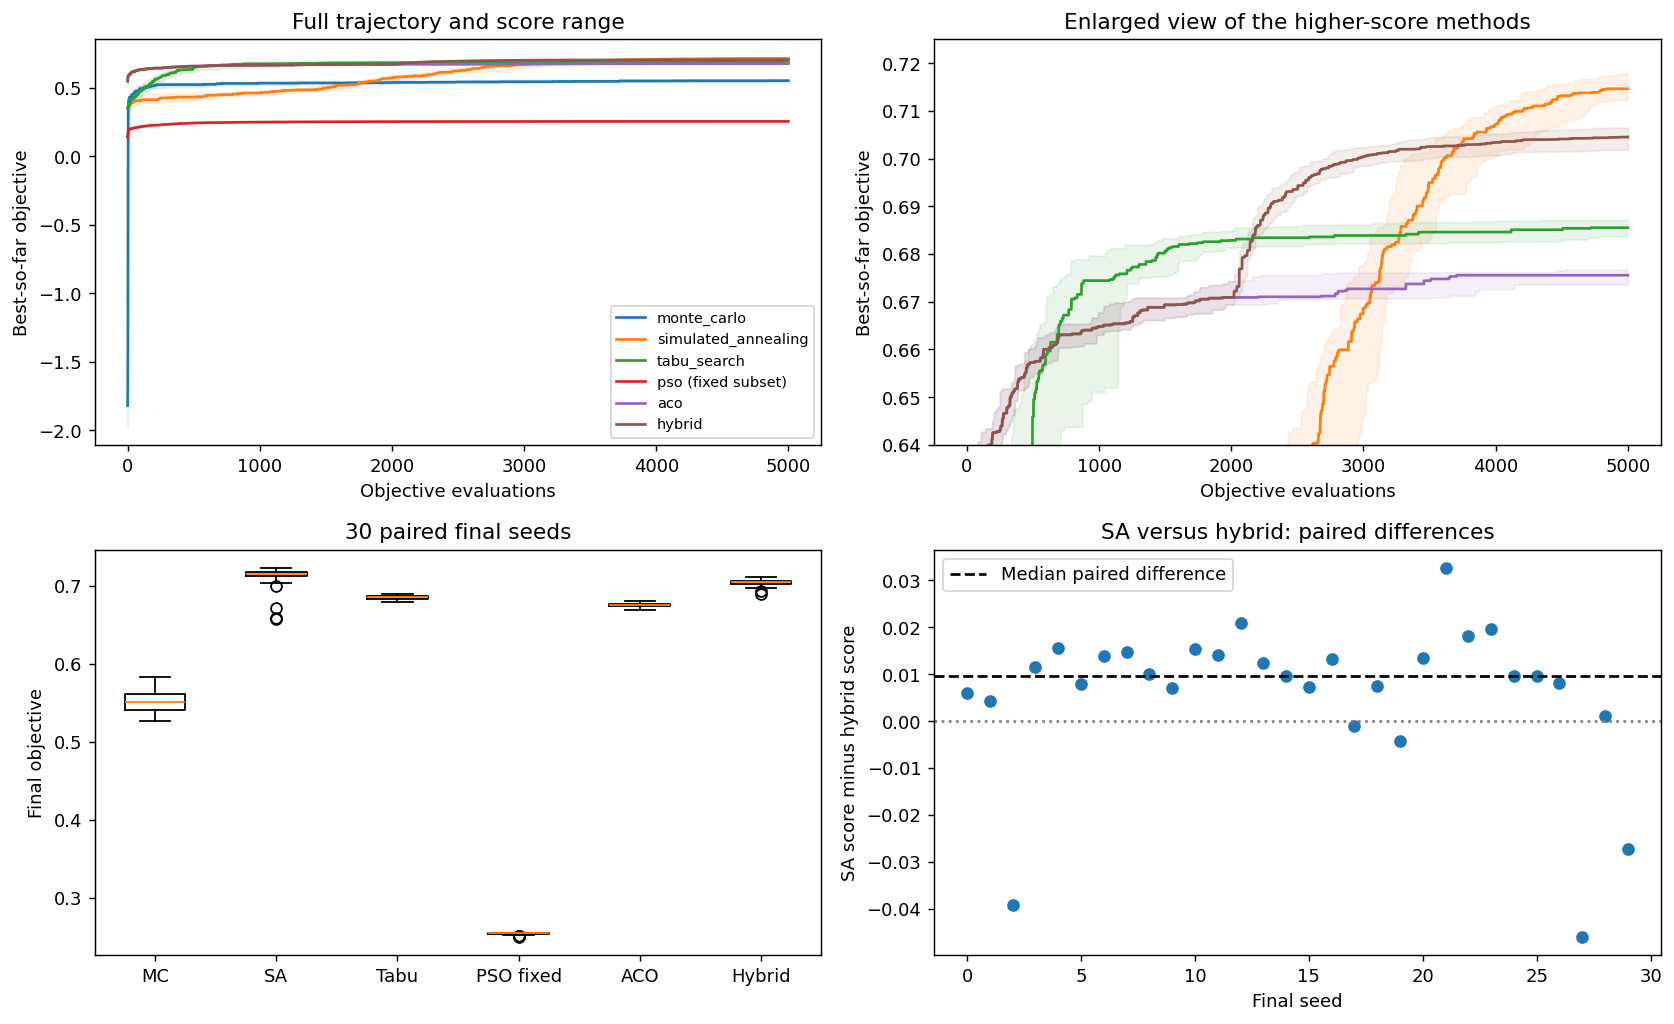

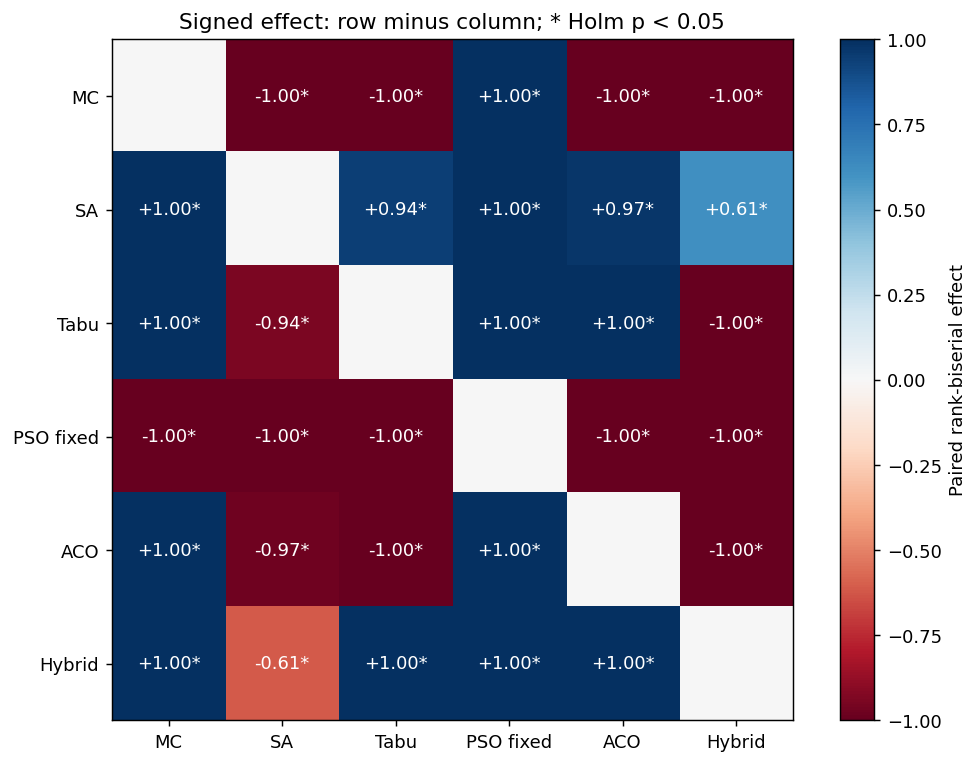

In [ ]:
# Redraw from stored trajectories; this cell performs no objective evaluations.
fig,axes=plt.subplots(2,2,figsize=(13,8))
x=np.arange(1,BUDGET+1)
for name in M3_GLOBAL_NAMES:
    q1,med,q3=np.percentile(m3_global_runs[name].best_so_far,[25,50,75],axis=0)
    for ax in axes[0]:
        line,=ax.plot(x,med,label=name if name!="pso" else "pso (fixed subset)")
        ax.fill_between(x,q1,q3,color=line.get_color(),alpha=.1)
        ax.set(xlabel="Objective evaluations",ylabel="Best-so-far objective")
axes[0,0].set_title("Full trajectory and score range")
axes[0,0].legend(fontsize=8)
axes[0,1].set(title="Enlarged view of the higher-score methods",ylim=(.64,.725))
axes[1,0].boxplot(list(m3_global_scores.values()),tick_labels=["MC","SA","Tabu","PSO fixed","ACO","Hybrid"])
axes[1,0].set(ylabel="Final objective",title="30 paired final seeds")
paired=m3_global_scores["simulated_annealing"]-m3_global_scores["hybrid"]
axes[1,1].scatter(np.arange(30),paired)
axes[1,1].axhline(0,color="gray",linestyle=":")
axes[1,1].axhline(np.median(paired),color="black",linestyle="--",label="Median paired difference")
axes[1,1].set(xlabel="Final seed",ylabel="SA score minus hybrid score",title="SA versus hybrid: paired differences")
axes[1,1].legend()
fig.tight_layout();fig.savefig("figures/m3_global_comparison.png",dpi=150);plt.show()

fig,ax=plt.subplots(figsize=(8,6))
effects=np.zeros((6,6))
annotations=np.full((6,6),"",dtype=object)
for pair,p in holm_adjusted.items():
    a,b=map(M3_GLOBAL_NAMES.index,pair)
    effect=global_stats["effects"][pair]
    effects[a,b],effects[b,a]=effect,-effect
    star="*" if p<.05 else ""
    annotations[a,b],annotations[b,a]=f"{effect:+.2f}{star}",f"{-effect:+.2f}{star}"
im=ax.imshow(effects,cmap="RdBu",vmin=-1,vmax=1)
for i in range(6):
    for j in range(6):
        if i!=j:ax.text(j,i,annotations[i,j],ha="center",va="center",
                        color="white" if abs(effects[i,j])>.6 else "black")
ax.set_xticks(range(6),["MC","SA","Tabu","PSO fixed","ACO","Hybrid"])
ax.set_yticks(range(6),["MC","SA","Tabu","PSO fixed","ACO","Hybrid"])
ax.set_title("Signed effect: row minus column; * Holm p < 0.05")
fig.colorbar(im,ax=ax,label="Paired rank-biserial effect")
fig.tight_layout();fig.savefig("figures/m3_global_effects.png",dpi=150);plt.show()

### What the global comparison supports

Friedman's chi-square approximation gave p = 1.67621e-28; the within-seed label-permutation check gave p = 1e-05 (99,999 resamples). The permutation estimate is limited by the finite resample count; it is not an exact p-value. Kendall's W was 0.934222. Both calibrations support a global difference across the tested configurations. Mean-rank order was simulated_annealing → hybrid → tabu_search → aco → monte_carlo → pso. Mean-rank ordering does not by itself establish every pairwise difference: 15 of 15 pairs were significant after Holm. Pairs without such evidence: none.

The central SA–hybrid comparison produced median paired difference +0.009575, rank-biserial effect +0.612903 and Holm p = 0.00256009, with positive signs favoring SA. SA won 25 seeds, tied 0 and lost 5. These results concern the current common runtime, instance, frozen configurations and 5,000-call budget.

The result is compatible with the value of revisiting both coupled layers throughout a run, but it does not isolate that mechanism: SA and the hybrid also differ in operators, initialization, memory and search restrictions. The earlier M0 joint-versus-staged SA comparison offers additional evidence about staging within a shared search engine. Neither comparison establishes that all sequential hybrids must lose.

Standalone PSO here adjusts powers on one predeclared random 15-site subset. Its ranking is conditional on that input, not an estimate over all subsets and not the M1/M2 tabu–PSO pipeline. ACO also fixes cardinality and powers, while tabu can vary cardinality at fixed nominal powers. Thus the study compares declared configurations with different scope rather than isolated algorithm names. Disconnected outcomes, if present, retain the supplied penalty and remain in the scores.

The split grid's 40/60 and 60/40 results remain statistically unresolved despite their ordered medians; 60/40 had a narrower IQR. These describe final quality and consistency. Any claim about reaching comparable quality earlier still requires a target defined before measuring evaluations-to-target. No savings or stopping rule is inferred from a visually flat curve alone.

The study represents 900,000 final-comparison calls. It reuses 300,000 ACO/hybrid calls already charged and adds 600,000 calls plus 111 standalone-PSO validation calls. The overall new M3 work now totals 1,500,795 calls, including the split grid, ablation, repeated-runtime cohorts and all recorded development attempts. Costs already counted in earlier milestones are separate.

## Carry forward

Carry forward the frozen split 0.4, the six current-runtime score arrays and full traces, `friedman_p`, the permutation sensitivity result, `holm_adjusted`, `n_significant` and signed paired effects. No Free Lunch limits universal conclusions; these data support claims about the tested instance/configurations. The individual submission does not establish transfer to a second instance. A falsifying follow-up for the observed SA advantage would freeze both solvers and rerun independent seeds or another instance: a reproducible reversal or lack of a practically relevant positive paired difference would require narrowing that claim.


# Analysis

## Coupled decisions, composition and evaluation budget

Combining algorithms is a defensible design when their search mechanisms complement each other. Here ACO selects active sites, whereas PSO adjusts their powers. The motivation is the mixed problem structure, rather than an assumption that a hybrid must outperform either component or another solver.

The relevant difficulty is the interaction between decisions, not only their number. Changing a sensor's power affects coverage, energy, interference and potentially connectivity. Changing the active subset can therefore change which power assignments are useful, and adjusting powers can change which subset would be preferable. Improving one contribution need not improve the complete objective. A useful configuration of one layer may need revision after the other changes.

The implemented SA can propose changes to either layer throughout the run. It changes activations or powers in an individual move, rather than both simultaneously. This flexibility allows repeated adjustment as the current deployment changes. The sequential hybrid instead commits to ACO's retained subset before PSO begins. Its second stage is conditioned on the first: PSO can improve powers within the received subset but cannot replace sites. This restriction does not imply that the hybrid must lose; its consequences depend on the instance, operators, parameters and available evaluations. The current experiments do not isolate it as the sole cause of a performance difference.

Composition must also respect the evaluation budget. The hybrid spends one shared total of 5,000 calls, so allocating more to selection necessarily leaves fewer for power adjustment. The split grid illustrates this tradeoff: 40/60 had the largest tuning median, while 60/40 had a narrower IQR and their difference remained statistically unresolved. Both outperformed 80/20 in the pilot comparisons. These findings favor the selected allocation among the three candidates, not an optimal allocation over all possibilities. Reaching a comparable quality earlier is a separate efficiency question requiring an explicit target and evaluation-to-target measurement. The grid's 450,000 tuning calls are reported separately from each final run's budget.

No Free Lunch provides a limit on universal claims: under its assumptions, averaging uniformly over all objective functions removes a general performance advantage. It does not guarantee that hybridization helps or prevent an algorithm from performing well on a structured problem class. The conclusions here must follow from measured behavior on this instance and the tested configurations. The common-runtime six-method study now provides the paired evidence: SA minus the frozen hybrid has median difference +0.009575, Holm-adjusted p = 0.00256009 and rank-biserial effect +0.612903. This supports the measured ordering under the declared conditions; it does not prove that the ability to revisit both layers is its sole cause.


## Comparative evidence and limits

The global test and permutation sensitivity check both detected differences among the six configurations; 15 of 15 paired comparisons remained significant after Holm. Median scores, paired differences and signed effects are reported together in M3. Standalone PSO uses an unoptimized fixed subset, whereas its M1/M2 results were conditioned on prior tabu optimization, so those scores answer different questions. Equal objective-call budgets do not erase differences in scope or initialization. The final hybrid includes both stages within its 5,000 calls; the 450,000-call allocation pilot is an additional cost, not part of that per-run allowance.

The results concern one instance. Repeating the frozen SA and hybrid configurations on independent seeds and another instance could challenge the observed ordering. A reversal or absence of a practically relevant advantage would require narrowing the conclusion. The current experiments establish neither an optimal solver nor a universal ranking, and evaluating time-to-target remains future work.


# AI Ledger


This ledger records assistance, student-led revisions and the evidence used to check them. Verdicts apply to the stated output: requesting or accepting a revision does not imply approval of every implementation or experiment. Automated checks and the student's own checks are identified separately.

**Tool / model for all entries:** ChatGPT / Codex. The exact model identifier was not independently verified in the notebook. Prompt excerpts below are taken from the conversation; task summaries are labeled as summaries.



## Initial implementation work

| Prompt or task | Output | Verdict | Reason | Verification |
|---|---|---|---|---|
| Task summary: continue the sensor-placement notebook with formulation and M0 characterization. | Formulation, instance map, random-deployment sampling and unconditional random walk. | Broader implementation review remains pending. | Later student approvals apply to specific interpretations and revisions below. | Assistant-run checks: independent single-sensor calculation, disconnected-pair penalty, cap equivalence, deterministic instance regeneration and budget checks. |
| Task summary: implement the Monte Carlo baseline. | Random search, 30-seed study, summaries and representative deployment. | Broader implementation review remains pending. | Discussion of the results is recorded separately from a full code review. | Assistant-run independent replay, retained-vector check, seeded repeatability and exact per-run budget assertions. |
| Task summary: implement annealing and compare joint with staged search. | SA engine, nominal-power pilot, connectivity demonstration, paired experiments and diagnostics. | Broader implementation review remains pending; illustrated execution accepted below. | Acceptance of the validation cell is not extended to every part of the experiment. | Assistant-run scripted acceptance/rejection, cooling endpoints, fixed-layer audits, stage accounting and common-start checks. |



## Revisions prompted by the student's review

| Student prompt or observation | Output or change | Verdict | Reason for the decision | Evidence or verification |
|---|---|---|---|---|
| “conviene ajustar ese texto de preliminary interpretation” and later “continuemos con lo siguiente manteniendo esos cambios” | Revised the preliminary interpretation to explain what feasibility and walk correlation do and do not establish. | Modified at the student's request; retained for subsequent work. | A high correlation does not mean that the walk keeps improving or that connectivity becomes more likely with more steps. | The revised section states that 16.5% depends on the sampling distribution and that correlation 0.935 depends on the walk and move operator. |
| “tal vez seria bueno hacer un zoom a esa grafica” | Added a zoom of Monte Carlo convergence from evaluations 100–5,000 while retaining the full trajectory and final-score plot. | Modified at the student's request. | Initial penalized scores compressed the later improvements on the full vertical scale. | Both views use the same recorded best-so-far traces. The notebook reports median values at 100, 1,000 and 5,000 evaluations; later gains are visible without discarding the full view. |
| “hay que esperar a comparar con otras soluciones” and “eso hay que agregarlo al notebook para complementar el baseline interpretation” | Added a more cautious baseline interpretation covering constraints, variation between seeds and improvement within runs. | Modified following the student's review. | The objective and active-sensor count do not reveal the unknown optimality gap; increasing activation is not automatically beneficial. | The baseline interpretation distinguishes final-score variability across seeds from within-run convergence and defers quality judgments to comparisons under the same budget. |
| “tambien agrega una tabla para que sea mas legible” | Added a readable carry-forward table while retaining full-precision constants in code. | Modified at the student's request. | Values needed by M1 should be easy to find without replacing the executable definitions. | The table includes `MC_BASELINE_MEDIAN`, `NOMINAL_POWER`, budgets, seeds and diagnostics alongside their named code variables. |
| “no veo que hayamos hecho un statement de por que es dificil” followed by the student's explanation of interacting variables, connectivity and the 80-site search space. | Added “Why this instance is difficult,” developing the student's argument with continuous powers, heterogeneous caps and competing objective terms. | Modified at the student's request. | The formulation needed an explicit difficulty argument, rather than leaving it implicit in the experiments. | The section explains the activation-subset count, coupled decisions, threshold effects and the limits of the measured diagnostics. The student originated the core argument. |
| “el texto que estas haciendo no se entiende muy bien” and “rank-biseral effect ... te lo inventaste?”, followed by “exacto, eso suena mejor” | Reordered the statistical explanation to present outcomes first, defined the effect size and added its documentation source; simplified M0 analysis. | Revised explanation accepted by the student. | A technical name without a definition made the results difficult to understand and defend. | The notebook explains the direction and range of rank-biserial correlation and distinguishes it from percentage improvement. The measure was sourced, not invented or specifically mandated by the assignment. |
| “no repetiste lo de la dificultad?”, followed after correction by “ya se ve mejor” | Removed the repeated opening paragraph from M0 analysis; retained the dedicated difficulty section. | Repetition rejected; revised prose accepted. | The same search-space and characterization argument appeared in two sections. | The correction is documented below. M0 analysis has 322 words, within the required 300–500; code and experimental outputs were unchanged. |
| Task summary: review the 30/30 SA wins, paired improvement, adjusted p-values and early/late worsening acceptance. The student also noted that cooling alone does not explain the full advantage. | Clarified that +0.163040 is the median of paired differences; statistical evidence is scoped to the tested configurations. Distinguished SA–MC explanations from the controlled joint–staged comparison. | Interpretation discussed and refined with the student. | Statistical significance does not establish general reliability, global optimality or a unique cause of the observed advantage. | Existing outputs show 30/30 SA wins, +0.163040 paired median difference and median worsening acceptance of 0.918 early versus 0.047 late. Joint and staged search share initialization, cooling and budget. |
| Task summary: review inconsistent titles and make notebook sections collapse correctly. | Reorganized heading levels and split multi-heading Markdown cells; gave M1 tabu its own subsection and separated M0 references. | Modified at the student's request; confirmation pending. | The previous hierarchy placed most M1 content under its M0-reference heading and combined multiple collapsible sections in individual cells. | Assistant verified the required top-level section order, one heading per Markdown cell, no skipped levels, and identical code cells and outputs. |
| Task summary: clarify the tabu validation output (iteration, sensor index and ban expiry). | Replaced compressed Boolean columns with a step-by-step explanation and rendered tables. | Modified at the student’s request; confirmation pending. | The previous labels did not clearly distinguish iteration numbers, sensor indices and the timing of bans. | Assistant reran the short trace and verified identical candidates, decisions and scores; only the presentation changed. |
| “ya lei los implementation checks y cuadran con lo esperado. solo creo que falto el caso de empate” | Added exact-tie tests for sampled-order selection, repeatability, strict aspiration and retention of the previous best vector. | Existing checks reviewed as consistent by the student; new tie tests pending student review. | The declared tie rule lacked an explicit controlled test. This was a gap in validation, not an observed defect in move selection. | Assistant reran the checks successfully. The tie tests add 19 synthetic calls and zero sensor evaluations; the search implementation and experimental scores are unchanged. |



## Observed AI errors and corrections



### Equation formatting

- **Output:** the assistant-generated annealing explanation omitted LaTeX backslashes, leaving `$Delta f<0$`, `$exp(Delta f/T)$`, `qquad` and `ldots` in the notebook source.
- **Evidence:** the malformed expressions were present in commit `5916413`; the acceptance implementation still used `np.exp(delta / temperature)`.
- **Correction:** restored the missing mathematical commands in explanatory Markdown in commit `37dd462`.
- **Verification:** the assistant checked the corrected source strings and confirmed that code cells, execution counts and outputs remained identical.
- **Verdict:** modified by the assistant; no separate student confirmation of this formatting correction is recorded. This was a presentation error, not an observed optimizer defect.



### Repeated difficulty discussion identified by the student

- **Output:** the simplified M0 analysis repeated the search-space size, feasible fraction and walk correlation already explained in the difficulty section.
- **Student review:** “no repetiste lo de la dificultad?”
- **Evidence:** the repeated opening was present in commit `8690a85` and was removed in commit `96dcf69`.
- **Correction:** kept the difficulty argument in its dedicated section and focused M0 analysis on results, interpretation and limitations.
- **Verification:** the assistant checked the 322-word analysis and unchanged code and outputs. After pulling the revision, the student stated “ya se ve mejor.”
- **Verdict:** original repetition rejected; revised prose accepted by the student.



## Illustrated validation requested by the student

- **Prompt:** “tal vez vale la pena en cada algoritmo poner una celda de una ejecucion para validacion, no?”
- **Output:** a separately budgeted, 40-evaluation SA run with recorded proposals, random draws and best scores; one accepted worsening move is displayed.
- **Reason:** make the update rule inspectable in the notebook and connect the implementation with the student's explanation of current versus best state.
- **Assistant verification:** assertions check all 39 transitions, retained best and exact evaluation count. The pre-existing acceptance, fixed-layer and staged-budget checks were rerun. The short seed-0 trajectory matches the corresponding prefix of the existing full run.
- **Student verification:** after receiving the cell, the student explicitly confirmed “con eso queda validado bien, ya lo comprobe.”
- **Verdict:** accepted by the student after checking the illustrated execution. This acceptance applies to the validation cell.



## M1: initial tabu implementation

- **Prompt:** “perfecto empieza la implementacion de tabu”.
- **Output:** inline `tabu_search`, declared memory and aspiration rules, class oldest-ban fallback, and separate real-instance and synthetic validation cells.
- **Reason:** implement the discrete layer at M0 nominal power before tenure tuning and PSO. The tenure defaults are explicitly provisional.
- **Assistant verification:** audited candidate transitions, one-bit changes, fixed powers, seeded replay, best-vector re-evaluation, partial and limited budgets; deterministic toy tests distinguish aspiration from a forced override and check expiry. The executed cells report all additional sensor evaluations separately.
- **Student review:** pending for this new implementation and its cells. The earlier acceptance of the SA validation is not reused as approval of tabu.


## M1: tenure selection pilot

- **Task summary:** continue after reviewing tabu implementation checks by running the previously declared tenure pilot.
- **Output:** five durations tested with ten separate tuning seeds each, saved per-run logs, `tenure_medians`, behavior diagnostics, tables and a figure; `TABU_PARAMS` selects duration 4 by the highest pilot median.
- **Reason:** replace the placeholder duration with an evidence-based choice before final comparisons, and check short-memory recurrence and excessive restriction directly.
- **Assistant verification:** exact 1,000-evaluation budgets for all 50 pilot runs; starts, powers and sampled candidate indices matched across durations for each seed; tuning seeds excluded from both final seeds and M0 tuning; saved logs round-tripped without score changes. All 50,000 tuning evaluations are reported separately. No final-seed performance was used in selection.
- **Limits:** ten seeds per duration is the guide's tuning minimum; the 50-move pilot cannot establish the best duration at 5,000 evaluations. Duration 60 permits no normal expiry within this pilot. The evidence of recurrence is 4/10 short-memory runs, not an assumption of permanent cycling.
- **Verdict:** pending student review of the pilot results and interpretation.


## M1: final tabu experiment

- **Prompt:** “pasemos al experimento siguiente, el de tenure 4 con 30 semillas y budget mas grande”.
- **Output:** 30 fixed-configuration tabu runs on final seeds 0–29 with 5,000 evaluations each, median and IQR, saved run logs and best subsets, convergence and recurrence plots, and within-run progress after evaluation 1,000.
- **Reason:** evaluate the pilot-selected configuration on separate final seeds under the full budget before comparison with SA and later power optimization by PSO. The final outcomes are not used to reselect the tenure.
- **Assistant verification:** exact budgets and candidate counts; retained score matches each evaluator's recorded maximum; fixed powers obey site caps; initial activation vectors follow the shared seeded initializer; saved run logs round-trip without changes to values or seed order. The 150,000 final evaluations are separate from tuning and validation.
- **Student review carried forward:** the student accepted the pilot's highest-median selection logic and clarified that neither more nor fewer blocked candidates alone guarantees better results. The final interpretation preserves this distinction.
- **Limits:** progress after 1,000 evaluations is calculated within the same final trajectories, rather than by comparing the different pilot and final seed sets. Scope differs from joint SA; its statistical comparison remains pending.
- **Verdict:** final-run results and interpretation pending student review.


## M1: candidate-list tuning added after student review

- **Prompt:** “haz ese experimento antees del experimento final”.
- **Output:** list sizes 10, 20, 40 and 80 compared at fixed tenure 4 on new seeds 300–309, using 5,000 evaluations per run. The highest median retains list size 20. The new protocol, tables, figure and selection are placed before the final experiment.
- **Reason:** the student asked when list size would be tuned; the earlier plan tuned tenure only and used list size 20 as a design choice. This extension supplies direct evidence for that second choice at the final budget.
- **Assistant verification:** disjoint tuning seeds; equal 5,000-evaluation budgets for 40 runs; shared initial states, fixed powers and expected move counts; saved pilot logs match full-precision scores. The selected configuration exactly matches the existing final cohort; its logs and scores were verified and reused without another 150,000 objective calls.
- **Chronology and cost:** the original final cohort existed before this extension. Its outcomes do not enter the new pilot medians, but the study is not described as wholly preregistered or those final seed IDs as unseen. The extension costs 200,000 evaluations; M1 now totals 400,374 sensor evaluations, with the original final cohort counted once. The previous cohort is preserved in the earlier Git commit and archived local logs.
- **Limits:** this tunes list size conditional on tenure 4; it does not establish the joint optimum of both parameters. Neither more moves, more alternatives per move nor fewer revisits alone guarantees a higher objective.
- **Verdict:** the student reviewed and accepted the pilot results and interpretation: “lo veo bien, ya lo valide y tiene sentido, vamos a la comparacion”. This acceptance concerns that pilot; it does not pre-approve the subsequent comparison or PSO.

- **Editorial simplification:** at the student's request, shortened the protocol explanation to state the later pilot, separate seeds, unchanged configuration and reuse of the 30 runs. Historical traceability is retained here: the original cohort is recorded in [commit 7bbea95](https://github.com/eldeivid420/advancedAlgorithmsBio2026/commit/7bbea956660f7744e6f08beb7416fbccce9f4db6). No results, code or evaluation counts changed.


## M1: paired tabu–SA comparison

- **Prompt:** “lo veo bien, ya lo valide y tiene sentido, vamos a la comparacion”.
- **Output:** comparison protocol, executable statistics, a summary table, four comparison panels and interpretation for fixed-power tabu against joint M0 SA over seeds 0–29, with 5,000 evaluations per method and seed. `p_tabu_vs_sa` is stored as required by M1 Question 4.
- **Assistant verification:** existing full-precision logs match the notebook score arrays; seed order, student instance, salt, budget and identical starting objectives match. Every recorded best trajectory equals the cumulative maximum of all evaluated scores. Wins/ties/losses sum to 30. Wilcoxon and signed-rank effect use the same 12-decimal tie rule as M0.
- **Result:** tabu median 0.685529; SA median 0.714655; median paired difference −0.029723; tabu 3 wins, 0 ties, 27 losses; W = 14, p = 2.048910e−7; paired rank-biserial effect −0.939785.
- **Limits and cost:** SA searches both layers while tabu fixes powers, so the difference cannot be attributed only to memory. This reuses existing runs and adds zero objective evaluations; M1 remains at 400,374 sensor evaluations. No parameter is reselected from these scores.
- **Verdict:** automated checks passed; comparison and interpretation pending student review. The preceding candidate-list pilot is recorded separately as accepted by the student.


## M1: PSO implementation and local execution workflow

- **Prompt and workflow:** “bien vamos a lo que sigue”, following the agreement that the assistant prepares and checks the notebook, the student runs long experiments locally and pushes outputs, and the assistant reviews them.
- **Output:** in-notebook global-best PSO for powers on each retained tabu subset; explicit update/boundary/tie rules; an actual seed-0 update demonstration; implementation checks; and unexecuted final 30-seed/5,000-evaluation experiment and plotting cells.
- **Design:** 20 particles, w = 0.7, c1 = c2 = 1.4, velocity cap 0.2 and initial velocity range ±0.1 of each coordinate's power interval. These are initial, untuned settings. The incoming tabu powers are reevaluated as particle 0 and charged to PSO. Social targets are frozen during each generation; random factors are drawn per coordinate. Strict improvement preserves previous memories on ties.
- **Assistant verification:** fixed activations/inactive powers, individual power limits, independently checked velocity/position updates and personal/global memory, seed replay, exact budgets including partial initialization/generation and shared limited stages; controlled examples for clipping, worse proposals, improvements and ties.
- **Executed cost:** the demonstration uses 85 sensor evaluations and checks use 182, for 267 additional sensor evaluations. The synthetic tests use 13 separate objective calls. No final PSO runs were executed by the assistant in this revision.
- **Limits:** final PSO performance, any gain and swarm behavior remain unmeasured. The full tabu-then-PSO pipeline will cost 10,000 evaluations per seed; no equal-budget superiority over M0 SA is claimed. The course coefficient screen is not a general convergence guarantee.
- **Student correction:** a screenshot identified a KaTeX parse error in the update-rule paragraph: unescaped underscores in `power_min` and `power_cap[j]` inside `\texttt`. The identifiers now use inline code outside math, with the bounds kept as mathematical symbols. Only explanation/ledger text changed; no objective calls were added.
- **Student-led explanation revision:** the student requested an explanation before editing, approved the distinction between subset, particle and sensor coordinate, and asked to include the meaning of `[0,1)^d`. The revised explanation now introduces complete power assignments and an illustrative table, initialization and initial memories before the update formula. It explains per-coordinate random factors, their dimension, one proposal per particle per generation, and how current positions differ from retained memories. The coefficient, boundary and budget rules are preserved. No code, results or objective-evaluation counts changed.
- **Student-requested symbol definitions:** added a brief bullet for each symbol directly below the PSO velocity formula. This is a text-only clarification; code, outputs and evaluation counts are unchanged.
- **Student review and validation matrix:** after reviewing the update demonstration and check explanations, the student stated that the behavior made sense and requested a matrix of cases. Added case, expected behavior and verified evidence for the existing checks, plus their evaluation costs. The assertions and their outputs were preserved; no extra experiments were run.
- **Verdict:** short automated checks passed; validation pending student review, final experiment pending local execution.


## M1: student-executed final PSO study and review

- **Prompt:** “ya lo subi”, following the student's local execution and upload of the final notebook and three PSO result files.
- **Output:** reviewed the uploaded 30-seed experiment, added final PSO interpretation, a 300–450-word M1 analysis and an M2 carry-forward table. Execution-status descriptions were updated to match the completed experiment.
- **Evidence:** seeds 0–29, 5,000 evaluations each; median objective 0.699924, Q1–Q3 0.697011–0.703305; median paired gain +0.015326; all 30 gains positive and all 30 retained bests reported connected by the executed experiment.
- **Assistant review:** downloaded notebook sources exactly match the preceding version; no code-error outputs. The three result files match their GitHub blob identities. Saved seeds, parameters, per-run budgets, cumulative maxima, incoming objectives, fixed activation vectors, final solution scores and generation best histories agree. The executed four-panel figure was visually inspected. Optimizers were not rerun and the review made zero new objective calls.
- **Cost and limits:** PSO adds 150,000 evaluations; final tabu plus PSO costs 10,000 per seed, and M1 totals 550,641 including tuning/validation. Warm starting guarantees no loss, not improvement. Different scope and total budgets prevent attributing comparisons solely to memory or treating the pipeline as a 5,000-evaluation method. PSO settings remain untuned.
- **Student review:** the student reviewed the update rules and implementation checks and requested clearer explanations and matrices, which were incorporated earlier. The final numerical interpretation and M1 analysis remain pending student review.

- **Student-requested editorial correction:** removed participant/execution/upload/review narration from the academic sections and replaced it with impersonal descriptions of methods, outcomes and consistency checks. Process attribution remains in this ledger. The methodological chronology of the candidate-list pilot and reuse of the original final cohort remains explicit in the academic text; no numerical claim, code or output changed.

- **Student-led analysis extension:** added that PSO parameter tuning could improve performance without claiming or running it. Clarified that the second stage is conditioned by the component fixed by the first; reversing PSO/tabu order would retain this dependence, although that order was not tested. The M1 analysis remains within 300–450 words. No code, outcomes or evaluation costs changed.


## M2: ring topology and common-environment comparison

- **Prompt:** the student authorized the assistant to resume long experiment execution until told otherwise and asked how to begin M2. The first implemented block is the ring topology, its checks and the paired topology study.
- **Output:** synchronous self/left/right ring references, explicit tie and small-swarm rules, a validation matrix and actual reference-selection example, 30-seed paired experiments, run logs, ring solutions/swarm state, four-panel figure and interpretation.
- **Verification:** wraparound/local selection, ties and small swarms; a controlled improvement that only changes the next generation's references; identical gbest short replay against the original function; fixed subsets, bounds, personal/global memories, matched initialization/random factors, ring replay and partial/shared budgets. All passed. Sensor checks cost 394 evaluations and the synthetic sequence costs 15 calls.
- **Environment correction:** the initial plan reused the Windows M1 cohort. On inspecting its fingerprint, different Python/NumPy versions were found, so 30 gbest runs were also executed in the Linux runtime used for ring. Their final scores exactly match M1 and evaluated trajectories differ by at most 4.44e−16. This correction is documented and both final cohorts are charged: 300,000 new evaluations. M2 totals 300,394 sensor evaluations so far; upstream tabu costs remain in M1.
- **Result:** ring median 0.701581 versus gbest 0.699924; ring wins 22/30; median gbest-minus-ring difference −0.001052; W = 67, p = 3.449582e−4, paired rank-biserial −0.711828. All 30 retained ring bests were connected. Ring is preferred among these two tested configurations; no coefficient tuning or unseen-cohort validation is claimed.
- **Status:** automated checks and experiments complete; mechanism, results and interpretation pending student review. Stability, stagnation and ACO remain pending.

- **Student review and clarification:** the student accepted the initial topology validations and requested an explanation of the comparison formula in the protocol. Added the paired-difference equation, symbol definitions, sign interpretation and a numerical example. The seed index is distinguished from a particle index. Code, experiment outputs and evaluation counts are unchanged.

- **Student interpretation accepted and extended:** the student reviewed the topology interpretation, identified the early gbest improvement and later ring advantage, and emphasized that both social reference structures impose a directional bias whose usefulness depends on the problem and tests. Added this explanation in impersonal academic language, preserving the conditional conclusion. Quartile overlap is distinguished from the paired test evidence. No code, results or evaluation counts changed.


## M2: deterministic stability simulation and M1 clarification

- **Prompt:** implement stability, briefly explain the recurrence and what tending to zero means, and clarify the earlier M1 coefficient screen in the same way.
- **Output:** a 200-step displacement recurrence for w = 0.7 and phi = 2.8; an outside-region contrast with phi = 4.0; symbol definitions, a two-panel figure and interpretation. M1 now explains its inequality and the meaning of the Boolean output.
- **Verification:** the first calculated steps match independent values [1, 0.5, −1.25, 1.025]; both the actual final displacement and its last-20-step envelope are below 1e−3; the outside example grows; a zero-inertia/unit-attraction controlled case reaches zero. All assertions passed. The plotted output was inspected.
- **Scope and cost:** zero added sensor objective calls; coefficients were not tuned and PSO runs were not repeated. The text separates convergence of a fixed-reference deterministic model from optimality or convergence of bounded stochastic PSO, and from observed stagnation.
- **Student verification:** the student checked the coefficient sum against the stability bound and found the predictions consistent with the plotted recurrence behavior.
- **Status:** implementation, numerical checks, explanation and interpretation accepted by the student for the deterministic stability model; this does not establish convergence or optimality of stochastic PSO.


## M2: last-improvement timing and reconstructed dispersion

- **Prompt:** the student accepted the proposed stagnation protocol and requested implementation.
- **Output:** strict last-improvement timing for all 30 gbest seeds, `earliest_stall`, remaining no-gain budget, a fixed 1e−6 per-increment sensitivity calculation, summary/seed tables, a four-panel figure and interpretation. Diagnostics are saved to `results/m2_stagnation.npz` and the required figure to `figures/m2_stagnation.png`.
- **Verification:** 1-based indexing and threshold behavior checked on known sequences, including a constant sequence. Seed/budget/configuration checks use the common-environment gbest log. The selected swarm history is reconstructed by replaying the PSO engine against its recorded scores; every generation best matches the source trace. Dispersion is finite/nonnegative and the figure was visually inspected.
- **Result:** strict median last improvement at 99.64% of budget; earliest at 97.66%, seed 13, leaving 117 evaluations. The median last individual increment above 1e−6 is at 88.82%; seed 13 still accumulates about 6.803e−6 after its last such increment. Strict late gains and shrinking dispersion do not prove early complete stagnation or optimality.
- **Cost:** no new sensor objective calculations. The recorded-score replay uses 5,000 archived-score lookups, not new evaluations; no optimizer cohort was repeated. M2 remains at 300,394 sensor evaluations plus its previously reported 15 synthetic calls.
- **Status:** diagnostics and checks complete; interpretation pending student review.


## M2: supplementary ring stagnation diagnostic

- **Prompt:** apply the diagnostic to ring as well and explicitly state that it extends the assignment without requiring new evaluations.
- **Output:** the same strict/1e−6 timing calculations for 30 ring seeds; a gbest/ring summary table, ring per-seed table, ring selected-seed plot and interpretation. Saved to `results/m2_stagnation_ring.npz` and `figures/m2_stagnation_ring.png`.
- **Verification:** matching seeds/budgets, unchanged helper and threshold, existing gbest diagnostics recomputed from saved bests, and each ring generation best matched to its recorded trace. Saved dispersion is finite/nonnegative. The plotted output was inspected.
- **Result:** ring median strict timing 99.58%; earliest 96.14% (seed 16), leaving 193 evaluations. Median last individual gain above 1e−6 is 99.27%, versus gbest's 88.82%. The selected individual examples use different seeds and are not presented as a paired diversity comparison.
- **Cost and scope:** no new objective calls, no score replay and no optimizer reruns. The required gbest result/`earliest_stall` and existing statistical comparison remain unchanged. M2 remains at 300,394 sensor evaluations and 15 prior synthetic calls.
- **Status:** supplementary analysis complete; interpretation pending student review.

- **Student-led resource-efficiency discussion:** the student noted that comparable quality reached with fewer evaluations may be preferable to the highest full-budget score, allowing the remaining budget to be saved or reassigned. Added the distinction between direct evaluation-efficiency measures and diversity/plateau signals, and linked it to a prospective shared-budget rule for M3. No half-budget equivalence, optimal stopping rule or retrospective savings are claimed. Code, results and evaluation counts are unchanged.


## M2: ACO prepared for mechanism and result review

- **Prompt:** prepare ACO, its validation and executed results so the next session can focus on understanding and review. Assistant execution and publication to the public course repository remain explicitly authorized.
- **Design:** 10 ants construct 15 distinct sites at fixed nominal powers; 15 is the prior M1 tabu cohort's median, not an optimal/held-out size. Initial alpha = 1, beta = 2, rho = 0.08 follow the class template. Bounds 0.02–1, initial pheromone 1, heuristic floor 1e−12 and sigmoid reward are declared untuned choices. The positive reward supports negative penalized scores without changing winner ranking.
- **Output:** in-notebook implementation, formula/symbol explanations, construction/update demonstration, validation matrix, final 30-seed study, colony diagnostic plots and complete run/solution/state files. `bounded=False` is available for M3, but no unbounded final cohort is claimed here.
- **Verification:** independently reconstructed marginal gains/probabilities, fixed-cardinality/no-repeat/power checks, numerical evaporation and bounds, iteration-best versus retained-global distinction, negative scores and ties, replay/returned-best validation, exact partial/shared budgets and invalid inputs. All checks passed. Plots were visually inspected.
- **Result:** median 0.675570, Q1–Q3 0.673782–0.676724, 30/30 retained bests connected. Median lower/upper clipping counts 24535/0; final median distinct subsets 10.0/10. These are bounded-ACO results, not a causal comparison against removing bounds.
- **Cost:** demo 20 plus checks 55 plus final runs 150,000 = 150,075 new sensor evaluations. Fourteen new synthetic calls are separate. M2 totals 450,469 sensor evaluations and 29 synthetic calls; heuristic feature calculations are not full objective calls and still incur runtime.
- **Limits:** fixed construction size and coverage-only heuristic restrict the search. This design uses prior M1 evidence from the same instance/cohort and is not independent cardinality validation. ACO parameters were not tuned after inspecting final scores.
- **Status:** implementation/checks/experiments complete; ACO explanation and result interpretation pending student review.

- **Milestone closure:** added an impersonal M2 analysis of 391 words and a configuration/evidence table for M3. The upper pheromone cap is explicitly identified as nonbinding by construction under the chosen positive reward and initialization; the active floor remains the central M3 ablation question. These texts await student review.

- **Student review and corrections:** the student reviewed ACO outcomes, rapid convergence, falling entropy, distinct subsets and frequent lower-bound clipping. Clarifications distinguish 30 connected runs from sensor count, between-run score spread from within-run entropy, and subset uniqueness from low overlap. The lower floor preserves pheromone mass but its quality/diversity benefit remains untested; the upper cap is nonbinding under this update. ACO selects fixed candidate sites at nominal powers, whereas PSO adjusts powers on a fixed subset.
- **Student-led experimental proposal:** “correcto. agrega eso al analisis de m2”, referring to testing more ants and fewer iterations after observing plateaus. Added 10 × 500 versus 20 × 250 at the same 5,000 evaluations, matched 30 seeds, final quality and evaluations to a predefined target. Curves must use evaluations. Iteration winners still change pheromones during global-best plateaus; a larger colony is a hypothesis, not a demonstrated improvement.
- **Verification and cost of this revision:** only interpretation, M2 analysis and this ledger entry changed. Code cells, recorded outputs, execution counts and saved experiment files are preserved. No optimizer was rerun and no objective calls were added. M2 remains at 450,469 sensor evaluations plus 29 synthetic calls. The student review above concerns the recorded ACO discussion; it does not imply approval of unperformed experiments or M3.


## M3: initial implementation and split-selection protocol

- **Prompt:** “bien. empieza la implementacion”, after requesting a mini grid search to distribute calls between selection and adjustment.
- **Output:** inline shared-budget ACO → ring PSO; three candidate splits (.4/.6/.8), separate 30-seed tuning cohort, frozen final cohort, bounds-ablation cells, diagnostic plots and resumable per-seed records. The global six-method study remains pending.
- **Protocol:** 5,000 calls per run; 450,000 tuning calls; 150,000 final hybrid calls. Fresh paired bounded/unbounded cohorts cost 300,000 and avoid assuming equality across recorded Linux and current Windows environments.
- **Verification status:** short validation and numerical helper checks must pass before long-run execution. Long-run cells are initially unexecuted; no selected split or M3 performance is claimed. Student acceptance applies to the plan, not these unreviewed implementation results.
- **Limits:** the grid compares three allocations on one previously studied instance; it does not establish the optimal split or transfer to other instances. Checkpoints retain full traces and environment/source fingerprints; no experiment cost is hidden by caching.
- **Executed verification:** all short transfer, budget, replay, bounds and invalid-split assertions passed. Entropy checks reproduce log(80) for uniform pheromones and zero for a point mass; statistics handle all-equal paired samples and known signed differences. Checkpoint write, reload without new calls, run-log roundtrip and changed-protocol rejection passed. Sensor validation cost: 387 calls plus 20 persistence-check calls = 407. All long-run cells remain unexecuted.

- **Concrete assistant error:** the initial validation incorrectly expected split=0.999 with budget=10 to fail. It correctly allocates 9 ACO calls and 1 PSO call, so both stages are nonempty. The assertion failed after 277 sensor calls in that development attempt. Removed the incorrect expectation and reran the checks successfully. Total development cost is 277 + 387 + 20 = 684 sensor calls; no long cohort has been executed.


## M3: authorized long experiment execution

- **Prompt:** “lo subist pero no esta ejecutado. ejecutalo. estamos usando la mejor distribucion para las pruebas cierto?”
- **Execution:** 90 paired tuning runs (three splits, seeds 3000–3029), followed by 30 final hybrid runs with the frozen selected split and seeds 0–29; 30 bounded and 30 unbounded ACO runs in the same Windows runtime.
- **Selection:** split 0.4 according to the predefined median/IQR rule, frozen before final hybrid runs. This is the best observed tuning median among the three candidates, not an optimum over all allocations.
- **Verification:** checked all 180 logs against per-seed checkpoints, exact 5,000-call budgets, cumulative-best traces, seed order, 15-site subsets, handoff reevaluation and preservation of the incoming best. All assertions passed. Long-run cells contain actual tables/figures and no error outputs.
- **Cost:** 450,000 tuning + 150,000 final hybrid + 300,000 ACO ablation = 900,000 new sensor evaluations, plus 684 previously recorded development calls. Loading checkpoints and constructing plots adds no objective evaluations.
- **Status:** experiments and automated checks complete; interpretation pending student review. Six-method comparison and final conclusions remain pending. Historical M0–M2 cells and their recorded outputs were preserved.


## Student-approved cross-milestone analysis rationale

- **Student interpretation:** complementary discrete/continuous methods motivate a hybrid, but the shared budget creates an allocation tradeoff. SA can continue revisiting both layers, while the second hybrid stage is conditioned on the first stage's subset. The student further emphasized that interacting decisions can require renewed adjustment after another component changes.
- **Clarifications accepted:** an individual SA move changes either activations or powers; coupling, rather than variable count alone, motivates readjustment. No Free Lunch requires its averaging assumptions and does not establish a benefit of hybridization. The allocation pilot cost is separate from the 5,000-call final budget.
- **Output:** incorporated this agreed conceptual interpretation into Analysis, including the distinction between final quality, between-run consistency and evaluations to a defined quality target. The unresolved 40/60 versus 60/40 comparison is retained.
- **Student verdict:** accepted the conceptual clarifications and the stated limitations: “estoy de acuerdo con todo lo demas que dijiste”. This records approval of the discussion, not approval of a global comparison that has not been performed.
- **Verification and cost:** text-only revision; all code, executed outputs and experiment records preserved. No new objective calls. The six-method study and its final interpretation remain pending.


## M3: common-runtime six-method comparison

- **Prompt:** “entendidi, pasemos al experimento o que sigue?”, after reviewing Friedman and Wilcoxon/Holm.
- **Output:** explicit standalone-PSO subset rule, 30-seed common-runtime cohorts, six-method tables/curves, all 15 paired tests/effects, within-seed Friedman permutation calibration and measured interpretation.
- **Environment decision:** historical Monte Carlo, SA and tabu logs use NumPy 2.5.4/SciPy 1.18.1, while current M3 uses NumPy 2.2.5/SciPy 1.16.3. Repeated those cohorts without changing parameters, preserved the originals and charged 450,000 calls. Standalone PSO adds 150,000; existing compatible bounded-ACO/hybrid runs are reused once.
- **Scope:** standalone PSO uses 15 sites selected once with seed 3200, with zero optimization calls for site selection. The prior tabu–PSO scores are not reused as this baseline. Its performance is conditional on that one arbitrary subset; no claim of superiority across subsets is made.
- **Verification:** all 180 traces/checkpoints, seed order, current environment, 5,000-call budgets, cumulative-best scores and PSO activations checked. Independent statsmodels Holm matches the notebook implementation. Ranking uses average ranks on ties. The permutation check reuses recorded scores and adds no objective calls.
- **Result:** Friedman p = 1.67621e-28, permutation p = 1e-05, 15/15 significant pairs after Holm. SA minus hybrid median paired difference +0.009575, signed effect +0.612903, Holm p = 0.00256009.
- **Cost:** 600,000 new final-study calls plus 111 new validation calls. Reused 300,000 calls were charged in prior M3 blocks. Cumulative new M3 cost: 1,500,795, including previously documented development attempts.
- **Verdict:** execution and automated checks complete; new results and interpretation pending student review. The previously accepted conceptual analysis does not pre-approve this numerical comparison. No optimizer parameter was changed after seeing these global results.


# Video